# Analysis notebook

This notebook is the analysis behind every figure and table of the manuscript, and it draws
every manuscript panel itself. It is executed top to bottom, in one kernel, so a result is
computed in exactly one place: the cell that completes a panel's inputs ends with a block
headed `# ==== manuscript panel <name>`, which draws that panel at journal size and type
(`panel` / `save`, defined in the setup cell, inside `mpl.rc_context(RC)` so the
notebook's own figures keep their style), writes it to `results/manuscript/figures/panels/` as
PNG and PDF, and shows it inline. The three supplementary tables are written the same way, by
blocks headed `# ==== Supplementary table <name>`.

`python make_figures.py` at the repository root runs it for you (through
`scripts/run_manuscript_figures.py`, which executes the cells in order into one namespace) and
tiles the panels into the figures; the notebook can also be run interactively from `notebooks/`
or the repository root. The manuscript's cohort filter is `manuscript_drop_ids`, defined in the
setup cell and applied right after the data are loaded, so the notebook and the figures report
the same libraries.

The figures the notebook shows of its own are sized by `inline_figsize`, defined in the setup
cell; the manuscript panels take their size and 7 pt type from `LAYOUT` and `RC`, declared
in the same cell. Everything the panels share -- the layout, the drawing helpers, the
classifier pipeline, the Enrichr cache, the literature marker panels -- is defined there
(integrated from `scripts/manuscript_figures.py`, `scripts/canonical_markers.py` and
`scripts/major_cell_type_markers.py` on 2026-11-06), so the notebook imports nothing of its own.

## Section map

| Cells | Section | Manuscript output |
|---|---|---|
| 2 | 0  Shared setup | — |
| 4 | 1  Study cohort | Fig. 1a, b |
| 6–7 | 2  HPA reference, deconvolution, lineage markers | — |
| 9–10 | 2.1  HPA single-cell reference UMAP, and the cluster-based deconvolution | Supplementary Table 1 |
| 12 | 2.2  Composition by study group | Fig. 1c, d |
| 14–17 | 2.3  Identifiable GI-epithelial and immune groups in stool | Fig. 1e, f · Supplementary Fig. 1 · Supplementary Fig. 6 |
| 19–22 | 3  Adaptive repertoire | — |
| 24–25 | 3.1  Clonotypes by study group | Fig. 2a |
| 27–28 | 3.2  Repertoire vs endoscopic activity in IBD (UC and CD pooled) | Fig. 4b |
| 30–32 | 3.3  Clonotypes vs matching lineage transcripts | Fig. 4c |
| 34 | 3.4  JCHAIN, CD3E and lineage signatures, Normal / CRC / IBD | Fig. 2b · Supplementary Fig. 2 · Supplementary Fig. 7 |
| 36–37 | 3.5  Antigen classes and MAIT-like TRA | Fig. 2c, d |
| 39 | 4  Separating CRC from IBD | — |
| 41 | 4.1  The all-library PCA: PC1 × the disease components | Fig. 3a–c |
| 43 | 4.2  The CRC + IBD library set | — |
| 45 | 4.3  Pole pathways of the components Fig. 3a is drawn on | Fig. 3d |
| 47–51 | 4.4  IBD vs CRC differential expression (pydeseq2) and the programme-coloured volcano | — |
| 53 | 4.5  Programme scores | Fig. 3e, f · Supplementary Fig. 8 |
| 55 | 4.6  Three-class confusion matrix and ROC; the advanced-neoplasia model | Fig. 3g–i · Supplementary Fig. 9 |
| 57–60 | 5  IBD activity monitoring | — |
| 62 | 5.1  Neutrophil markers on TMM-normalised counts: the monitoring panels | Fig. 4a, d · Supplementary Fig. 3 · Supplementary Figs. 4, 5 |
| 64 | 5.2  Grading activity from the neutrophil score | Fig. 4e |
| 66 | 6  Numbers quoted in the text | text table, `tables/text_numbers.csv` |

Every code cell opens with a `[Section N]` header giving its place in this notebook, the names it
reads from earlier cells, and its own cell index. The `§` markers inside the cell bodies (`§1`,
`§2.B`, `§3a`) are inherited from the notebooks this code was assembled out of and do **not**
match the `Section N` numbers.

## Inputs

Everything is read from `data/` (see `data/README.md` for the manifest and sources). The only
network access is a fallback: the HPA single-cell table is downloaded if `data/hpa/` is empty,
and the Enrichr enrichment of Fig. 3d is fetched only if its cached result under
`results/pc_pole_enrichment/` is missing.


## 0 — Shared setup

`data_preprocessing()` reads `data/ecb_seq` (count matrices, RNA-seq QC, clinical annotation,
library-preparation records) and applies the library-level QC filter: intergenic rate ≤ 10% and
≥ 0.5 million CDS-exon tags at MAPQ ≥ 30.

> **Manuscript output —** none of its own; required by the sections that follow.

In [1]:
# ----------------------------------------------------------------------------------------------
# [Section 0 -- Shared setup]  (notebook cell 2)
# ----------------------------------------------------------------------------------------------
# === shared setup ================================================================
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
from IPython.display import display
import matplotlib.pyplot as plt

def _display_open_figures(*_a, **_k):
    # Force every open figure into the cell output (nbclient + inline).
    for _n in list(plt.get_fignums()):
        display(plt.figure(_n))
    plt.close("all")

plt.show = _display_open_figures
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().resolve()
if (ROOT / "make_figures.py").exists():
    pass
elif (ROOT.parent / "make_figures.py").exists():
    ROOT = ROOT.parent
else:
    raise FileNotFoundError("run this notebook from the repo or from notebooks/")


sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110            # the notebook's own figures; the panels set their own
# The figures this notebook shows inline are drawn 4/3 larger than the inches quoted for them, so
# that type set at 12 pt reads as 12 pt once a figure is placed on a 10 in page. This is for the
# inline figures only: the manuscript's panels are drawn separately, at the sizes and the 7 pt
# type declared further down this cell (`LAYOUT`, `RC`), and nothing here reaches them.
INLINE_SCALE = 13.333 / 10.0


def inline_figsize(w_in, h_in):
    """Figure inches for an inline figure that occupies `w_in` x `h_in` on the page."""
    return (w_in * INLINE_SCALE, h_in * INLINE_SCALE)


plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "Arimo", "Liberation Sans", "Helvetica",
                                   "Nimbus Sans", "DejaVu Sans"]   # Arial + metric-compatible clones

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 200)

# ==== from scripts/normalize_counts.py: used only in this cell, so it lives here (moved 2026-10-16) =====
# Normalize an RNA-seq count matrix after dropping mitochondrial genes. The count matrix is genes
# (rows) x samples (columns) with gene symbols as the index. Mitochondrial transcripts carry a
# large, variable fraction of reads, so they are removed *before* the library sizes are taken.
# `tmm_norm_factors` is a port of edgeR::calcNormFactors; `edger_tmm` calls it with edgeR's own
# defaults, which is the one normalisation this notebook uses (below, after the cohort filter).
MITO_PREFIX = "MT-"


def remove_mito_genes(
    counts: pd.DataFrame,
    prefix: str = MITO_PREFIX,
    case_insensitive: bool = True,
) -> tuple[pd.DataFrame, pd.Index]:
    """Drop mitochondrial genes (rows) from a genes x samples count matrix.

    Parameters
    ----------
    counts:
        Count matrix with gene identifiers as the index.
    prefix:
        Symbol prefix identifying mitochondrial genes. Defaults to ``"MT-"``.
    case_insensitive:
        Match the prefix regardless of case (e.g. also catch ``mt-``).

    Returns
    -------
    (filtered_counts, removed_genes)
        The matrix without mitochondrial rows, plus the index of dropped genes.
    """
    idx = counts.index.astype(str)
    if case_insensitive:
        is_mito = idx.str.upper().str.startswith(prefix.upper())
    else:
        is_mito = idx.str.startswith(prefix)

    removed = counts.index[is_mito]
    return counts.loc[~is_mito], removed


def _tmm_factor(obs, ref, n_obs, n_ref, logratioTrim, sumTrim, doWeighting):
    """One pairwise TMM factor, following the edgeR calcNormFactors implementation."""
    obs, ref = obs.astype(float), ref.astype(float)
    with np.errstate(divide="ignore", invalid="ignore"):
        logR = np.log2((obs / n_obs) / (ref / n_ref))               # M, log ratio
        absE = 0.5 * (np.log2(obs / n_obs) + np.log2(ref / n_ref))  # A, mean log intensity
        v = (n_obs - obs) / n_obs / obs + (n_ref - ref) / n_ref / ref
    fin = np.isfinite(logR) & np.isfinite(absE) & (v > 0)
    logR, absE, v = logR[fin], absE[fin], v[fin]
    if len(logR) == 0 or np.max(np.abs(logR)) < 1e-6:
        return 1.0

    n = len(logR)
    loL, loS = np.floor(n * logratioTrim) + 1, np.floor(n * sumTrim) + 1
    hiL, hiS = n + 1 - loL, n + 1 - loS
    rR = pd.Series(logR).rank(method="first").values
    rA = pd.Series(absE).rank(method="first").values
    keep = (rR >= loL) & (rR <= hiL) & (rA >= loS) & (rA <= hiS)
    if not keep.any():
        return 1.0

    if doWeighting:
        f = np.nansum(logR[keep] / v[keep]) / np.nansum(1.0 / v[keep])
    else:
        f = np.nanmean(logR[keep])
    return 2.0 ** f


def tmm_norm_factors(
    counts: pd.DataFrame,
    logratioTrim: float = 0.3,
    sumTrim: float = 0.3,
    doWeighting: bool = False,
    ref: str = "median",
) -> pd.Series:
    """TMM scaling factors (geometric mean 1) for a genes x samples count matrix.

    Defaults reproduce the settings the Human Protein Atlas used to build its single-cell
    nCPM reference (NOISeq's TMM with logratioTrim=0.3, sumTrim=0.3, doWeighting=FALSE), so
    a matrix normalized with them is on the same footing as ``rna_single_cell_type.tsv``.
    Pass ``sumTrim=0.05, doWeighting=True, ref="f75"`` for the edgeR defaults instead.

    Parameters
    ----------
    ref:
        Reference-column rule. ``"median"`` takes the library whose upper-quartile-scaled
        depth is closest to the median, ``"f75"`` the one closest to the mean, as edgeR does.
    """
    if ref not in ("median", "f75"):
        raise ValueError(f"ref must be 'median' or 'f75', got {ref!r}")

    cnt = counts.loc[counts.sum(axis=1) > 0]        # edgeR drops all-zero genes first
    lib = cnt.sum(axis=0).values.astype(float)
    if (lib == 0).any():
        zero = cnt.columns[lib == 0].tolist()
        raise ValueError(f"Samples with zero total counts: {zero}")

    f75 = np.percentile(cnt.values, 75, axis=0) / lib
    centre = np.median(f75) if ref == "median" else np.mean(f75)
    r = int(np.argmin(np.abs(f75 - centre)))

    vals = cnt.values
    facs = np.array([_tmm_factor(vals[:, j], vals[:, r], lib[j], lib[r],
                                 logratioTrim, sumTrim, doWeighting)
                     for j in range(cnt.shape[1])])
    facs = facs / np.exp(np.mean(np.log(facs)))     # centre on geometric mean 1
    return pd.Series(facs, index=counts.columns, name="tmm_factor")


# edgeR's own defaults for calcNormFactors(method="TMM"), which differ from the HPA settings
# `tmm_norm_factors` defaults to. The activity-monitoring figures use these.
EDGER_TMM = dict(logratioTrim=0.3, sumTrim=0.05, doWeighting=True, ref="f75")


def edger_tmm(counts: pd.DataFrame):
    """TMM with edgeR's defaults: (factors, library sizes, reference library).

    The analysis notebook carried two private copies of this port (its §1.3 and §A.1); they
    returned this triple, so the call sites did not change when the copies were removed."""
    cnt = counts.loc[counts.sum(axis=1) > 0]
    lib = cnt.sum(axis=0).astype(float)
    f75 = np.percentile(cnt.values, 75, axis=0) / lib.values
    ref = cnt.columns[int(np.argmin(np.abs(f75 - np.mean(f75))))]
    return tmm_norm_factors(counts, **EDGER_TMM), lib, ref

def _coerce_counts(counts: pd.DataFrame) -> pd.DataFrame:
    """Coerce common count-matrix quirks (non-numeric / NaN) into clean counts."""
    numeric = counts.apply(pd.to_numeric, errors="coerce")
    return numeric.fillna(0)


# ==== from scripts/data_preprocessing.py: used only in this cell, so it lives here (moved 2026-10-08) =====
# renamed on the way in, to keep clear of the notebook's own names: {'CLIN_COLS': 'PP_CLIN_COLS', 'QC_COLS': 'PP_QC_COLS', 'LIBPREP_COLS': 'PP_LIBPREP_COLS'}
#
# Loading and sample-level QC for the ECBSeq stool RNA-seq dataset.
#
# `data_preprocessing()` performs every step that has to happen before any analysis:
# expression loading (the TMM-CPM normalisation is fitted after the cohort filter, at the end of
# this cell), the clinical and wet-lab metadata joins, and the sample-level QC filter. It
# returns everything as one dict, so every section of the notebook starts from the same tables.

ENDO_ORDER = ["Remission", "Mild", "Moderate", "Severe"]
PP_CLIN_COLS = ["cohort", "study_group", "gender", "age_years", "ibd_subtype",
             "montreal_classification", "inflammation_location",
             "endoscopic_activity_method", "endoscopic_activity_score",
             "endoscopic_activity_grade", "calprotectin_level", "c_diff_status"]
PP_QC_COLS = ["ClnLibSize", "MapRate", "NuclMapRate_30", "DupPct_30",
           "ExonRate_30", "InterRate_30", "CDSTags_30",
           "DetGenes_30", "DetCodGenes_30"]
# wet-lab library-prep fields carried onto `meta`, grouped by stage of the protocol
PP_LIBPREP_COLS = ["protocol", "operator", "lib_date", "seq_submit_date",
                "conc_ng_ul", "a260_a280", "a260_a230", "gapdh",          # input RNA
                "rna_vol", "h2o_vol", "frag_time_min", "adaptor_con_um",  # prep conditions
                "qubit", "frag_gapdh", "lib_gapdh", "lib_index_id",       # library output
                "mrna_lot", "lib_lot", "adaptor_lot", "clean_beads_lot"]  # reagent lots
_LIBPREP_NUMERIC = ["conc_ng_ul", "a260_a280", "a260_a230", "gapdh", "rna_vol", "h2o_vol",
                    "adaptor_con_um", "qubit", "frag_gapdh", "lib_gapdh", "frag_time_min",
                    "index"]
def _lp_num(s):
    """Strip units and typos, keep the number ("7.5μM" -> 7.5)."""
    return pd.to_numeric(s.astype(str).str.extract(r"(-?\d+\.?\d*)")[0], errors="coerce")
def _lp_date(s):
    """The file carries both "20260714" and "2026-01-20 00:00:00"."""
    s = s.astype(str).str.strip()
    d = pd.to_datetime(s, format="%Y%m%d", errors="coerce")
    return d.fillna(pd.to_datetime(s, errors="coerce", format="mixed"))
def _load_libprep(data_dir, index):
    """One row per library; coerce the free-text placeholders before joining."""
    lp = pd.read_csv(data_dir / "wetlab_qc/ibd_stool_lib_prep.csv")
    lp = lp.replace(r"^\s*(na|NA|N/A|)\s*$", np.nan, regex=True).infer_objects(copy=False)
    for c in _LIBPREP_NUMERIC:
        lp[c] = _lp_num(lp[c])
    # frag_time_min is filled for 127 rows; free-text frag_time ("5min", "12 mins") covers the rest
    lp["frag_time_min"] = lp["frag_time_min"].fillna(_lp_num(lp["frag_time"]))
    lp["lib_date"] = _lp_date(lp["lib_time"])
    lp["seq_submit_date"] = _lp_date(lp["seq_submit_time"])
    lp["operator"] = (lp["operator"].str.strip().str.lower()
                      .replace({"lhj": "LHJ", "dan": "Dan", "ginny": "Ginny", "giny": "Ginny"}))
    lp = lp.rename(columns={"index": "lib_index_id"}).set_index("lib_name").rename_axis("library")
    assert lp.index.is_unique and set(lp.index) == set(index), \
        "lib_prep libraries do not match the count-matrix columns"
    return lp.reindex(index)
def data_preprocessing(data_dir="../data/ecb_seq", results_dir="../results",
                       thr_intergenic=0.10, thr_cds_m=0.5, study_groups=None, verbose=True):
    """Load the ECBSeq stool RNA-seq dataset and apply sample-level QC.

    Steps, in order:
      1. read the deduplicated counts and drop the mitochondrial genes, so that every
         library size taken later reflects the gene set actually used (the TMM-CPM matrix
         itself is fitted after the cohort filter, at the end of this cell);
      2. join the desensitized clinical table and the RNA-seq QC metrics onto one row per library;
      3. join the wet-lab library-prep record;
      4. flag libraries failing intergenic rate or CDS depth, and build the filtered views;
      5. optionally restrict the returned tables to a subset of study groups.

    Parameters
    ----------
    thr_intergenic : float
        Maximum acceptable intergenic rate at MAPQ>=30.
    thr_cds_m : float
        Minimum acceptable CDS-exon tag count, in millions, at MAPQ>=30.
    study_groups : sequence of str, optional
        Restrict every returned table to these study groups. Libraries with no clinical
        annotation are kept regardless, since they are not part of any named group. QC flags
        are always computed over the whole count matrix first, so the result does not depend
        on the restriction. `None` (default) returns every library.

    Returns
    -------
    dict with DATA, RES, ENDO_ORDER, PP_CLIN_COLS, PP_QC_COLS, PP_LIBPREP_COLS, thresholds,
    counts, counts_nm, removed_mito, qc, clin, libprep, meta, meta_f.
    """
    data_dir, results_dir = Path(data_dir), Path(results_dir)
    results_dir.mkdir(exist_ok=True)

    # --- expression -------------------------------------------------------------------------
    # NB: counts.dedup.tsv rather than the shipped cpm.dedup.tsv / tpm.dedup.tsv, so every
    # library size is taken after the mitochondrial genes are removed. `counts` stays the raw
    # integer matrix (DESeq2 reads it, Section 4.4); `counts_nm` is the coerced, mitochondria-free
    # matrix the TMM-CPM is built from.
    counts = pd.read_csv(data_dir / "count_matrices/counts.dedup.tsv", sep="\t", index_col=0)
    counts.index.name = "gene"
    counts_nm, removed_mito = remove_mito_genes(_coerce_counts(counts))

    # --- metadata ---------------------------------------------------------------------------
    qc = pd.read_csv(data_dir / "rnaseq_qc/ibd_stool_qc.csv", comment="#")
    clin = (pd.read_csv(data_dir / "clinical_info/ibd_stool_clinical.csv")
              .drop_duplicates("sample_id").set_index("sample_id"))

    meta = qc.set_index("lib_name").reindex(counts.columns).rename_axis("library")
    meta = meta.join(clin[PP_CLIN_COLS], on="sample_id")
    meta = meta[["sample_id"] + PP_CLIN_COLS + PP_QC_COLS]
    assert list(counts.columns) == list(meta.index), "expression / metadata columns misaligned"
    meta["endoscopic_activity_grade"] = pd.Categorical(
        meta["endoscopic_activity_grade"], categories=ENDO_ORDER, ordered=True)

    libprep = _load_libprep(data_dir, meta.index)
    assert (libprep["sample_id"] == meta["sample_id"]).all(), "lib_prep / QC sample_id disagree"
    meta = meta.join(libprep[PP_LIBPREP_COLS])

    # --- sample-level QC --------------------------------------------------------------------
    fail_intergenic = meta["InterRate_30"] > thr_intergenic
    fail_cds = meta["CDSTags_30"] < thr_cds_m * 1e6
    meta["qc_pass"] = ~(fail_intergenic | fail_cds)

    # --- optional restriction to a subset of study groups -------------------------------------
    n_loaded = len(meta)
    if study_groups is not None:
        keep = meta["study_group"].isin(list(study_groups)) | meta["study_group"].isna()
        meta = meta.loc[keep].copy()
        counts = counts.loc[:, meta.index]
        counts_nm = counts_nm.loc[:, meta.index]
        libprep = libprep.loc[meta.index]

    meta_f = meta.loc[meta["qc_pass"]]

    if verbose:
        n_pass, n_total = len(meta_f), len(meta)
        _restr = ("" if study_groups is None else
                  f" [restricted to {'/'.join(study_groups)} + unannotated, "
                  f"from {n_loaded} loaded]")
        print(f"data_preprocessing: {counts_nm.shape[0]:,} genes x {n_total} libraries{_restr} "
              f"({len(removed_mito)} mitochondrial gene(s) removed: {list(removed_mito)})")
        print(f"  metadata      : {meta.shape[1]} fields "
              f"({len(PP_CLIN_COLS)} clinical + {len(PP_QC_COLS)} RNA-seq QC + "
              f"{len(PP_LIBPREP_COLS)} wet-lab)")
        print(f"  QC filter     : intergenic <= {thr_intergenic:.0%} & CDS tags >= {thr_cds_m:g}M "
              f"-> {n_pass}/{n_total} pass ({n_pass / n_total * 100:.0f}%)")
        print(f"  QC-passed by study group: "
              f"{meta_f['study_group'].value_counts(dropna=False).to_dict()}")

    return dict(DATA=data_dir, RES=results_dir, ENDO_ORDER=ENDO_ORDER,
                PP_CLIN_COLS=PP_CLIN_COLS, PP_QC_COLS=PP_QC_COLS, PP_LIBPREP_COLS=PP_LIBPREP_COLS,
                thresholds=(thr_intergenic, thr_cds_m),
                counts=counts, counts_nm=counts_nm, removed_mito=removed_mito,
                qc=qc, clin=clin, libprep=libprep, meta=meta, meta_f=meta_f)

D = data_preprocessing(data_dir=str(ROOT / "data/ecb_seq"),
                       results_dir=str(ROOT / "results"), verbose=True)
# RES is kept because several copied cells mention it; nothing below writes through it.
RES = D["RES"]
meta, meta_f = D["meta"], D["meta_f"]
counts = D["counts"]
qc, clin, libprep = D["qc"], D["clin"], D["libprep"]
ENDO_ORDER = D["ENDO_ORDER"]

# a later section rebinds the name D (to the HPA distance matrix); keep a copy
ECB = D

# === Manuscript cohort filter, and the shared drawing helpers ================================
import matplotlib as mpl
from matplotlib.lines import Line2D

# ==== from scripts/manuscript_figures.py: integrated into this cell (2026-11-06) =================
# Two names are renamed on the way in, because later cells define their own `GROUP_ORDER` (cells 6, 19,
# 39) and `GROUP_PAL` (cell 6): the module's are `MF_GROUP_ORDER` and `MF_GROUP_PAL` here, the aliases
# the notebook already imported them under. `ROOT` is the notebook's, set at the top of this cell.
# What the manuscript's panels share: their layout, their type, and the drawing helpers.
#
# The panels themselves are drawn in `notebooks/manuscript_figures.ipynb`, each in the cell that
# completes its inputs (blocks headed `# ==== manuscript panel <name>`). This module holds only
# what several of them use; a helper or constant that one cell alone reads is defined in that
# cell, under a block headed `# ==== from scripts/<module>.py`:
#
# * `LAYOUT`, which declares every figure as rows of panels with their sizes in inches, and
#   `panel` / `save`, which draw a panel at exactly that size, in 7 pt Arial, as PNG (300 dpi)
#   and as PDF with editable text under results/manuscript/figures/panels/;
# * the box, strip, grade, bar and flow-chart helpers, and the small statistics they print
#   (Kruskal-Wallis, Spearman);
# * `enrichr_cached`, Enrichr memoised on (gene set, background) under
#   results/pc_pole_enrichment/, which Fig. 3d (the component poles) and Fig. 3e, f (the
#   programmes) both query;
# * `apply_cohort_exclusion`, the sweep that removes the libraries the manuscript excludes from
#   every library-keyed object of the notebook namespace. The rule itself -- which libraries --
#   is `manuscript_drop_ids` in the notebook's setup cell.
#
# `compose_manuscript_figures.py` reads the same `LAYOUT` to tile the saved panels 1:1.
PANEL_DIR = ROOT / "results/manuscript/figures/panels"
DPI = 300

# ------------------------------------------------------------------------------------------
# cohort exclusion
# ------------------------------------------------------------------------------------------
# Which libraries the manuscript removes is decided in the notebook's setup cell
# (`manuscript_drop_ids`). What lives here is the sweep that removes them from every
# library-keyed object in the namespace the cells execute into -- frames, the `D` bundle, lists
# of ids -- so the deconvolution, the PCA, the DESeq2 fit and the classifiers all *refit* on the
# reduced cohort. Subsetting after the fact would leave the fits, the AUCs and the p-values
# describing a cohort the figures no longer show. The notebook applies it right after loading,
# and again in the one cell that reloads a library-keyed table from the raw files.


def _drop_libraries(obj, drop):
    """Remove `drop` from whichever axis of `obj` is keyed by library."""
    if isinstance(obj, pd.Series):
        hit = obj.index.intersection(drop)
        return obj.drop(index=hit) if len(hit) else obj
    if isinstance(obj, pd.DataFrame):
        rows = obj.index.intersection(drop)
        cols = obj.columns.intersection(drop)
        if len(rows):
            obj = obj.drop(index=rows)
        if len(cols):
            obj = obj.drop(columns=cols)
        return obj
    return obj


def apply_cohort_exclusion(ns, drop):
    """Remove `drop` from every library-keyed object in `ns` (frames, the `D` bundle, id lists)."""
    if not drop:
        return
    drop_set = set(drop)
    drop_index = pd.Index(drop)
    for key, value in list(ns.items()):
        if isinstance(value, (pd.DataFrame, pd.Series)):
            ns[key] = _drop_libraries(value, drop_index)
        elif isinstance(value, dict) and value:              # `D`, and its alias `ECB`
            for k2, v2 in list(value.items()):
                if isinstance(v2, (pd.DataFrame, pd.Series)):
                    value[k2] = _drop_libraries(v2, drop_index)
        elif isinstance(value, list) and value:
            head = value[0]
            if isinstance(head, str) and drop_set.intersection(value):
                ns[key] = [v for v in value if v not in drop_set]
            elif isinstance(head, Path) and any(x.parent.name in drop_set for x in value):
                ns[key] = [x for x in value if x.parent.name not in drop_set]

# ------------------------------------------------------------------------------------------
# style: one palette and one type scale for every figure in the paper
# ------------------------------------------------------------------------------------------
FAMILY = ["Arial", "Helvetica", "Arimo", "Liberation Sans", "Nimbus Sans", "DejaVu Sans"]
BASE_PT = 7.0
RC = {
    "font.family": "sans-serif", "font.sans-serif": FAMILY, "font.size": BASE_PT,
    "axes.titlesize": BASE_PT, "axes.titleweight": "bold", "axes.labelsize": BASE_PT,
    "xtick.labelsize": BASE_PT - 1, "ytick.labelsize": BASE_PT - 1,
    "legend.fontsize": BASE_PT - 1, "legend.title_fontsize": BASE_PT - 1,
    "figure.titlesize": BASE_PT, "figure.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.6, "axes.grid": False,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5, "xtick.major.pad": 2, "ytick.major.pad": 2,
    "lines.linewidth": 1.0, "lines.markersize": 3.0, "patch.linewidth": 0.6,
    "legend.frameon": False, "legend.handlelength": 1.2, "legend.handletextpad": 0.5,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "figure.dpi": 110, "savefig.dpi": DPI, "savefig.bbox": None, "savefig.pad_inches": 0.0,
    "pdf.fonttype": 42, "ps.fonttype": 42, "mathtext.default": "regular",
    # mathtext carries the subscripts, superscripts and italic gene names. Left on the default
    # fontset it quietly falls back to DejaVu for those runs, which embeds a second family in
    # the PDF; pointing every mathtext face at the sans stack keeps one family per figure.
    "mathtext.fontset": "custom", "mathtext.rm": "sans", "mathtext.it": "sans:italic",
    "mathtext.bf": "sans:bold", "mathtext.sf": "sans",
}

# ------------------------------------------------------------------------------------------
# page geometry: Nature Communications takes figures up to 180 mm wide; the height ceiling is
# ours (MAX_H, below). Every panel is drawn at the exact size it occupies in the composite -- `savefig.bbox`
# is deliberately not "tight", so a saved panel is figsize x 300 dpi to the pixel -- and the
# composite is assembled from those panels without resampling. That is what keeps one type size
# across a figure: 7 pt drawn is 7 pt printed, in every panel of every figure.
# ------------------------------------------------------------------------------------------
MM = 1 / 25.4
COL_FULL = round(180 * MM, 4)        # 7.087 in, double-column width
# The tallest a figure may be. 185 mm was the ceiling until 2026-09-28; it is 200 mm now, at the
# author's request, for Figure 1 alone to grow -- the legend goes on the page after the figure
# when it no longer fits beneath (make_figures_pptx does that). Nature's own 170 mm is what
# leaves room for a legend under the figure; the page is 210 x 276 mm, and Nature Communications
# fixes only the 180 mm width.
MAX_H = round(200 * MM, 4)           # 7.874 in
GAP = 0.13                           # in, between panels in a row and between rows
LETTER_H = 0.15                      # in, the strip above a panel that carries its letter
LETTER_PT = 8.0                      # panel letters: bold, one size up from the body type

MF_GROUP_ORDER = ["Normal", "CRC", "IBD"]
MF_GROUP_PAL = {"Normal": "#2ca02c", "CRC": "#d62728", "IBD": "#1f77b4",
             "Healthy": "#2ca02c", "APL": "#e8a33d", "Haemorrhoid": "#9467bd"}
GRADE_PAL = {"Healthy": "#a6a6a6", "Remission": "#fdd0a2", "Mild": "#fd8d3c",
             "Moderate": "#e6550d", "Severe": "#8c2d04"}
# the clinical calprotectin cells (Fig. 4d, Supplementary Figs. 4 and 5) are drawn in blues so
# they are not mistaken for the stool-RNA panels beside them, which keep the oranges (2026-10-16)
CALPRO_PAL = {"Healthy": "#a6a6a6", "Remission": "#c6dbef", "Mild": "#6baed6",
              "Moderate": "#2171b5", "Severe": "#08306b"}


# ------------------------------------------------------------------------------------------
# the figures, as they are laid out on the page
# ------------------------------------------------------------------------------------------
# One entry per figure: a list of rows, each `(drawing height in inches, [(panel, width), ...])`.
# Widths in a row sum to COL_FULL once the GAPs between them are counted, so a row fills the
# 180 mm measure exactly; `check_layout()` asserts that. Panel letters are assigned in reading
# order and the composite is built from this same table, so a panel is drawn once, at one size,
# and never rescaled.
LAYOUT = {
    # Figure 1 -- what a stool library is made of.
    # Six panels under MAX_H only fit in three rows: the assay as a strip on top, the QC metrics
    # beside the composition, and the two marker panels sharing the bottom row (added 2026-09-28;
    # before that the figure was a-d, composition + GI over immune + shares).
    "Fig1": [
        # a: the assay, drawn as vectors (the notebook's draw_assay) in one flow; taller since
        # 2026-09-28 at the author's request, which is what took Figure 1 past the old 185 mm
        (1.50, [("Fig1a_schematic", 7.09)]),
        # b: the four QC metrics of the libraries that passed; c: what a Normal library is made
        # of; d: the same clusters per library, Normal / CRC / IBD
        (2.25, [("Fig1b_qc_metrics", 2.00), ("Fig1c_composition", 2.10),
                ("Fig1d_cluster_shares", 2.73)]),
        # e, f: the cell-of-origin marker panels. The gastrointestinal cluster spans the whole
        # tract and is drawn as one panel, lower GI above upper GI with a bracket naming each
        # region -- splitting it across two panels made one cluster look like two claims. The
        # row keeps its 3.30 in: it is the height 21 gene rows need at 7 pt.
        (3.30, [("Fig1e_gi", 4.00), ("Fig1f_immune", 2.96)]),
    ],
    # Figure 2 -- the adaptive-immune repertoire carried in stool
    "Fig2": [
        (2.20, [("Fig2a_receptor_load", 3.50), ("Fig2b_lineage_markers", 3.46)]),
        (2.25, [("Fig2c_antigen_classes", 7.09)]),
        (1.85, [("Fig2d_mait", 4.30)]),
    ],
    # Figure 3 -- the programmes that separate the diagnoses.
    # Rows 1 and 3 are the plane and the differential expression, unchanged. Row 2 used to hold
    # the CRC+IBD-only PCA -- its disease plane and the pathways at the poles of PC4 and PC5.
    # It now stays on the all-library decomposition that (a) and (b) are drawn on: every
    # component of it by diagnosis (c), and what sits at the poles of the two that (a) plots (d).
    # Row 4 (g, h) is the three-class model -- the confusion matrix and ROC that opened Figure 4
    # until 2026-10-13, when the screening designs and the simulated bleed (its c-f) left the
    # paper and the two surviving panels joined this figure. Four rows under MAX_H means every
    # row is shorter than it was (2.15 / 2.02 / 2.35 -> 1.75 / 1.90 / 1.72); the widths are kept.
    "Fig3": [
        # Since 2026-10-16 a and b are three-dimensional (PC1 x the two disease components) and
        # d lists the poles of three components: row 1 grew 1.75 -> 2.20 in and rows 2-4 gave the
        # height back (1.90 -> 1.80, 1.72 -> 1.52, 1.50 -> 1.35), so the figure stays under MAX_H.
        (2.20, [("Fig3a_pca_diagnosis", 3.50), ("Fig3b_pca_neutrophil", 3.46)]),
        (1.80, [("Fig3c_all_pc_scores", 3.80), ("Fig3d_pole_pathways_all", 3.16)]),
        (1.52, [("Fig3e_volcano", 3.10), ("Fig3f_programmes", 3.86)]),
        # Row 4 took a third panel on 2026-10-15 (i, the advanced-neoplasia classifier from the
        # stool alone), so g and h narrowed from 3.46 / 3.50 to share the measure three ways.
        (1.35, [("Fig3g_confusion", 2.28), ("Fig3h_roc", 2.27), ("Fig3i_welch_roc", 2.277)]),
    ],
    # Figure 4 -- UC + CD pooled: how much of the disease the stool reports. Figure 5 until
    # 2026-10-13 (the screening figure between it and Figure 3 was removed; see Fig3 above).
    # b, the epithelial-state panel, left the figure on 2026-09-28; the per-subtype copies of
    # the figure left the supplement on 2026-09-29.
    # Figure 4 was reshaped three times on 2026-10-15 and settled on 2026-10-16: (a) carries
    # S100A8, S100A9, the neutrophil score and the immune-cell share; (b, c) are unchanged; the
    # ROC of the neutrophil-score classifier (e) shares the last row with the calprotectin cells
    # (d), which took 7.09 in alone until then. The drug-target pathway boxes drawn in a fourth
    # row for one day are gone (their gene heat-map was Supplementary Fig. 10 until it was dropped on 2026-10-21). Three rows
    # again, so (a) and (b, c) are back at their pre-2026-10-15 heights.
    "Fig4": [
        # a: S100A8, S100A9, the neutrophil score and the immune-cell share
        (2.05, [("Fig4a_activity_markers", 7.09)]),
        # panel e (calprotectin) moved out to Supplementary Fig. 4; b and c widened to fill
        (2.25, [("Fig4b_repertoire", 3.48), ("Fig4c_signatures", 3.48)]),
        # d: calprotectin against the stool neutrophil score on the pooled subtypes, by cohort --
        # the row that was Supplementary Fig. 10 i-l (S5 now) until 2026-09-29, as one panel of
        # four cells, narrowed to make room for e: ROC of the neutrophil-score model, active vs
        # healthy + remission
        (2.35, [("Fig4d_calprotectin", 5.00), ("Fig4e_activity_roc", 1.96)]),
    ],
    # Supplementary. The set was cut on 2026-09-29: the identifiable-GI-groups figure, the
    # analysis-set bars and the Crohn's and ulcerative-colitis copies of Fig. 5 left it, and the
    # rest closed up (S4 -> S2, S7 -> S3, S8 -> S4, S9 -> S5, S10 -> S6).
    # the legend sits outside the axes and twelve lineages tall, so the panel takes the measure
    "FigS1": [(4.80, [("FigS1_hpa_umap", 7.09)])],
    # the assembled receptors against their lineage transcripts, cited from the repertoire section
    "FigS2": [(2.30, [("FigS2_clono_vs_expr", 4.06)])],
    # the sample-flow diagram: what every filter removes, and which set each figure is drawn on.
    # It reads its counts from the same namespace the figures do.
    "FigS3": [(5.00, [("FigS3_sample_flow", 7.09)])],
    # Calprotectin vs the neutrophil score, by subtype and cohort. S4 is the endoscopic score
    # axis (twelve panels), S5 the four-level grade band (eight: its pooled row is Fig. 5d).
    "FigS4": [
        (2.05, [("FigS4a_cal_uc_renji_score", 1.67), ("FigS4b_nsc_uc_renji_score", 1.67),
                ("FigS4c_cal_uc_other_score", 1.67), ("FigS4d_nsc_uc_other_score", 1.67)]),
        (2.05, [("FigS4e_cal_cd_renji_score", 1.67), ("FigS4f_nsc_cd_renji_score", 1.67),
                ("FigS4g_cal_cd_other_score", 1.67), ("FigS4h_nsc_cd_other_score", 1.67)]),
        (2.05, [("FigS4i_cal_pooled_renji_score", 1.67), ("FigS4j_nsc_pooled_renji_score", 1.67),
                ("FigS4k_cal_pooled_other_score", 1.67), ("FigS4l_nsc_pooled_other_score", 1.67)]),
    ],
    "FigS5": [
        (2.05, [("FigS5a_cal_uc_renji_grade", 1.67), ("FigS5b_nsc_uc_renji_grade", 1.67),
                ("FigS5c_cal_uc_other_grade", 1.67), ("FigS5d_nsc_uc_other_grade", 1.67)]),
        (2.05, [("FigS5e_cal_cd_renji_grade", 1.67), ("FigS5f_nsc_cd_renji_grade", 1.67),
                ("FigS5g_cal_cd_other_grade", 1.67), ("FigS5h_nsc_cd_other_grade", 1.67)]),
    ],
    # the provenance of the marker genes Fig. 1e and 1f draw. One tall panel -- the funnel is a
    # sequence and splitting it across a row would break the one thing it has to show.
    "FigS6": [(5.80, [("FigS6_marker_pipeline", 7.09)])],
    # Supplementary Fig. 7 -- the two lineage signature scores, at Fig. 2b's panel size
    "FigS7": [(2.20, [("FigS7_lineage_signatures", 3.46)])],
    # Supplementary Fig. 8 -- every gene behind the programme scores of Fig. 3f, by group: one
    # panel per programme, twelve genes to a row, each panel as tall as its rows need on the
    # 2026-10-08 cohort (12, 24, 15 and 58 genes); a cohort that adds rows squeezes them
    "FigS8": [
        (0.95, [("FigS8a_genes_wnt", 7.09)]),
        (1.45, [("FigS8b_genes_emt", 7.09)]),
        (1.45, [("FigS8c_genes_e2f", 7.09)]),
        (3.00, [("FigS8d_genes_ifng", 7.09)]),
    ],
    # Supplementary Fig. 9 -- out-of-fold accuracy of the Fig. 3g model against the number of
    # top-variance genes it keeps, at the panel size Fig. 3g had when it was Fig. 4a
    "FigS9": [(2.30, [("FigS9_topvar_genes", 3.46)])],
}

# panel -> (width, height) in inches, and panel -> letter, both read off LAYOUT
SIZE: dict[str, tuple[float, float]] = {}
LETTER: dict[str, str] = {}
for _fig, _rows in LAYOUT.items():
    _letters = iter("abcdefghijklmnopqrstuvwxyz")
    _single = sum(len(r[1]) for r in _rows) == 1
    for _h, _row in _rows:
        for _name, _w in _row:
            SIZE[_name] = (_w, _h)
            LETTER[_name] = "" if _single else next(_letters)


def size(name: str) -> tuple[float, float]:
    """The figsize this panel must be drawn at to tile its row of the composite."""
    return SIZE[name]


def check_layout(tol=0.005) -> None:
    """Every row must fill the 180 mm measure, and no figure may pass MAX_H (200 mm) tall."""
    for fig, rows in LAYOUT.items():
        total = 0.0
        for h, row in rows:
            w = sum(x[1] for x in row) + GAP * (len(row) - 1)
            widest = max(x[1] for x in row)
            assert w <= COL_FULL + tol, f"{fig}: row is {w:.3f} in, over the {COL_FULL:.3f} in measure"
            assert widest <= COL_FULL + tol, f"{fig}: panel wider than the measure"
            total += h + LETTER_H
        total += GAP * (len(rows) - 1)
        assert total <= MAX_H + tol, f"{fig}: {total:.2f} in tall, over the {MAX_H:.2f} in limit"


def panel(name: str, nrows=1, ncols=1, **kw):
    """A figure sized for `name`'s slot in the composite, laid out so the axes fit inside it.

    Constrained layout, not `tight_layout` + a tight bbox: the saved file has to be exactly the
    width the row expects, so the panel is never rescaled on the way into the figure.
    """
    kw.setdefault("figsize", size(name))
    kw.setdefault("layout", "constrained")
    fig, axes = plt.subplots(nrows, ncols, **kw)
    fig.get_layout_engine().set(w_pad=0.02, h_pad=0.02, wspace=0.03, hspace=0.05)
    return fig, axes


def fit_titles(fig) -> int:
    """Break an axes title onto two lines when it collides -- runs into another title, into a
    neighbouring axes, or off the edge of the figure -- at the space that balances the lines
    best; if two lines still overflow the axes, shrink the type to fit (never below 0.8x). A
    title that overflows into empty space is left alone: the column headings over the narrow
    heatmaps of Fig. 1e-f do that on purpose. Measured after a draw, so a title that fits is
    never touched; it acts on the one row where titles collided at 7 pt (Fig. 1d).
    Returns how many titles changed."""
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    titles = [(ax, t) for ax in fig.get_axes()
              for t in (ax.title, ax._left_title, ax._right_title) if t.get_text()]

    def collides(ax, t):
        bb = t.get_window_extent(r)
        return (bb.x0 < fig.bbox.x0 or bb.x1 > fig.bbox.x1
                or any(t2 is not t and bb.overlaps(t2.get_window_extent(r)) for _, t2 in titles)
                or any(ax2 is not ax and bb.overlaps(ax2.get_window_extent(r))
                       for ax2 in fig.get_axes()))

    changed = 0
    for ax, t in titles:
        text = t.get_text()
        avail = ax.get_window_extent(r).width
        if "\n" in text or t.get_window_extent(r).width <= avail or not collides(ax, t):
            continue
        words = text.split()
        if len(words) > 1:
            i = min(range(1, len(words)),
                    key=lambda k: abs(len(" ".join(words[:k])) - len(" ".join(words[k:]))))
            t.set_text(" ".join(words[:i]) + "\n" + " ".join(words[i:]))
            fig.canvas.draw()
        wide = t.get_window_extent(r).width
        if wide > avail:
            t.set_fontsize(t.get_fontsize() * max(0.8, avail / wide))
        changed += 1
    return changed


def save(fig, name: str, show: bool = True):
    """Write one panel as PNG (300 dpi) and as PDF with Type 42 text under PANEL_DIR, and show
    the PNG inline when running in a kernel.

    The panel is rendered at its declared size, with no tight-bbox trimming, so
    `compose_manuscript_figures` can tile the row without resampling anything.
    """
    if name in SIZE:
        want = SIZE[name]
        got = (round(fig.get_figwidth(), 3), round(fig.get_figheight(), 3))
        if abs(got[0] - want[0]) > 0.01 or abs(got[1] - want[1]) > 0.01:
            fig.set_size_inches(*want)
    fit_titles(fig)
    PANEL_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(PANEL_DIR / f"{name}.png", dpi=DPI)
    fig.savefig(PANEL_DIR / f"{name}.pdf")
    w_px = int(fig.get_figwidth() * 110)
    plt.close(fig)
    try:                                   # only show inline when there is an inline to show in
        get_ipython()                      # noqa: F821  -- defined by IPython, absent in a script
    except NameError:
        show = False
    if show:
        try:
            from IPython.display import Image, display
            display(Image(filename=str(PANEL_DIR / f"{name}.png"), width=min(w_px, 900)))
        except ImportError:
            pass
    return PANEL_DIR / f"{name}.png"


def pstr(p, prefix="p") -> str:
    if p is None or not np.isfinite(p):
        return f"{prefix} = n/a"
    if p < 1e-3:
        e = int(np.floor(np.log10(p)))
        m = p / 10 ** e
        if round(m, 1) >= 10:                     # 9.96e-13 is 1.0×10^-12, not 10.0×10^-13
            m, e = m / 10, e + 1
        return f"{prefix} = {m:.1f}×10$^{{{e}}}$"
    return f"{prefix} = {p:.2g}" if p < 0.01 else f"{prefix} = {p:.2f}"


def stars(p) -> str:
    return "***" if p < 1e-3 else "**" if p < 1e-2 else "*" if p < 0.05 else "ns"


def pbracket(p) -> str:
    """A p value at bracket width, rounded as `pstr` rounds: '2e-9', '0.0041', '0.03'."""
    if p is None or not np.isfinite(p):
        return "n/a"
    if p < 1e-3:
        return f"{p:.0e}".replace("e-0", "e-")
    return f"{p:.2g}" if p < 0.01 else f"{p:.2f}"


def adjacent_tests(values: dict, order) -> list[tuple[str, str, float]]:
    """Two-sided Mann-Whitney U between each pair of neighbouring groups in `order`.

    `values` maps a group to its 1-D array. A pair with fewer than two libraries on either
    side gets NaN rather than a test. Unadjusted: the brackets that carry these are read as
    three comparisons per panel, and the legend says so."""
    from scipy.stats import mannwhitneyu
    out = []
    for a, b in zip(order[:-1], order[1:]):
        x = np.asarray(values.get(a, []), dtype=float); x = x[np.isfinite(x)]
        y = np.asarray(values.get(b, []), dtype=float); y = y[np.isfinite(y)]
        p = mannwhitneyu(x, y, alternative="two-sided").pvalue if len(x) > 1 and len(y) > 1 else np.nan
        out.append((a, b, float(p)))
    return out


def annotate_adjacent(ax, values: dict, order, positions: dict, *, base=0.66, step=0.11,
                      pt=None):
    """Brackets between neighbouring groups carrying the Mann-Whitney p and its stars.

    Drawn in axes fractions of y (x in data units), so a log axis is no different, and stepped
    upwards from left to right so each label has the width of its pair. The caller leaves the
    headroom (`headroom(ax, 0.6)` clears the top 37% of the axes). Returns the tests."""
    pt = BASE_PT - 1 if pt is None else pt
    tests = adjacent_tests(values, order)
    tr = ax.get_xaxis_transform()
    for k, (a, b, p) in enumerate(tests):
        if not np.isfinite(p):
            continue
        x0, x1 = positions[a] + 0.12, positions[b] - 0.12
        y = base + k * step
        ax.plot([x0, x0, x1, x1], [y - 0.02, y, y, y - 0.02], transform=tr, color="0.25",
                lw=0.6, clip_on=False, zorder=4)
        ax.text((x0 + x1) / 2, y + 0.012, f"{pbracket(p)} {stars(p)}", transform=tr,
                ha="center", va="bottom", fontsize=pt, color="0.15", zorder=5)
    return tests


def title_and_stat(ax, title, stat, *, bold=False, italic=False, **title_kw):
    """`title` as the left-aligned axes title and `stat` on its own line between it and the
    axes, in plain type -- so a gene name stays italic above it -- and out of the axes, where
    the brackets of `annotate_adjacent` would otherwise meet a corner annotation."""
    ax.set_title(title, loc="left", fontweight="normal",
                 fontstyle="italic" if italic else "normal",
                 pad=plt.rcParams["axes.titlepad"] + (BASE_PT - 1) * 1.5, **title_kw)
    ax.annotate(stat, (0, 1), xycoords="axes fraction", xytext=(0, 2),
                textcoords="offset points", ha="left", va="bottom", fontsize=BASE_PT - 1,
                fontweight="bold" if bold else "normal", annotation_clip=False)


def tidy(ax, ygrid=True):
    ax.set_axisbelow(True)
    if ygrid:
        ax.grid(axis="y", color="0.9", lw=0.5)
    return ax


def box_strip(ax, values, order, palette, *, jitter=0.07, s=5, widths=0.6, alpha=0.5,
              n_in_label=True, seed=0, point_color=None, xrot=0):
    """Box (median, IQR, 1.5 IQR) with every library overlaid.

    `values` maps a group label to a 1-D array. Groups in `order` that are absent are drawn as an
    empty slot so the x-axis stays comparable between panels.
    """
    rng = np.random.default_rng(seed)
    data = [np.asarray(values.get(g, []), dtype=float) for g in order]
    data = [d[np.isfinite(d)] for d in data]
    pos = [i for i, d in enumerate(data, 1) if len(d)]
    bp = ax.boxplot([d for d in data if len(d)], positions=pos, widths=widths, showfliers=False,
                    patch_artist=True, medianprops=dict(color="black", lw=0.9),
                    whiskerprops=dict(lw=0.6), capprops=dict(lw=0.6), boxprops=dict(lw=0.6),
                    zorder=2)
    for patch, i in zip(bp["boxes"], pos):
        patch.set_facecolor(palette[order[i - 1]])
        patch.set_alpha(alpha)
    for i, d in enumerate(data, 1):
        if len(d):
            ax.scatter(rng.normal(i, jitter, len(d)), d, s=s,
                       color=point_color or palette[order[i - 1]], edgecolors="white",
                       linewidths=0.2, zorder=3)
    ax.set_xticks(range(1, len(order) + 1))
    labels = [f"{g}\n(n={len(d)})" if n_in_label else g for g, d in zip(order, data)]
    ax.set_xticklabels(labels, rotation=xrot, ha="right" if xrot else "center",
                       rotation_mode="anchor" if xrot else "default")
    ax.set_xlim(0.5, len(order) + 0.5)
    tidy(ax)
    return bp


def headroom(ax, frac=0.18):
    """Extend the top of the y-axis so a corner annotation does not sit on the data."""
    lo, hi = ax.get_ylim()
    if ax.get_yscale() == "log":
        ax.set_ylim(lo, hi * (hi / lo) ** frac)
    else:
        ax.set_ylim(lo, hi + (hi - lo) * frac)


def corner_text(ax, text, loc="upper left", bold=False):
    x, ha = (0.02, "left") if "left" in loc else (0.98, "right")
    y, va = (0.98, "top") if "upper" in loc else (0.02, "bottom")
    ax.text(x, y, text, transform=ax.transAxes, ha=ha, va=va, fontsize=BASE_PT - 1,
            fontweight="bold" if bold else "normal")


# ------------------------------------------------------------------------------------------
# Figure 4 -- ulcerative colitis
# ------------------------------------------------------------------------------------------
def grade_boxes(ax, s: pd.Series, grp: pd.Series, order, ylabel="", title="", rho=None, p=None,
                highlight=None, short_labels=False, n_in_label=False, point_size=5, room=0.28,
                italic=False, adjacent=None, stat_under_title=False):
    """Box + points of `s` (indexed by library) across the grade groups in `grp`.

    `adjacent`, a list of groups in their order, adds brackets between each neighbouring pair
    with the Mann-Whitney p and its stars (Fig. 4a's neutrophil score: the four grades, not the
    healthy band). `stat_under_title` puts the Spearman statistic on a line under the title
    instead of in the corner of the axes -- where the brackets would be, so it is forced on when
    they are drawn, and Fig. 4a sets it on the whole row so the four titles align."""
    values = {o: s.reindex(grp.index[grp == o]).dropna().values for o in order}
    box_strip(ax, values, order, GRADE_PAL, s=point_size, n_in_label=n_in_label, xrot=40)
    if adjacent:
        stat_under_title = True
        headroom(ax, 0.6)
        annotate_adjacent(ax, values, list(adjacent), {g: order.index(g) + 1 for g in adjacent})
    if short_labels:
        ax.set_xticklabels([t.get_text().replace("Remission", "Rem.").replace("Moderate", "Mod.")
                            for t in ax.get_xticklabels()], rotation=40, ha="right",
                           rotation_mode="anchor")
    if highlight:
        for lib, text in highlight.items():
            if lib in s.index and lib in grp.index and np.isfinite(s[lib]):
                i = order.index(grp[lib]) + 1
                ax.annotate(text, (i, s[lib]), xytext=(4, 0), textcoords="offset points",
                            fontsize=BASE_PT - 2, va="center")
    ax.set_ylabel(ylabel)
    signif = p is not None and np.isfinite(p) and p < 0.05
    if rho is not None and not adjacent and room:
        headroom(ax, room)
    if stat_under_title and rho is not None:
        title_and_stat(ax, title, f"ρ = {rho:+.2f}, {pstr(p)}", bold=signif, italic=italic)
        return ax
    if title:
        ax.set_title(title, loc="left", fontweight="normal",
                     fontstyle="italic" if italic else "normal")
    if rho is not None:
        corner_text(ax, f"ρ = {rho:+.2f}\n{pstr(p)}", "upper left", bold=signif)
    return ax


# ------------------------------------------------------------------------------------------
# the statistics the panels print
# ------------------------------------------------------------------------------------------
def kruskal_p(*groups):
    from scipy.stats import kruskal
    groups = [np.asarray(g, dtype=float) for g in groups]
    groups = [g[np.isfinite(g)] for g in groups if len(g)]
    return kruskal(*groups).pvalue if len(groups) > 1 else np.nan


def spearman(x, y):
    from scipy.stats import spearmanr
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    m = np.isfinite(x) & np.isfinite(y)
    return spearmanr(x[m], y[m]) if m.sum() > 3 else (np.nan, np.nan)


# ------------------------------------------------------------------------------------------
# the classifiers -- Fig. 3g-i and Fig. 4e share one pipeline and one way of scoring it
# ------------------------------------------------------------------------------------------
# These lived in the Fig. 3g, h cell while that was their only user (moved in 2026-10-08/13);
# the activity classifier of Fig. 4e reuses them, so they are shared code again (2026-10-15).
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


class TopVarianceSelector(BaseEstimator, TransformerMixin):
    """Keep the n most variable columns; fitted on the training fold only."""
    def __init__(self, n=2000):
        self.n = n

    def fit(self, X, y=None):
        v = np.asarray(X).var(axis=0)
        n = min(self.n, X.shape[1])
        self.idx_ = np.argpartition(v, -n)[-n:]
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.idx_]


def classifier_pipe():
    """The manuscript's classifier: the 2,000 most variable genes of the training fold,
    standardised, L2 logistic regression with balanced class weights."""
    return make_pipeline(
        TopVarianceSelector(2000),
        StandardScaler(),
        LogisticRegression(solver="lbfgs", C=1.0, class_weight="balanced", max_iter=4000),
    )


def rank_auc(y, score):
    """One-vs-rest AUC by the Mann-Whitney identity (average ranks for ties), equal to
    sklearn's roc_auc_score and about ten times faster, which matters inside a bootstrap."""
    from scipy.stats import rankdata
    y = np.asarray(y, dtype=bool)
    n1 = int(y.sum())
    n0 = len(y) - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    r = rankdata(score)
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def boot_ci(stat, groups, n_boot=2000, seed=0, level=0.95):
    """Percentile bootstrap interval of `stat` over libraries.

    `groups` is one label per library; each resample draws, within every label, as many
    libraries as that label has, with replacement, so class sizes are kept. `stat(idx)` takes
    the resampled index array and returns a float or a 1-D array of statistics -- for the
    cross-validated model of Fig. 3g, h it is the mean over the repeated fold splits of the
    statistic computed on the resampled libraries, so the interval carries both the sampling
    variation of the cohort and the fold-assignment variation. Returns (lo, hi), each shaped
    like `stat`'s result, at the 2.5th and 97.5th percentiles for `level` 0.95.

    The ± s.e. over fold splits that these intervals replaced (2026-10-12) measured only how
    much an estimate depended on the random fold assignment, and read as ± 0.001 on an AUC
    from 212 libraries; the bootstrap interval is about ten times wider.
    """
    rng = np.random.default_rng(seed)
    groups = np.asarray(groups)
    members = [np.flatnonzero(groups == g) for g in np.unique(groups)]
    draws = []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(m, len(m), replace=True) for m in members])
        draws.append(np.asarray(stat(idx), dtype=float))
    draws = np.stack(draws)
    a = (1 - level) / 2
    return np.percentile(draws, 100 * a, axis=0), np.percentile(draws, 100 * (1 - a), axis=0)


def ci_text(value, lo, hi, fmt="{:.3f}", ci_fmt="{:.2f}"):
    """'0.967 (0.94-0.99)' with a real en dash, the form every classifier label uses."""
    return f"{fmt.format(value)} ({ci_fmt.format(lo)}\u2013{ci_fmt.format(hi)})"


def confusion(ax, cm, cls, title=None, xrot=0):
    """Row-normalised confusion matrix with the counts. `xrot` turns the called-class labels,
    for a panel whose class names are too long to sit side by side (none today; the
    activity classifier's matrix used it until 2026-10-21)."""
    cm = np.asarray(cm, dtype=float)
    pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(cls)):
        for j in range(len(cls)):
            ax.text(j, i, f"{pct[i, j]:.0%}\n({cm[i, j]:.0f})", ha="center", va="center",
                    fontsize=BASE_PT - 1, color="white" if pct[i, j] > 0.55 else "0.15")
    ax.set(xticks=range(len(cls)), yticks=range(len(cls)), xticklabels=cls, yticklabels=cls,
           xlabel="called", ylabel="true")
    ax.tick_params(labelsize=BASE_PT, length=0)
    if xrot:
        ax.set_xticklabels(cls, rotation=xrot, ha="right", rotation_mode="anchor")
    ax.xaxis.label.set_size(BASE_PT)
    ax.yaxis.label.set_size(BASE_PT)
    for s in ("top", "right", "bottom", "left"):
        ax.spines[s].set_visible(False)
    if title:
        ax.set_title(title, fontsize=BASE_PT - 1.5, fontweight="normal")
    return ax


def roc_with_confusion(ax, curves, cm=None, cls=None, palette=None, inset=True, macro=None):
    """`curves`: list of dicts (label, grid, mean, sd, auc, ci, colour). `cm`: row-normalised
    counts (k x k) drawn as an inset with the raw counts."""
    for c in curves:
        ax.plot(c["grid"], c["mean"], color=c["colour"], lw=1.1,
                label=f"{c['label']}  AUC {ci_text(c['auc'], *c['ci'])}")
        if c.get("sd") is not None:
            ax.fill_between(c["grid"], np.clip(c["mean"] - c["sd"], 0, 1),
                            np.clip(c["mean"] + c["sd"], 0, 1), color=c["colour"], alpha=0.15, lw=0)
    if macro is not None:
        ax.plot(macro["grid"], macro["mean"], color="0.3", lw=0.9, ls="--",
                label=f"macro-average  AUC {macro['auc']:.3f}")
    ax.plot([0, 1], [0, 1], color="0.7", lw=0.6, ls=":")
    ax.set(xlim=(-0.01, 1), ylim=(0, 1.01), xlabel="false-positive rate", ylabel="true-positive rate")
    ax.legend(loc="lower right", fontsize=BASE_PT - 1.5)
    if inset and cm is not None:
        iax = ax.inset_axes([0.47, 0.43, 0.32, 0.32])
        confusion(iax, cm, cls)
    return ax


# ---- Figure 4 -- the graded IBD libraries, UC and CD pooled -----------------------------------
def grade_pair(name, spec, ylabels, order):
    """Two grade panels side by side (Fig. 4b, c). `spec`: per panel, (values indexed by library,
    grade per library, title, y-scale: "symlog", "log" or "zero" for a dotted zero line);
    `order`: the grades from remission to severe, which is also the rank Spearman is taken on."""
    order = list(order)
    fig, axes = panel(name, 1, 2)
    for ax, (s, grade, title, kind), ylab in zip(axes, spec, ylabels):
        rank = grade.map({o: i for i, o in enumerate(order)})
        rho, p = spearman(rank.values, np.asarray(s.values, dtype=float))
        if kind == "symlog":                 # the scale first: `headroom` reads the axis limits,
            ax.set_yscale("symlog", linthresh=1)     # and they mean different things on each
        elif kind == "log":
            ax.set_yscale("log")
        grade_boxes(ax, s, grade, order, ylabel=ylab, title=title, rho=rho, p=p,
                    short_labels=True, point_size=3.5)
        if kind == "symlog":
            ax.set_ylim(bottom=0)
            headroom(ax, 0.28)
        elif kind == "zero":
            ax.axhline(0, color="0.6", lw=0.5, ls=":")
    return save(fig, name)


TABLE_DIR = ROOT / "results/manuscript/tables"


def flow_box(ax, x, y, w, h, lines, *, fc, ec, lw=0.7):
    """One rounded box of the flow diagram, with its text laid out inside it.

    Each text remembers the width of the box it sits in (`box_w`, in axes fractions), so that
    `_fit_flow_text` can shrink it to fit after the figure is laid out. The geometry here is in
    axes fractions and knows nothing about the type size; at journal type it fits, and at a
    larger type size the same lines ran through their neighbours, hence the fitting step."""
    from matplotlib.patches import FancyBboxPatch
    ax.add_patch(FancyBboxPatch((x, y - h / 2), w, h, transform=ax.transAxes,
                                boxstyle="round,pad=0.004,rounding_size=0.012",
                                facecolor=fc, edgecolor=ec, lw=lw, zorder=2))
    n = len(lines)
    for i, (text, bold, size, colour) in enumerate(lines):
        ty = y + h / 2 - h * (i + 0.5) / n
        t = ax.text(x + 0.012, ty, text, transform=ax.transAxes, ha="left", va="center",
                    fontsize=size, fontweight="bold" if bold else "normal", color=colour,
                    zorder=3)
        t.box_w = w - 0.020


def flow_arrow(ax, xy_from, xy_to, colour="0.45"):
    from matplotlib.patches import FancyArrowPatch
    ax.add_patch(FancyArrowPatch(xy_from, xy_to, transform=ax.transAxes,
                                 arrowstyle="-|>", mutation_scale=6, lw=0.7,
                                 color=colour, shrinkA=0, shrinkB=0, zorder=1))


# ------------------------------------------------------------------------------------------
# Enrichr, cached
# ------------------------------------------------------------------------------------------
# Fig. 3d sends the poles of two components, Fig. 3e, f the two sides of the CRC-vs-IBD
# contrast. Each answer is stored under results/pc_pole_enrichment/ (which ships with the repo),
# keyed on the gene set and the background, so a rebuild on the same cohort needs no network and
# a rebuild on another cohort misses the cache rather than drawing a stale answer.
ENRICHR_SETS = ["GO_Biological_Process_2023", "KEGG_2021_Human", "Reactome_2022",
                "MSigDB_Hallmark_2020"]
ENRICHR_CACHE = ROOT / "results/pc_pole_enrichment"


def enrichr_key(genes, background):
    """The cache key of one Enrichr query: the gene *set* and the background, both sorted.

    Enrichr's answer does not depend on the order of the list it is sent, so neither does the
    key. Hashed in loading order, as it was until 2026-09-29, two genes with near-tied loadings
    swapping places on another BLAS missed the cache for a query with the same answer."""
    import hashlib
    return hashlib.sha1("|".join(sorted(genes) + ["//"] + sorted(background)).encode()).hexdigest()


def enrichr_cached(genes, background, tag):
    """Enrichr against ENRICHR_SETS for one gene list, memoised on (gene set, background) under
    `tag`. Returns Enrichr's table, most significant term first."""
    path = ENRICHR_CACHE / f"{tag}_{enrichr_key(genes, background)[:12]}.csv"
    if path.exists():
        return pd.read_csv(path)
    # A miss is a different gene set -- a refit on another cohort, or another platform's
    # arithmetic moving a gene across a threshold -- and the panel is then drawn from what
    # Enrichr returns today. Say so: a figure that silently came from the network is not the
    # cached figure.
    print(f"  [Enrichr] no cached result for {tag} ({path.name}); querying Enrichr now -- "
          "this needs the network and may not return what the manuscript's figure shows",
          flush=True)
    import gseapy as gp
    res = gp.enrichr(gene_list=list(genes), gene_sets=ENRICHR_SETS, organism="human",
                     background=list(background), outdir=None, no_plot=True).results
    res = res.sort_values("Adjusted P-value").reset_index(drop=True)
    ENRICHR_CACHE.mkdir(parents=True, exist_ok=True)
    res.to_csv(path, index=False)
    return res


# ==== from scripts/canonical_markers.py: integrated into this cell (2026-11-06) ==================
# Literature marker panels for the cell types in the four dominant deconvolution clusters.
#
# These are the genes the field uses to sort these cells or to annotate them in single-cell data --
# FACS gates, canonical cluster-annotation panels, standard immunohistochemistry. They are curated
# from the literature, not derived from the data, which is the point: they give the data-driven
# markers in §2.B.3 something external to agree or disagree with.
#
# Two uses:
#
#   §2.B.4 draws only genes that appear in both lists. A data-driven marker that is also a textbook
#   marker is one the reader can check; a data-driven marker that is not may still be real, but it
#   arrives with no independent support, and this reference has already shown it will hand back
#   HSPA1A as a microglia marker if the specificity rule has a blind spot.
#
#   The working analysis also scores the panels the other way round, asking how each textbook
#   marker behaves in HPA and in stool -- which is how we learned that CA1 holds only 14% of its
#   signal in colonocytes and that the stem/transit-amplifying markers are cell-cycle programmes.
#
# Cell types absent from this dict simply contribute no genes; the groups that depend on them drop
# out of the figures rather than being drawn on unverifiable markers.
#
# Sources. Each panel follows the markers that the human single-cell atlas of its organ, or failing
# that the PanglaoDB and CellMarker compendia, use to annotate that cell type. `PANEL_SOURCES`
# names them per cell type and `REFERENCES` gives the citations.
# ---- C24, GI epithelium: intestine after Elmentaite2021 and Parikh2019, stomach after
# Busslinger2021, liver after MacParland2018 (PANEL_SOURCES below) --------------------------------
GI = {
    "colonocytes": ["CA1", "CA2", "CA4", "AQP8", "SLC26A3", "MS4A12", "GUCA2A", "GUCA2B",
                    "KRT20", "CEACAM7", "SELENBP1", "HMGCS2", "OTOP2", "CLCA4"],
    "enterocytes": ["APOA4", "APOA1", "ALPI", "FABP2", "RBP2", "SI", "ANPEP", "LCT", "APOB",
                    "MTTP", "FABP6", "SLC7A9", "XPNPEP2"],   # DPEP1 removed 2026-10-28: no source among refs 27-34
    "goblet cells": ["MUC2", "TFF3", "CLCA1", "FCGBP", "AGR2", "SPINK4", "ZG16", "SPDEF",
                     "ITLN1", "REG4", "RETNLB"],
    "paneth cells": ["DEFA5", "DEFA6", "LYZ", "REG3A", "PLA2G2A"],   # ITLN2 removed 2026-10-28: no source among refs 27-34
    "tuft cells": ["DCLK1", "TRPM5", "POU2F3", "AVIL", "SH2D6", "SH2D7", "LRMP", "HPGDS",
                   "GNAT3", "SUCNR1", "IL25", "HTR3E", "BMX"],
    "enteric stem cells": ["LGR5", "OLFM4", "ASCL2", "SMOC2", "RGMB", "EPHB2", "SOX9"],
    "enteric transient amplifying cells": ["MKI67", "PCNA", "TOP2A", "CCNB1", "BIRC5", "UBE2C",
                                           "MYC"],
    "gastric progenitor cells": ["STMN1", "MKI67", "TOP2A", "SOX9"],
    "foveolar cells": ["TFF1", "GKN1", "GKN2", "MUC5AC", "PSCA", "MUC1"],
    "mucous neck cells": ["MUC6", "TFF2", "AQP5", "LTF"],
    "gastric chief cells": ["PGC", "LIPF", "PGA5", "PGA3", "PGA4", "CHIA"],
    "parietal cells": ["ATP4A", "ATP4B", "CBLIF", "KCNQ1", "KCNE2", "CLIC6"],
    "hepatocytes": ["ALB", "APOA2", "APOC3", "TTR", "HP", "SERPINA1", "CYP3A4", "ASGR1", "TF",
                    "ORM1", "FGA", "FGB", "APOC1"],
}

# ---- C29, immune: DominguezConde2022 and Monaco2019 for B cells and monocytes; T, NK, mast and
# macrophage panels after the immune clusters of Parikh2019, Elmentaite2021 and MacParland2018;
# marrow lineages after Hay2018 (PANEL_SOURCES below) ----------------------------------------------
IMMUNE = {
    "b-cells": ["MS4A1", "CD79A", "CD79B", "CD19", "PAX5", "BANK1", "BLK", "CR2", "TNFRSF13C",
                "CD22"],
    "plasma cells": ["MZB1", "JCHAIN", "XBP1", "PRDM1", "TNFRSF17", "SDC1", "DERL3", "IGKC",
                     "IGHA1", "IGHG1"],
    "t-cells": ["CD3D", "CD3E", "CD3G", "CD2", "TRAC", "TRBC1", "TRBC2", "THEMIS", "IL7R",
                "LCK", "ZAP70", "CD28", "IL17A", "IL22"],
    "innate lymphoid cells": ["IL7R", "KIT", "RORC", "AHR", "IL23R", "IL1R1"],
    "nk-cells": ["NCAM1", "KLRD1", "KLRF1", "NKG7", "GNLY", "PRF1", "GZMB", "NCR1", "KIR2DL4",
                 "FGFBP2", "EOMES", "KLRC1"],
    "neutrophils": ["FCGR3B", "CSF3R", "CXCR1", "CXCR2", "S100A8", "S100A9", "AQP9", "TREM1",
                    "FPR1", "SELL", "ITGAM", "VNN2", "CLEC4E", "PROK2", "TNFAIP6"],
    "neutrophil progenitors": ["MPO", "ELANE", "PRTN3", "AZU1", "DEFA3", "DEFA4", "CTSG",
                               "CEACAM8", "LTF", "CAMP", "LCN2", "RNASE2", "RNASE3", "BPI"],
    "monocyte progenitors": ["MPO", "ELANE", "PRTN3", "AZU1", "CTSG", "MS4A3", "CEBPA"],
    "monocytes": ["CD14", "FCN1", "VCAN", "S100A12", "LYZ", "FCGR1A", "CCR2", "SELL", "CLEC12A"],
    "macrophages": ["CD68", "CD163", "MRC1", "MSR1", "MARCO", "C1QA", "C1QB", "APOE", "AIF1"],
    "kupffer cells": ["CD5L", "VSIG4", "TIMD4", "MARCO", "CLEC4F", "CD163", "C1QA"],
    "hofbauer cells": ["CD163", "MRC1", "FOLR2", "LYVE1", "F13A1", "STAB1", "CD209", "SPP1"],
    "microglia": ["P2RY12", "TMEM119", "CX3CR1", "SALL1", "GPR34", "OLFML3", "CSF1R", "HEXB",
                  "TREM2", "AIF1", "SIGLEC11"],
    "cdc": ["CD1C", "CD1A", "CD1B", "CD1E", "CLEC10A", "FCER1A", "ITGAX", "BATF3", "CLEC9A",
            "XCR1", "THBD"],
    "pdcs": ["CLEC4C", "LILRA4", "IL3RA", "IRF7", "TCF4", "GZMB", "JCHAIN", "SCT"],
    "mast cells": ["TPSAB1", "TPSB2", "TPSD1", "CPA3", "CMA1", "MS4A2", "KIT", "HDC", "CTSG",
                   "SLC18A2"],
}

# ---- C26, other epithelium: TabulaSapiens2022, Travaglini2020 (airway), Busslinger2021
# (oesophagus); tissues none of them covers after the HPA annotation, Karlsson2021 ---------------
OTHER_EPITHELIUM = {
    # squamous / keratinocyte
    "esophageal apical cells": ["KRT13", "KRT4", "KRT6A", "KRT78", "SPRR3", "SPRR1A", "SPRR2A",
                                "CSTA", "CSTB", "CNFN", "IVL", "TGM3", "ECM1", "EMP1"],
    "esophageal suprabasal cells": ["KRT13", "KRT4", "SPRR3", "IVL", "TGM3", "KRT6C"],
    "esophageal basal cells": ["KRT5", "KRT14", "TP63", "COL17A1", "ITGA6", "KRT15"],
    "basal keratinocytes": ["KRT5", "KRT14", "TP63", "COL17A1", "ITGB4", "KRT15"],
    "suprabasal keratinocytes": ["KRT1", "KRT10", "KRT2", "IVL", "FLG", "LOR", "TGM3", "DSC1",
                                 "CASP14", "KRT76"],
    # glandular / secretory
    "pancreatic acinar cells": ["PRSS1", "PRSS2", "CPA1", "CPB1", "CELA3A", "CTRB1", "CTRB2",
                                "CLPS", "PNLIP", "PLA2G1B", "AMY2A", "CTRC", "CELA2A"],
    "pancreatic duct cells": ["KRT19", "CFTR", "SOX9", "MUC1", "ONECUT1", "SPP1"],
    "cholangiocytes": ["KRT7", "KRT19", "CFTR", "SOX9", "EPCAM", "ANXA4", "TFF2"],
    "salivary acinar cells": ["STATH", "HTN1", "HTN3", "AMY1A", "PRB3", "MUC7", "ZG16B"],
    "salivary duct cells": ["KRT19", "LTF", "LYZ", "SLPI", "PIP"],
    "lacrimal acinar cells": ["LTF", "LYZ", "LCN1", "PIP", "AZGP1"],
    "submucosal glandular cells": ["MUC5B", "LTF", "LYZ", "BPIFB1", "SCGB3A1"],
    "prostatic glandular cells": ["KLK3", "KLK2", "MSMB", "ACP3", "NKX3-1", "FOLH1", "TMPRSS2",
                                  "AR"],
    "basal prostatic cells": ["KRT5", "KRT14", "TP63", "KRT15"],
    "prostatic club cells": ["SCGB1A1", "SCGB3A1", "PIGR", "LTF", "MMP7"],
    "prostatic hillock cells": ["KRT13", "KRT4", "S100A14"],
    # airway / lung
    "alveolar cells type 2": ["SFTPC", "SFTPB", "SFTPA1", "SFTPA2", "NAPSA", "LAMP3", "ABCA3",
                              "SLC34A2", "PGC"],
    "alveolar cells type 1": ["AGER", "PDPN", "CAV1", "HOPX", "RTKN2", "EMP2", "SPOCK2"],
    "transitional alveolar cells": ["KRT8", "KRT18", "CLDN4", "SFTPB", "SCGB3A2"],
    "respiratory basal cells": ["KRT5", "KRT14", "TP63", "KRT15", "DLK2"],
    "respiratory secretory cells": ["SCGB1A1", "SCGB3A1", "BPIFA1", "MUC5B", "MUC5AC", "PIGR"],
    "respiratory ionocytes": ["FOXI1", "CFTR", "ASCL3", "ATP6V1G3", "ATP6V0D2"],
    "salivary ionocytes": ["FOXI1", "CFTR", "ASCL3", "ATP6V1G3"],
    "respiratory deuterosomal cells": ["CCNO", "DEUP1", "FOXJ1", "PLK4", "MCIDAS"],
    # multiciliated -- one shared panel, the field annotates them all the same way
    "respiratory ciliated cells": ["FOXJ1", "TPPP3", "PIFO", "DNAI1", "DNAH5", "DNAH12",
                                   "RSPH1", "SNTN", "CAPS", "TEKT1", "CFAP157", "C20orf85"],
    "fallopian tube ciliated cells": ["FOXJ1", "TPPP3", "PIFO", "DNAI1", "DNAH5", "DNAH12",
                                      "RSPH1", "SNTN", "CAPS", "TEKT1", "CFAP157", "C20orf85"],
    "endometrial ciliated cells": ["FOXJ1", "TPPP3", "PIFO", "DNAI1", "DNAH5", "DNAH12",
                                   "RSPH1", "SNTN", "CAPS", "TEKT1", "CFAP157", "C20orf85"],
    "epididymal efferent duct ciliated cells": ["FOXJ1", "TPPP3", "PIFO", "DNAI1", "DNAH5",
                                                "DNAH12", "RSPH1", "SNTN", "CAPS", "TEKT1",
                                                "CFAP157", "C20orf85"],
    # female reproductive tract, breast, eye, urothelium
    "endometrial glandular cells": ["PAEP", "EPCAM", "FOXA2", "MUC1", "SCGB2A1"],
    "endometrial luminal cells": ["EPCAM", "KRT8", "KRT18", "MUC1", "LIF"],
    "endometrial secretory cells": ["PAEP", "GPX3", "SCGB2A1", "SPP1"],
    "fallopian secretory cells": ["OVGP1", "PAX8", "KRT7", "MUC1"],
    "breast secretory cells": ["LALBA", "CSN2", "CSN3", "MUC1", "ELF5"],
    "breast hormone-responsive cells": ["ESR1", "PGR", "TFF1", "TFF3", "ANKRD30A", "AGR2"],
    "breast myoepithelial cells": ["ACTA2", "MYH11", "TP63", "KRT14", "OXTR", "MYLK"],
    "salivary myoepithelial cells": ["ACTA2", "MYH11", "TP63", "KRT14", "MYLK"],
    "conjunctival goblet cells": ["MUC5AC", "TFF1", "SPDEF", "AGR2"],
    "ocular epithelial cells": ["KRT12", "KRT3", "ALDH3A1", "PAX6", "CLU"],
    "urothelial cells": ["UPK1A", "UPK1B", "UPK2", "UPK3A", "KRT20", "GATA3", "SHH"],
    "epididymal basal cells": ["KRT5", "TP63", "KRT14"],
    "epididymal efferent duct absorptive cells": ["LCN6", "DEFB129", "CTSE", "AQP9"],
}

# ---- C28, haematopoietic: Hay2018; thymocytes after Park2020 ------------------------------------
HAEMATOPOIETIC = {
    "erythrocytes": ["HBB", "HBA1", "HBA2", "HBD", "ALAS2", "SLC4A1", "GYPA", "AHSP", "EPB42",
                     "CA1"],
    "erythrocyte progenitors": ["GATA1", "KLF1", "TFRC", "GYPA", "AHSP", "ALAS2", "HBD", "CD36"],
    "megakaryocyte progenitors": ["PF4", "PPBP", "ITGA2B", "GP9", "GP1BA", "VWF", "TUBB1",
                                  "THBS1"],
    "megakaryocyte-erythroid progenitors": ["GATA1", "KLF1", "ITGA2B", "TFRC", "CD36"],
    "hematopoietic stem cells": ["CD34", "PROM1", "KIT", "MLLT3", "HLF", "AVP", "CRHBP"],
    "thymocytes": ["CD1A", "CD3D", "RAG1", "RAG2", "DNTT", "PTCRA", "CD8A", "CD4"],
}

CANONICAL: dict[str, list[str]] = {**GI, **IMMUNE, **OTHER_EPITHELIUM, **HAEMATOPOIETIC}

# ---- Sources ----------------------------------------------------------------------------------
# The papers whose annotation of each cell type the panel above follows: the human single-cell
# atlas of the organ where one exists, and otherwise the two marker compendia, which collect the
# classical FACS and immunohistochemistry markers. PANEL_SOURCES names them per cell type.
REFERENCES: dict[str, str] = {
    "Elmentaite2021": "Elmentaite, R. et al. Cells of the human intestinal tract mapped across space "
                      "and time. Nature 597, 250-255 (2021).",
    "Parikh2019": "Parikh, K. et al. Colonic epithelial cell diversity in health and inflammatory "
                  "bowel disease. Nature 567, 49-55 (2019).",
    "Busslinger2021": "Busslinger, G. A. et al. Human gastrointestinal epithelia of the esophagus, "
                      "stomach, and duodenum resolved at single-cell resolution. Cell Rep. 34, "
                      "108819 (2021).",
    "MacParland2018": "MacParland, S. A. et al. Single cell RNA sequencing of human liver reveals "
                      "distinct intrahepatic macrophage populations. Nat. Commun. 9, 4383 (2018).",
    "DominguezConde2022": "Dominguez Conde, C. et al. Cross-tissue immune cell analysis reveals "
                          "tissue-specific features in humans. Science 376, eabl5197 (2022).",
    "Monaco2019": "Monaco, G. et al. RNA-seq signatures normalized by mRNA abundance allow absolute "
                  "deconvolution of human immune cell types. Cell Rep. 26, 1627-1640.e7 (2019).",
    "Hay2018": "Hay, S. B., Ferchen, K., Chetal, K., Grimes, H. L. & Salomonis, N. The Human Cell "
               "Atlas bone marrow single-cell interactive web portal. Exp. Hematol. 68, 51-61 (2018).",
    "Park2020": "Park, J.-E. et al. A cell atlas of human thymic development defines T cell "
                "repertoire formation. Science 367, eaay3224 (2020).",
    "TabulaSapiens2022": "The Tabula Sapiens Consortium. The Tabula Sapiens: a multiple-organ, "
                         "single-cell transcriptomic atlas of humans. Science 376, eabl4896 (2022).",
    "Travaglini2020": "Travaglini, K. J. et al. A molecular cell atlas of the human lung from "
                      "single-cell RNA sequencing. Nature 587, 619-625 (2020).",
    "Karlsson2021": "Karlsson, M. et al. A single-cell type transcriptomics map of human tissues. "
                    "Sci. Adv. 7, eabh2169 (2021).",
    "PanglaoDB": "Franzen, O., Gan, L.-M. & Bjorkegren, J. L. M. PanglaoDB: a web server for "
                 "exploration of mouse and human single-cell RNA sequencing data. Database 2019, "
                 "baz046 (2019).",
    "CellMarker2": "Hu, C. et al. CellMarker 2.0: an updated database of manually curated cell "
                   "markers in human/mouse and web tools based on scRNA-seq data. Nucleic Acids "
                   "Res. 51, D870-D876 (2023).",
}

_SOURCES_BY_GROUP: dict[tuple[str, ...], list[str]] = {
    # Audited 2026-10-28 against the papers themselves (Claude outputs/reference_marker_audit_2026-10-28):
    # a source is listed for a panel only where its own marker tables or text assign the panel's
    # genes to that cell type. PanglaoDB is named wherever it is the support for part of a panel.
    # intestine: the colon atlas for the colonic types, the whole-tract atlas for the rest
    ("colonocytes", "goblet cells", "enteric stem cells",
     "enteric transient amplifying cells"):                      ["Elmentaite2021", "Parikh2019"],
    ("tuft cells",):                                             ["Elmentaite2021", "Parikh2019", "PanglaoDB"],
    ("enterocytes", "paneth cells"):                             ["Elmentaite2021", "Busslinger2021", "PanglaoDB"],
    ("foveolar cells",):                                         ["Busslinger2021", "PanglaoDB"],
    ("gastric progenitor cells", "mucous neck cells", "gastric chief cells",
     "parietal cells", "esophageal apical cells", "esophageal suprabasal cells",
     "esophageal basal cells"):                                  ["Busslinger2021"],
    ("hepatocytes", "kupffer cells", "cholangiocytes"):          ["MacParland2018"],
    # immune: the cross-tissue atlas and the sorted-blood signatures back the B-cell and monocyte
    # panels; the sorted-blood signatures split T cells into subsets and hold no mast cells or
    # macrophages, so those panels follow the T, NK, mast and macrophage clusters resolved within
    # the colonic (Parikh2019), whole-gut (Elmentaite2021) and liver (MacParland2018) atlases
    ("b-cells", "plasma cells", "innate lymphoid cells", "cdc", "pdcs"): ["DominguezConde2022", "Monaco2019"],
    ("monocytes",):                                              ["DominguezConde2022", "Monaco2019", "MacParland2018", "PanglaoDB"],
    ("t-cells", "nk-cells"):                                     ["Parikh2019", "Monaco2019", "MacParland2018", "PanglaoDB"],
    ("mast cells",):                                             ["Parikh2019", "PanglaoDB"],
    ("macrophages",):                                            ["MacParland2018", "Elmentaite2021", "PanglaoDB"],
    ("neutrophils",):                                            ["Monaco2019", "CellMarker2", "PanglaoDB"],
    ("neutrophil progenitors", "monocyte progenitors", "erythrocytes", "erythrocyte progenitors",
     "megakaryocyte progenitors", "megakaryocyte-erythroid progenitors",
     "hematopoietic stem cells"):                                ["Hay2018"],
    ("thymocytes",):                                             ["Park2020"],
    ("hofbauer cells", "microglia"):                             ["PanglaoDB", "CellMarker2"],
    # other epithelia: the lung atlas for the airway, the multi-organ atlas elsewhere, and the
    # HPA annotation for the tissues neither covers
    ("alveolar cells type 2", "alveolar cells type 1", "transitional alveolar cells",
     "respiratory basal cells", "respiratory secretory cells", "respiratory ionocytes",
     "respiratory deuterosomal cells", "respiratory ciliated cells"): ["Travaglini2020"],
    ("basal keratinocytes", "suprabasal keratinocytes", "pancreatic acinar cells",
     "pancreatic duct cells", "salivary acinar cells", "salivary duct cells",
     "salivary ionocytes", "salivary myoepithelial cells", "prostatic glandular cells",
     "basal prostatic cells", "prostatic club cells", "prostatic hillock cells",
     "endometrial glandular cells", "endometrial luminal cells", "endometrial secretory cells",
     "endometrial ciliated cells", "breast secretory cells", "breast hormone-responsive cells",
     "breast myoepithelial cells", "conjunctival goblet cells", "ocular epithelial cells",
     "urothelial cells"):                                        ["TabulaSapiens2022"],
    ("lacrimal acinar cells", "submucosal glandular cells", "fallopian secretory cells",
     "fallopian tube ciliated cells", "epididymal efferent duct ciliated cells",
     "epididymal basal cells", "epididymal efferent duct absorptive cells"): ["Karlsson2021"],
}
PANEL_SOURCES: dict[str, list[str]] = {ct: refs for cts, refs in _SOURCES_BY_GROUP.items()
                                       for ct in cts}
assert set(PANEL_SOURCES) == set(CANONICAL), set(PANEL_SOURCES) ^ set(CANONICAL)
assert all(r in REFERENCES for refs in PANEL_SOURCES.values() for r in refs)


# ==== from scripts/major_cell_type_markers.py: integrated into this cell (2026-11-06) ============
# The ceiling that decides whether a gene belongs to one major cell type: `DOMINANT_FRAC`.
#
# The marker rule it is part of -- the shortlist of major cell types, the specificity score and the
# panels it picks for Fig. 1e, f -- is defined in the notebook cell that draws those panels, the only
# cell that uses it. This one constant stays in a module because the deconvolution fit behind
# Fig. 1c, d reads it as well.
# The ceiling is a ratio, not an absolute. A flat 10 nCPM cannot tell trace from real across a
# reference whose values span six orders of magnitude: DEFA5 sits at 111 nCPM in goblet cells
# against 84,000 in Paneth cells -- 0.13%, and as clean a marker as exists -- while SERPINA1 at
# 534 in neutrophils against 9,300 in hepatocytes is 5.7% and is exactly the gene that made the
# hepatocyte panel rise with colitis. An absolute bar deletes the first and keeps the second.
DOMINANT_FRAC = 0.05


# --- the sample sets, defined here --------------------------------------------------------------
# Everything that decides *which libraries* an analysis sees is defined in this cell, so the rule
# can be read without opening another file; the drawing helpers carry none of it.
#
# The paper removes two sets of libraries before anything is fitted (`manuscript_drop_ids`,
# below): libraries with no recorded study group, and C. difficile-positive IBD libraries. Two
# recruiting arms the manuscript does not analyse -- the IBD arm of the screening programme and
# the four Longhua Hospital IBD libraries -- are not part of the distributed data (`data/README.md`),
# so no cohort step is needed here.
REQUIRE_STUDY_GROUP = True                    # a library with no recorded diagnosis is in no comparison
LIB_GAPDH_MAX = None                          # wet-lab GAPDH ceiling, withdrawn 2026-09-13; None disables it
EXCLUDE_CDIFF_POSITIVE = True                 # a C. difficile-positive IBD stool is a different inflammation
NORMAL_GROUPS = ("Healthy", "NEG", "NAPL")    # the manuscript's Normal arm: healthy volunteers,
                                              # colonoscopy-negative screens, non-advanced lesions
EXCLUDE_REMISSION_FROM_DISEASE_MODELS = True  # IBD libraries in endoscopic remission are set aside
                                              # from the PCAs, the DE contrast and the classifiers
ENDOSCOPY_WINDOW_DAYS = 30                    # an endoscopy is paired with a stool only when the
                                              # two are within this many days, either direction


def endoscopy_gap_days(sample_ids, clin):
    """Days from endoscopy to stool collection per library; NaN where either date is missing."""
    coll = pd.to_datetime(clin["rnaseq_sample_collection_date"], errors="coerce")
    endo = pd.to_datetime(clin["endoscopic_time"], errors="coerce")
    return sample_ids.map((coll - endo).dt.days)


def within_endoscopy_window(sample_ids, clin, max_days=ENDOSCOPY_WINDOW_DAYS):
    """True where the endoscopy is dated and within `max_days` of the stool, either side. An
    undated endoscopy is outside the window: a grade that cannot be placed in time is not used."""
    return endoscopy_gap_days(sample_ids, clin).abs().le(max_days)


def remission_ids(meta):
    """IBD libraries in endoscopic remission, from any metadata frame with the two columns."""
    if not EXCLUDE_REMISSION_FROM_DISEASE_MODELS:
        return []
    ibd = meta["study_group"].astype("object").eq("IBD")
    rem = meta["endoscopic_activity_grade"].astype("object").eq("Remission")
    return list(meta.index[ibd & rem])


def disease_model_view(meta):
    """The metadata the disease-model section (Section 4) fits on: remission IBD removed, and the
    three Normal groups (healthy volunteers, NEG, NAPL) relabelled `Normal`, the paper's word for
    the pooled arm. The pre-relabel label survives in `study_group_original`. Returns a copy; the
    preprocessing bundle is untouched."""
    out = meta.drop(index=remission_ids(meta)).copy()
    sg = out["study_group"].astype("object")
    out["study_group_original"] = sg
    out["study_group"] = sg.where(~sg.isin(NORMAL_GROUPS), "Normal")
    return out


def manuscript_drop_ids(meta):
    """The libraries the manuscript removes before anything is fitted, by reason.

    `meta` is the preprocessing bundle's metadata, one row per sequenced library, before it is
    filtered. Returns an ordered {reason: [library ids]}, each reason holding only the libraries
    that survived the reasons before it, so the counts read as a funnel and sum to the total
    removed."""
    out, taken = {}, set()

    def step(reason, mask):
        ids = [i for i in meta.index[mask] if i not in taken]
        taken.update(ids)
        out[reason] = ids

    if REQUIRE_STUDY_GROUP and "study_group" in meta.columns:
        step("no study group recorded", meta["study_group"].isna())
    if LIB_GAPDH_MAX is not None and "lib_gapdh" in meta.columns:
        gapdh = pd.to_numeric(meta["lib_gapdh"], errors="coerce")
        # a missing value is not a failure: it is an unmeasured library, kept and visible as such
        step(f"lib_gapdh ≥ {LIB_GAPDH_MAX:g} (wet-lab QC)", gapdh.ge(LIB_GAPDH_MAX).fillna(False))
    if EXCLUDE_CDIFF_POSITIVE and "c_diff_status" in meta.columns:
        # only IBD libraries were ever tested, so the study_group clause changes nothing today;
        # it is there so that testing another arm later cannot quietly remove its positives too
        pos = meta["c_diff_status"].astype(str).eq("Positive")
        if "study_group" in meta.columns:
            pos &= meta["study_group"].astype(str).eq("IBD")
        step("C. difficile positive (IBD)", pos)
    return out


_MS_DROPS = manuscript_drop_ids(D["meta"])
_ms_drops = {_k: len(_v) for _k, _v in _MS_DROPS.items()}
# a tuple, not a list: apply_cohort_exclusion rewrites any list of library ids it finds
# in the namespace, which would empty this one on its first pass and silently let every
# later section reinstate the filtered libraries
_MS_EXCLUDED = tuple(_i for _ids in _MS_DROPS.values() for _i in _ids)
apply_cohort_exclusion(globals(), _MS_EXCLUDED)

# Section 3 rebuilds `meta`, `ana` and the repertoire tables from the raw QC, clinical and TRUST4
# files, which would put the filtered-out libraries back; it re-applies this filter itself, right
# after the rebuild (cell 21), and no other cell reloads a library-keyed table. The script path
# (`make_figures.py`) and an interactive kernel therefore run exactly the same code: no hook.

# === One normalisation for every expression panel ===========================================
# edgeR TMM-CPM, the factors fitted once on the QC-passed libraries that survive the cohort
# filter above (285 libraries), and read by every later section: the deconvolution and the marker panels
# (Section 2), the lineage transcripts and signatures (3), the PCA, programme scores and
# classifiers (4) and the monitoring panels (5). Until 2026-10-16 the figures used four
# matrices -- plain CPM, a cohort-wide NOISeq-parameter nCPM fitted on all 525 sequenced
# libraries, the shipped TPM, and edgeR TMM refitted within the 191 libraries of Fig. 2b and
# the 95 of Fig. 4 -- and the all-CPM and TMM-289 dry runs of that date compared them.
# Mitochondrial genes are removed before any library size (none are in this release's matrix).
# Columns do not sum to 1e6: TMM scales each library by an effective size, libsize x factor.
_cnt289 = D["counts_nm"].loc[:, meta_f.index]
tmm_factors, lib_sizes, tmm_reference = edger_tmm(_cnt289)
tmmcpm = _cnt289.div(lib_sizes * tmm_factors, axis=1) * 1e6
tmmcpm.index.name = "gene"
logtmmcpm = np.log2(tmmcpm + 1)
D.update(tmmcpm=tmmcpm, logtmmcpm=logtmmcpm, tmm_factors=tmm_factors, lib_sizes=lib_sizes)
print(f"TMM-CPM: {tmmcpm.shape[0]:,} genes x {tmmcpm.shape[1]} QC-passed libraries; factors "
      f"{tmm_factors.min():.2f}-{tmm_factors.max():.2f} (median {tmm_factors.median():.2f}), "
      f"reference library {tmm_reference}")


data_preprocessing: 58,320 genes x 510 libraries (0 mitochondrial gene(s) removed: [])
  metadata      : 43 fields (12 clinical + 9 RNA-seq QC + 20 wet-lab)
  QC filter     : intergenic <= 10% & CDS tags >= 0.5M -> 340/510 pass (67%)
  QC-passed by study group: {'IBD': 132, 'APL': 63, 'CRC': 55, 'NEG': 33, 'Healthy': 24, 'NAPL': 20, nan: 13}


TMM-CPM: 58,320 genes x 285 QC-passed libraries; factors 0.38-1.55 (median 1.10), reference library CRO02_764_DNase


---
# Study cohort

`sample_QC.ipynb` §3.1: the library funnel, with healthy, NEG and NAPL pooled as Normal (`NORMAL_GROUPS`), and the QC metrics of the libraries that passed (Fig. 1b).

> **Manuscript output —** Fig. 1a, b.

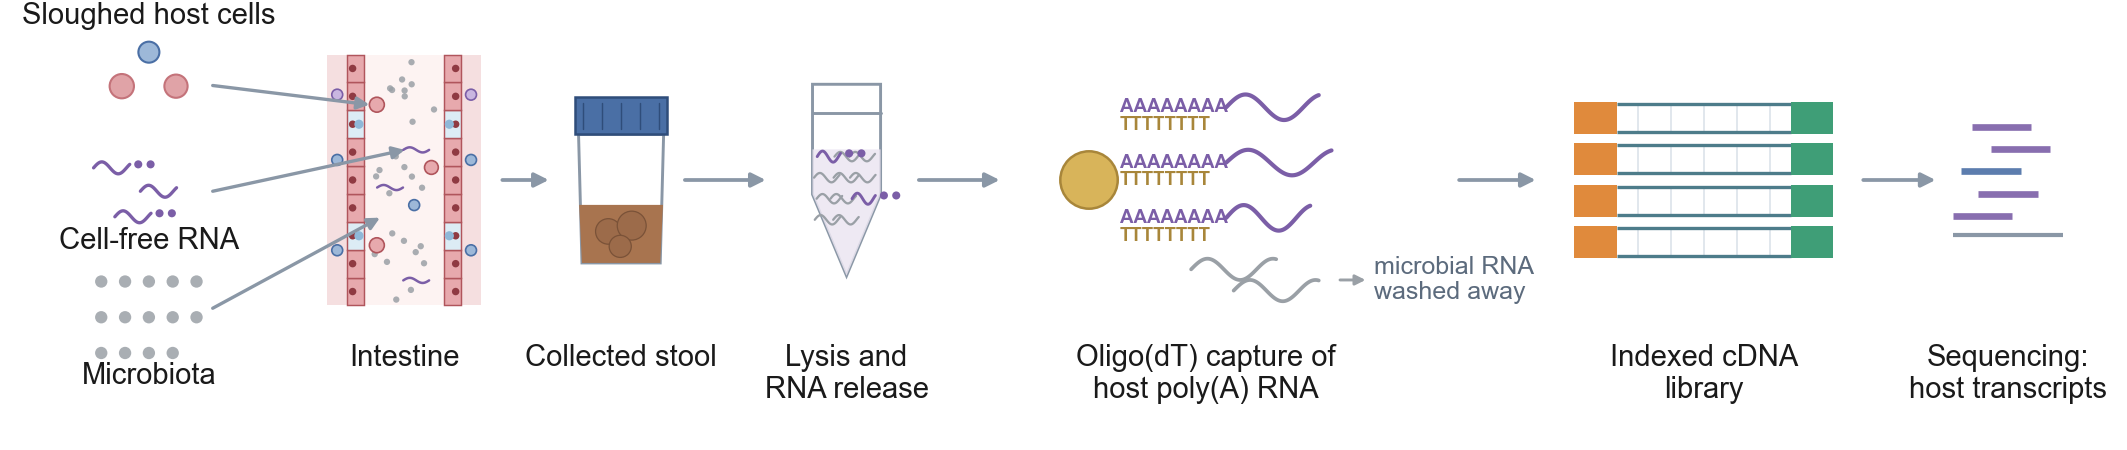

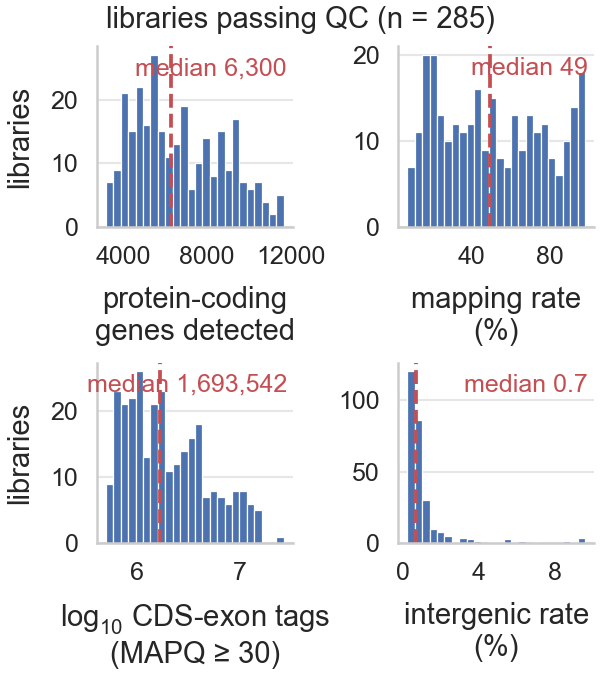

In [2]:
# ----------------------------------------------------------------------------------------------
# [Section 1 -- Study cohort]  (notebook cell 4)
# functions from an earlier section: endoscopy_gap_days() (Section 0, cell 2)
# imported in an earlier section: BASE_PT (Section 0, cell 2); panel()
#     (Section 0, cell 2); RC (Section 0, cell 2); save()
#     (Section 0, cell 2); size() (Section 0, cell 2); tidy()
#     (Section 0, cell 2)
# variables from an earlier section: clin (Section 0, cell 2); ENDO_ORDER (Section 0, cell 2);
#     ENDOSCOPY_WINDOW_DAYS (Section 0, cell 2); meta (Section 0, cell 2); NORMAL_GROUPS
#     (Section 0, cell 2)
# ----------------------------------------------------------------------------------------------
# === §3.1  The analysis set: library counts by study group after every filter ===
GAP_MAX_DAYS = ENDOSCOPY_WINDOW_DAYS            # one window, defined in Section 0 above  
# Normal pools every non-disease colonoscopy outcome; the tuple is defined once, in
# Section 0 of this notebook (NORMAL_GROUPS), and read here so the funnel, the composition
# and the classifiers cannot disagree on what the control arm is.
GROUP_OF = {**{_g: "Normal" for _g in NORMAL_GROUPS}, "APL": "APL", "CRC": "CRC",
            "IBD": "IBD"}
GRP_ORDER = ["Normal", "APL", "CRC", "IBD"]

# --- the per-library facts each step needs ------------------------------------------------------
_grp = meta["study_group"].astype("object").map(GROUP_OF)
_is_ibd = meta["study_group"].astype("object").eq("IBD")
_has_grade = meta["endoscopic_activity_grade"].astype("object").isin(ENDO_ORDER)
# the gap and the window have one definition (endoscopy_gap_days, Section 0), which the
# repertoire-versus-grade section and the monitoring section read too
_gap = endoscopy_gap_days(meta["sample_id"], clin)     # NaN when either date is missing
_gap_ok = _gap.abs().le(GAP_MAX_DAYS)                       # NaN -> False

# --- the funnel: each step is a boolean over all libraries, applied cumulatively ------------------
STEPS = [
    ("all libraries",                          pd.Series(True, index=meta.index)),
    ("annotated (study_group present)",        _grp.notna()),
    ("QC pass (§3)",                           meta["qc_pass"].astype(bool)),
    ("IBD: endoscopic grade present",          ~_is_ibd | _has_grade),
    (f"IBD: endoscopy within {GAP_MAX_DAYS} d", ~_is_ibd | _gap_ok),
]
_keep = pd.Series(True, index=meta.index)
_rows = {}
for _name, _mask in STEPS:
    _keep &= _mask
    _rows[_name] = (_grp[_keep].fillna("unannotated").value_counts()
                    .reindex(GRP_ORDER + ["unannotated"], fill_value=0))
funnel = pd.DataFrame(_rows).T
funnel["Total"] = funnel.sum(axis=1)
funnel.index.name = "after step"
meta_a = meta.loc[_keep].copy()                             # the analysis set
meta_a["group"] = _grp[_keep]


def qc_passing_metric(meta, col):
    """One column of the pipeline's QC table over the libraries Fig. 1b draws: those that passed
    the library cut-offs, after the manuscript cohort filter.

    Fig. 1b takes its values from here, and so does anything that quotes them -- the detected
    protein-coding genes of Results and the abstract are `DetCodGenes_30` from this function, so
    the text and the panel cannot give different medians. (Until 2026-09-29 the text quoted a
    recount from the count matrix, which came out two genes higher.)"""
    libs = meta.index[meta["qc_pass"].astype(bool)]
    return pd.to_numeric(meta.loc[libs, col], errors="coerce").dropna()


# ==== manuscript panel Fig1a_schematic ========================================================
# a: the assay, as a drawing -- what the intestine sheds and stool carries, and what the
# bench keeps of it. Nothing here is computed; `draw_assay`, defined above, holds the drawing.
_pname = "Fig1a_schematic"
# ==== from scripts/workflow_figure.py: used only in this cell, so it lives here (moved 2026-10-08) =====
#
# Figure 1a: where a stool library comes from, and what the assay keeps of it.
#
# A schematic, not a result -- nothing here is computed from `data/`. One left-to-right flow: the
# cells shed from the intestinal wall and the microbiota that stool carries, named at the far left
# with arrows into the mucosa that sheds them; the mucosa in cross-section (columnar epithelium
# with goblet cells over a lamina propria with immune cells, cells detaching into a lumen that holds
# the microbiota); the stool in a home-collection container; lysis, giving a lysate that is mostly
# microbial RNA; oligo(dT) capture, the host transcripts hybridised to the bead by their poly(A)
# tails and the microbial RNA washed away; the indexed library; and the reads it is sequenced into.
# No block titles and no separate poly(A) glyph (both were asked off the panel on 2026-09-28); the
# legend says what the flow shows. Redrawn to this form on 2026-09-28 (the earlier version drew a
# generic tube, a stool coil and free-floating transcripts).
#
# Protocol parameters are deliberately absent. A Figure 1 panel shows what the sample is; the
# temperatures, volumes and cycle counts are Methods, drawn from the SOPs in `protocol/`.
#
# The panel lays itself out in axes fractions, like `manuscript_figures.figS7_sample_flow`, so a
# change of declared size in `LAYOUT` re-flows it rather than rescaling it. Type is set in points
# and every glyph length is given in fractions of the panel *width* and converted to the vertical
# axis with `asp` (= width / height), so a glyph keeps its shape whatever height `LAYOUT` gives
# the row. `draw_assay` is what `manuscript_figures.fig1_schematic` calls.

from matplotlib.patches import Ellipse, FancyArrowPatch, Polygon

EPI = "#c4737a"        # host epithelium
IMM = "#4a6fa5"        # host immune cells
RNA = "#7b5ea7"        # host poly(A) RNA
CDNA = "#4d7c8a"       # cDNA
MIC = "#9aa0a6"        # microbiota -- what this assay does not read
BEAD = "#d8b45a"       # oligo(dT) capture beads
ADA1, ADA2 = "#e08a3c", "#3f9e77"   # the two indexed ends of a finished molecule
INK = "#1a1a1a"
MUTE = "#5c6b7d"
# ------------------------------------------------------------------------------------------
# glyphs
#
# Every size below is given in fractions of the panel *width* and converted to the vertical
# axis with `asp` (= width / height). That is the whole trick: a value in raw y-fractions is a
# different physical size at every declared panel height, and the first three drafts of this
# panel each broke when the height changed. Give a length once, in x-units, and a glyph keeps
# its shape whatever `LAYOUT` says.
# ------------------------------------------------------------------------------------------
def _circle(ax, cx, cy, r, asp, **kw):
    ax.add_patch(Ellipse((cx, cy), 2 * r, 2 * r * asp, transform=ax.transAxes, **kw))
def _rna(ax, x0, x1, y, colour, asp, *, lw=1.0, amp=0.010, waves=2.6, z=3, tail=0):
    """A transcript, as a squiggle; `tail` draws that many poly(A) beads off its 3' end."""
    xs = np.linspace(x0, x1, 80)
    ys = y + amp * asp * np.sin((xs - x0) / (x1 - x0) * waves * np.pi)
    ax.plot(xs, ys, transform=ax.transAxes, color=colour, lw=lw, zorder=z,
            solid_capstyle="round")
    for k in range(tail):
        _circle(ax, x1 + 0.004 + k * 0.0058, ys[-1], 0.0019, asp, facecolor=colour,
                edgecolor="none", zorder=z)
def _duplex(ax, x0, x1, y, asp, *, gap=0.013, lw=0.8, c=CDNA, z=3):
    """Double-stranded cDNA: two strands with rungs between them."""
    g = gap * asp
    for yy in (y + g / 2, y - g / 2):
        ax.plot([x0, x1], [yy, yy], transform=ax.transAxes, color=c, lw=lw, zorder=z,
                solid_capstyle="butt")
    for xx in np.linspace(x0 + 0.010, x1 - 0.010, 5):
        ax.plot([xx, xx], [y - g / 2, y + g / 2], transform=ax.transAxes, color="#dbe3ea",
                lw=0.4, zorder=z - 1)
def _block(ax, x0, w, y, h, asp, colour, z=4):
    hh = h * asp / 2
    ax.add_patch(Polygon([(x0, y - hh), (x0 + w, y - hh), (x0 + w, y + hh), (x0, y + hh)],
                         closed=True, transform=ax.transAxes, facecolor=colour,
                         edgecolor="none", zorder=z))
def _bead(ax, cx, cy, r, asp, *, hairs=9, fc=BEAD, ec="#a8863a"):
    """A capture bead; `hairs` draws the oligo(dT) it is coupled to."""
    for k in range(hairs):
        a = 2 * np.pi * k / hairs
        ax.plot([cx + r * np.cos(a), cx + 1.30 * r * np.cos(a)],
                [cy + r * asp * np.sin(a), cy + 1.30 * r * asp * np.sin(a)],
                transform=ax.transAxes, color=ec, lw=0.4, zorder=3)
    _circle(ax, cx, cy, r, asp, facecolor=fc, edgecolor=ec, lw=0.6, zorder=4)
def _tube(ax, cx, cy, w, h, asp, *, fill=None, fc="#ffffff"):
    """A microcentrifuge tube: straight sides, tapered tip, one cap line. `h` is in x-units."""
    hw, hh = w / 2, h * asp / 2
    ax.add_patch(Polygon([(cx - hw, cy + hh), (cx + hw, cy + hh), (cx + hw, cy - hh * 0.15),
                          (cx, cy - hh), (cx - hw, cy - hh * 0.15)], closed=True,
                         transform=ax.transAxes, facecolor=fc, edgecolor="#8a97a6", lw=0.7,
                         zorder=3))
    ax.plot([cx - hw, cx + hw], [cy + hh * 0.70, cy + hh * 0.70], transform=ax.transAxes,
            color="#8a97a6", lw=0.7, zorder=4)
    if fill is not None:
        colour, frac = fill
        top = cy - hh + 2 * hh * frac
        ax.add_patch(Polygon([(cx - hw, top), (cx + hw, top), (cx + hw, cy - hh * 0.15),
                              (cx, cy - hh), (cx - hw, cy - hh * 0.15)], closed=True,
                             transform=ax.transAxes, facecolor=colour, edgecolor="none",
                             alpha=0.85, zorder=3.5))
def _arrow(ax, x0, x1, y, *, colour="#8a97a6", lw=0.9, scale=7, z=1):
    ax.add_patch(FancyArrowPatch((x0, y), (x1, y), transform=ax.transAxes, arrowstyle="-|>",
                                 mutation_scale=scale, lw=lw, color=colour, shrinkA=0,
                                 shrinkB=0, zorder=z))
def _cells(ax, cx, cy, asp, r=1.0):
    """Three sloughed host cells: two epithelial, one immune."""
    for dx, dy, rr, c, e in ((-0.0098, -0.0035, 0.0044, "#e0a3a7", EPI),
                             (0.0000, 0.0088, 0.0038, "#9db8d8", IMM),
                             (0.0098, -0.0035, 0.0042, "#e0a3a7", EPI)):
        _circle(ax, cx + dx * r, cy + dy * r * asp, rr * r, asp, facecolor=c, edgecolor=e,
                lw=0.5, zorder=4)
def _microbes(ax, cx, cy, asp, *, n=6, per_row=3):
    """`n` microbiota dots in rows of `per_row`, centred on (cx, cy)."""
    rows = -(-n // per_row)
    for k in range(n):
        col, row = k % per_row, k // per_row
        _circle(ax, cx + (col - (per_row - 1) / 2) * 0.0112,
                cy + ((rows - 1) / 2 - row) * 0.0168 * asp,
                0.0029, asp, facecolor=MIC, edgecolor="none", alpha=0.85, zorder=4)
def _point(ax, x0, y0, x1, y1, *, colour="#8a97a6", lw=0.8, scale=6, z=5):
    """An arrow from one point to another, for the annotations that point into the intestine."""
    ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), transform=ax.transAxes, arrowstyle="-|>",
                                 mutation_scale=scale, lw=lw, color=colour, shrinkA=0,
                                 shrinkB=0, zorder=z))
def _mucosa(ax, cx, cy, h, asp, s=1.0):
    """The intestinal wall in cross-section: a lumen between two mucosae, each a monolayer of
    columnar epithelial cells with goblet cells among them, over a lamina propria that holds
    immune cells. Cells detach from the epithelial surface into the lumen, where the microbiota
    are. `h` is the length in x-units; `s` scales the width and everything in it."""
    lumen, cell_h, lp = 0.0140 * s, 0.0058 * s, 0.0070 * s
    y0, y1 = cy - h * asp / 2, cy + h * asp / 2
    # lumen
    ax.add_patch(Polygon([(cx - lumen, y0), (cx + lumen, y0), (cx + lumen, y1), (cx - lumen, y1)],
                         closed=True, transform=ax.transAxes, facecolor="#fdf3f2",
                         edgecolor="none", zorder=1))
    n_cells = 9
    ys = np.linspace(y0, y1, n_cells + 1)
    for sign in (-1, 1):
        x_in = cx + sign * lumen
        # lamina propria, then the epithelial monolayer on top of it
        ax.add_patch(Polygon([(x_in + sign * cell_h, y0), (x_in + sign * (cell_h + lp), y0),
                              (x_in + sign * (cell_h + lp), y1), (x_in + sign * cell_h, y1)],
                             closed=True, transform=ax.transAxes, facecolor="#f5dfe0",
                             edgecolor="none", zorder=2))
        for k in range(n_cells):
            ya, yb = ys[k], ys[k + 1]
            goblet = k in (2, 6)
            fc = "#dcecf5" if goblet else "#e7a9ad"
            ax.add_patch(Polygon([(x_in, ya), (x_in + sign * cell_h, ya),
                                  (x_in + sign * cell_h, yb), (x_in, yb)], closed=True,
                                 transform=ax.transAxes, facecolor=fc, edgecolor="#b0555c",
                                 lw=0.35, zorder=3))
            # nucleus at the basal side; a goblet cell carries a mucus cup at the apical side
            _circle(ax, x_in + sign * cell_h * 0.68, (ya + yb) / 2, 0.0013 * s, asp,
                    facecolor="#8f3a42", edgecolor="none", zorder=4)
            if goblet:
                _circle(ax, x_in + sign * cell_h * 0.30, (ya + yb) / 2, 0.0016 * s, asp,
                        facecolor="#8fb8d8", edgecolor="none", zorder=4)
        # immune cells in the lamina propria
        for f, c, e in ((0.22, "#9db8d8", IMM), (0.58, "#9db8d8", IMM), (0.84, "#c9b6e0", RNA)):
            _circle(ax, x_in + sign * (cell_h + lp * 0.5), y0 + f * (y1 - y0), 0.0019 * s, asp,
                    facecolor=c, edgecolor=e, lw=0.4, zorder=4)
    # cells detaching from the surface into the lumen, and microbiota in the lumen
    for sign, f, r in ((-1, 0.80, 0.0026), (1, 0.55, 0.0024), (-1, 0.24, 0.0026)):
        _circle(ax, cx + sign * (lumen - 0.0045 * s), y0 + f * (y1 - y0), r * s, asp,
                facecolor="#e7a9ad", edgecolor="#b0555c", lw=0.4, zorder=5)
    _circle(ax, cx + 0.0035 * s, y0 + 0.40 * (y1 - y0), 0.0019 * s, asp, facecolor="#9db8d8",
            edgecolor=IMM, lw=0.4, zorder=5)
    rng = np.random.default_rng(7)
    for _ in range(26):
        _circle(ax, cx + rng.uniform(-lumen * 0.75, lumen * 0.75),
                rng.uniform(y0 + 0.02 * (y1 - y0), y1 - 0.02 * (y1 - y0)), 0.0011 * s, asp,
                facecolor=MIC, edgecolor="none", zorder=3, alpha=0.85)
def _container(ax, cx, cy, w, h, asp):
    """A home-collection specimen container: a wide-mouth pot with a screw cap, stool inside."""
    hw, hh = w / 2, h * asp / 2
    ax.add_patch(Polygon([(cx - hw, cy + hh * 0.55), (cx + hw, cy + hh * 0.55),
                          (cx + hw * 0.92, cy - hh), (cx - hw * 0.92, cy - hh)], closed=True,
                         transform=ax.transAxes, facecolor="#ffffff", edgecolor="#8a97a6",
                         lw=0.7, zorder=3))
    # stool inside, up to a fill line
    ax.add_patch(Polygon([(cx - hw * 0.985, cy - hh * 0.30), (cx + hw * 0.985, cy - hh * 0.30),
                          (cx + hw * 0.92, cy - hh), (cx - hw * 0.92, cy - hh)], closed=True,
                         transform=ax.transAxes, facecolor="#a8744f", edgecolor="none",
                         zorder=3.5))
    for dx, dy, r in ((-0.30, -0.62, 0.30), (0.25, -0.55, 0.34), (-0.02, -0.80, 0.26)):
        _circle(ax, cx + dx * hw, cy + dy * hh, r * hw, asp, facecolor="#9c6b4a",
                edgecolor="#7a5238", lw=0.3, zorder=3.6)
    # screw cap
    ax.add_patch(Polygon([(cx - hw * 1.08, cy + hh * 0.55), (cx + hw * 1.08, cy + hh * 0.55),
                          (cx + hw * 1.08, cy + hh), (cx - hw * 1.08, cy + hh)], closed=True,
                         transform=ax.transAxes, facecolor="#4a6fa5", edgecolor="#2f4d7a",
                         lw=0.6, zorder=4))
    for k in range(5):
        xx = cx - hw * 0.9 + k * hw * 0.45
        ax.plot([xx, xx], [cy + hh * 0.62, cy + hh * 0.93], transform=ax.transAxes,
                color="#2f4d7a", lw=0.35, zorder=5)
def _rna_mix(ax, cx, cy, hw, hh, asp, rng, *, n_mic=9, n_host=2):
    """The RNA a lysate holds: mostly microbial (grey), a few host poly(A) transcripts."""
    slots = [(cx - hw + (k % 3) * hw, cy + hh - (k // 3) * hh * 0.55) for k in range(n_mic + n_host)]
    host = set(rng.choice(len(slots), n_host, replace=False).tolist())
    for k, (x0, y) in enumerate(slots):
        x0 += rng.uniform(-0.002, 0.002)
        if k in host:
            _rna(ax, x0 - 0.006, x0 + 0.005, y, RNA, asp, lw=0.7, amp=0.0026, waves=2.2, z=5, tail=2)
        else:
            _rna(ax, x0 - 0.006, x0 + 0.006, y, MIC, asp, lw=0.55, amp=0.0022, waves=2.2, z=4)
def _reads(ax, x0, y, asp, *, n=5, w=0.052, c=RNA):
    """Sequencing reads: short staggered bars, one lineage-coloured, over a reference line."""
    ax.plot([x0, x0 + w], [y - 0.030 * asp, y - 0.030 * asp], transform=ax.transAxes,
            color="#8a97a6", lw=1.0, zorder=3, solid_capstyle="butt")
    offs = (0.000, 0.012, 0.004, 0.018, 0.009)
    for k in range(n):
        yy = y - 0.021 * asp + k * 0.0105 * asp
        xa = x0 + offs[k % len(offs)]
        ax.plot([xa, xa + 0.028], [yy, yy], transform=ax.transAxes, color=c if k != 2 else IMM,
                lw=1.6, zorder=4, solid_capstyle="butt", alpha=0.9)
def draw_assay(ax, asp: float) -> None:
    """The assay as one row, left to right.

    Far left, what the intestine sheds into the lumen -- host cells and microbiota -- each named
    and pointed at where it sits in the mucosa glyph. Then the intestinal wall in cross-section,
    the stool it becomes in a home-collection container, lysis (a lysate that is mostly microbial
    RNA), oligo(dT) capture (host transcripts hybridised to the bead by their poly(A) tails, the
    microbial RNA washed away), the indexed library, and the reads it is sequenced into. Glyph
    centres sit on one flow line, labels on one baseline below it; the two annotations at the
    left have their own baselines, above and below the flow.
    """
    small = BASE_PT
    tiny = BASE_PT - 1
    FLOW, LAB = 0.60, 0.235                # the flow line and the label baseline, y-fractions

    def name(cx, y, text, colour=INK, size=None, va="center"):
        # labels on the LAB baseline hang from it (va="top") so one- and two-line labels align
        ax.text(cx, y, text, transform=ax.transAxes, ha="center",
                va="top" if y == LAB else va, fontsize=size or small, color=colour, zorder=6,
                linespacing=1.15)

    # --- what the intestine sheds, named at the far left and pointed at in the glyph ---------
    GUT, GS, GH = 0.190, 1.35, 0.118        # mucosa centre, width scale, length (x-units)
    lumen = 0.0140 * GS
    wall = (0.0058 + 0.0070) * GS
    y0, y1 = FLOW - GH * asp / 2, FLOW + GH * asp / 2      # where `_mucosa` puts its ends
    _cells(ax, 0.070, 0.83, asp, r=1.3)
    name(0.070, 0.965, "Sloughed host cells")
    _point(ax, 0.100, 0.81, GUT - lumen + 0.0045 * GS - 0.0026 * GS, y0 + 0.80 * (y1 - y0))
    # cell-free RNA, named here and drawn in the lumen as well (below)
    CF = 0.575
    for dx, dy, tail in ((-0.016, 0.011, 2), (0.006, 0.000, 0), (-0.006, -0.012, 2)):
        _rna(ax, 0.070 + dx - 0.010, 0.070 + dx + 0.007, CF + dy * asp, RNA, asp,
             lw=0.8, amp=0.0028, waves=2.2, z=5, tail=tail)
    name(0.070, 0.465, "Cell-free RNA")
    _point(ax, 0.100, CF, GUT + lumen * 0.30 - 0.004 * GS, y0 + 0.62 * (y1 - y0))
    _microbes(ax, 0.070, 0.295, asp, n=14, per_row=5)
    name(0.070, 0.165, "Microbiota")
    _point(ax, 0.100, 0.315, GUT - lumen * 0.6, y0 + 0.35 * (y1 - y0))

    # --- the intestine, and the stool it becomes ---------------------------------------------
    _mucosa(ax, GUT, FLOW, GH, asp, s=GS)
    for f, dx in ((0.62, 0.30), (0.47, -0.35), (0.10, 0.30)):      # cell-free RNA in the lumen
        _rna(ax, GUT + dx * lumen - 0.0045 * GS, GUT + dx * lumen + 0.0045 * GS, y0 + f * (y1 - y0),
             RNA, asp, lw=0.6, amp=0.0012, waves=2.0, z=5)
    name(GUT, LAB, "Intestine")
    _arrow(ax, GUT + lumen + wall + 0.010, 0.258, FLOW)
    STOOL = 0.292
    _container(ax, STOOL, FLOW, 0.040, 0.078, asp)
    name(STOOL, LAB, "Collected stool")

    # --- lysis: a lysate that is mostly microbial RNA -----------------------------------------
    _arrow(ax, 0.322, 0.360, FLOW)
    TUBE = 0.398
    _tube(ax, TUBE, FLOW, 0.032, 0.090, asp, fill=("#ece6f2", 0.66))
    _rna_mix(ax, TUBE, FLOW - 0.007 * asp, 0.009, 0.018 * asp, asp, np.random.default_rng(3), n_mic=9, n_host=2)
    name(TUBE, LAB, "Lysis and\nRNA release")

    # --- oligo(dT) capture: host transcripts bound by their poly(A) tails, microbial RNA washed --
    _arrow(ax, 0.432, 0.470, FLOW)
    CAP = 0.512
    _bead(ax, CAP, FLOW, 0.0135, asp, hairs=0)
    # the oligo(dT) coupled to the bead is written as TTTTTTTT, and each host
    # transcript's poly(A) tail as AAAAAAAA base-paired to it, the transcript running away rightwards
    xt = CAP + 0.0145
    SEQ_PT, HALF = 4.5, 0.0042
    for dy, x1 in ((0.030, 0.108), (0.004, 0.114), (-0.022, 0.104)):
        yy = FLOW + dy * asp
        ax.text(xt, yy + HALF * asp, "AAAAAAAA", transform=ax.transAxes, ha="left", va="center",
                fontsize=SEQ_PT, fontweight="bold", color=RNA, zorder=5)
        ax.text(xt, yy - HALF * asp, "TTTTTTTT", transform=ax.transAxes, ha="left", va="center",
                fontsize=SEQ_PT, fontweight="bold", color="#a8863a", zorder=5)
        _rna(ax, xt + 0.050, CAP + x1, yy + HALF * asp, RNA, asp, lw=1.0, amp=0.006, waves=2.4)
    # microbial transcripts leaving the bead, towards the wash
    for dy, x0 in ((-0.042, 0.048), (-0.052, 0.068)):
        _rna(ax, CAP + x0, CAP + x0 + 0.040, FLOW + dy * asp, MIC, asp, lw=0.9, amp=0.005)
    _point(ax, CAP + 0.118, FLOW - 0.047 * asp, CAP + 0.130, FLOW - 0.047 * asp, colour=MIC,
           lw=0.7, scale=5)
    ax.text(CAP + 0.134, FLOW - 0.047 * asp, "microbial RNA\nwashed away", transform=ax.transAxes,
            ha="left", va="center", fontsize=tiny, color=MUTE, zorder=6, linespacing=1.1)
    name(CAP + 0.055, LAB, "Oligo(dT) capture of\nhost poly(A) RNA")

    # --- the indexed library ----------------------------------------------------------------
    _arrow(ax, 0.686, 0.722, FLOW)
    LIB0, LIB1 = 0.740, 0.862
    for k in (1.5, 0.5, -0.5, -1.5):
        y = FLOW + k * 0.0195 * asp
        _block(ax, LIB0, 0.020, y, 0.015, asp, ADA1)
        _duplex(ax, LIB0 + 0.020, LIB1 - 0.020, y, asp, gap=0.013)
        _block(ax, LIB1 - 0.020, 0.020, y, 0.015, asp, ADA2)
    name((LIB0 + LIB1) / 2, LAB, "Indexed cDNA\nlibrary")

    # --- sequencing, and what is read out ---------------------------------------------------
    _arrow(ax, 0.876, 0.910, FLOW)
    READ = 0.918
    _reads(ax, READ, FLOW + 0.004 * asp, asp)
    name(READ + 0.026, LAB, "Sequencing:\nhost transcripts")

with mpl.rc_context(RC):
    w_in, h_in = size(_pname)
    fig, ax = plt.subplots(figsize=(w_in, h_in))
    fig.set_layout_engine("none")
    ax.set_position([0.0, 0.0, 1.0, 1.0])
    ax.set_axis_off()
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    draw_assay(ax, w_in / h_in)
    save(fig, _pname)

# ==== manuscript panel Fig1b_qc_metrics =======================================================
# b: the four QC metrics of every library that passed the §3 cut-offs, the median of each
# marked. The population is `meta["qc_pass"]` after the manuscript cohort filter, read through
# `qc_passing_metric` so that anything quoting these medians reads the same values.
# locals prefixed _p_ because the notebook binds the same name and reads it later: libs, x
_pname = "Fig1b_qc_metrics"
with mpl.rc_context(RC):
    import matplotlib.ticker as mticker
    _p_libs = meta.index[meta["qc_pass"].astype(bool)]
    spec = [("DetCodGenes_30", "protein-coding\ngenes detected", False, 1.0),
            ("MapRate", "mapping rate\n(%)", False, 100.0),
            ("CDSTags_30", "log$_{10}$ CDS-exon tags\n(MAPQ ≥ 30)", True, 1.0),
            ("InterRate_30", "intergenic rate\n(%)", False, 100.0)]
    fig, axes = panel(_pname, 2, 2)
    for ax, (col, label, logx, scale) in zip(axes.ravel(), spec):
        v = qc_passing_metric(meta, col) * scale
        if scale == 100.0 and v.max() > 100:          # already a percentage in this release
            v = v / 100.0
        _p_x = np.log10(v) if logx else v
        ax.hist(_p_x, bins=24, color="#4c72b0", edgecolor="white", linewidth=0.3)
        med = float(v.median())
        ax.axvline(np.log10(med) if logx else med, color="#c44e52", lw=0.9, ls="--")
        ax.text(0.97, 0.94, f"median {med:,.0f}" if med >= 100 else f"median {med:.2g}",
                transform=ax.transAxes, ha="right", va="top", color="#c44e52",
                fontsize=BASE_PT - 1)
        ax.set_xlabel(label)
        ax.xaxis.set_major_locator(mticker.MaxNLocator(nbins=3, steps=[1, 2, 4, 5, 10]))
        tidy(ax)
    for ax in axes[:, 0]:
        ax.set_ylabel("libraries")
    fig.suptitle(f"libraries passing QC (n = {len(_p_libs)})", fontsize=BASE_PT, fontweight="normal")
    save(fig, _pname)


---
# HPA reference, deconvolution, lineage markers

`cell_type_deconv.ipynb` §0, §1.A–B, §2, §2.B, §2.B.4. HPA table is `data/hpa/rna_single_cell_type.tsv`. Cluster membership and the fitted proportions stay in memory.

> **Manuscript output —** Fig. 1c–f · Supplementary Fig. 1 · Supplementary Fig. 6 · Supplementary Table 1.

In [3]:
# ----------------------------------------------------------------------------------------------
# [Section 2 -- HPA reference, deconvolution, lineage markers]  (notebook cell 6)
# variables from an earlier section: D (Section 0, cell 2); ROOT (Section 0, cell 2)
# ----------------------------------------------------------------------------------------------
# === §0  QC-filtered ECBSeq libraries ===
# the shared bundle `D` from the setup cell; nothing is reloaded
meta_f = D["meta_f"]

# --- the expression matrix for the same libraries --------------------------------------------------
# The setup cell's TMM-CPM (`tmmcpm`): the matrix the deconvolution (§2.1) is fitted on and the
# marker panels (§2.3) draw. Until 2026-10-16 this section read the shipped TPM.
expr = tmmcpm
samples = [s for s in meta_f.index if s in expr.columns]
expr = expr[samples].copy()
expr.columns.name = None

# --- study group is the comparison axis throughout -----------------------------------------------
GROUP_ORDER = ["Healthy", "NEG", "NAPL", "APL", "CRC", "IBD"]
GROUP_PAL = {"Healthy": "#2ca02c", "NEG": "#4c72b0", "NAPL": "#55a868", "APL": "#dd8452",
             "CRC": "#8c564b", "IBD": "#c44e52", "unannotated": "#bcbcbc"}
grp = meta_f.loc[samples, "study_group"].astype("object").fillna("unannotated")
GROUPS = [g for g in GROUP_ORDER if (grp == g).any()] + \
         (["unannotated"] if (grp == "unannotated").any() else [])

logexpr = np.log2(expr + 1)


In [4]:
# ----------------------------------------------------------------------------------------------
# [Section 2 -- HPA reference, deconvolution, lineage markers]  (notebook cell 7)
# variables from an earlier section: D (Section 0, cell 2); ROOT (Section 0, cell 2)
# ----------------------------------------------------------------------------------------------
# === §1.A  Load HPA, build feature matrix, cluster cell types ==============
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.preprocessing import StandardScaler
import umap

# ---- HPA reference (cached locally by the §2 deconvolution cell) ----------
HPA_LOCAL = ROOT / "data/hpa/rna_single_cell_type.tsv"
HPA_DIR   = HPA_LOCAL.parent; HPA_DIR.mkdir(parents=True, exist_ok=True)
if not HPA_LOCAL.exists():
    import io, zipfile, requests
    r = requests.get("https://www.proteinatlas.org/download/tsv/rna_single_cell_type.tsv.zip",
                      timeout=300); r.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(r.content)) as zf:
        zf.extractall(HPA_DIR)

hpa = pd.read_csv(HPA_LOCAL, sep="\t")
EXPR_COL = next(c for c in ("nTPM","nCPM","TPM","Read count") if c in hpa.columns)
mat = (hpa.pivot_table(index="Gene name", columns="Cell type",
                        values=EXPR_COL, aggfunc="mean").fillna(0))
mat = mat.loc[mat.max(axis=1) >= 1.0]                # keep genes reaching 1 nCPM in some cell type
g_var = np.log1p(mat).var(axis=1)
top_var_genes = g_var.sort_values(ascending=False).head(5000).index
X = np.log1p(mat.loc[top_var_genes]).T.values        # cell types x genes
cell_types = list(mat.columns)

# ---- Heuristic lineage assignment (for coloring) --------------------------
def assign_lineage(name: str) -> str:
    n = name.lower()
    # Ocular surface, despite the name -- the "goblet" keyword below would claim it for the gut.
    if "conjunctival" in n:
        return "Other epithelium"
    if any(k in n for k in ["colonocyt","enterocyt","goblet","paneth","tuft",
                              "foveolar","parietal","chief","enteric stem",
                              "enteric transient","mucous neck","gastric chief",
                              "gastric progenitor","intestinal","neuroendocrine"]):
        return "GI epithelium"
    if any(k in n for k in ["esophageal","salivary","lacrimal","respiratory",
                              "alveolar","submucosal glandular","papillary tip",
                              "urothelial","renal","tubule","henle","podocyte",
                              "collecting duct","cholangio","ocular epithel",
                              "choroid plexus","ependymal","ionocyte",
                              "decidual","endometr","fallopian","breast",
                              "prostat","hepatocyt","pancreatic","thymic epithel",
                              "thymic myoid"]):
        return "Other epithelium"
    if any(k in n for k in ["neutrophil","monocyt","macrophage","kupffer",
                              "microglia","mast cell","nk-cell","innate lymphoid",
                              "cdc","pdcs","hofbauer"]):
        return "Innate immune"
    if any(k in n for k in ["t-cell","b-cell","plasma cell","thymocyt"]):
        return "Adaptive immune"
    if any(k in n for k in ["erythrocyt","megakaryocyt","platelet",
                              "hematopoietic","myeloid progenitor"]):
        return "Hematopoietic"
    if any(k in n for k in ["gonadotroph","lactotroph","corticotroph",
                              "somatotroph","thyrotroph","pituicyt","pituitary",
                              "adrenal","islet"]):
        return "Endocrine"
    if any(k in n for k in ["sperm","leydig","sertoli","ovari","granulosa",
                              "trophoblast","oocyt","epididymal","peritubular myoid"]):
        return "Reproductive / germ"
    if any(k in n for k in ["neuron","astrocyt","oligodendro","schwann",
                              "müller","muller","bergmann","horizontal",
                              "bipolar","photoreceptor","rod cell","cone cell","retinal"]):
        return "Neural / glial"
    if any(k in n for k in ["cardiomyo","skeletal muscle","smooth muscle","myonuclei",
                              "myosatell","epicardial","vascular smooth muscle",
                              "fibro-adipogenic"]):
        return "Muscle"
    if any(k in n for k in ["keratino","melanocyt"]):
        return "Skin / sensory"
    if any(k in n for k in ["fibroblast","pericyt","endothel","mesothel","adipocyt",
                              "stellate","stromal","myoepithel"]):
        return "Stromal / vascular"
    return "Other"

lin = pd.Series({c: assign_lineage(c) for c in cell_types}, name="lineage")

# ---- Hierarchical clustering on cosine distance ---------------------------
Xn = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-9)
D  = 1.0 - (Xn @ Xn.T); D = (D + D.T) / 2; np.fill_diagonal(D, 0.0)
Z  = linkage(squareform(D, checks=False), method="average")

CLUSTER_DISTANCE = 0.15                   # tunable cut threshold
cluster_id = fcluster(Z, t=CLUSTER_DISTANCE, criterion="distance")
# .copy() matters: pd.Series wraps the fcluster array without copying, so the
# merge pass below would otherwise mutate `cluster_id` in place.
ct_cluster = pd.Series(cluster_id, index=cell_types, name="cluster").copy()

# ---- Stage 2: lineage-aware merges ----------------------------------------
# A single global cut cannot express "these belong together biologically": the
# threshold that keeps the immune types in one column (0.15) leaves tuft cells,
# microglia and the germ-cell clusters stranded as separate signature columns,
# where they compete with the cluster they belong to for the same marker genes.
# Raising the cut instead collapses GI into squamous epithelium. So we cut at
# 0.15 and then apply an explicit, reviewable merge list.
#
# Each entry names two cell types; the clusters containing them are merged, and
# the merged cluster keeps the ID of the larger constituent. Anchoring on cell
# type names rather than cluster IDs keeps the list valid if the tree changes.
MERGE_CEILING = 0.25      # refuse a merge whose average-linkage distance exceeds this
LINEAGE_MERGES = [
    ("tuft cells",               "colonocytes"),              # solitary chemosensory GI epithelium
    ("microglia",                "macrophages"),              # brain-resident macrophages
    ("late spermatids",          "undifferentiated spermatogonia"),
    ("oocytes",                  "late spermatids"),          # -> one germ-cell column
    ("platelets",                "megakaryocytes"),           # platelets are megakaryocyte fragments
    ("erythrocytes",             "erythrocyte progenitors"),  # erythroid lineage
    ("müller glia",              "astrocytes"),
    ("retinal ganglion cells",   "brain excitatory neurons"),
    ("astrocytes",               "brain excitatory neurons"),
    ("retinal horizontal cells", "brain excitatory neurons"),
    ("myonuclei",                "cardiomyocytes"),
    ("thymic myoid cells",       "cardiomyocytes"),           # striated-muscle-like thymic cells
]
# Hepatocytes are deliberately *not* on this list (the entry was removed 2026-09-16). The cut
# leaves them as a singleton, and merging that singleton into the GI column was the one merge that
# fed a column genes its sample never shows -- 21 of C24's 50 markers peaked in hepatocytes before
# the breadth gate in §2 -- while it kept the composition from ever asking whether liver
# transcripts reach stool at all. As a column of their own they are a fitted negative control:
# stool is intestine, not liver, and Fig. 1a can now show it. The singleton guard in §2 is what
# makes that column honest (enterocyte apolipoproteins would otherwise be credited to the liver).

_D = pd.DataFrame(D, index=cell_types, columns=cell_types)
for _a, _b in LINEAGE_MERGES:
    _ca, _cb = ct_cluster[_a], ct_cluster[_b]
    if _ca == _cb:
        continue
    _ma = ct_cluster.index[ct_cluster == _ca].tolist()
    _mb = ct_cluster.index[ct_cluster == _cb].tolist()
    _d = float(_D.loc[_ma, _mb].to_numpy().mean())
    if _d > MERGE_CEILING:
        continue
    _keep, _drop = (_ca, _cb) if len(_ma) >= len(_mb) else (_cb, _ca)
    ct_cluster[ct_cluster == _drop] = _keep


# ---- Stage 2b: targeted split ---------------------------------------------
# The cut leaves the six squamous cell types inside the 42-member "other epithelium" cluster,
# and in stool that cluster is fitted on nothing else: SPRR3 and KRT13 carry 81% of its column,
# its share tracks a 15-gene squamous score at rho 0.93 in every study group, and removing those
# genes takes it from 0.165 to 0.014 (scripts/c26_merge_test.py §6). Carving them out is the
# mirror of the merge list above -- one explicit, reviewable edit -- and leaves C24 and the
# immune column intact; the C26 remainder then fits to ~0 and drops out of the composition.
SQUAMOUS_SPLIT = ["esophageal apical cells", "esophageal basal cells",
                  "esophageal suprabasal cells", "basal keratinocytes",
                  "suprabasal keratinocytes", "ocular epithelial cells"]
SQUAMOUS_CID = int(ct_cluster.max()) + 1     # the next id after the tree's own labels
_present = [m for m in SQUAMOUS_SPLIT if m in ct_cluster.index]
ct_cluster[_present] = SQUAMOUS_CID

CLUSTER_LABEL = {}          # cluster id -> name override, applied by the rename pass below

# ---- Cluster renames ------------------------------------------------------
# A cluster is named after the majority lineage of its members, which is wrong for the
# immune column: the cut merged t-cells, b-cells, plasma cells and NK cells in with the
# neutrophils and macrophages, so "innate immune" describes 12 of 16 members and reads as
# a denial of the other four. They are a minor share of the signal -- measured directly off
# the TPM matrix rather than through the fit, adaptive cells hold roughly 0.7% of stool
# transcripts against ~11% for neutrophils (scripts/adaptive_immune_check.py) -- but they
# are inside this column rather than absent from the model, and §3 is where the reader
# should go for which immune cells. Keyed on a member, not a cluster id, because ids move.
# Cluster names have to sit on one axis or the pie asks the reader to compare an organ
# system with a tissue type. "GI epithelium" beside "squamous epithelium" reads as two
# organs, when the oesophagus is itself gastrointestinal and the real contrast is columnar
# against squamous. Both epithelial columns are therefore named for their tissue
# architecture. "Columnar" rather than "glandular": colonocytes and enterocytes are simple
# columnar absorptive epithelium, not glands, and the word covers the absorptive and the
# secretory members (goblet, Paneth, foveolar) alike. C28 is named for what it actually reports rather than its lineage: its
# panel is nine genes, and the three detected in stool -- HBB, HBA1, HBA2 -- are mature
# erythrocyte haemoglobin; the megakaryocyte and thymocyte members contribute no marker.
CLUSTER_RENAME = {"colonocytes": "Columnar GI epithelium",
                  "esophageal apical cells": "Squamous epithelium",   # the Stage 2b column
                  "neutrophils": "Immune cells",
                  "erythrocytes": "Erythroid cells"}
for _anchor, _label in CLUSTER_RENAME.items():
    if _anchor not in ct_cluster.index:
        continue
    _cid = int(ct_cluster[_anchor])
    CLUSTER_LABEL[_cid] = _label


# ---- Name each cluster from its members -----------------------------------
def name_cluster(members: list[str], cid: int) -> str:
    if len(members) == 1:
        return f"C{cid:02d}: {members[0]}"
    if cid in CLUSTER_LABEL:                      # named by hand, see the rename pass
        sort_key = mat[members].sum(axis=0).sort_values(ascending=False).index
        head = [m for m in sort_key if m in members][:3]
        return (f"C{cid:02d}: {CLUSTER_LABEL[cid]} (n={len(members)}: "
                + ", ".join(head) + (", ..." if len(members) > 3 else "") + ")")
    lineages = lin.reindex(members).value_counts()
    dom = lineages.index[0]
    # Sort members so the most "representative" appear first
    sort_key = (mat[members].sum(axis=0).sort_values(ascending=False).index
                  if all(m in mat.columns for m in members) else members)
    head = [m for m in sort_key if m in members][:3]
    head_str = ", ".join(head) + (", ..." if len(members) > 3 else "")
    if (lineages == lineages.iloc[0]).sum() == 1 and lineages.iloc[0] == len(members):
        return f"C{cid:02d}: {dom} (n={len(members)}: {head_str})"
    return f"C{cid:02d}: {dom} + (n={len(members)}: {head_str})"

# IDs are the original fcluster labels and are no longer contiguous after merging
cluster_members = {int(cid): ct_cluster[ct_cluster == cid].index.tolist()
                    for cid in sorted(ct_cluster.unique())}
cluster_name = {cid: name_cluster(members, cid)
                for cid, members in cluster_members.items()}


### HPA single-cell reference UMAP, and the cluster-based deconvolution

> **Manuscript output —** Supplementary Table 1.

In [5]:
# ----------------------------------------------------------------------------------------------
# [Section 2.1 -- HPA single-cell reference UMAP, and the cluster-based deconvolution]  (notebook cell 9)
# imported in an earlier section: StandardScaler() (sklearn.preprocessing)
# variables from an earlier section: cell_types (Section 2, cell 7); ct_cluster (Section 2, cell
#     7); lin (Section 2, cell 7); X (Section 2, cell 7)
# ----------------------------------------------------------------------------------------------
# === §1.B  UMAP of 154 HPA cell types, coloured by lineage =================
Xs = StandardScaler().fit_transform(X)
emb = umap.UMAP(n_neighbors=10, min_dist=0.25, metric="cosine",
                 random_state=42).fit_transform(Xs)
emb_df = pd.DataFrame(emb, index=cell_types, columns=["UMAP1","UMAP2"])
emb_df["lineage"]    = lin
emb_df["cluster_id"] = ct_cluster
# skipped results write: emb_df.to_csv(Path("../results/hpa_celltype_lineage_assignments.csv"))

# Supplementary Fig. 1 is drawn from `emb_df` in Section 2.3 (`draw_hpa_umap` there).


OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [6]:
# ----------------------------------------------------------------------------------------------
# [Section 2.1 -- HPA single-cell reference UMAP, and the cluster-based deconvolution]  (notebook cell 10)
# imported in an earlier section: TABLE_DIR (Section 0, cell 2)
# variables from an earlier section: cluster_members (Section 2, cell 7); cluster_name (Section
#     2, cell 7); ct_cluster (Section 2, cell 7); mat (Section 2, cell 7); samples (Section 2,
#     cell 6); expr (Section 2, cell 6)
# ----------------------------------------------------------------------------------------------
# === §2  Cluster-based DWLS deconvolution across all QC-passed libraries ===
from statsmodels.stats.multitest import multipletests

# ---- Aggregate HPA expression per CLUSTER (genes x clusters) -----------------------------------
cluster_mat = mat.T.groupby(ct_cluster).mean().T
cluster_mat.columns = [cluster_name[int(c)] for c in cluster_mat.columns]

# ---- Cluster-level specificity per gene ---------------------------------------------------------
top_val = cluster_mat.max(axis=1)
total = cluster_mat.sum(axis=1)
spec = pd.DataFrame({"gene": cluster_mat.index,
                     "top_cluster": cluster_mat.idxmax(axis=1).values,
                     "top_expr": top_val.values,
                     "nCPM_weight": (top_val / total).where(total > 0, 0).values})

K_PER, MIN_W, MIN_TOP = 50, 0.85, 10.0
MIN_MARKERS_PER_CLUSTER = 5
MIN_BREADTH = 0.34        # fraction of the cluster's members that must express the gene

# ---- within-cluster breadth ---------------------------------------------------------------------
# `nCPM_weight` scores a gene only on contrast *between* clusters, and the cluster profile above is
# a mean over members, which hides how the signal is distributed *within* one. A gene expressed by
# exactly one member of a 13-member cluster therefore scores a perfect weight: APOA2 sits at 52,172
# nCPM in hepatocytes and ~0 in the other twelve, so C24's profile carries 52,172/13 = 4,013 -- 400x
# over MIN_TOP -- and no other cluster expresses it, so its weight is 1.00. That put 21 of C24's 50
# markers on genes that peak in hepatocytes, 16 of which are undetectable in stool; a signature gene
# the sample never shows can only pull that cluster's coefficient down.
#
# The gate asks that a marker be shared by the cluster it names. A *fraction* rather than a count,
# because clusters differ in size; 0.34 rather than 0.50 because a fixed fraction still penalises
# large clusters, and at 0.50 the three biggest lose their panels outright -- C26 other epithelium
# (36 members) 50 markers -> 1, C12 neural/glial (20) 26 -> 1, C22 stromal/vascular (18) 7 -> 1.
# Losing C26 is not neutral: it is the residual epithelium column that absorbs salivary, pancreatic
# and urothelial signal, and without it that signal is pushed onto C24 and C33.
_cid_by_name = {v: k for k, v in cluster_name.items()}
_breadth = pd.Series(0.0, index=cluster_mat.index)
for _nm, _cid in _cid_by_name.items():
    _mem = sorted(ct_cluster.index[ct_cluster == _cid])
    _frac = (mat.loc[cluster_mat.index, _mem] >= MIN_TOP).mean(axis=1)
    _sel = (spec["top_cluster"].values == _nm)
    _breadth.values[_sel] = _frac.values[_sel]
spec["breadth_frac"] = _breadth.values

marker_pool = (spec[(spec["top_expr"] >= MIN_TOP) & (spec["nCPM_weight"] >= MIN_W)
                    & (spec["breadth_frac"] >= MIN_BREADTH)]
               .sort_values("nCPM_weight", ascending=False)
               .groupby("top_cluster", group_keys=False).head(K_PER))

# ---- singleton guard -----------------------------------------------------------------------------
# The breadth gate is vacuous for a one-member cluster (one member, fraction 1.0), and the weight
# test is fooled by averaging in the other direction: APOC3 is 97,066 nCPM in hepatocytes and
# 10,695 in enterocytes, 11% of the liver level, but enterocytes are one of C24's twelve members,
# so C24's *mean* carries ~890 and the weight comes out at 0.99. Fitted on such a signature the
# liver column took 7.5% of normal stool in the dry run of 2026-09-16 -- enterocyte
# apolipoprotein transcripts credited to the liver. A singleton column's markers are therefore
# checked again at cell-type resolution, on the 154-type matrix: a gene stays only if every other
# reference cell type expresses it below DOMINANT_FRAC (5%) of the singleton's own level, the one
# definition of "quiet" the Fig. 1e, f marker panels and Supplementary Fig. 6 also use. Liver-resident types are not counted
# against hepatocytes: the HPA Kupffer profile carries ambient hepatocyte RNA (ALB, HP) above the
# line, and a liver column without ALB would say nothing more about stool. The guard sits before
# the five-marker minimum, so a column that loses its shared genes has to stand on what is left.
_singletons = {cluster_name[c]: m[0] for c, m in cluster_members.items() if len(m) == 1}
_exempt = {"hepatocytes": [c for c in mat.columns
                           if any(k in c.lower() for k in ("kupffer", "cholangio", "hepatic"))]}
for _nm, _member in _singletons.items():
    _others = [c for c in mat.columns if c != _member and c not in _exempt.get(_member, [])]
    _quiet = mat[_others].max(axis=1) < DOMINANT_FRAC * mat[_member]
    _rows = marker_pool[marker_pool["top_cluster"] == _nm]
    _bad = _rows[~_quiet.reindex(_rows["gene"]).fillna(False).to_numpy()]
    if len(_bad):
        marker_pool = marker_pool.drop(_bad.index)

_counts = marker_pool.groupby("top_cluster").size()
all_cluster_names = list(cluster_name.values())
keep_clusters = sorted(_counts[_counts >= MIN_MARKERS_PER_CLUSTER].index.tolist(),
                       key=all_cluster_names.index)
dropped_clusters = [n for n in all_cluster_names if n not in keep_clusters]
marker_pool = marker_pool[marker_pool["top_cluster"].isin(keep_clusters)]

# ---- DWLS per library ---------------------------------------------------------------------------
# Dampened weighted least squares (`m_dwls`, defined above), which is what the Methods have always
# described: a non-negative least-squares start followed by four re-weighted passes with weights
# 1/fitted^2, floored at the library's 25th percentile of non-zero expression. Until 2026-09-29
# this cell ran the NNLS start alone and stopped there, so the Methods described a function the
# figures never called. The weighting targets relative rather than absolute error, which is the
# right criterion when the mismatch between a tissue reference and a stool library is
# multiplicative.
#
# It is not a cosmetic change. Over the 77 Normal libraries the columnar GI-epithelium share goes
# from 66.9% to 84.0% and squamous epithelium from 24.1% to 6.5%, so anything quoting the split --
# Fig. 1c and Fig. 1d -- moves with it.
samples_use = samples
common = sorted(set(marker_pool["gene"]) & set(expr.index))

S = cluster_mat.loc[common, keep_clusters]
S_norm = S.divide(np.linalg.norm(S.values, axis=0) + 1e-9, axis=1)
B = expr.loc[common, samples_use]

# ==== from scripts/deconv_methods.py: used only in this cell, so it lives here (moved 2026-10-08) =====
#
# The deconvolution estimator.
#
# `m_dwls` is the fit behind Fig. 1c, d: dampened weighted least squares on L2-normalised
# signature columns.

from scipy.optimize import nnls

def _norm_cols(W):
    tot = W.sum(axis=0, keepdims=True)
    return np.divide(W, tot, out=np.zeros_like(W), where=tot > 0)
def m_dwls(A, Y, n_iter=4, **kw):
    """Dampened weighted least squares (Tsoucas et al. 2019): w = 1/fitted^2, floored at the
    library's 25th percentile so near-zero genes cannot dominate in the other direction. The
    weight targets *relative* error, which is the right criterion when the mismatch is
    multiplicative."""
    W = np.column_stack([nnls(A, Y[:, j])[0] for j in range(Y.shape[1])])
    for _ in range(n_iter):
        cols = []
        for j in range(Y.shape[1]):
            y = Y[:, j]
            damp = np.percentile(y[y > 0], 25) if (y > 0).any() else 1.0
            r = 1.0 / np.maximum(A @ W[:, j], damp)
            cols.append(nnls(A * r[:, None], y * r)[0])
        W = np.column_stack(cols)
    return _norm_cols(W)

proportions = pd.DataFrame(m_dwls(S_norm.to_numpy(dtype=float), B.to_numpy(dtype=float)),
                           index=S_norm.columns, columns=samples_use)
proportions.index.name = "cluster_name"

short = lambda n: n.split("(", 1)[0].replace(" +", "").strip()   # "C24: GI epithelium"


# ==== Supplementary table TableS1_deconvolution_clusters ======================================
# Supplementary Table 1 (Supplementary Table 2 until 2026-10-27): the clusters behind Fig. 1c, d -- one row per cluster of the HPA
# reference (§1.A, cell 7), its member cell types, whether it entered the DWLS fit,
# and the signature genes it was fitted on (section 2's `marker_pool`, restricted to the genes
# present in the stool matrix, which is what `S` holds). A cluster with fewer than
# `MIN_MARKERS_PER_CLUSTER` markers is listed with the markers it had and is marked not fitted.
# Fitted clusters come first, in the fit's order; the rest follow by cluster id.
TABLE_DIR.mkdir(parents=True, exist_ok=True)
pool, _p_S = marker_pool, S
names, members = cluster_name, cluster_members
keep, dropped, min_markers = list(keep_clusters), list(dropped_clusters), MIN_MARKERS_PER_CLUSTER
cid_of = {v: k for k, v in names.items()}
in_fit = set(_p_S.index)
rows = []
for name in keep + sorted(dropped, key=lambda n: cid_of[n]):
    cid = cid_of[name]
    label = name.split(":", 1)[1].split("(", 1)[0].strip() if ":" in name else name
    genes = pool.loc[pool["top_cluster"] == name, "gene"].tolist()
    if name in keep:
        genes = [g for g in genes if g in in_fit]
        fitted = "yes"
    else:
        fitted = f"no: {len(genes)} marker{'s' if len(genes) != 1 else ''}, fewer than {min_markers}"
    mem = members[cid]
    rows.append({"cluster": f"C{cid:02d}", "cluster name": label,
                 "member cell types (n)": len(mem), "member cell types": "; ".join(mem),
                 "fitted": fitted, "signature genes (n)": len(genes),
                 "signature genes": "; ".join(genes)})
pd.DataFrame(rows).to_csv(TABLE_DIR / "TableS1_deconvolution_clusters.csv", index=False)


### Composition by study group

> **Manuscript output —** Fig. 1c, d.

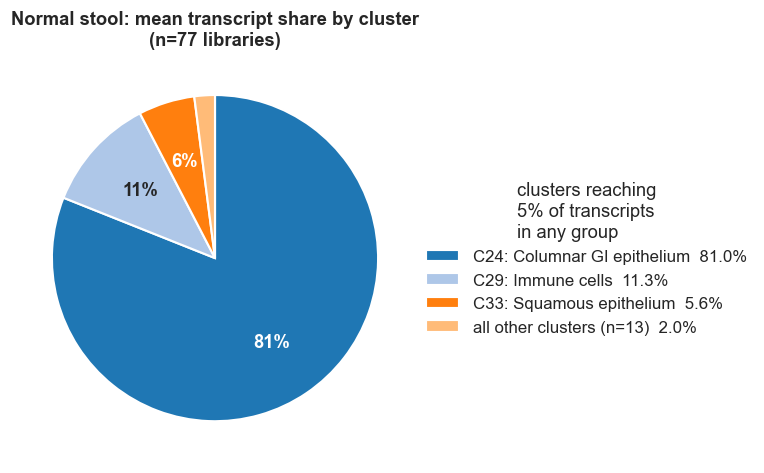

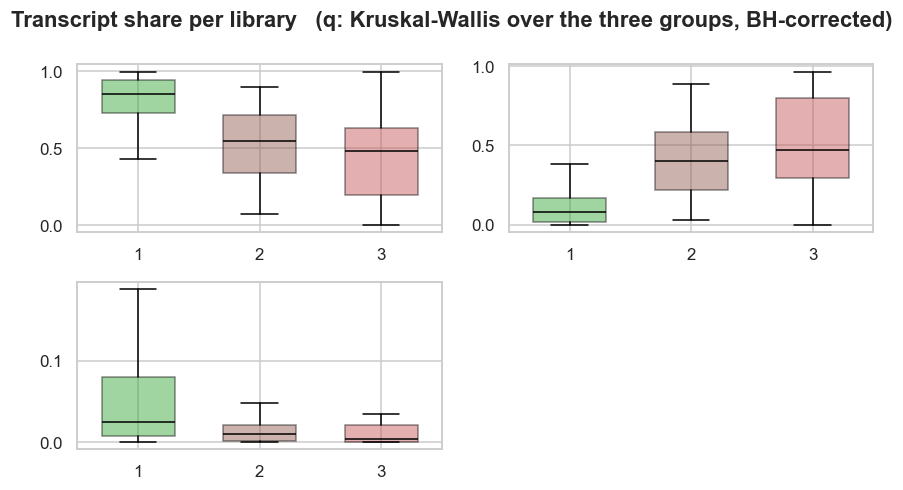

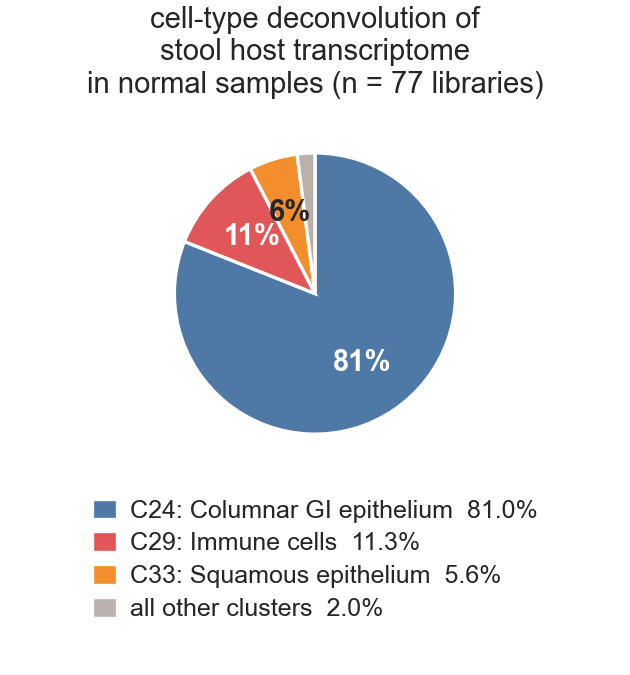

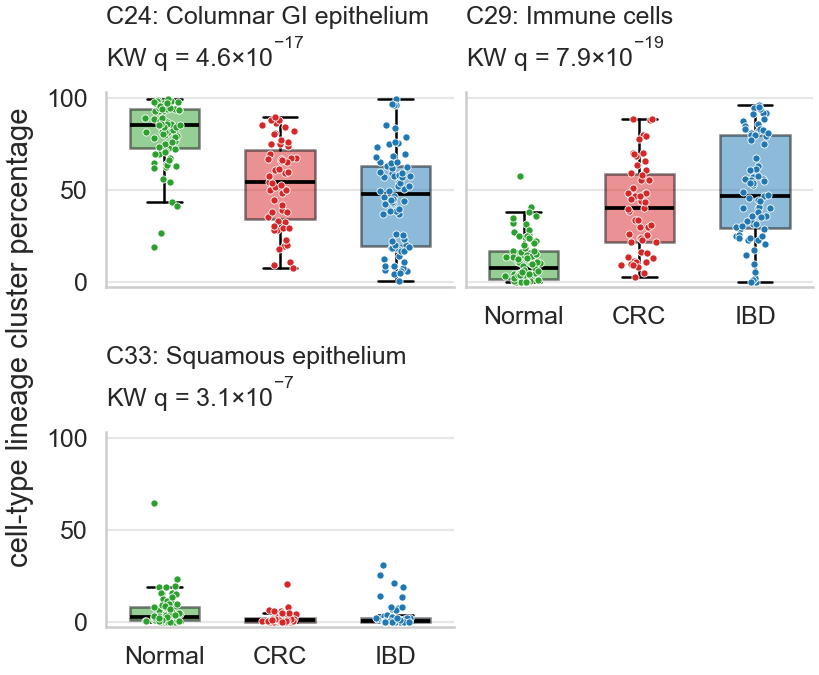

In [7]:
# ----------------------------------------------------------------------------------------------
# [Section 2.2 -- Composition by study group]  (notebook cell 12)
# functions from an earlier section: inline_figsize() (Section 0, cell 2); remission_ids()
#     (Section 0, cell 2); short() (Section 2.1, cell 10)
# imported in an earlier section: BASE_PT (Section 0, cell 2); box_strip()
#     (Section 0, cell 2); MF_GROUP_ORDER (Section 0, cell 2);
#     MF_GROUP_PAL (Section 0, cell 2); multipletests()
#     (statsmodels.stats.multitest); panel() (Section 0, cell 2); pstr()
#     (Section 0, cell 2); RC (Section 0, cell 2); save()
#     (Section 0, cell 2)
# variables from an earlier section: cluster_name (Section 2, cell 7); GROUP_PAL (Section 2,
#     cell 6); grp (Section 2, cell 6); meta_f (Section 0, cell 2), last set Section 2, cell 6;
#     NORMAL_GROUPS (Section 0, cell 2); proportions (Section 2.1, cell 10)
# ----------------------------------------------------------------------------------------------
# === §2.B  Composition by study group ===
# The headline composition: the three groups the manuscript contrasts, and only the clusters
# large enough to read off a stacked bar. Everything below MIN_SHARE is pooled into one segment
# rather than dropped, so the bars still sum to 1 and the reader can see how little is being set
# aside. §2 prints the full table over all clusters and groups.
#
# One unit only. These are transcript shares -- the coefficients as the fit returns them, on
# L2-normalised signature columns -- because that is the quantity the model estimates and the
# quantity the residual and the calprotectin correlation are computed on. The cell-share reading
# is a derived quantity that costs an extra assumption (equal mRNA per cell), so it belongs in
# §2.C where that assumption can be stated, not in the figure that defines the composition.
#
# "Normal" pools the healthy volunteers with the colonoscopy-negative screening participants
# (NEG) and the non-advanced lesions (NAPL): none carries a disease, all were collected under the
# same protocol, and the rest of the manuscript treats them as one control arm. The tuple is
# defined once, in Section 0 of this notebook. grp_plot is the study-group vector with that
# pooling applied, and every §2.B panel reads from it rather than from grp.
NORMAL_GROUPS = list(NORMAL_GROUPS)
grp_plot = grp.replace({g: "Normal" for g in NORMAL_GROUPS})
GROUP_PAL.setdefault("Normal", GROUP_PAL["Healthy"])
PLOT_GROUPS = ["Normal", "CRC", "IBD"]
MIN_SHARE = 0.05

from scipy.stats import kruskal

comp = pd.DataFrame({g: proportions.loc[:, (grp_plot == g).values].mean(axis=1) for g in PLOT_GROUPS})

top_clusters = (comp[comp.max(axis=1) >= MIN_SHARE].mean(axis=1)
                .sort_values(ascending=False).index.tolist())
_dropped = [c for c in proportions.index if c not in top_clusters]

stack = comp.loc[top_clusters]
stack.loc["all other clusters"] = 1 - stack.sum(axis=0)

# The per-library comparison (panel b, Fig. 1d) is a disease comparison, so the IBD libraries
# in endoscopic remission are set aside from it as they are from the PCA and the classifiers:
# a healed mucosa sheds little disease signal. Panel (a) and the cluster selection above stay on
# grp_plot -- they describe Normal stool, which the exclusion does not touch.
grp_1d = grp_plot.drop(index=[i for i in remission_ids(meta_f) if i in grp_plot.index])

# Kruskal-Wallis over the three groups actually drawn, BH-corrected across the drawn clusters
_p = {cl: kruskal(*[proportions.loc[cl, grp_1d.index[grp_1d == g]].values for g in PLOT_GROUPS]).pvalue
      for cl in top_clusters}
_q = dict(zip(_p, multipletests(list(_p.values()), method="fdr_bh")[1]))

# --- (a) what normal stool is made of ------------------------------------------------------------
# A pie rather than the three-group stacked bar: this figure makes one claim -- normal stool is
# mostly GI epithelium -- and the disease comparison is carried by the per-library panels
# below. Shares are the same transcript shares, just the Normal column of `stack`.
fig, ax_tx = plt.subplots(figsize=inline_figsize(4.90, 3.35))   # inline figure size
colours = sns.color_palette("tab20", len(stack))
_shares = stack["Normal"]
_names = [short(_n) if _n != "all other clusters"
          else f"all other clusters (n={len(_dropped)})" for _n in _shares.index]
_wedges, _ = ax_tx.pie(_shares.values, colors=colours, startangle=90, counterclock=False,
                       wedgeprops=dict(edgecolor="white", linewidth=1.4))
for _w, _v, _c in zip(_wedges, _shares.values, colours):
    if _v < 0.05:                      # a sliver has no room for a label inside it
        continue
    _ang = np.deg2rad((_w.theta1 + _w.theta2) / 2)
    _lum = 0.299 * _c[0] + 0.587 * _c[1] + 0.114 * _c[2]
    ax_tx.text(0.62 * np.cos(_ang), 0.62 * np.sin(_ang), f"{_v:.0%}", ha="center", va="center",
               color="white" if _lum < 0.6 else "0.15", fontweight="bold")
ax_tx.set_aspect("equal")
ax_tx.legend(_wedges, [f"{_n}  {_v:.1%}" for _n, _v in zip(_names, _shares.values)],
             loc="center left", bbox_to_anchor=(0.98, 0.5), frameon=False,
             title=f"clusters reaching\n{MIN_SHARE:.0%} of transcripts\nin any group")
ax_tx.set_title("Normal stool: mean transcript share by cluster\n"
                f"(n={int((grp_plot == 'Normal').sum())} libraries)", fontweight="bold")
fig.tight_layout()

# --- (b) the same clusters, per library -----------------------------------------------------------
_ncol = 2 if len(top_clusters) <= 4 else 3
_nrow = int(np.ceil(len(top_clusters) / _ncol))
fig_b, _axs_b = plt.subplots(_nrow, _ncol, figsize=inline_figsize(6.02, 3.40))
for k, cl in enumerate(top_clusters):
    ax = np.asarray(_axs_b).ravel()[k]
    data = [proportions.loc[cl, grp_1d.index[grp_1d == g]].values for g in PLOT_GROUPS]
    bp = ax.boxplot(data, showfliers=False, patch_artist=True, widths=0.6,
                    medianprops=dict(color="black"))
    for patch, g in zip(bp["boxes"], PLOT_GROUPS):
        patch.set_facecolor(GROUP_PAL[g]); patch.set_alpha(0.45)
for _k in range(len(top_clusters), _nrow * _ncol):
    np.asarray(_axs_b).ravel()[_k].set_visible(False)
fig_b.suptitle("Transcript share per library   "
               "(q: Kruskal-Wallis over the three groups, BH-corrected)",
               fontweight="bold")
fig_b.tight_layout()
plt.show()

_cid_of = {v: k for k, v in cluster_name.items()}     # cluster name -> id, read by the marker panels


# ==== from scripts/manuscript_figures.py: used only in this cell, so it lives here (moved 2026-10-08) =====
CLUSTER_PAL = {"C24": "#4e79a7", "C29": "#e15759", "C33": "#f28e2b", "other": "#bab0ac"}

def composition_pie(ax, shares: pd.Series, short=lambda s: s, min_label=0.05, legend_ax=None):
    """The Normal-stool pie: one wedge per cluster, share written inside the wedge.

    `legend_ax` is an axis of its own for the key. A legend anchored outside the pie axis is the
    one thing constrained layout cannot size, and the panel has to come out at exactly the width
    its row expects, so the key gets its own slot instead of hanging off the pie.
    """
    names = list(shares.index)

    def colour(cl):
        return CLUSTER_PAL.get(str(cl).split(":")[0], CLUSTER_PAL["other"])

    cols = [colour(c) for c in names]
    wedges, _ = ax.pie(shares.values, colors=cols, startangle=90, counterclock=False,
                       wedgeprops=dict(edgecolor="white", linewidth=0.8))
    for w, v, c in zip(wedges, shares.values, cols):
        if v >= min_label:
            ang = np.deg2rad((w.theta1 + w.theta2) / 2)
            lum = np.dot(mpl.colors.to_rgb(c), (0.299, 0.587, 0.114))
            ax.text(0.6 * np.cos(ang), 0.6 * np.sin(ang), f"{v:.0%}", ha="center", va="center",
                    color="white" if lum < 0.6 else "0.15", fontweight="bold", fontsize=BASE_PT)
    ax.set_aspect("equal")
    labels = [f"{short(c)}  {v:.1%}" for c, v in zip(names, shares.values)]
    host = legend_ax if legend_ax is not None else ax
    if legend_ax is not None:
        legend_ax.set_axis_off()
    host.legend(wedges, labels, loc="upper center" if legend_ax is not None else "center",
                ncol=1, handlelength=1.0, handleheight=0.9, labelspacing=0.35, borderpad=0.0,
                fontsize=BASE_PT - 1)
    return ax


# ==== manuscript panel Fig1c_composition ======================================================
# c: mean transcript share by cluster in normal stool (notebook §2.B `stack`).
_pname = "Fig1c_composition"
with mpl.rc_context(RC):
    shares = stack["Normal"]
    n = int((grp_plot == "Normal").sum())
    fig, (ax, lax) = panel(_pname, 2, 1, gridspec_kw=dict(height_ratios=[1.0, 0.52]))
    composition_pie(ax, shares, short=short, legend_ax=lax)
    ax.set_title("cell-type deconvolution of\n"
                 "stool host transcriptome\n"
                 f"in normal samples (n = {n} libraries)", fontweight="normal")
    save(fig, _pname)

# ==== manuscript panel Fig1d_cluster_shares ===================================================
# d: the same clusters per library, Normal / CRC / IBD (notebook §2.B panel b).
_pname = "Fig1d_cluster_shares"
with mpl.rc_context(RC):
    prop, grp, tops = proportions, grp_1d, list(top_clusters)
    # this panel shares a row now, so the clusters wrap into a grid instead of one long strip
    ncol = 2 if len(tops) > 2 else len(tops)
    nrow = int(np.ceil(len(tops) / ncol))
    fig, axes = panel(_pname, nrow, ncol, sharey=True)
    axes = np.atleast_1d(axes).ravel()
    for ax, cl in zip(axes, tops):
        # by label, not by position: grp_1d is shorter than proportions' columns
        # shares are fractions of transcripts; drawn as percentages (x 100) since 2026-10-26
        values = {g: 100 * prop.loc[cl, grp.index[grp == g]].values for g in MF_GROUP_ORDER}
        box_strip(ax, values, MF_GROUP_ORDER, MF_GROUP_PAL, s=3, n_in_label=False)
        ax.set_ylim(-3, 103)
        ax.set_title(f"{short(cl)}\nKW {pstr(_q[cl], 'q')}", loc="left",
                     fontweight="normal", fontsize=BASE_PT - 1)
    # one label for the shared y axis; a per-axes label is taller than the half-height axes
    fig.supylabel("cell-type lineage cluster percentage", fontsize=BASE_PT)
    for k, ax in enumerate(axes):
        if k % ncol:
            ax.set_ylabel("")
        if k < len(tops) - ncol:                  # only the bottom row carries group names
            ax.tick_params(labelbottom=False)
    for ax in axes[len(tops):]:
        ax.set_visible(False)
    save(fig, _pname)


### Identifiable GI-epithelial and immune groups in stool

> **Manuscript output —** Fig. 1e, f · Supplementary Fig. 1 · Supplementary Fig. 6.

In [8]:
# ----------------------------------------------------------------------------------------------
# [Section 2.3 -- Identifiable GI-epithelial and immune groups in stool]  (notebook cell 14)
# imported in an earlier section: squareform() (scipy.spatial.distance)
# variables from an earlier section: _cid_of (Section 2.2, cell 12); cluster_members (Section 2,
#     cell 7); mat (Section 2, cell 7); top_clusters (Section 2.2, cell 12)
# ----------------------------------------------------------------------------------------------
# === §2.B.3 identifiability (needed by §2.B.4); plot omitted ===
_pool = {cl: cluster_members[_cid_of[cl]] for cl in top_clusters}
# ==== from scripts/marker_resolution.py: used only in this cell, so it lives here (moved 2026-10-08) =====
#
# How finely can a deconvolution cluster be split before its parts stop being identifiable?
#
# §2 represents each cluster by one mean profile because the cut said its members are similar.
# That is an assertion about distance, not about identifiability: two cell types can be close and
# still each carry private genes, in which case collapsing them throws away resolution the data
# could support. The reverse is also possible -- a member may have no gene of its own at all, in
# which case reporting it separately would be a fiction.
#
# This code answers the identifiability question directly, per cluster:
#
#   1. Start with every member cell type as its own group.
#   2. A group is *resolvable* if at least MIN_MARKERS genes are concentrated in it: expressed at
#      MIN_ON or above in its mean profile, and holding at least MIN_WEIGHT of the summed
#      group-mean expression for that gene within this cluster. This is §2's own marker rule
#      (top_expr >= 10, nCPM_weight >= 0.85) re-applied at within-cluster scope, so a group
#      "resolvable" here is one that could carry its own column in the same sense §2 means.
#   3. If any group is unresolvable, merge the worst one (fewest markers, then smallest) into its
#      nearest neighbour by cosine distance between group means -- the metric the clustering used.
#   4. Repeat until every surviving group is resolvable, or one group is left.
#
# Groups are represented by the mean of their members' profiles because that is exactly how the
# deconvolution represents a cluster; scoring on anything else would answer a different question.

from scipy.spatial.distance import pdist
from sklearn.preprocessing import normalize

# §2's marker rule, re-scoped to within a cluster
MIN_ON = 10.0        # nCPM in the group mean profile
MIN_WEIGHT = 0.85    # group's share of the summed group means for that gene
MIN_MARKERS = 3      # genes needed before a group counts as identifiable
TOP_VAR_GENES = 5000  # gene space for the merge distance only -- see below
def _group_means(mat_sub: pd.DataFrame, groups: list[list[str]]) -> pd.DataFrame:
    """genes x groups, each column the mean profile of its members -- as §2 builds clusters."""
    return pd.DataFrame({i: mat_sub[g].mean(axis=1) for i, g in enumerate(groups)})
def _markers(G: pd.DataFrame) -> dict[int, pd.Series]:
    """Genes concentrated in each group, by §2's rule applied within this cluster."""
    total = G.sum(axis=1)
    weight = G.div(total.where(total > 0, np.nan), axis=0)
    out = {}
    for i in G.columns:
        hit = G.index[(G[i] >= MIN_ON) & (weight[i] >= MIN_WEIGHT)]
        out[i] = G.loc[hit, i].sort_values(ascending=False)
    return out
def _nearest(G: pd.DataFrame, i: int, allowed: list[int] | None = None) -> int:
    """Closest permitted group by cosine distance between L2-normalised log1p group means."""
    V = normalize(np.log1p(G).T.values)
    d = squareform(pdist(V, metric="cosine"))
    np.fill_diagonal(d, np.inf)
    cols = list(G.columns)
    row = d[cols.index(i)]
    pool = allowed if allowed is not None else [c for c in cols if c != i]
    return int(min(pool, key=lambda j: row[cols.index(j)]))
def resolve_pooled(mat: pd.DataFrame, members_by_cluster: dict[str, list[str]],
                   merge_across_clusters: bool = False):
    """Merge members until every surviving group carries markers of its own *against the pool*.

    Specificity is scored against every group in every cluster, not against one cluster at a
    time. Scoring cluster by cluster is what lets S100A8/S100A9 pass as esophageal markers: they
    are the loudest thing in C26 only because the neutrophils that actually own them sit in C29,
    outside the comparison. Pooling puts the real owner back in the denominator.

    Merging stays inside a cluster by default. The pooled denominator is what fixes the marker
    call; letting groups also merge across cluster lines answers a different question and
    produces groups -- B cells with megakaryocyte progenitors -- that no longer describe a
    lineage. Pass merge_across_clusters=True to allow it anyway.

    Returns (groups, markers-by-group-index, merge log, cluster-of-group-index).
    """
    members = [m for ms in members_by_cluster.values() for m in ms]
    cluster_of = {m: c for c, ms in members_by_cluster.items() for m in ms}
    sub = mat[members]                                          # markers: every gene
    genes = np.log1p(sub).var(axis=1).nlargest(TOP_VAR_GENES).index
    sub_var = sub.loc[genes]                                    # merge distance: variable genes
    groups = [[m] for m in sorted(members)]
    log = []

    while True:
        G = _group_means(sub, groups)
        mk = _markers(G)
        weak = [i for i in G.columns if len(mk[i]) < MIN_MARKERS]
        # a group with no legal partner left cannot be fixed by merging; leave it standing
        legal = {i: [j for j in G.columns if j != i
                     and (merge_across_clusters
                          or cluster_of[groups[j][0]] == cluster_of[groups[i][0]])]
                 for i in weak}
        weak = [i for i in weak if legal[i]]
        if not weak:
            return (groups, {i: mk[i] for i in G.columns}, log,
                    {i: cluster_of[g[0]] for i, g in enumerate(groups)})
        # worst first: fewest markers, then the smallest group, so big groups are not dissolved
        worst = sorted(weak, key=lambda i: (len(mk[i]), len(groups[i])))[0]
        into = _nearest(_group_means(sub_var, groups), worst, allowed=legal[worst])
        log.append({"absorbed": list(groups[worst]), "into": list(groups[into]),
                    "n_markers_before": len(mk[worst]), "n_groups_before": len(groups)})
        merged = groups[into] + groups[worst]
        groups = [g for k, g in enumerate(groups) if k not in (worst, into)] + [merged]

groups_all, mk_all, _, cluster_of = resolve_pooled(mat, _pool)
resolution = {cl: [j for j in range(len(groups_all)) if cluster_of[j] == cl]
              for cl in top_clusters}


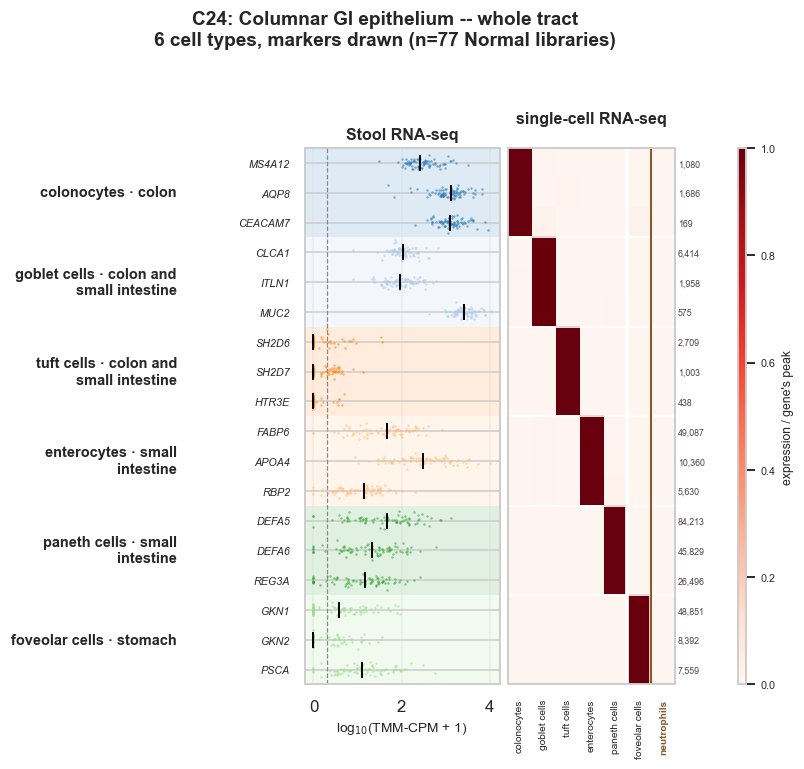

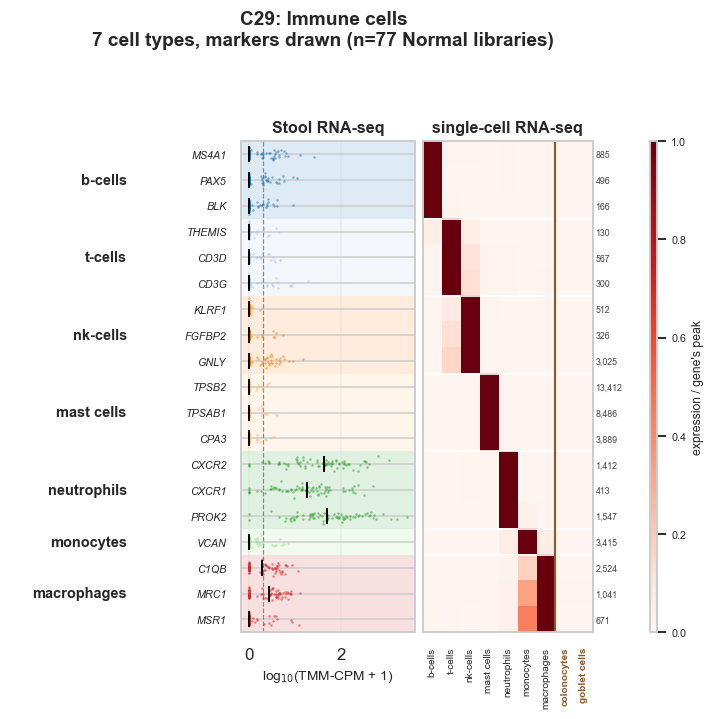

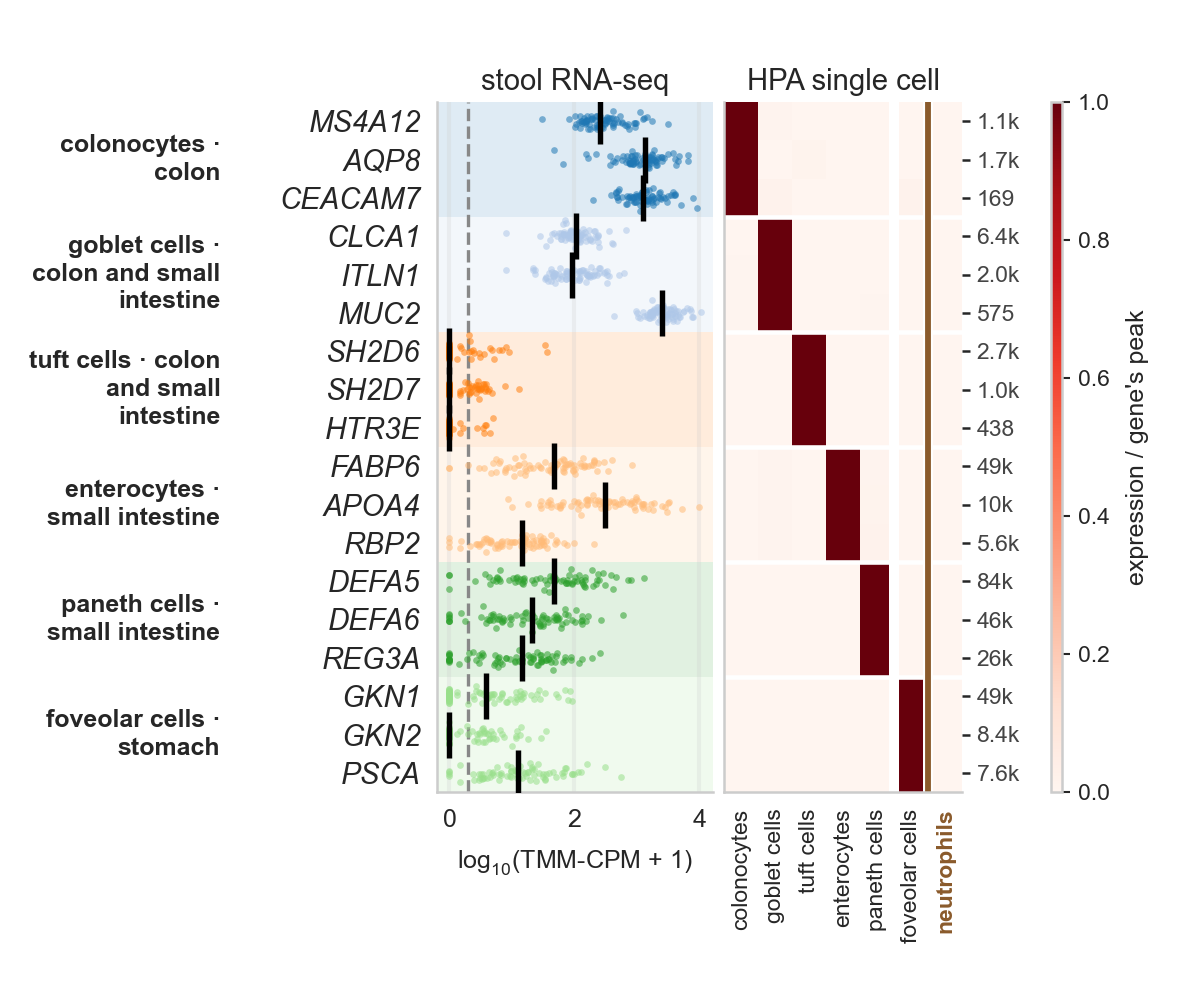

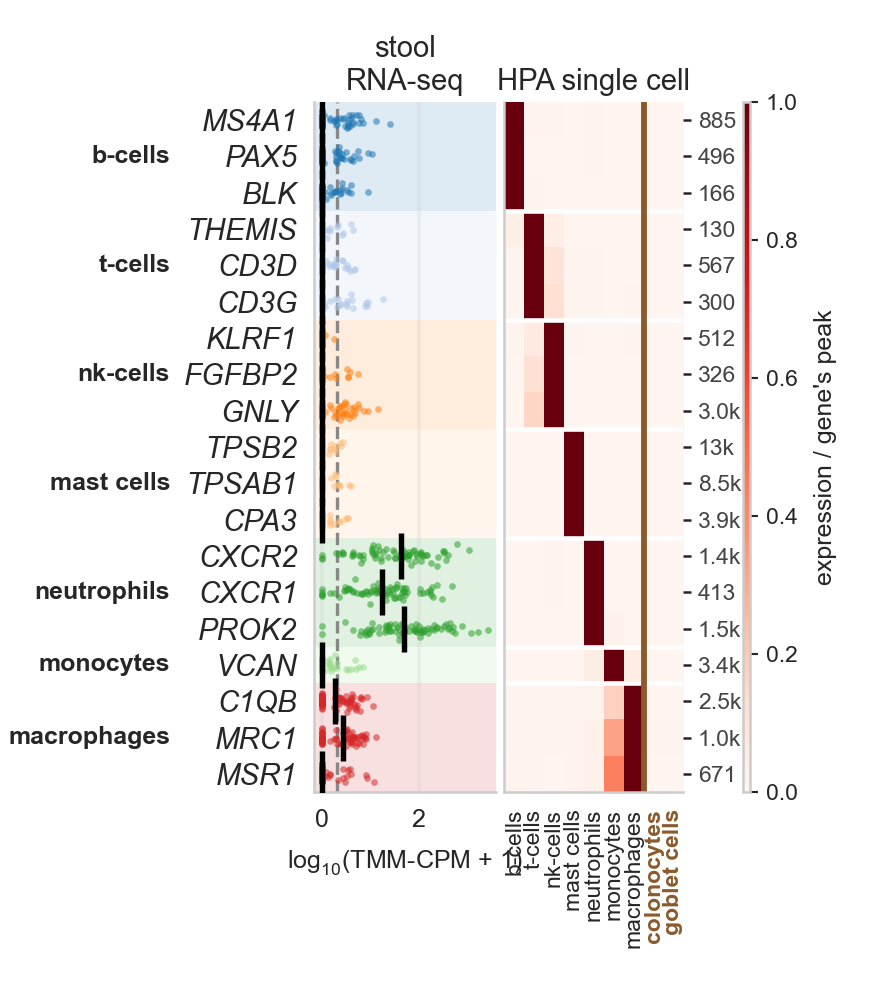

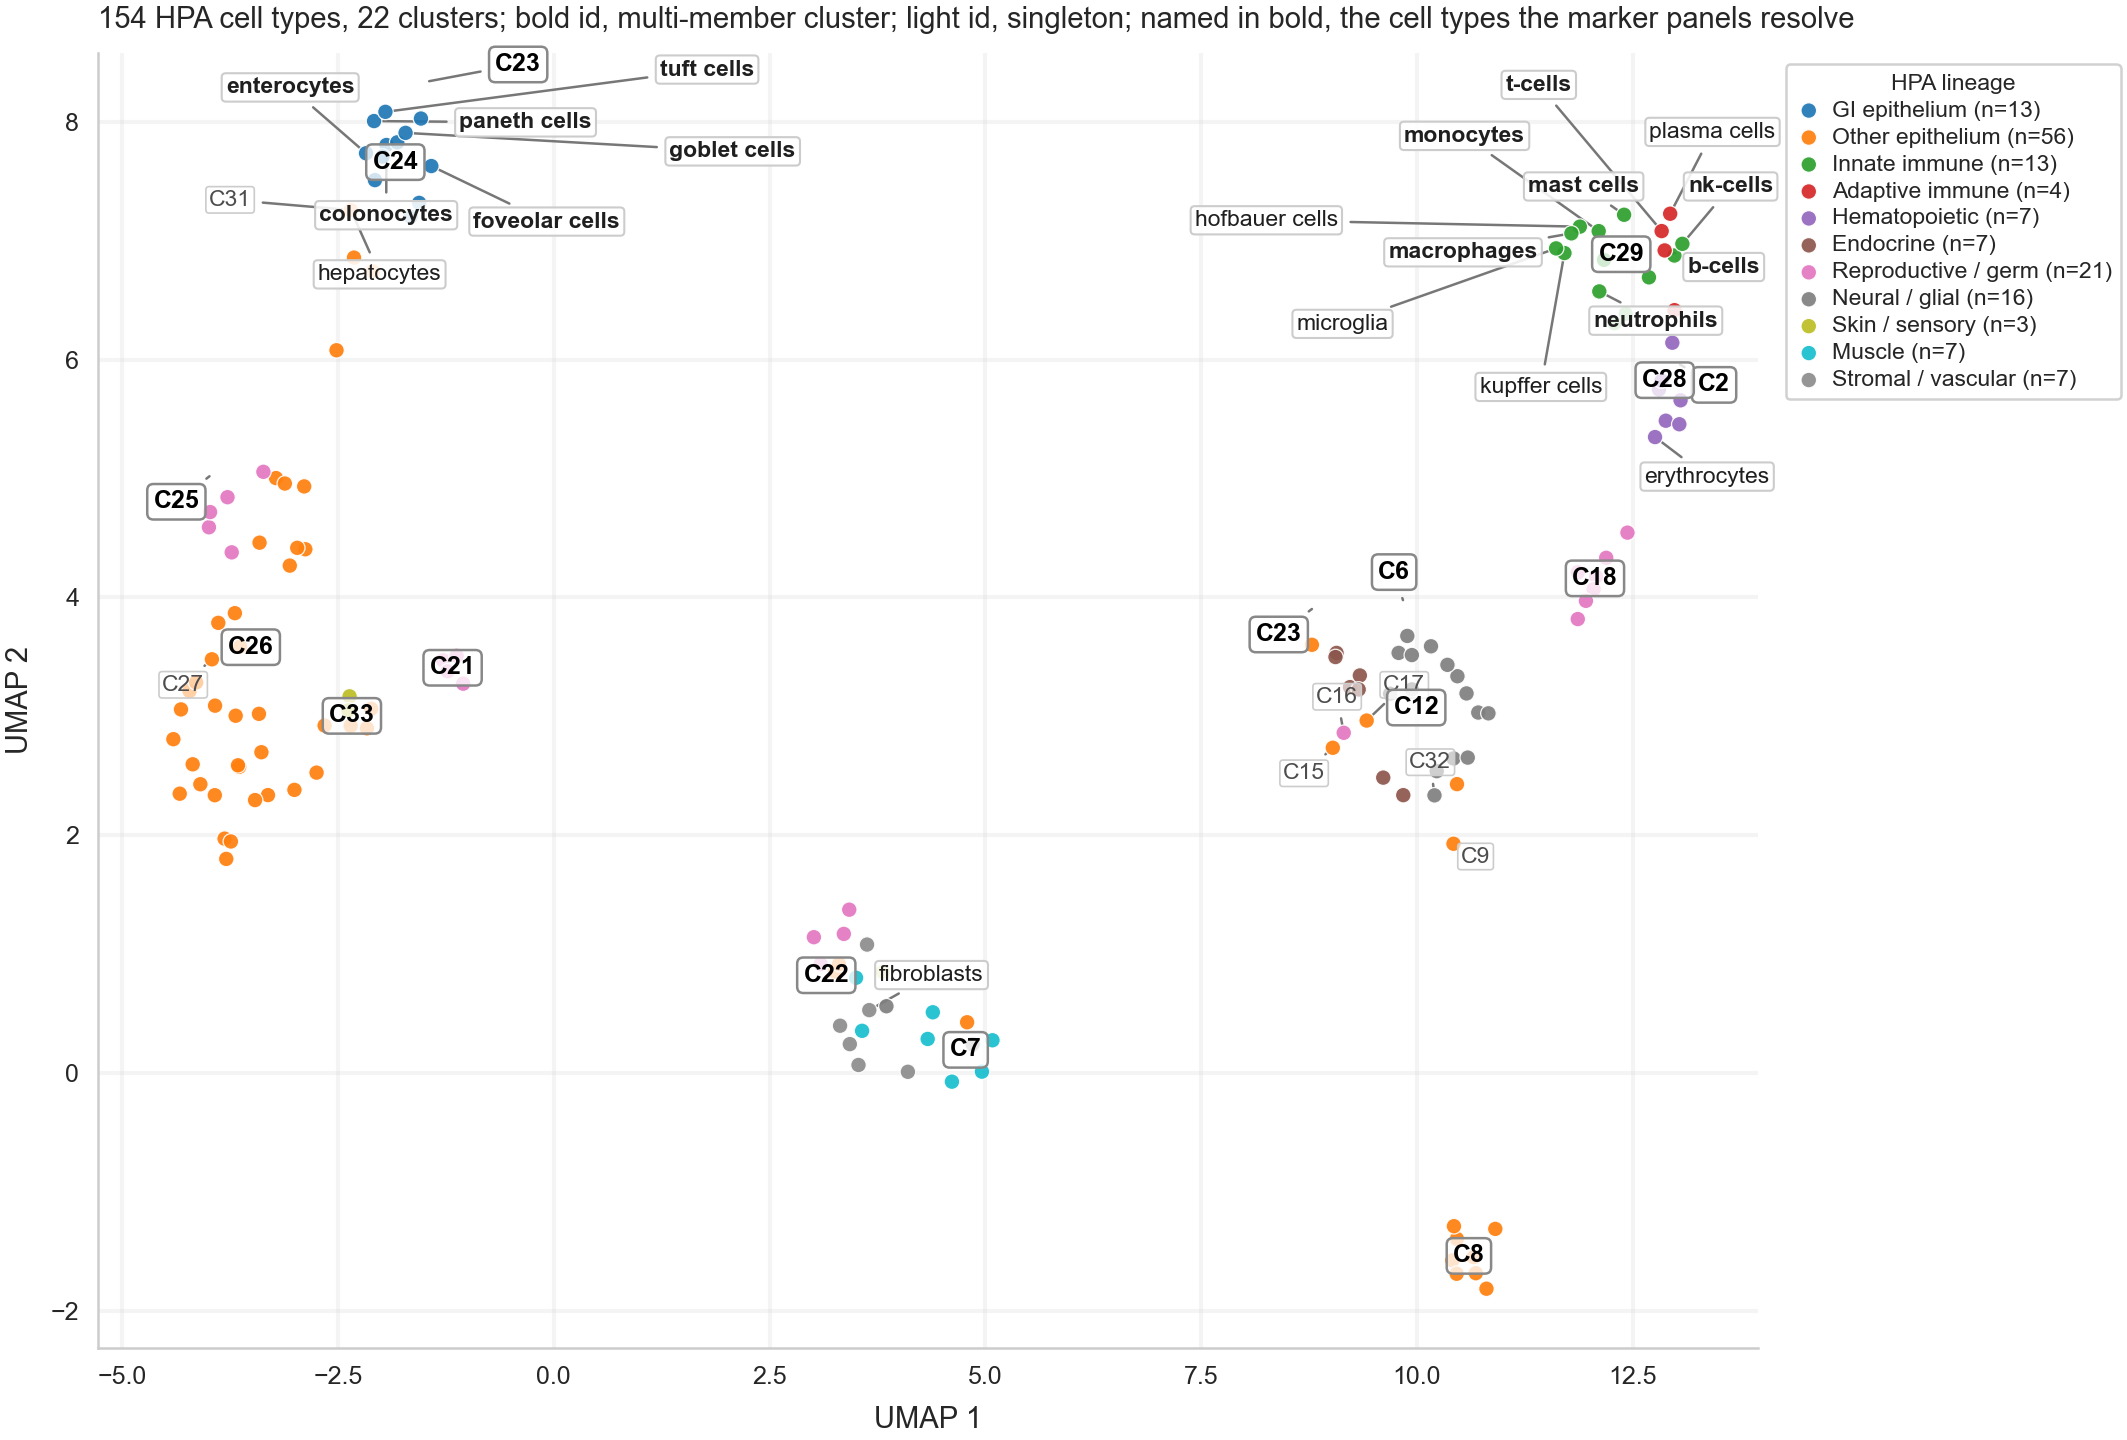

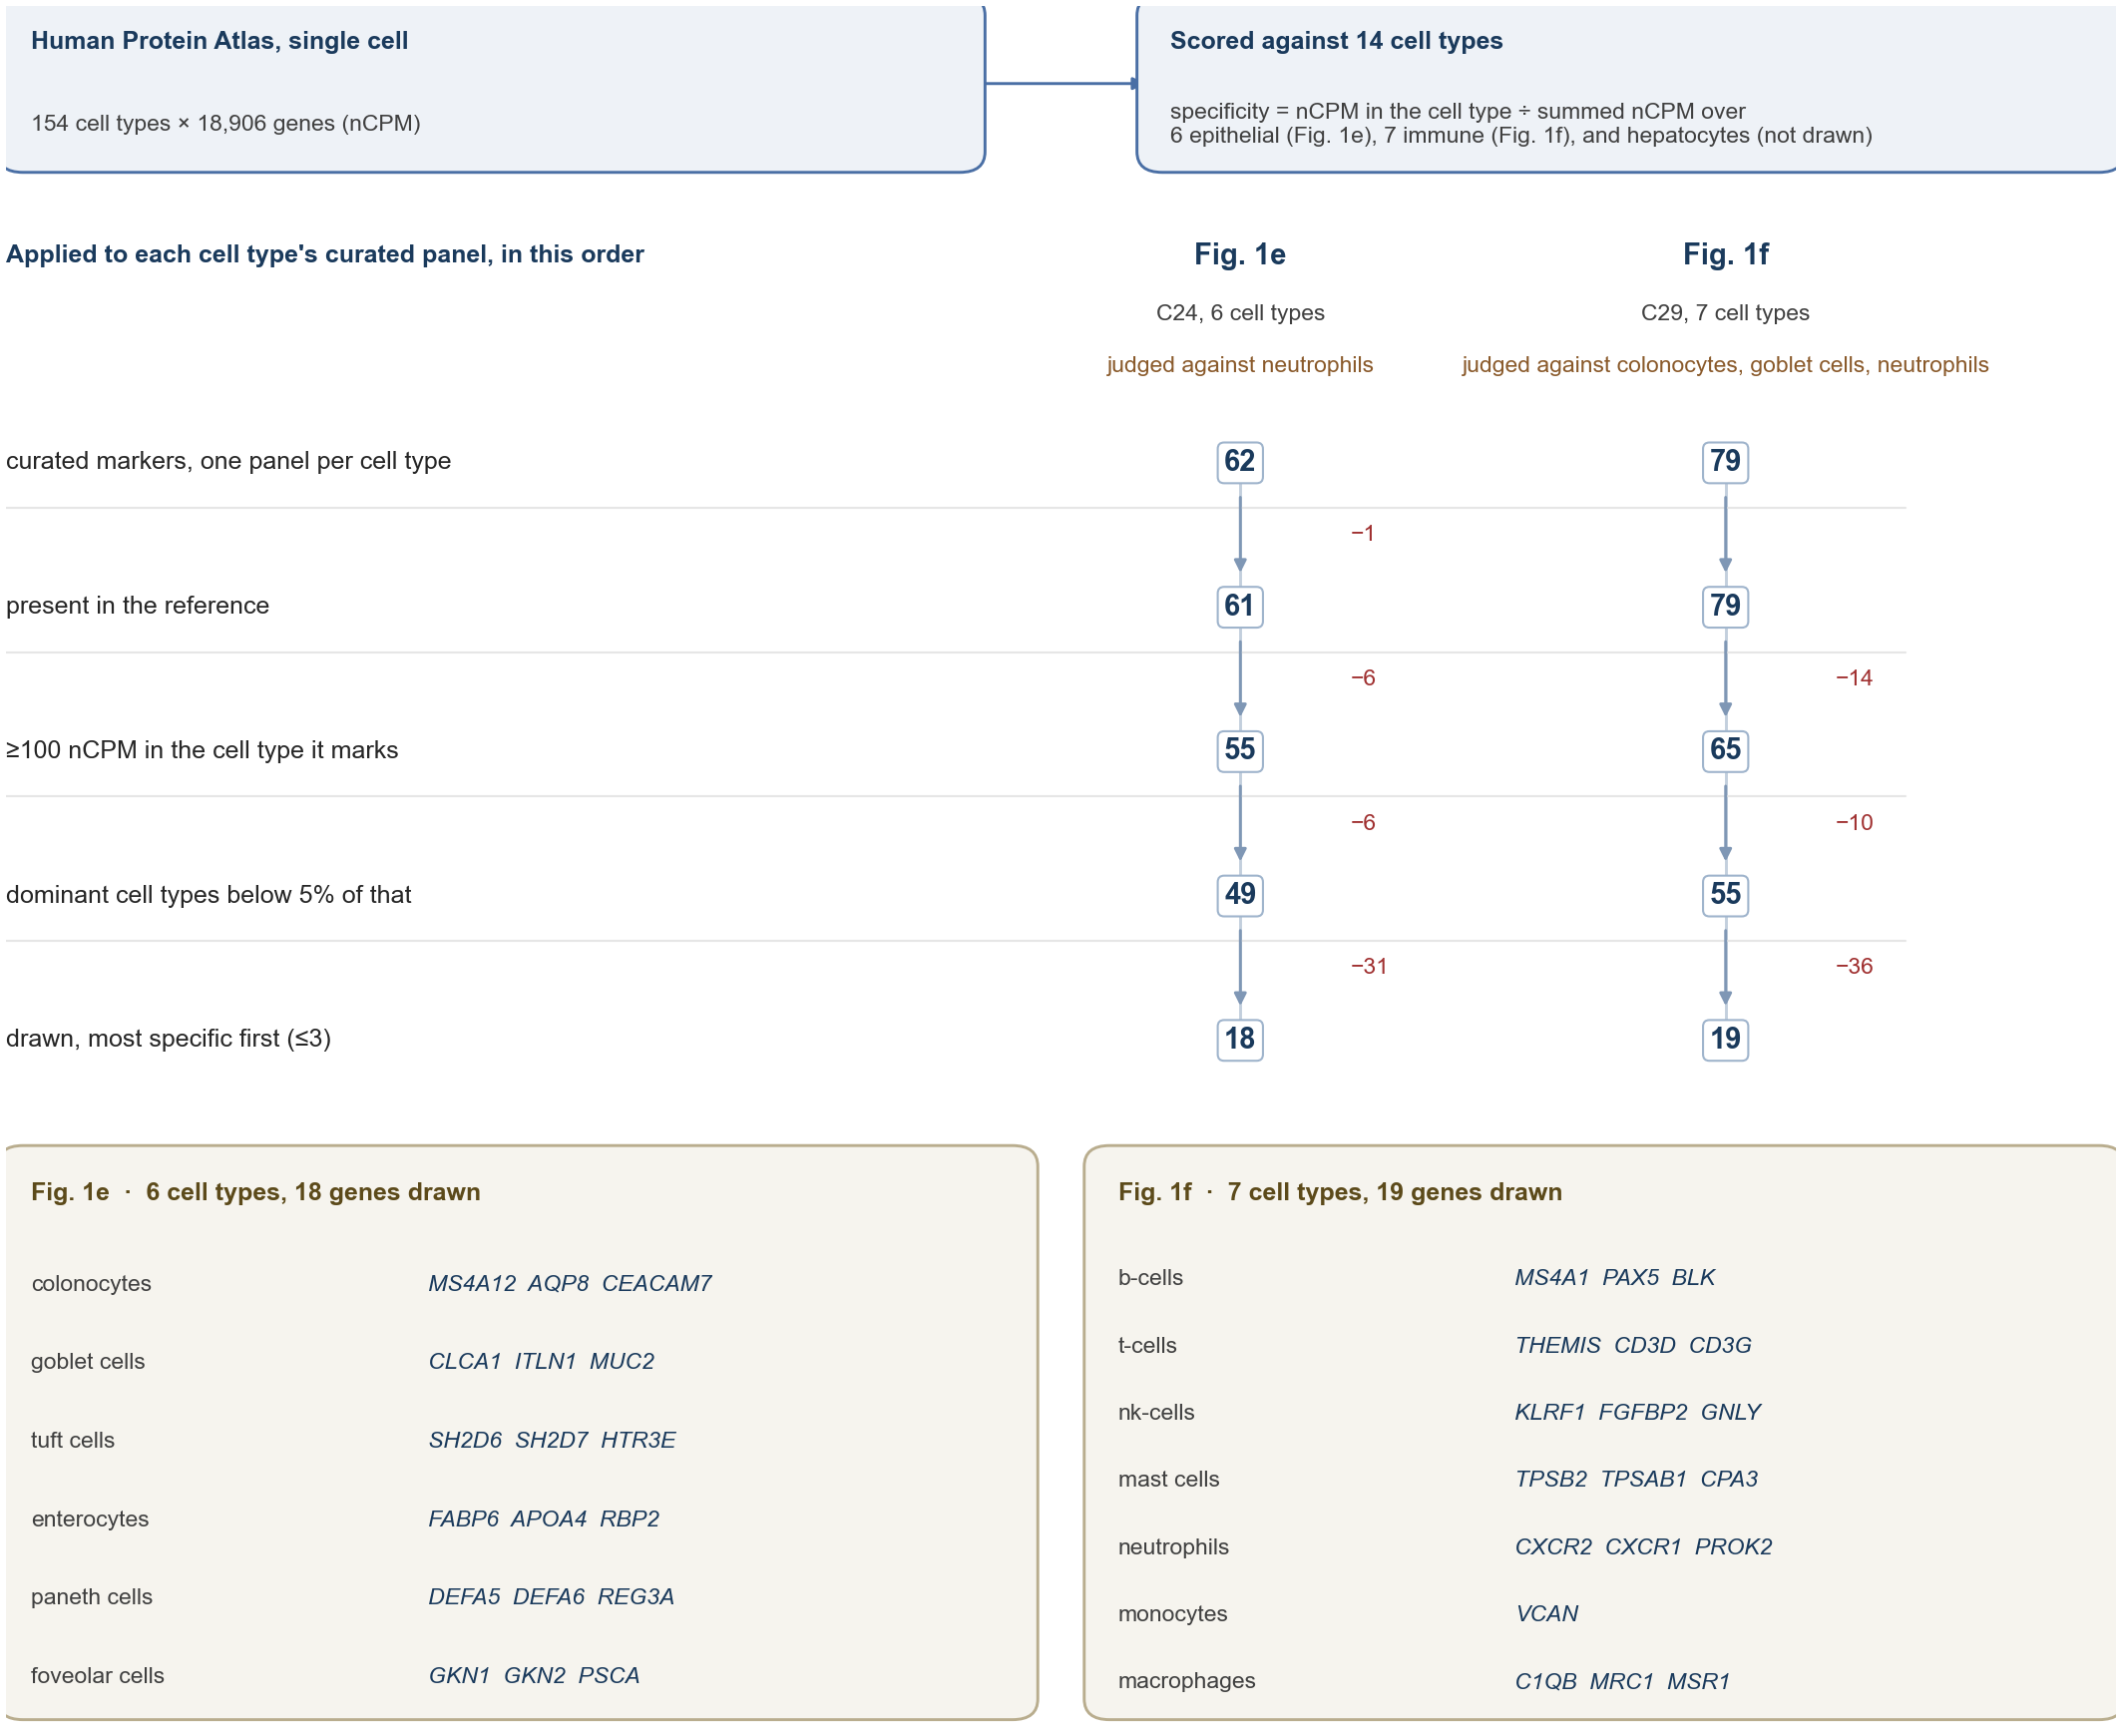

In [9]:
# ----------------------------------------------------------------------------------------------
# [Section 2.3 -- Identifiable GI-epithelial and immune groups in stool]  (notebook cell 15)
# functions from an earlier section: inline_figsize() (Section 0, cell 2); short() (Section 2.1,
#     cell 10)
# imported in an earlier section: BASE_PT (Section 0, cell 2); DOMINANT_FRAC
#     (Section 0, cell 2); flow_arrow() (Section 0, cell 2);
#     flow_box() (Section 0, cell 2); panel() (Section 0, cell 2); RC
#     (Section 0, cell 2); save() (Section 0, cell 2); size()
#     (Section 0, cell 2); tidy() (Section 0, cell 2)
# variables from an earlier section: _cid_of (Section 2.2, cell 12); cluster_members (Section 2,
#     cell 7); emb_df (Section 2.1, cell 9); groups_all (Section 2.3, cell 14); grp_plot
#     (Section 2.2, cell 12); logexpr (Section 2, cell 6); mat (Section 2, cell 7); mk_all
#     (Section 2.3, cell 14); resolution (Section 2.3, cell 14); samples_use (Section 2.1, cell
#     10); top_clusters (Section 2.2, cell 12); expr (Section 2, cell 6); EXPR_COL (Section 2, cell 7)
# ----------------------------------------------------------------------------------------------
# === §2.B.4  What the identifiable groups look like in stool ===
# NOTE (2026-10-21): the five-gate rule the next paragraphs describe is `build_rows`, which this
# cell still runs for the clusters it does not draw (C26, C28, C33, ...). The two clusters
# Figure 1 draws, C24 (Fig. 1e) and C29 (Fig. 1f), use the shortlist rule of the
# `major_cell_type_markers` block further down -- one curated panel per major cell type, scored
# against fourteen cell types, with no stool-detection gate -- and Supplementary Fig. 6 is its funnel.
# §2.B.3 found the finest split of each cluster whose parts still carry their own genes. The
# question now is whether that resolution survives contact with stool, and a signature z-score
# is the wrong instrument for it: z-scoring throws away the absolute level, so a group scored
# entirely off genes sitting at the detection floor looks no different from one carried by genes
# at 100 TPM. The layout below is a marker panel instead -- which members of each
# group own the drawn genes on the left, absolute expression per library in the middle, and the
# HPA evidence that these genes are markers on the right.
#
# Marker rows are each group's §2.B.3 markers, which are already scored against all four
# clusters at once, put through five more filters. The gene must peak inside the group across all
# 154 HPA cell types; it must hold at least MIN_GLOBAL_SHARE of its signal there; it must be
# detected in stool; it must sit at or below NEUT_CEILING nCPM in neutrophils and in neutrophil
# progenitors unless the group contains one of those two; and it must be a marker the field
# already uses to sort or annotate one of the group's cell types. Groups left with fewer than
# MIN_SIG_GENES are named underneath rather than dropped silently.
#
# The share floor is what stops a gene that is loud everywhere from being read as a marker
# because its largest single share happens to fall in the group. HSPA1A and HSPA1B peak in
# microglia but hold only 43% and 35% of their reference signal there -- the HSPA1 locus is
# elevated across every brain cell type in HPA, not in microglia specifically -- and in stool
# they sit near 240 TPM in every library, tracking the neutrophil signature. Without the floor
# they were the two loudest rows in the C29 microglia panel.
#
# The granulocyte ceiling exists because every one of those specificity numbers is a share of
# the gene's own reference profile, and no share can see what the sample is made of. HP holds
# 88% of its reference signal in hepatocytes and 0.2% in neutrophils, and passed every gate above
# on merit; but stool contains no hepatocytes and, in active UC, is flooded with neutrophils, so
# its 144 nCPM of neutrophil expression was the entire signal and the hepatocyte panel rose with
# disease activity (IBD_disease_monitoring.ipynb §A.1.2). ORM1 did the same; CSTA and CSTB did it
# for the squamous group. The ceiling is the abundance term the shares lack. It is aimed at the
# two granulocyte types rather than at every myeloid type because HPA's tissue-resident myeloid
# profiles carry ambient RNA from their neighbours -- Kupffer cells show HP at 678 nCPM, GI mast
# cells show AQP8 and TFF1 above 10 -- and a blanket myeloid ceiling would take real markers down
# with the false ones. The genes it removes are printed under each figure.
#
# The literature intersection is the strongest filter and costs real signal: hepatocytes keep
# 7 of 41 qualifying genes, esophageal apical cells 11 of 67. What it buys is that no drawn gene
# rests on this reference alone. It also settles two groups honestly. Microglia drop out: once
# HSPA1A/B are gone their only literature markers are P2RY12, CX3CR1 and SIGLEC11, none of which
# is detected in a tenth of the normal libraries, so a CNS-resident cell type is reported absent
# instead of being drawn on heat-shock genes. Plasma cells fall below the bar on one gene,
# because the immunoglobulins that define them are missing from the count matrix and only broad
# partners like XBP1 and SDC1 remain.
#
# Only Normal libraries (healthy + NEG + NAPL, pooled as in §2.B) are drawn. The point of this section is what the reference resolution
# looks like in stool at baseline; disease shifts in these genes are the business of the
# monitoring and CRC sections, and mixing groups here would let an IBD neutrophil surge or a CRC
# colonocyte loss set the y-scale. Detection is likewise scored on the normal libraries alone,
# so a gene has to be seen in at least MIN_DETECT of them to be drawn. The GI cluster is laid out
# anatomically, lower GI above upper GI, because in stool that order is the order of plausibility:
# colon and small-bowel epithelium is shed straight into the sample, whereas gastric
# transcripts have to survive the whole small bowel to be seen at all.

# Two is the bar for the inline panels. Colonocytes have exactly two literature markers that
# clear the specificity gate on their own -- AQP8 and MS4A12 -- because OTOP2 sits at 0.77
# against the 0.85 weight floor and only ever passed on how the rest of the pool merged.
# Dropping the most important cell type in the story over that is the worse error.
MIN_SIG_GENES = 2
MIN_DETECT = 0.10        # fraction of libraries with TMM-CPM > 0
N_PER_GROUP = 3          # markers drawn per group, best-expressed first
PANEL_GROUPS = ["Normal"]      # Healthy + NEG + NAPL, as pooled in §2.B
INLINE_CLUSTERS = ("C24", "C29")  # the two clusters shown inline here and drawn as Fig. 1e, f
# C24 is drawn once over the whole tract, lower GI above upper, as Fig. 1e draws it; the
# member-list column is dropped -- see plot_cluster_panel(member_col=False).
INLINE_SLOT = {("C24", "both"): (6.15, 4.75), ("C29", None): (5.68, 4.35)}

# A marker has to be quiet in every other column the figure can draw, not just in granulocytes.
# The heatmap scales each row to its own peak, so a gene a neighbouring column also supplies still
# renders as one dark square: APOC3 peaks at 97,066 nCPM in hepatocytes and reaches 10,695 in
# enterocytes, and 11% of a peak is almost white. The bar is relative because peaks span ~100x
# within a panel -- CLCA1's 12 nCPM in tuft cells is 0.18% of its goblet peak and is as clean as a
# marker gets, while APOC3's 10,695 is 11% -- with an absolute floor underneath so a gene peaking
# at a few hundred nCPM is not held to an unreachable ratio. A gene passes on either.
PEER_CEILING, PEER_FRAC = 10.0, 0.05
_peer_cids = [_cid_of[cl] for cl in top_clusters
              if short(cl).split(":")[0] in ("C24", "C29", "C33")]
PEER_TYPES = sorted({m for c in _peer_cids for m in cluster_members[c]})
_peer_cut = {}

_hpa_peak = mat.idxmax(axis=1)
_libs = [s for s in samples_use if grp_plot[s] in PANEL_GROUPS]
_det = (expr[_libs] > 0).mean(axis=1)

panel_rows, panel_cut = {}, {}
# ==== from scripts/canonical_markers.py: used only in this cell, so it lives here (moved 2026-10-08) =====
# Where along the tract each C24 cell type lives, for ordering the panels anatomically. Upper GI
# is mouth to duodenum plus the organs draining into it; lower GI is jejunum onward. The split
# matters for stool because lower-GI epithelium is shed directly into the lumen the sample comes
# from, whereas upper-GI cells have to survive transit through the small bowel to appear at all.
GI_REGION_ORDER = ["Lower GI", "Upper GI"]
# distal to proximal, i.e. from the sample outward; liver last as the accessory organ
GI_ORGAN_ORDER = ["colon", "colon and small intestine", "intestinal crypt", "small intestine",
                  "stomach", "liver"]
GI_LOCATION: dict[str, tuple[str, str]] = {
    "colonocytes":                        ("Lower GI", "colon"),
    "goblet cells":                       ("Lower GI", "colon and small intestine"),
    "tuft cells":                         ("Lower GI", "colon and small intestine"),
    "enterocytes":                        ("Lower GI", "small intestine"),
    "paneth cells":                       ("Lower GI", "small intestine"),
    "enteric stem cells":                 ("Lower GI", "intestinal crypt"),
    "enteric transient amplifying cells": ("Lower GI", "intestinal crypt"),
    "foveolar cells":                     ("Upper GI", "stomach"),
    "mucous neck cells":                  ("Upper GI", "stomach"),
    "gastric chief cells":                ("Upper GI", "stomach"),
    "parietal cells":                     ("Upper GI", "stomach"),
    "gastric progenitor cells":           ("Upper GI", "stomach"),
    "hepatocytes":                        ("Upper GI", "liver"),
}
# Markers whose textbook role is a cell-cycle or progenitor programme rather than a lineage gene.
# They cannot pass a specificity threshold and are not supposed to: every proliferating cell in
# the reference expresses them.
PROLIFERATION = {"MKI67", "PCNA", "TOP2A", "CCNB1", "BIRC5", "UBE2C", "STMN1", "MYC", "SOX9"}
def panel_for(group: list[str]) -> set[str]:
    """Every literature marker of any member of a group."""
    return {g for m in group for g in CANONICAL.get(m, [])}


# ==== from scripts/group_expression_panels.py: used only in this cell, so it lives here (moved 2026-10-08) =====
#
# gene expression panels: marker genes in stool, beside the HPA profiles that define them.
#
# A z-score boxplot per group answers "does this signature move with disease" but hides the two
# things that decide whether the signature means anything: how much of each gene is actually there
# in stool, and how cleanly that gene separates its group from the other members of its cluster.
# This code draws both, side by side:
#
#   left    the members whose genes the drawn rows actually peak in, above the members that share
#           the deconvolution column but contribute none of the signal. It leads because it is the
#           row labels of everything to its right: the expression of a band means nothing until you
#           know whose band it is
#   middle  every library as a point, log10 expression per gene -- the absolute level, not a
#           z-score, so a gene sitting at the detection floor is visible as such
#   right   the same genes across the cluster's member cell types in the HPA reference, scaled to
#           each gene's own maximum. Absolute nCPM would colour a gene red across the whole row
#           whenever it is loud everywhere, which is the opposite of what this panel is for: the
#           question is whether the gene picks out its group, and the peak value is printed beside
#           the row so the absolute level is not lost
#
# The original's pie chart, and the per-group share bars that replaced it here, are gone. The
# quantity was each group's share of the marker transcripts *this figure happens to draw*, which
# invites the abundance reading it cannot support: the denominator is a gene set capped at
# n_per_group, so raising the cap moves every bar, and one loud marker outranks five quiet ones.
# Composition belongs in §2.B, where it is fitted over all genes rather than read off a legend.
#
# Rows are the markers of each identifiable group from `resolve_pooled` (Section 2.3), banded by group. How to
# read the columns belongs in the notebook markdown above the figure, not under its title.

import textwrap

FLOOR = 1.0           # added before log10: TMM-CPM + 1, so an undetected gene sits at 0
# The leftmost column names the cell types, which is what the reader has to hold in mind while
# looking at everything to its right, so it is set large enough to read at a glance. Wrapping is
# derived from the width and the point size rather than fixed, or raising one silently overflows
# the column: 0.062 in per character at 6.6 pt, scaled linearly.
TEXT_COL_W = 1.60     # width ratio of the member-list column
# HPA cell-type names long enough to set the figure's height when they are the rotated heatmap
# column labels. Only the spelling on the axis changes; the reference columns are unchanged.
COL_ABBREV = {
    "enteric transient amplifying cells": "enteric TA cells",
    "gastric progenitor cells": "gastric progenitors",
    "neutrophil progenitors": "neutrophil prog.",
    "monocyte progenitors": "monocyte prog.",
    "erythrocyte progenitors": "erythrocyte prog.",
    "megakaryocyte progenitors": "megakaryocyte prog.",
    "megakaryocyte-erythroid progenitors": "MK-erythroid prog.",
    "hematopoietic stem cells": "HSCs",
    "innate lymphoid cells": "innate lymphoid",
    "epididymal efferent duct ciliated cells": "epidid. duct ciliated",
    "epididymal efferent duct absorptive cells": "epidid. duct absorptive",
}
# What each cluster's panel shows beside its own members: the cell types that dominate a stool
# library and could therefore be supplying a gene the reference calls specific to something else.
# The epithelial panel carries neutrophils, which flood the sample in active colitis; the immune
# panel carries the epithelium, which is most of a normal library. Defined once, because the
# journal figure and the science deck both draw these panels and must show the same columns.
DOMINANT_COLS = {"C24": ["neutrophils"], "C29": ["colonocytes", "goblet cells"]}
EXTRA_COL = "#8a5a2b"     # the rule and label colour that marks them as not members
HEAD_FS = 9.0         # the members that own the drawn genes
REST_FS = 7.4         # the members carried along with them
# The widest a band name is allowed to wrap, in characters. A band names every cell type merged
# into its group, not only the ones whose genes are drawn, so the labels are longer than they
# were when the column carried a single name. This is a ceiling, not a setting: at journal size
# `manuscript_figures._fit_cluster_panel` measures each label against the room its column
# actually has and narrows the wrap until it fits, because the two Figure-1 panels are 3.3 and
# 4.4 in wide and one character count cannot serve both.
BAND_WRAP = 24
MIN_GLOBAL_SHARE = 0.50   # of the gene's signal over all 154 cell types, see build_rows
# Every specificity number above is a share of the gene's own reference profile, and no share can
# see what a sample is made of. HP holds 88% of its reference signal in hepatocytes and 0.2% in
# neutrophils; in a stool library where hepatocytes contribute no cells and neutrophil transcripts
# have moved 200-fold with disease, its 144 nCPM of neutrophil expression is the whole signal, and
# the "hepatocyte" panel rises with UC activity (IBD_disease_monitoring.ipynb §A.1.2). The ceiling
# is the abundance term the shares lack: an absolute bound on expression in the two cell types that
# actually flood the sample. It is aimed at those two rather than at every myeloid type because
# HPA's tissue-resident myeloid profiles carry ambient RNA from their neighbours -- Kupffer cells
# show HP at 678 nCPM, GI mast cells show AQP8 and TFF1 above 10 -- and a blanket ceiling would
# take real markers down with the false ones. Groups that contain either cell type are exempt.
NEUT_CEILING = 10.0
GRANULOCYTE = ["neutrophils", "neutrophil progenitors"]
def build_rows(groups, markers, mat, hpa_peak, detected, logexpr_index, n_per_group=5,
               min_detect=0.10, min_genes=3, min_global_share=MIN_GLOBAL_SHARE, lit_panel=None,
               gran_ceiling=NEUT_CEILING, gran_types=GRANULOCYTE,
               peer_types=None, peer_ceiling=None, peer_frac=None, peer_cut=None):
    """Marker rows per group: literature-confirmed, globally specific, quiet in granulocytes,
    present in stool.

    Requiring only that the gene's argmax over the 154 cell types falls inside the group is too
    weak for genes that are loud everywhere. HSPA1A and HSPA1B peak in microglia and so passed,
    but hold just 43% and 35% of their signal there, and in stool they sit at ~240 TPM in every
    library -- so the microglia panel was drawn on two heat-shock genes that track neutrophils.
    `min_global_share` adds the missing floor: the group must hold that fraction of the gene's
    signal across the whole reference, not merely the largest single share of it.

    `gran_ceiling` bounds expression in `gran_types` (see NEUT_CEILING above) for every group
    that does not itself contain one of those cell types. Pass None to switch it off.

    `lit_panel` maps a group to the genes the field uses to sort or annotate those cell types
    (canonical_markers.panel_for). With it, a row has to be both a marker the data picked out and
    a marker the literature already recognised. That is a deliberately conservative intersection:
    it discards real signal -- HPA's own top hepatocyte genes go from 37 to 7 -- in exchange for
    every drawn gene being one the reader can check against something outside this dataset.

    `peer_types` is every cell type the figure can draw as a column. A marker has to be quiet in
    all of them outside its own group, or the panel shows a gene as specific when a neighbouring
    column supplies it too: APOC3 peaks at 97,066 nCPM in hepatocytes but reaches 10,695 in
    enterocytes, and because the heatmap scales each row to its own peak, 11% renders as almost
    white. The test is relative -- `peer_frac` of the gene's own peak -- because the peaks span
    ~100x across a panel, so an absolute bar cannot tell trace from real: CLCA1 at 12 nCPM in
    tuft cells is 0.18% of its goblet peak and as clean a marker as exists, while APOC3's 10,695
    is 11%. `peer_ceiling` is an absolute escape underneath it, so a gene whose peak is only a
    few hundred nCPM is not held to an unreachable ratio. A gene passes on either. Both None
    switches the gate off, which is the default and leaves every existing caller unchanged.

    Returns (rows, skipped, cut). `cut` maps each group (as a sorted tuple) to the genes the
    granulocyte ceiling removed after they had cleared every other bar, so the price of the gate
    is reportable; pass a dict as `peer_cut` to get the same record for the peer gate, which is
    kept separate so the two reasons for dropping a gene do not get confused. A group needs
    `min_genes` survivors to be drawn -- the same bar the signature scoring uses, so the two
    sections describe the same set of groups.
    """
    total = mat.sum(axis=1)
    gran_types = [t for t in gran_types if t in mat.columns]
    gran_max = mat[gran_types].max(axis=1) if gran_types else None
    rows, skipped, cut = [], [], {}
    for j, g in enumerate(groups):
        lit = lit_panel(g) if lit_panel is not None else None
        exempt = gran_ceiling is None or gran_max is None or bool(set(g) & set(gran_types))
        use = [x for x in markers[j].index
               if hpa_peak.get(x) in g and x in logexpr_index and detected.get(x, 0) >= min_detect
               and total.get(x, 0) > 0 and mat.loc[x, g].sum() / total[x] >= min_global_share
               and (lit is None or x in lit)]
        if not exempt:
            cut[tuple(sorted(g))] = [x for x in use if gran_max[x] > gran_ceiling]
            use = [x for x in use if gran_max[x] <= gran_ceiling]
        if peer_types and (peer_ceiling is not None or peer_frac is not None):
            peers = [c for c in peer_types if c not in g and c in mat.columns]

            def _quiet(x, _peers=peers, _g=g):
                own = float(mat.loc[x, _g].max())
                worst = float(mat.loc[x, _peers].max()) if _peers else 0.0
                if peer_ceiling is not None and worst < peer_ceiling:
                    return True
                return peer_frac is not None and own > 0 and worst / own <= peer_frac

            if peer_cut is not None:
                peer_cut[tuple(sorted(g))] = [
                    (x, float(mat.loc[x, peers].max()), float(mat.loc[x, g].max()))
                    for x in use if not _quiet(x)]
            use = [x for x in use if _quiet(x)]
        if len(use) >= min_genes:
            rows.append((sorted(g), use[:n_per_group]))
        else:
            skipped.append((sorted(g), len(markers[j]), len(use)))
    return rows, skipped, cut
def _owners(mat, grp_members, gs):
    """Members a set of drawn genes actually peak in, in order of first appearance."""
    return list(dict.fromkeys(mat.loc[gs, grp_members].idxmax(axis=1)))
def fit_region_headers(ax_h, renderer, floor_pt: float) -> bool:
    """Fit each region header to the block of columns it names; draw none if one cannot fit.

    A header is shortened before it is shrunk -- "Upper GI" to "Upper", the second word being the
    one the column names below already repeat -- and is never set below `floor_pt`. One that is
    still wider than its block at the floor prints over its neighbour's columns: once hepatocytes
    left the panel (2026-09-29) "Upper" named a single column, the stomach's, and ran into
    "Lower GI". A panel that heads one region and not the other reads as an omission, so the
    headers are shown together or not at all. The white rule between the regions stays either
    way, and every band of rows still names the organ its cell type comes from.

    Returns whether the headers are shown, so the caller can give the heading above them the
    clearance it then needs.
    """
    heads = [t for t in ax_h.texts if getattr(t, "block_span", None) is not None]
    fits = True
    for t in heads:
        t.set_visible(True)                       # a hidden text measures as an empty box
        x0 = ax_h.transData.transform((t.block_span[0] - 0.5, 0))[0]
        x1 = ax_h.transData.transform((t.block_span[1] + 0.5, 0))[0]
        avail, words = (x1 - x0) * 0.94, t.get_text().split()
        if t.get_window_extent(renderer).width > avail and len(words) > 1:
            t.set_text(words[0])
        w = t.get_window_extent(renderer).width
        if w > avail:
            t.set_fontsize(max(floor_pt, t.get_fontsize() * avail / w))
            fits = fits and t.get_window_extent(renderer).width <= avail * 1.02
    for t in heads:
        t.set_visible(fits)
    return fits
def plot_cluster_panel(rows, expr, mat, members, title, figsize=None, location=None,
                       region_order=None, organ_order=None, member_col=True, extra_cols=None):
    """Draw the panel figure for one cluster. `rows` is [(group_members, genes), ...].

    `location` maps a cell type to (region, organ). When given, row bands and heatmap columns
    are ordered by region and then organ instead of by marker strength, a bracket at the far left
    names each region, and each group's header carries its organ. A merged group is placed by the
    member its drawn genes peak in, not by its passengers -- the goblet group carries gastric
    progenitors, but its genes are goblet genes, so it sits with the colon.

    `member_col=False` drops the wide "which members own the drawn genes" column and names each
    band with a bracket and a rotated label in the narrow column instead. That column is a legend
    rather than data, and on a slide it costs about a third of the width the type needs; the
    passenger members it also lists stay in group_marker_panels.csv.
    """
    if location:
        order = region_order or sorted({r for r, _ in location.values()})
        organs = organ_order or sorted({o for _, o in location.values()})

        def _key(ct):
            reg, org = location.get(ct, ("", ""))
            return (order.index(reg) if reg in order else len(order),
                    organs.index(org) if org in organs else len(organs))

        rows = sorted(rows, key=lambda r: _key(_owners(mat, *r)[0]))

    genes = [g for _, gs in rows for g in gs]
    bands, y0 = [], 0
    for grp_members, gs in rows:
        bands.append((y0, y0 + len(gs), grp_members))
        y0 += len(gs)
    n = len(genes)

    # heatmap columns ordered so members of the same group sit together, matching the row bands;
    # with a location map, a stable sort on (region, organ) goes on top so the columns read
    # anatomically while groups still stay adjacent within an organ
    cols, seen = [], set()
    for grp_members, _ in rows:
        for m in grp_members:
            if m not in seen:
                cols.append(m); seen.add(m)
    cols += [m for m in members if m not in seen]
    if location:
        cols = sorted(cols, key=_key)
        if region_order and len(region_order) == 1:
            # a single-region figure: passenger members from the other end of the tract would
            # otherwise pull in a column and a region header the figure is not about
            cols = [c for c in cols if location.get(c, ("", ""))[0] == region_order[0]]
    # Reference columns from outside this cluster, appended last and after any location sort so
    # they are never mistaken for members of it. They are the cell types that dominate a stool
    # library -- neutrophils beside the epithelial panel, the epithelium beside the immune one --
    # and they are here so that a reader can see for themselves that a drawn marker is quiet in
    # whatever else the sample is full of, instead of taking the selection rule's word for it.
    n_own = len(cols)
    cols += [c for c in (extra_cols or []) if c not in cols and c in mat.columns]

    # Who each band of rows is has to be read before the expression means anything, so the member
    # list leads and the data follows it left to right. The gene labels of the strip plot hang to
    # its left, over the region-bracket column, so that column is wide enough that its left half
    # -- where the bracket is drawn -- stays clear of them.
    if member_col:
        ratios = [TEXT_COL_W, 0.34, 1.25, 0.075 * len(cols) + 0.55, 0.30, 0.05]
    else:
        ratios = [1.60, 1.25, 0.075 * len(cols) + 0.55, 0.30, 0.05]
    fig = plt.figure(figsize=figsize or
                     (14.9 + 0.17 * len(cols) - (0 if member_col else 3.4 * TEXT_COL_W),
                      max(4.8, 0.207 * n + 2.6)))
    gs = fig.add_gridspec(1, len(ratios), width_ratios=ratios, wspace=0.06)
    if member_col:
        ax_t, ax_r, ax_s = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[2])
        ax_h, cax = fig.add_subplot(gs[3]), fig.add_subplot(gs[5])
    else:
        ax_t = None
        ax_r, ax_s = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
        ax_h, cax = fig.add_subplot(gs[2]), fig.add_subplot(gs[4])
    colours = sns.color_palette("tab20", max(len(rows), 3))

    # --- between the member list and the strip: which region each band of rows comes from ----
    ax_r.set_ylim(n - 0.5, -0.5)
    ax_r.set_xlim(0, 1)
    ax_r.axis("off")
    if member_col and location:
        spans = {}
        for lo, hi, grp_members in bands:
            reg = location.get(_owners(mat, grp_members, genes[lo:hi])[0], ("", ""))[0]
            a, b = spans.get(reg, (lo, hi))
            spans[reg] = (min(a, lo), max(b, hi))
        for reg, (lo, hi) in spans.items():
            ax_r.plot([0.40, 0.40], [lo - 0.35, hi - 0.65], color="#333333", lw=1.4,
                      solid_capstyle="butt")
            for y in (lo - 0.35, hi - 0.65):
                ax_r.plot([0.30, 0.40], [y, y], color="#333333", lw=1.4)
            ax_r.text(0.16, (lo + hi - 1) / 2, reg, rotation=90, ha="center", va="center",
                      fontsize=9.5, fontweight="bold")
    elif not member_col:
        # Each band names every cell type the deconvolution merged into that group, the members
        # whose genes are drawn first. Naming only the owners was misleading in the direction
        # that matters: the C29 panel showed bands called "cdc" and "nk-cells" for groups that
        # also contain macrophages and monocytes, and t-cells and innate lymphoid cells, so
        # three major immune populations appeared nowhere in the figure and a reader could take
        # them to be absent from stool. The merge is the claim -- these types could not be told
        # apart by their markers -- and the band has to say so. Wrapped and right-aligned so the
        # strip plot's gene labels, which hang left into this column, stay clear.
        for lo, hi, grp_members in bands:
            own = _owners(mat, grp_members, genes[lo:hi])
            names = [COL_ABBREV.get(m, m) for m in own
                     + [m for m in grp_members if m not in own]]
            label = " + ".join(names)
            # A gastrointestinal band also names its organ -- "colonocytes · colon" -- so the
            # anatomy is read off the band and not inferred from the region bracket above the
            # columns. Taken from the member the drawn genes peak in, as the band's position is.
            if location and own and location.get(own[0]):
                label += f" · {location[own[0]][1]}"
            ax_r.text(0.52, (lo + hi - 1) / 2, textwrap.fill(label, BAND_WRAP),
                      ha="right", va="center", fontsize=9.5, fontweight="bold",
                      linespacing=1.25)

    for (lo, hi, _), c in zip(bands, colours):
        for ax in (ax_s, ax_t) if ax_t is not None else (ax_s,):
            ax.axhspan(lo - 0.5, hi - 0.5, color=c, alpha=0.14, lw=0, zorder=0)

    # --- left: every library, absolute level ------------------------------------------------
    rng = np.random.default_rng(0)
    for i, g in enumerate(genes):
        v = np.log10(expr.loc[g].to_numpy(dtype=float) + FLOOR)
        c = colours[[k for k, (lo, hi, _) in enumerate(bands) if lo <= i < hi][0]]
        ax_s.scatter(v, i + rng.normal(0, 0.11, len(v)), s=2.6, color=c, alpha=0.55,
                     linewidths=0, zorder=3)
        ax_s.plot([np.median(v)], [i], marker="|", ms=11, color="black", mew=1.3, zorder=4)
    ax_s.set_yticks(range(n))
    ax_s.set_yticklabels(genes, fontsize=7, fontstyle="italic")
    ax_s.set_xlabel("stool expression, log$_{10}$(TMM-CPM + 1)" if member_col
                    else "log$_{10}$(TMM-CPM + 1)", fontsize=9)
    ax_s.axvline(np.log10(1 + FLOOR), color="#888888", lw=0.8, ls="--", zorder=1)
    ax_s.set_ylim(n - 0.5, -0.5)
    ax_s.grid(axis="x", alpha=0.25)
    ax_s.set_axisbelow(True)
    ax_s.set_title("Stool RNA-seq", fontsize=10.5, fontweight="bold")

    # --- middle: the HPA evidence that these are markers ------------------------------------
    R = mat.loc[genes, cols].to_numpy(dtype=float)
    peak = R.max(axis=1)
    im = ax_h.imshow(R / np.where(peak > 0, peak, 1)[:, None], aspect="auto", cmap="Reds",
                     vmin=0, vmax=1)
    ax_h.grid(False)            # the notebook's whitegrid theme otherwise prints through the blocks
    ax_h.set_xticks(range(len(cols)))
    ax_h.set_xticklabels([COL_ABBREV.get(c, c) for c in cols], rotation=90, fontsize=6.6)
    ax_h.set_ylim(n - 0.5, -0.5)
    for lo, hi, _ in bands[:-1]:
        ax_h.axhline(hi - 0.5, color="white", lw=1.1)
    if location and not (region_order and len(region_order) == 1):
        # the same region split on the columns, so the reader can see that lower-GI genes stay
        # inside lower-GI columns rather than leaking into the stomach or liver
        regs = [location.get(c, ("", ""))[0] for c in cols]
        for k in range(1, len(cols)):
            if regs[k] != regs[k - 1]:
                ax_h.axvline(k - 0.5, color="white", lw=2.4)
        for reg in dict.fromkeys(regs[:n_own]):
            idx = [k for k, r in enumerate(regs[:n_own]) if r == reg]
            label = (reg or "other") if len(idx) >= 3 else (reg or "other").split()[0]
            t = ax_h.text((idx[0] + idx[-1]) / 2, -0.75, label, ha="center",
                          va="bottom", fontsize=7.5, fontweight="bold", clip_on=False)
            # the columns each header spans, so the journal-size refit can check the header
            # against the room it has: with seven columns rather than thirteen, "Upper GI"
            # is wider than the two columns it names and printed into its neighbour
            t.block_span = (idx[0], idx[-1])
    if len(cols) > n_own:
        # the reference columns are marked on the columns themselves -- a rule and a colour --
        # rather than by a header above them: a header collides with the panel title, and in the
        # immune panel it takes the vertical room the band names need
        ax_h.axvline(n_own - 0.5, color=EXTRA_COL, lw=1.4)
        for k, t in enumerate(ax_h.get_xticklabels()):
            if k >= n_own:
                t.set_color(EXTRA_COL)
                t.set_fontweight("bold")
    # The row scaling throws away the absolute level, so carry the peak nCPM as a right-hand
    # label. The global specificity of each gene is in group_marker_panels.csv rather than here.
    ax_h.yaxis.set_ticks_position("right")
    ax_h.set_yticks(range(n))
    ax_h.set_yticklabels([f"{p:,.0f}" for p in peak], fontsize=5.8, color="#444444")
    ax_h.tick_params(axis="y", length=0, pad=1.5)
    # the title clears the region headers when they are drawn; with both regions on one panel
    # the headers sit above the column block and need the larger clearance at any type size
    both_regions = bool(location) and not (region_order and len(region_order) == 1)
    ax_h.set_title("HPA single-cell reference" if member_col else "single-cell RNA-seq",
                   fontsize=10.5, fontweight="bold",
                   pad=24 if both_regions else (16 if location else 6))
    # what the heading falls back to if the region headers turn out not to fit (below)
    ax_h.pad_without_headers = 16 if location else 6
    cb = fig.colorbar(im, cax=cax)
    cb.set_label("expression / gene's peak", fontsize=8)
    # The colourbar is now the rightmost axis, so its ticks go back to the right; on its left is
    # the gap holding the heatmap's peak-nCPM labels.
    cb.ax.tick_params(labelsize=7)

    # --- far left: who owns the markers, then everyone else in the group ---------------------
    # A merged group has to be named by the members its drawn genes peak in, not by whichever
    # member sorts first. The C24 group of stem, transit-amplifying, gastric progenitor and
    # goblet cells is drawn on ZG16, SPINK4 and CLCA1, all goblet genes; calling it "colonocytes"
    # or even "enteric stem cells + 3" reads as a claim that those cells express them. The
    # members that own no drawn gene are still listed underneath -- they are in the column the
    # deconvolution fits -- but as passengers, which is what they are.
    _wrap = lambda fs: max(18, int(2.2 * TEXT_COL_W / (0.062 * fs / 6.6)))   # noqa: E731
    for (lo, hi, grp_members), c in zip(bands, colours) if ax_t is not None else ():
        owners = _owners(mat, grp_members, genes[lo:hi])
        rest = [m for m in grp_members if m not in owners]
        mid = (lo + hi - 1) / 2
        head = " / ".join(owners)
        if location and owners[0] in location:
            head += f"  [{location[owners[0]][1]}]"
        head = textwrap.fill(head, _wrap(HEAD_FS))
        if rest:
            ax_t.text(0.015, mid - 0.12 * (hi - lo), head, va="bottom", ha="left",
                      fontsize=HEAD_FS, fontweight="bold", zorder=4, linespacing=1.25)
            ax_t.text(0.015, mid + 0.06 * (hi - lo),
                      "carried, no marker of their own:\n"
                      + textwrap.fill(", ".join(rest), _wrap(REST_FS)),
                      va="top", ha="left", fontsize=REST_FS, color="#666666", zorder=4,
                      linespacing=1.25)
        else:
            ax_t.text(0.015, mid, head, va="center", ha="left", fontsize=HEAD_FS,
                      fontweight="bold", zorder=4, linespacing=1.25)
    if ax_t is not None:
        ax_t.set_xlim(0, 1)
        ax_t.set_ylim(n - 0.5, -0.5)
        ax_t.set_xticks([]); ax_t.set_yticks([])
        for s in ("top", "right", "bottom", "left"):
            ax_t.spines[s].set_visible(False)
        ax_t.set_title("Which members own the drawn genes", fontsize=10.5, fontweight="bold")

    # The title sits above the axes in figure coordinates, so its offset has to be scaled by the
    # figure height or it collides on the short panels. How to read the columns is in the
    # markdown above the cell rather than under the title, where it crowded the figure.
    fig.suptitle(title, fontsize=12.5, fontweight="bold", va="bottom",
                 y=1 + 0.14 / fig.get_figheight())
    # Region headers are measured against the columns they name only now, with the axes where
    # they will be drawn. At this size they are not shrunk: they fit as set, or are left out.
    if both_regions:
        fig.canvas.draw()
        heads = [t for t in ax_h.texts if getattr(t, "block_span", None) is not None]
        floor = min((t.get_fontsize() for t in heads), default=7.5)
        if not fit_region_headers(ax_h, fig.canvas.get_renderer(), floor):
            ax_h.set_title(ax_h.get_title(), fontsize=10.5, fontweight="bold",
                           pad=ax_h.pad_without_headers)
    return fig


# ==== from scripts/hpa_umap.py: used only in this cell, so it lives here (moved 2026-10-08) =====
#
# The HPA single-cell reference as a UMAP (Supplementary Fig. 1): the 154 HPA single-cell types
# embedded on their top-5,000 variable genes, every lineage coloured, one id per cluster, and the
# cell types the marker panels resolve called out by name.

try:
    from adjustText import adjust_text
    HAS_ADJUST = True
except ImportError:                                     # pragma: no cover
    HAS_ADJUST = False
LINEAGE_ORDER = ["GI epithelium", "Other epithelium",
                 "Innate immune", "Adaptive immune", "Hematopoietic",
                 "Endocrine", "Reproductive / germ",
                 "Neural / glial", "Skin / sensory", "Muscle",
                 "Stromal / vascular", "Other"]
# The cell types worth naming on the map: the majors the marker panels resolve, the
# tissue-resident myeloid types that sit beside them in C29 and explain why monocytes and
# macrophages are hard to separate there, and hepatocytes -- the singleton C31 beside C24, which
# the fit carries as its liver column and the marker panels do not draw.
CALLOUTS = ["macrophages", "monocytes", "kupffer cells", "microglia", "hofbauer cells",
            "neutrophils", "t-cells", "b-cells", "plasma cells", "nk-cells", "mast cells",
            "colonocytes", "enterocytes", "goblet cells", "paneth cells", "tuft cells",
            "foveolar cells", "hepatocytes", "fibroblasts", "erythrocytes"]
# adjustText (>= 1.0) settings for the callout placement: padding around each label as a
# fraction of its box, the repulsion between labels and from the pinned cluster ids, and the
# iteration budget that replaces the library's default time limit (see draw_hpa_umap).
# Chosen on 2026-09-16 by counting rendered label overlaps on the journal panel over a sweep of
# settings: these leave every callout legible, with two box edges touching (neutrophils and
# b-cells; C12 and C17), where the library's defaults left "colonocytes" under the C24 id.
ADJUST_EXPAND = (1.6, 2.0)
ADJUST_FORCE_TEXT = (1.5, 2.0)
ADJUST_FORCE_STATIC = (1.5, 2.0)
ADJUST_ITER = 10000
def lineage_palette() -> dict[str, tuple]:
    """tab10 for the ten named lineages, two greys for the rest -- the order of LINEAGE_ORDER."""
    return dict(zip(LINEAGE_ORDER,
                    sns.color_palette("tab10", 10) + [(0.55, 0.55, 0.55), (0.85, 0.85, 0.85)]))
def annotate_clusters(ax, coords: pd.DataFrame, cluster_members: dict, *,
                      lift_frac: float = 0.022, split_frac: float = 0.069,
                      id_pt: float = 11.0, singleton_pt: float = 7.5,
                      pin_large: bool = True):
    """One bold id per multi-member cluster and a light id per singleton.

    The centroid is the natural anchor, but it only works for a cluster that is both large and
    contiguous in the embedding:
      * a small cluster's centroid sits directly on top of the two or three dots it identifies,
        so the label is lifted clear of its topmost member instead;
      * a cluster split across the map has a centroid in empty space -- C23 holds neuroendocrine
        cells at one end and pancreatic islet cells at the other -- so each member is labelled
        where it actually sits.
    Offsets are fractions of the plotted span so the same call works for UMAP and PCA coordinates.
    Returns (movable, pinned): hand `movable` to adjust_text; the pinned centroid labels stay put.

    `pin_large` is what a big cluster's id does. Pinned (the default, and what the journal panel
    wants) it sits on the centroid, inside its own cloud, which reads as "this whole blob is C24"
    and costs nothing at 7 pt where the dots are small. On a slide the dots are several times that
    area and the id lands squarely on top of them, so `pin_large=False` lifts every id clear of its
    cluster and makes it movable, to be pushed off the points and given a leader back.
    """
    xc, yc = coords.columns[:2]
    scale = float((coords[xc].max() - coords[xc].min() +
                   coords[yc].max() - coords[yc].min()) / 2)
    lift, split_radius = lift_frac * scale, split_frac * scale
    movable, pinned = [], []

    for cid, members in cluster_members.items():
        sub = coords.loc[members]
        cx, cy = float(sub[xc].mean()), float(sub[yc].mean())

        if len(members) == 1:
            movable.append(
                ax.text(cx, cy, f"C{cid}", fontsize=singleton_pt, color="#4d4d4d",
                        bbox=dict(boxstyle="round,pad=0.14", fc=(1, 1, 1, 0.6),
                                  ec="#cccccc", lw=0.4),
                        ha="center", va="center", zorder=9))
            continue

        split = float(np.hypot(coords[xc] - cx, coords[yc] - cy).min()) > split_radius
        if split:
            anchors = [(float(sub.loc[m, xc]), float(sub.loc[m, yc]) + lift) for m in members]
        elif len(members) <= 3 or not pin_large:
            anchors = [(cx, float(sub[yc].max()) + lift)]
        else:
            anchors = [(cx, cy)]

        for ax_x, ax_y in anchors:
            t = ax.text(ax_x, ax_y, f"C{cid}", fontsize=id_pt, fontweight="bold", color="black",
                        bbox=dict(boxstyle="round,pad=0.25", fc=(1, 1, 1, 0.78),
                                  ec="#888888", lw=0.6),
                        ha="center", va="center", zorder=10)
            static = pin_large and len(anchors) == 1 and len(members) > 3
            (pinned if static else movable).append(t)

    return movable, pinned
def draw_hpa_umap(ax, emb_df: pd.DataFrame, cluster_members: dict, *,
                  callouts=CALLOUTS, bold=(), point_s: float = 70, edge_lw: float = 0.8,
                  callout_pt: float = 10.0, id_pt: float = 11.0, singleton_pt: float = 7.5,
                  legend_pt: float | None = None, legend_outside: bool = True,
                  pin_large: bool = True, avoid_points: bool = False,
                  pad_frac: float = 0.0, adjust_kw: dict | None = None) -> None:
    """Draw the reference map on `ax`.

    `emb_df` carries UMAP1, UMAP2 and a `lineage` column, indexed by cell type;
    `cluster_members` maps cluster id -> its cell types. `bold` names the callouts to set in
    bold -- the cell types the marker panels draw. Type sizes are the caller's, so the same
    function serves a 7 pt journal panel and a 12 pt slide.

    `pin_large` and `avoid_points` are the two the slide turns on: see `annotate_clusters` for the
    first. `avoid_points` hands the placement pass every plotted point as something to keep off,
    not just the other labels -- without it a label is only repelled by its neighbours and settles
    happily on a dot.

    `pad_frac` widens the data limits by that fraction before anything is placed. A label can only
    go where there is room, and the densest corner of this map is hard against the axes: with no
    padding C28 and C2 have nothing to the right of them and stay on the hematopoietic dots however
    hard they are pushed.
    """
    pal = lineage_palette()
    for lab in LINEAGE_ORDER:
        sub = emb_df[emb_df["lineage"] == lab]
        if not len(sub):
            continue
        ax.scatter(sub["UMAP1"], sub["UMAP2"], s=point_s, c=[pal[lab]] * len(sub),
                   edgecolors="white", linewidths=edge_lw, alpha=0.92,
                   label=f"{lab} (n={len(sub)})", zorder=3)

    if pad_frac:                  # room for a label to be pushed into, before it is placed
        for col, lim in (("UMAP1", ax.set_xlim), ("UMAP2", ax.set_ylim)):
            lo, hi = float(emb_df[col].min()), float(emb_df[col].max())
            lim(lo - (hi - lo) * pad_frac, hi + (hi - lo) * pad_frac)

    movable, pinned = annotate_clusters(ax, emb_df[["UMAP1", "UMAP2"]], cluster_members,
                                        id_pt=id_pt, singleton_pt=singleton_pt,
                                        pin_large=pin_large)

    # Callouts sit below the cluster ids in the stacking order and are pushed off them by the
    # placement pass: the two ids the talk is about were being buried under the names of
    # their own members.
    texts = []
    for ct in callouts:
        if ct not in emb_df.index:
            continue
        x, y = emb_df.loc[ct, ["UMAP1", "UMAP2"]]
        texts.append(ax.text(x, y, ct, fontsize=callout_pt,
                             fontweight="bold" if ct in set(bold) else "normal",
                             color="#1f1f1f", zorder=8,
                             bbox=dict(boxstyle="round,pad=0.18", fc=(1, 1, 1, 0.88),
                                       ec="#cccccc", lw=0.5)))
    if HAS_ADJUST and (texts or movable):
        arrows = dict(arrowstyle="-", color="#777777", lw=0.6)
        try:
            # adjustText >= 1.0. A fixed iteration budget in place of its default 0.1 s time
            # limit: at 300 dpi that limit left callouts under the cluster ids ("colonocytes"
            # read "onocytes" beneath C24) and made the layout differ from one build to the
            # next. The pinned ids are static objects the callouts are pushed off.
            opts = dict(expand=ADJUST_EXPAND, force_text=ADJUST_FORCE_TEXT,
                        force_static=ADJUST_FORCE_STATIC, iter_lim=ADJUST_ITER, time_lim=None)
            if pinned:                            # adjustText indexes objects= as 2-D: [] breaks it
                opts["objects"] = pinned
            if avoid_points:                      # the dots become obstacles, not just the labels
                opts.update(x=emb_df["UMAP1"].to_numpy(), y=emb_df["UMAP2"].to_numpy())
            opts.update(adjust_kw or {})          # a slide needs harder repulsion than a page
            adjust_text(texts + movable, ax=ax, arrowprops=arrows, **opts)
        except TypeError:                         # adjustText < 1.0
            opts = dict(expand_points=(1.6, 1.8), expand_text=(1.3, 1.5),
                        force_text=0.7, force_points=0.5)
            if pinned:
                opts["add_objects"] = pinned
            opts.update(adjust_kw or {})
            adjust_text(texts + movable, ax=ax, arrowprops=arrows, **opts)

    kw = dict(frameon=True, framealpha=0.9, title="HPA lineage", borderpad=0.4,
              labelspacing=0.3, handletextpad=0.4)
    if legend_pt is not None:
        kw.update(fontsize=legend_pt, title_fontsize=legend_pt)
    if legend_outside:
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), **kw)
    else:
        ax.legend(loc="lower left", **kw)
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
    ax.grid(alpha=0.2)


# ==== from scripts/major_cell_type_markers.py: used only in this cell, so it lives here (moved 2026-10-08) =====
#
# Curated markers for the major cell types of C24 and C29, scored inside that shortlist.
#
# The marker rule behind Fig. 1e and 1f scores a gene against all 154 HPA cell types and then
# spends most of its filtering undoing the consequences: a granulocyte ceiling because a share of
# a reference profile cannot see what a stool sample is made of, a peer gate because a
# neighbouring column supplies the same gene, a literature intersection because the reference
# hands back heat-shock genes as microglia markers. Each gate is defensible and together they are
# hard to read.
#
# This code takes the other route. Fix the question first -- which of a short list of major cell
# types does a gene mark? -- and the scoring becomes one number:
#
#     specificity = nCPM in the cell type / summed nCPM over the shortlist
#
# A share computed over 154 types, most of which cannot shed into a stool sample, answers a
# question nobody asked. A share computed over the thirteen types that actually contribute, and one
# reference column beside them, is the quantity the panel is about, and it needs no correction
# afterwards.
#
# That one column is hepatocytes, and it is in the denominator and nowhere else. Hepatocytes are
# not a member of C24: since 2026-09-16 the clustering leaves them as the singleton C31, the liver
# column of the fit, and since 2026-09-29 Fig. 1e does not draw them. They are still scored
# against, because the liver makes the apolipoproteins that enterocytes and macrophages also make.
# Without the column APOB's share in enterocytes goes from 0.34 to 0.98 and APOE's in macrophages
# from 0.14 to 0.86, so APOB takes RBP2's place in the enterocyte panel and APOE takes MSR1's in
# the macrophage one; with it, every gene the two panels draw is the gene they drew before.
#
# The shortlist is deliberate. It leaves out the progenitor and merged groups the old rule had to
# carry -- enteric stem and transient-amplifying cells, gastric progenitors, parietal, chief and
# mucous neck cells, the granulocyte and monocyte progenitors, plasma cells, pDCs, ILCs, Kupffer,
# Hofbauer and microglia -- because a panel that cannot separate them should not be drawing them.
#
# Three columns are reported beside the score, for the three cell types that dominate a stool
# library and can therefore carry a gene that looks specific in the reference: neutrophils, which
# flood the sample in active colitis, and colonocytes and goblet cells, which are most of what a
# normal stool library is made of. A marker loud in any of the three is not a marker of anything
# else, whatever its share says.

# ---- step 1: the shortlist ---------------------------------------------------------------
# The major cell types of the two clusters Figure 1 draws, in the order the panels read:
# lower GI before upper GI, then the immune compartment from lymphoid to myeloid.
MAJOR_GI = ["colonocytes", "goblet cells", "tuft cells", "enterocytes", "paneth cells",
            "foveolar cells"]
MAJOR_IMMUNE = ["b-cells", "t-cells", "nk-cells", "mast cells", "neutrophils",
                "monocytes", "macrophages"]
# Scored against, never drawn and never given a panel of its own: a column of the denominator
# only (see the module docstring). Hepatocytes are the singleton C31, not a member of C24.
SCORED_ONLY = ["hepatocytes"]
# What Figure 1 draws, and what the score is computed over. The second keeps the order it had
# while hepatocytes closed the epithelial series, so a tie in `peak_in_list` breaks as it did.
PANEL_TYPES = MAJOR_GI + MAJOR_IMMUNE
CELL_TYPE_LIST = MAJOR_GI + SCORED_ONLY + MAJOR_IMMUNE
# Which shortlist members belong to which deconvolution cluster, i.e. which panel of Figure 1
# draws them. Keyed by the short cluster id so the notebook and the figure adapters agree.
CLUSTER_MAJORS = {"C24": MAJOR_GI, "C29": MAJOR_IMMUNE}
# What a stool library is mostly made of, and so what can carry a gene that the reference calls
# specific to something else: neutrophils flood the sample in active colitis, colonocytes and
# goblet cells are most of a normal library. A marker of anything else has to be quiet in all
# three. A marker *of* one of the three is judged on the other two -- a neutrophil gene is
# supposed to be loud in neutrophils, and holding it to that ceiling would delete the panel.
DOMINANT = ["neutrophils", "colonocytes", "goblet cells"]
# Colonocytes and goblet cells are not contamination, they are the signal: most of what a normal
# stool library is made of, and lineage neighbours whose HPA profiles cross-contaminate in the
# crypt. Holding one gastrointestinal type to a ceiling against another deletes the epithelium --
# Paneth cells lost all three defensins to goblet cells that way. So a C24 cell type is judged
# against neutrophils only; a C29 cell type is judged against all three but itself, where loud
# expression in gut epithelium really is contamination.
GI_EXEMPT = True
# Rank by specificity, but in bands: past two decimal places the differences are noise, and
# sorting on that noise picked CMA1 (161 nCPM) over the TPSAB1 tryptase (8,500) by 0.002, and
# the Th17 cytokine IL22 (50 nCPM) over CD3D (567). Within a band the louder gene wins, because
# the panel plots absolute level and a gene at the detection floor shows an empty row.
SPEC_BAND = 0.01
# A gene has to reach this in the cell type it marks. Specificity alone rewards rarity: a
# transcript nobody else makes is trivially specific, so IL22 at 50 nCPM outranked CD3D at 567
# and NCR1 at 24 outranked GNLY at 3,000. Neither gap is a tie the band can close -- 0.10 of
# specificity apart -- and neither low-abundance gene has anything to show on a panel that plots
# absolute level in stool. The floor removes the class rather than the individual cases.
MIN_NCPM = 100.0
N_PER_TYPE = 3             # drawn per cell type
FLOODERS = DOMINANT        # the column set of the step-3 table, under its older name
def marker_table(mat: pd.DataFrame, cell_types: list[str] = None,
                 flooders: list[str] = None) -> pd.DataFrame:
    """One row per (curated cell type, gene) over the cell types that are drawn.

    `cell_types` is the denominator; a member of it that is in `SCORED_ONLY` contributes to
    every gene's total and gets no rows of its own. `specificity` is the gene's share of its
    summed expression across `cell_types` only -- step 3's score. `peak_in_list` is the member
    the gene is actually loudest in, which is not always the one it is curated for (and can be a
    scored-only one): that disagreement is the single most useful column here, and it is
    reported rather than silently resolved.
    """
    cell_types = cell_types or CELL_TYPE_LIST
    drawn_types = [c for c in cell_types if c not in SCORED_ONLY]
    flooders = flooders or FLOODERS
    missing_types = [c for c in cell_types if c not in mat.columns]
    if missing_types:
        raise KeyError(f"not in the HPA reference: {missing_types}")

    sub = mat[cell_types]
    total = sub.sum(axis=1)
    rows = []
    for ct in drawn_types:
        for gene in CANONICAL.get(ct, []):
            if gene not in mat.index:
                rows.append(dict(cell_type=ct, gene=gene, in_reference=False))
                continue
            own = float(sub.loc[gene, ct])
            tot = float(total[gene])
            rec = dict(
                cell_type=ct, gene=gene, in_reference=True,
                nCPM_own=own,
                specificity=own / tot if tot > 0 else 0.0,
                peak_in_list=str(sub.loc[gene].idxmax()),
                proliferation=gene in PROLIFERATION,
            )
            for f in flooders:
                rec[f"nCPM_{f.split()[0]}"] = float(mat.loc[gene, f])
            rows.append(rec)
    df = pd.DataFrame(rows)
    df["cell_type"] = pd.Categorical(df["cell_type"], drawn_types, ordered=True)
    return df.sort_values(["cell_type", "specificity"], ascending=[True, False],
                          na_position="last").reset_index(drop=True)
def checked_against(cell_type: str, dominant: list[str] = None,
                    gi_exempt: bool = GI_EXEMPT) -> list[str]:
    """The dominant cell types a marker of `cell_type` has to be quiet in.

    Always excluding itself, and -- when `gi_exempt` -- excluding the gastrointestinal dominant
    types from the judgement of a gastrointestinal marker.
    """
    dominant = dominant or DOMINANT
    out = [d for d in dominant if d != cell_type]
    if gi_exempt and cell_type in MAJOR_GI:
        out = [d for d in out if d not in MAJOR_GI]
    return out
def apply_filters(df: pd.DataFrame, dominant: list[str] = None,
                  max_frac: float = DOMINANT_FRAC, n_per_type: int = N_PER_TYPE,
                  gi_exempt: bool = GI_EXEMPT, spec_band: float = SPEC_BAND,
                  min_ncpm: float = MIN_NCPM) -> pd.DataFrame:
    """Add `worst_rel`, `quiet`, `rank_band` and `drawn` to the step-3 table.

    A gene is `quiet` when its expression in every dominant type it is judged against (see
    `checked_against`) stays below `max_frac` of its own expression in the cell type it marks.
    A gene absent from its own cell type therefore cannot pass: nothing is below 5% of zero,
    which is how the three tuft markers HPA scores at 0 remove themselves.
    """
    dominant = dominant or DOMINANT
    d = df.copy()
    worst_abs, worst_rel, against = [], [], []
    for _, r in d.iterrows():
        if not r["in_reference"]:
            worst_abs.append(float("nan")); worst_rel.append(float("nan")); against.append("")
            continue
        ct = str(r["cell_type"])
        others = checked_against(ct, dominant, gi_exempt)
        w = max((float(r[f"nCPM_{o.split()[0]}"]) for o in others), default=0.0)
        own = float(r["nCPM_own"])
        worst_abs.append(w)
        worst_rel.append(w / own if own > 0 else float("inf"))
        against.append(", ".join(others))
    d["checked_against"] = against
    d["worst_dominant"] = worst_abs
    d["worst_frac"] = worst_rel
    d["loud_enough"] = d["in_reference"] & (d["nCPM_own"] >= min_ncpm)
    d["quiet"] = d["in_reference"] & (d["worst_frac"] < max_frac) & d["loud_enough"]

    # banded rank: specificity to `spec_band`, then absolute level inside the band
    d["rank_band"] = (d["specificity"] / spec_band).round() * spec_band
    d["drawn"] = False
    for _, g in d[d["quiet"]].groupby("cell_type", observed=True):
        top = g.sort_values(["rank_band", "nCPM_own"], ascending=False).head(n_per_type)
        d.loc[top.index, "drawn"] = True
    return d
def panel_selection(mat: pd.DataFrame, cluster: str, **kw
                    ) -> list[tuple[list[str], list[str]]]:
    """The rows Fig. 1e or 1f draws: [(group, genes)] for one cluster's major cell types.

    Each group is a single cell type -- the shortlist is chosen so that no two of its members
    have to be merged -- in the order `CLUSTER_MAJORS` lists them, which is the order the panel
    reads. A cell type with no surviving marker is left out rather than drawn empty.
    """
    sel = apply_filters(marker_table(mat), **kw)
    sel = sel[sel["drawn"]]
    out = []
    for ct in CLUSTER_MAJORS[cluster]:
        g = sel[sel["cell_type"].astype(str) == ct].sort_values(
            ["rank_band", "nCPM_own"], ascending=False)
        if len(g):
            out.append(([ct], list(g["gene"])))
    return out


# ==== from scripts/manuscript_figures.py: used only in this cell, so it lives here (moved 2026-10-08) =====
# ------------------------------------------------------------------------------------------
# helpers several panels share
# ------------------------------------------------------------------------------------------
def cluster_panel(name, rows, mat, expr_libs, *, cluster, region):
    """One cell-of-origin marker panel (Fig. 1e, f), drawn by the analysis notebook's own
    `plot_cluster_panel` (defined in this cell) at journal size and type.

    `rows`: the (cell type, genes) rows the notebook selected for this cluster; `mat`: the HPA
    reference, cell types as columns; `expr_libs`: stool TMM-CPM over the libraries to draw;
    `cluster`: "C24" or "C29"; `region`: a single GI region, "both" for the whole tract ordered
    anatomically, or None for a cluster with no anatomical axis (the immune column)."""
    # Columns are the cluster's major cell types, not every member of the deconvolution cluster:
    # the specificity score is computed over the shortlist, so every column the panel draws is
    # in that denominator. (The denominator holds one column more than is drawn: hepatocytes,
    # which are scored against and are not a member of C24 -- major_cell_type_markers.SCORED_ONLY.)
    members = [m for m in CLUSTER_MAJORS[cluster] if m in mat.columns]
    if region not in (None, "both"):
        rows = [(g, gs) for g, gs in rows
                if GI_LOCATION.get(_owners(mat, g, gs)[0], ("", ""))[0] == region]
        members = [m for m in members if GI_LOCATION.get(m, ("", ""))[0] == region]
    gi = region is not None
    region_order = GI_REGION_ORDER if region == "both" else [region] if gi else None
    extra = DOMINANT_COLS.get(cluster, [])
    fig = plot_cluster_panel(rows, expr_libs, mat, members, "", figsize=size(name),
                             member_col=False,
                             location=GI_LOCATION if gi else None,
                             region_order=region_order,
                             organ_order=GI_ORGAN_ORDER if gi else None,
                             extra_cols=extra)
    # two regions on one panel means a row of region headers above the heatmap columns
    return save(_fit_cluster_panel(fig, region_headers=(region == "both")), name)
def _fit_cluster_panel(fig, col_chars=17, region_headers=False):
    """Bring a presentation-sized `plot_cluster_panel` figure down to the journal type scale and to the
    margins a 2-inch-tall panel needs.

    The function sizes itself for a presentation: 10-12 pt titles, and default subplot margins that
    assume there is room under the heatmap for cell-type names set on end. At panel size the
    names are what runs out of room first, so they are abbreviated and the bottom margin is
    given a fixed share of the panel rather than the default 11%.
    """
    for ax in fig.get_axes():
        for t in ([ax.title, ax.xaxis.label, ax.yaxis.label]
                  + ax.get_xticklabels() + ax.get_yticklabels() + list(ax.texts)):
            if t.get_fontsize() > BASE_PT:
                t.set_fontsize(BASE_PT)
        ax.title.set_fontweight("normal")
        ax.title.set_fontsize(BASE_PT)
        ax.tick_params(width=0.6, length=2.0)
        for sp in ax.spines.values():
            sp.set_linewidth(0.6)
    axes = fig.get_axes()                       # ax_r (band names), ax_s (strip), ax_h, colourbar
    ax_r, ax_h, cax = axes[0], axes[2], axes[3]
    labels = [t.get_text() for t in ax_h.get_xticklabels()]
    # set_xticklabels builds new Text objects, so anything the panel said with colour or weight --
    # the rule that marks the stool-dominant reference columns as not members of the cluster --
    # has to be carried across rather than silently reset to the default
    style = [(t.get_color(), t.get_fontweight()) for t in ax_h.get_xticklabels()]
    ax_h.set_xticklabels([l if len(l) <= col_chars else l[:col_chars - 1] + "…" for l in labels],
                         rotation=90, fontsize=BASE_PT - 1.5)
    for t, (colour, weight) in zip(ax_h.get_xticklabels(), style):
        t.set_color(colour)
        t.set_fontweight(weight)
    # the peak-nCPM labels live in a sliver between the heatmap and the colourbar; at panel
    # width "84,213" does not fit there and "84k" says the same thing
    def _k(text):
        try:
            v = float(text.replace(",", ""))
        except ValueError:
            return text
        return f"{v:,.0f}" if v < 1000 else f"{v / 1000:.0f}k" if v >= 10000 else f"{v / 1000:.1f}k"

    ax_h.set_yticklabels([_k(t.get_text()) for t in ax_h.get_yticklabels()],
                         fontsize=BASE_PT - 1.5, color="0.27")
    for t in ax_r.texts:
        t.set_fontsize(BASE_PT - 1)
    # The strip is the narrowest axis in the panel and its x-label is wider than it is, so the
    # label overhangs on both sides and the right-hand overhang lands in the heatmap's rotated
    # column names. Set at tick size it clears them; it names a unit, which is what ticks do.
    axes[1].xaxis.label.set_size(BASE_PT - 1)       # axes are ax_r, ax_s, ax_h, colourbar
    heading = {"Stool RNA-seq": "stool RNA-seq", "single-cell RNA-seq": "HPA single cell"}
    for ax in axes[:3]:
        if ax.get_title():
            # the heatmap's own heading has to clear the region headers when both regions are
            # drawn, or "Lower GI" and "Upper GI" print straight through it
            pad = 13 if (region_headers and ax is ax_h) else 3
            ax.set_title(heading.get(ax.get_title(), ax.get_title()), fontsize=BASE_PT,
                         fontweight="normal", pad=pad)
    cax.yaxis.label.set_size(BASE_PT - 1)
    cax.tick_params(labelsize=BASE_PT - 1.5, width=0.5, length=1.8)
    # margins in inches, not fractions: the band names hang left of their column and the
    # colourbar's label hangs right of its own, and both have to clear the panel edge. The bottom
    # is what the rotated cell-type names need, which is a fixed distance -- as a fraction it took
    # a third of a tall panel and squeezed the gene rows the panel exists to show.
    w, h = fig.get_figwidth(), fig.get_figheight()
    # region headers sit above the heatmap columns; a narrow panel's strip heading breaks onto
    # two lines (fit_titles) and needs the same room
    top_in = 0.34 if (region_headers or w < 3.2) else 0.20
    fig.subplots_adjust(left=0.24 / w, right=1 - 0.46 / w,
                        top=1 - top_in / h, bottom=0.66 / h)
    # The band names, wrapped last, because only now are the axes where they will finally be.
    # A fixed character count cannot serve both Figure-1 panels -- 1e is 4.0 in wide and 1f is
    # 2.96 -- and a label with nowhere to go is clipped by the panel edge rather than shrinking,
    # which is how "cdc + macrophages + monocytes" lost its first member and printed as
    # "macrophages + monocytes". So each label is measured against the room it actually has,
    # from the panel's left edge to its right-aligned anchor, and wrapped to the widest line
    # that fits -- the widest, because every extra line eats into the band above.
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    box = ax_r.get_window_extent(renderer)
    avail = box.x0 + 0.42 * box.width - 2.0             # 2 px clear of the figure's left edge
    for t in ax_r.texts:
        t.set_x(0.42)                           # clear of the gene labels hanging in from the right
        words = " ".join(t.get_text().split())
        for width in range(BAND_WRAP, 7, -1):
            # never inside a word: "macrophage / s" is not a wrap. A name that does not fit at
            # any word boundary keeps its line and is set a little smaller instead.
            t.set_text(textwrap.fill(words, width, break_long_words=False,
                                     break_on_hyphens=False))
            if t.get_window_extent(renderer).width <= avail:
                break
        over = t.get_window_extent(renderer).width / avail
        if over > 1:
            t.set_fontsize(max(BASE_PT - 1.5, t.get_fontsize() / over))
    # Region headers, fitted to the block of columns each one names, and left out together if
    # one of them cannot fit at the type floor (`fit_region_headers`, above).
    # Without them the heatmap's heading needs only the clearance the strip's heading has.
    if region_headers and not fit_region_headers(ax_h, renderer, BASE_PT - 1.5):
        ax_h.set_title(ax_h.get_title(), fontsize=BASE_PT, fontweight="normal", pad=3)
    if fig._suptitle is not None:
        fig._suptitle.set_visible(False)
    return fig
# ---- Supplementary Fig. 1 ----------------------------------------------------------------------
# Label placement for Supplementary Fig. 1, where it differs from `draw_hpa_umap`'s defaults. They were
# chosen by measuring: 48 settings rendered at this panel's size and every pair of label boxes
# tested for overlap. They leave two pairs touching, both of them cluster ids (C12 and C17,
# C2 and C28), and no cell-type name covered.
S1_ADJUST = dict(expand=(1.8, 2.2), force_static=(1.0, 1.5))
# ---- Supplementary Figure 6 -- how the markers drawn in Fig. 1e and 1f were chosen -----------
# The two clusters whose marker panels Figure 1 draws; the figure itself is a notebook block.
S11_GI, S11_IMMUNE = "C24", "C29"

for cl in top_clusters:
    mine = resolution[cl]
    _members = cluster_members[_cid_of[cl]]
    _sid = short(cl).split(":")[0]
    _shortlist = _sid in CLUSTER_MAJORS
    if _shortlist:
        # C24 and C29 -- the two clusters Figure 1 draws -- no longer go through the identifiability
        # pass and the five gates below. They use the shortlist rule in
        # scripts/major_cell_type_markers.py: one curated panel per major cell type, scored against
        # the thirteen types that actually shed into stool (and hepatocytes, which are scored
        # against and not drawn) rather than against all 154, with the
        # ceiling on the dominant types expressed as a fraction of the gene's own level. Fixing the
        # question first makes every correction the old rule needed unnecessary, and it removes the
        # merged bands -- every group here is one cell type.
        rows, skipped, cut = panel_selection(mat, _sid), [], {}
        panel_rows[cl] = (rows, skipped)
        _members = [m for m in CLUSTER_MAJORS[_sid] if m in mat.columns]
    else:
        rows, skipped, cut = build_rows([groups_all[j] for j in mine], [mk_all[j] for j in mine],
                                        mat, _hpa_peak, _det, logexpr.index, n_per_group=N_PER_GROUP,
                                        min_detect=MIN_DETECT, min_genes=MIN_SIG_GENES,
                                        min_global_share=MIN_GLOBAL_SHARE, lit_panel=panel_for,
                                        gran_ceiling=NEUT_CEILING, gran_types=GRANULOCYTE,
                                        peer_types=PEER_TYPES, peer_ceiling=PEER_CEILING,
                                        peer_frac=PEER_FRAC, peer_cut=_peer_cut)
        panel_rows[cl], panel_cut[cl] = (rows, skipped), cut
    _is_gi = any(m in GI_LOCATION for m in _members)
    if _sid not in INLINE_CLUSTERS:
        continue                       # C26 / C28 panels are not a manuscript panel
    _regions = ["both"] if _is_gi else [None]
    for _reg in _regions:
        _rows_r, _mem_r = rows, _members          # "both": every region, ordered anatomically
        if not _rows_r:
            continue
        _where = " -- whole tract" if _reg else ""
        fig = plot_cluster_panel(
            _rows_r, expr[_libs], mat, _mem_r,
            f"{short(cl)}{_where}\n{len(_rows_r)} cell types, markers drawn "
            f"(n={len(_libs)} Normal libraries)",
            figsize=inline_figsize(*INLINE_SLOT[(_sid, _reg)]), member_col=False,
            extra_cols=DOMINANT_COLS.get(_sid, []),
            location=GI_LOCATION if _is_gi else None,
            region_order=GI_REGION_ORDER if _reg == "both" else None,
            organ_order=GI_ORGAN_ORDER if _is_gi else None)
        plt.show()

# ==== manuscript panel Fig1e_gi ===============================================================
# e: the gastrointestinal-epithelium cluster across the whole tract, lower GI above upper, from
# the rows `panel_rows` selected above and the Normal libraries `_libs`.
_pname = "Fig1e_gi"
with mpl.rc_context(RC):
    cl = next(c for c in top_clusters if str(c).startswith("C24"))
    cluster_panel(_pname, panel_rows[cl][0], mat, expr[_libs], cluster="C24", region="both")

# ==== manuscript panel Fig1f_immune ===========================================================
# f: the immune cluster and its markers in normal stool.
_pname = "Fig1f_immune"
with mpl.rc_context(RC):
    cl = next(c for c in top_clusters if str(c).startswith("C29"))
    cluster_panel(_pname, panel_rows[cl][0], mat, expr[_libs], cluster="C29", region=None)

# ==== manuscript panel FigS1_hpa_umap =========================================================
# The HPA single-cell reference the deconvolution is built on: every lineage coloured, one
# id per cluster, and the cell types the marker panels resolve named (notebook §1.B
# `emb_df`; the drawing is `draw_hpa_umap`, above).
_pname = "FigS1_hpa_umap"
with mpl.rc_context(RC):
    emb, members = emb_df, cluster_members
    fig, ax = panel(_pname)
    draw_hpa_umap(ax, emb, members, bold=PANEL_TYPES, point_s=14, edge_lw=0.3,
                  callout_pt=BASE_PT - 1.5, id_pt=BASE_PT - 1, singleton_pt=BASE_PT - 1.5,
                  legend_pt=BASE_PT - 1.5, adjust_kw=S1_ADJUST)
    ax.set_title(f"{len(emb)} HPA cell types, {len(members)} clusters; bold id, multi-member cluster; "
                 "light id, singleton; named in bold, the cell types the marker panels resolve",
                 loc="left", fontweight="normal")
    tidy(ax, ygrid=False)
    save(fig, _pname)

# ==== manuscript panel FigS6_marker_pipeline ==================================================
# How the cell-of-origin markers drawn in Fig. 1e and Fig. 1f are chosen.
#
# Two shared stages -- the reference and the shortlist of major cell types it is scored
# against -- then the gate sequence, counted separately for the two clusters Figure 1 draws.
# A gate that removes nothing from either column is left out rather than drawn as a zero, the
# same rule Supplementary Fig. 3 follows.
# locals prefixed _p_ because the notebook binds the same name and reads it later: c, d, mat
_pname = "FigS6_marker_pipeline"
with mpl.rc_context(RC):
    from matplotlib.patches import FancyBboxPatch

    _p_mat = mat
    tbl = apply_filters(marker_table(_p_mat))
    ct = tbl["cell_type"].astype(str)

    cols = []
    for letter, cid in (("e", S11_GI), ("f", S11_IMMUNE)):
        types = CLUSTER_MAJORS[cid]
        g = tbl[ct.isin(types)]
        stages = [
            ("curated markers, one panel per cell type", g),
            ("present in the reference", g[g["in_reference"]]),
            (f"≥{MIN_NCPM:g} nCPM in the cell type it marks",
             g[g["in_reference"] & g["loud_enough"]]),
            (f"dominant cell types below {DOMINANT_FRAC:.0%} of that", g[g["quiet"]]),
            (f"drawn, most specific first (≤{N_PER_TYPE})", g[g["drawn"]]),
        ]
        cols.append(dict(letter=letter, cid=cid, types=types,
                         funnel=[(lab, len(_p_d),
                                  _p_d["cell_type"].astype(str).nunique()) for lab, _p_d in stages],
                         rows=[(t, list(g[(ct[g.index] == t) & g["drawn"]]
                                        .sort_values(["rank_band", "nCPM_own"], ascending=False)
                                        ["gene"])) for t in types]))

    keep = [k for k in range(len(cols[0]["funnel"]))
            if k == 0 or any(_p_c["funnel"][k][1] != _p_c["funnel"][k - 1][1] for _p_c in cols)]

    fig, ax = panel(_pname)
    ax.set_axis_off()
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    small, tiny = BASE_PT - 1, BASE_PT - 1.5
    REF, GATE, OUT = "#eef2f7", "#ffffff", "#f6f4ee"

    # ---- the two shared upstream stages ------------------------------------------------
    up = [("Human Protein Atlas, single cell",
           f"{_p_mat.shape[1]} cell types × {_p_mat.shape[0]:,} genes ({EXPR_COL})"),
          (f"Scored against {len(CELL_TYPE_LIST)} cell types",
           "specificity = nCPM in the cell type ÷ summed nCPM over\n"
           f"{len(CLUSTER_MAJORS[S11_GI])} epithelial (Fig. 1e), "
           f"{len(CLUSTER_MAJORS[S11_IMMUNE])} immune (Fig. 1f), "
           f"and {', '.join(SCORED_ONLY)} (not drawn)")]
    uw, uy = 0.46, 0.955
    for i, (head, body) in enumerate(up):
        x = i * (uw + 0.08)
        flow_box(ax, x, uy, uw, 0.095,
                  [(head, True, small, "#1a3a5c"), (body, False, tiny, "0.25")],
                  fc=REF, ec="#4a6fa5")
        if i:
            flow_arrow(ax, (x - 0.08, uy), (x, uy), colour="#4a6fa5")

    # ---- column headers ------------------------------------------------------------------
    cx, hy = [0.585, 0.815], 0.855
    for _p_c, x in zip(cols, cx):
        ax.text(x, hy, f"Fig. 1{_p_c['letter']}", transform=ax.transAxes, ha="center", va="center",
                fontsize=BASE_PT, fontweight="bold", color="#1a3a5c")
        ax.text(x, hy - 0.028, f"{_p_c['cid']}, {len(_p_c['types'])} cell types",
                transform=ax.transAxes, ha="center", va="top", fontsize=tiny, color="0.25")
        against = sorted({_p_d for t in _p_c["types"] for _p_d in checked_against(t)})
        ax.text(x, hy - 0.058, "judged against " + ", ".join(against),
                transform=ax.transAxes, ha="center", va="top", fontsize=tiny, color="#8a5a2b")
    ax.text(0.0, hy, "Applied to each cell type's curated panel, in this order",
            transform=ax.transAxes, ha="left", va="center", fontsize=small,
            fontweight="bold", color="#1a3a5c")

    # ---- the gate ladder -----------------------------------------------------------------
    top, bot = 0.735, 0.40
    ys = [top - k * (top - bot) / max(len(keep) - 1, 1) for k in range(len(keep))]
    for x in cx:
        ax.plot([x, x], [ys[-1], ys[0]], transform=ax.transAxes, color="#c3cfdd", lw=0.7,
                zorder=0)
    for k, (idx, y) in enumerate(zip(keep, ys)):
        ax.text(0.0, y, cols[0]["funnel"][idx][0], transform=ax.transAxes, ha="left",
                va="center", fontsize=small, color="0.15")
        if k < len(keep) - 1:
            ax.plot([0.0, 0.90], [y - 0.026, y - 0.026], transform=ax.transAxes,
                    color="0.90", lw=0.5, zorder=0)
        for _p_c, x in zip(cols, cx):
            n = _p_c["funnel"][idx][1]
            ax.text(x, y, f"{n}", transform=ax.transAxes, ha="center", va="center",
                    fontsize=BASE_PT, fontweight="bold", color="#1a3a5c",
                    bbox=dict(boxstyle="round,pad=0.22", fc=GATE, ec="#9fb4cc", lw=0.5))
            if k:
                gone = _p_c["funnel"][keep[k - 1]][1] - n
                if gone:
                    ax.text(x + 0.052, (ys[k - 1] + y) / 2, f"−{gone}", transform=ax.transAxes,
                            ha="left", va="center", fontsize=tiny, color="#a03030")
                flow_arrow(ax, (x, ys[k - 1] - 0.020), (x, y + 0.020), colour="#7f97b5")

    # ---- what is drawn --------------------------------------------------------------------
    oy, oh = 0.335, 0.325
    for _p_c, x in zip(cols, (0.0, 0.515)):
        n_genes = _p_c["funnel"][keep[-1]][1]
        ax.add_patch(FancyBboxPatch((x, oy - oh), 0.485, oh, transform=ax.transAxes,
                                    boxstyle="round,pad=0.004,rounding_size=0.012",
                                    facecolor=OUT, edgecolor="#b9ad8e", lw=0.7, zorder=2))
        ax.text(x + 0.012, oy - 0.024, f"Fig. 1{_p_c['letter']}  ·  {len(_p_c['rows'])} cell types, "
                f"{n_genes} genes drawn", transform=ax.transAxes, ha="left", va="center",
                fontsize=small, fontweight="bold", color="#5c4a1a", zorder=3)
        step = (oh - 0.052) / max(len(_p_c["rows"]), 1)
        for j, (cell, genes) in enumerate(_p_c["rows"]):
            ty = oy - 0.054 - (j + 0.5) * step
            ax.text(x + 0.012, ty, cell, transform=ax.transAxes, ha="left", va="center",
                    fontsize=tiny, color="0.25", zorder=3)
            ax.text(x + 0.200, ty, "  ".join(genes) or "—", transform=ax.transAxes, ha="left",
                    va="center", fontsize=tiny, color="#1a3a5c", fontstyle="italic", zorder=3)
    save(fig, _pname)


Signature scores used later by the CRC PCA cell, computed here from the same panels rather than read back from `results/`.


In [10]:
# ----------------------------------------------------------------------------------------------
# [Section 2.3 -- Identifiable GI-epithelial and immune groups in stool]  (notebook cell 17)
# variables from an earlier section: logtmmcpm (Section 0, cell 2); meta_f (Section 0, cell 2),
#     last set Section 2, cell 6
# ----------------------------------------------------------------------------------------------
# === in-memory immune / epithelial signature scores (replaces results/*_signatures/) ===

def _zscore_mean(logexpr, panels, samples):
    out = {}
    for name, genes in panels.items():
        g = [x for x in genes if x in logexpr.index]
        if not g:
            continue
        m = logexpr.loc[g, samples]
        z = m.sub(m.mean(axis=1), axis=0).div(m.std(axis=1).replace(0, np.nan), axis=0)
        out[name] = z.mean(axis=0)
    return pd.DataFrame(out)

_libs = [s for s in meta_f.index if s in logtmmcpm.columns]
IMM_SCORES = _zscore_mean(logtmmcpm, IMMUNE, _libs)
IMM_SCORES = IMM_SCORES.rename(columns={"neutrophils": "Neutrophils"})


---
# Adaptive repertoire

`TCR_analysis.ipynb`. TRUST4 reports and pipeline summaries are under `data/ecb_seq/tcr_bcr_quant/`. Antigen matching (Section 3.5) reads `data/receptor_db/`.

> **Manuscript output —** Fig. 2a–d · Fig. 4b, c · Supplementary Fig. 2 · Supplementary Fig. 7.

In [11]:
# ----------------------------------------------------------------------------------------------
# [Section 3 -- Adaptive repertoire]  (notebook cell 19)
# variables from an earlier section: ECB (Section 0, cell 2); ROOT (Section 0, cell 2)
# ----------------------------------------------------------------------------------------------
DATA         = ROOT / "data/ecb_seq"
TRUST4_DIR   = DATA / "tcr_bcr_quant/trust4"

TCR_CHAINS  = ["TRA", "TRB", "TRG", "TRD"]
BCR_CHAINS  = ["IGH", "IGK", "IGL"]

GROUP_ORDER   = ["Healthy", "NEG", "NAPL", "APL", "CRC", "IBD"]
GROUP_PALETTE = {"Healthy": "#55a868", "NEG": "#8fbf7f", "NAPL": "#dbc11e",
                 "APL": "#dd8452", "CRC": "#c44e52", "IBD": "#4c72b0"}
ENDO_ORDER    = ["Remission", "Mild", "Moderate", "Severe"]
ENDO_RANK     = {g: i for i, g in enumerate(ENDO_ORDER)}

# the sample-level QC rule, read from the preprocessing bundle so it has one definition
# (data_preprocessing: intergenic rate <= 10% and >= 0.5 million CDS-exon tags at MAPQ >= 30)
THR_INTERGENIC, _thr_cds_m = ECB["thresholds"]
THR_CDS = _thr_cds_m * 1e6

report_paths = sorted(TRUST4_DIR.glob("*/*_report.tsv"))
libraries    = [p.parent.name for p in report_paths]


In [12]:
# ----------------------------------------------------------------------------------------------
# [Section 3 -- Adaptive repertoire]  (notebook cell 20)
# variables from an earlier section: BCR_CHAINS (Section 3, cell 19); report_paths (Section 3,
#     cell 19); TCR_CHAINS (Section 3, cell 19)
# ----------------------------------------------------------------------------------------------
REPORT_COLS = ["read_count", "frequency", "CDR3nt", "CDR3aa",
               "V", "D", "J", "C", "cid", "cid_full_length"]

def parse_report(path: Path) -> pd.DataFrame | None:
    """One TRUST4 report.tsv -> tidy frame, or None when the file is header-only."""
    try:
        df = pd.read_csv(path, sep="\t", header=0, names=REPORT_COLS)
    except pd.errors.EmptyDataError:
        return None
    if df.empty:
        return None
    df["library"] = path.parent.name
    return df

def assign_locus(df: pd.DataFrame) -> pd.Series:
    """Locus from the V call, falling back to J then C for D-J-only contigs."""
    locus = df["V"].astype(str).str[:3]
    for col in ("J", "C"):
        locus = locus.where(locus.str.match(r"^(TR|IG)"), df[col].astype(str).str[:3])
    return locus.where(locus.str.match(r"^(TR|IG)"))

frames = [f for f in (parse_report(p) for p in report_paths) if f is not None]
clono  = pd.concat(frames, ignore_index=True)

clono["chain"]       = assign_locus(clono)
clono["chain_group"] = np.select([clono["chain"].isin(TCR_CHAINS),
                                  clono["chain"].isin(BCR_CHAINS)], ["TCR", "BCR"], default=None)
cdr3 = clono["CDR3aa"].astype(str)
clono["productive"]  = (cdr3.str.startswith("C") & cdr3.str.endswith(("F", "W"))
                        & ~cdr3.str.contains(r"[_?*]", regex=True))
clono["read_count"]  = pd.to_numeric(clono["read_count"], errors="coerce").fillna(0).astype(int)


In [13]:
# ----------------------------------------------------------------------------------------------
# [Section 3 -- Adaptive repertoire]  (notebook cell 21)
# variables from an earlier section: _MS_EXCLUDED (Section 0, cell 2); clono (Section 3, cell
#     20); DATA (Section 3, cell 19); ENDO_ORDER (Section 0, cell 2), last set Section 3, cell
#     19; GROUP_ORDER (Section 2, cell 6), last set Section 3, cell 19; libraries (Section 3,
#     cell 19); THR_CDS (Section 3, cell 19); THR_INTERGENIC (Section 3, cell 19)
# ----------------------------------------------------------------------------------------------
qc   = pd.read_csv(DATA / "rnaseq_qc/ibd_stool_qc.csv", comment="#")
clin = (pd.read_csv(DATA / "clinical_info/ibd_stool_clinical.csv")
          .drop_duplicates("sample_id").set_index("sample_id"))

CLIN_COLS = ["cohort", "study_group", "gender", "age_years", "ibd_subtype",
             "inflammation_location", "endoscopic_activity_grade", "c_diff_status",
             "stage"]
QC_COLS   = ["ClnLibSize", "MapRate", "DupPct_30", "InterRate_30",
             "CDSTags_30", "DetCodGenes_30"]

meta = (qc.set_index("lib_name").reindex(libraries).rename_axis("library")
          .join(clin[CLIN_COLS], on="sample_id"))[["sample_id"] + CLIN_COLS + QC_COLS]

meta["annotated"] = meta["sample_id"].notna()
meta["qc_pass"]   = meta["annotated"] & ~((meta["InterRate_30"] > THR_INTERGENIC)
                                          | (meta["CDSTags_30"] < THR_CDS))
meta["study_group"] = pd.Categorical(meta["study_group"], GROUP_ORDER, ordered=True)
meta["endoscopic_activity_grade"] = pd.Categorical(
    meta["endoscopic_activity_grade"], ENDO_ORDER, ordered=True)

# productive clonotype counts per library
prod = clono[clono["productive"]]
for cg in ("TCR", "BCR"):
    _p = prod[prod["chain_group"] == cg]
    meta[f"n_{cg}"] = (_p.groupby("library").size()
                       .reindex(meta.index).fillna(0).astype(int))
meta["n_any"]     = meta["n_TCR"] + meta["n_BCR"]
meta["log_depth"] = np.log10(meta["CDSTags_30"])

ana = meta[meta["qc_pass"] & meta["study_group"].notna()].copy()


# This cell rebuilt `meta` and `ana` from the raw QC and clinical tables, which put the
# filtered-out libraries back. Re-apply the manuscript cohort filter here -- the one place in the
# notebook that reloads a library-keyed table (see the setup cell).
apply_cohort_exclusion(globals(), _MS_EXCLUDED)
ana = ana.drop(index=[_i for _i in ana.index if _i in set(_MS_EXCLUDED)], errors="ignore")

prod = prod[prod["library"].isin(ana.index)].copy()


In [14]:
# ----------------------------------------------------------------------------------------------
# [Section 3 -- Adaptive repertoire]  (notebook cell 22)
# variables from an earlier section: ana (Section 3, cell 21); GROUP_ORDER (Section 2, cell 6),
#     last set Section 3, cell 19
# ----------------------------------------------------------------------------------------------
g_order = [g for g in GROUP_ORDER if g in set(ana["study_group"].dropna())]


### Clonotypes by study group

> **Manuscript output —** Fig. 2a.

In [15]:
# ----------------------------------------------------------------------------------------------
# [Section 3.1 -- Clonotypes by study group]  (notebook cell 24)
# functions from an earlier section: within_endoscopy_window() (Section 0, cell 2)
# variables from an earlier section: ana (Section 3, cell 21); clin (Section 0, cell 2), last
#     set Section 3, cell 21; ENDO_ORDER (Section 0, cell 2), last set Section 3, cell 19;
#     ENDOSCOPY_WINDOW_DAYS (Section 0, cell 2); g_order (Section 3, cell 22); GROUP_PALETTE
#     (Section 3, cell 19); NORMAL_GROUPS (Section 0, cell 2), last set Section 2.2, cell 12
# ----------------------------------------------------------------------------------------------
# Healthy, NEG and NAPL are the manuscript's Normal arm (NORMAL_GROUPS, Section 0, the
# same pooling the composition and the classifiers use). `group8` keeps that pooling (plus APL)
# for later sections; Fig. 2a (next cell) and Fig. 2b use a dedicated Normal / CRC / IBD
# subset, `fig8`.
CTRL8    = "Normal"
g8_order = [CTRL8] + [g for g in g_order if g not in NORMAL_GROUPS]
ana["group8"] = pd.Categorical(
    ana["study_group"].astype(str).replace({g: CTRL8 for g in NORMAL_GROUPS}),
    g8_order, ordered=True)

# --- figure subset: Normal / CRC / IBD outside remission --------------------------------
# APL is omitted; NAPL is part of Normal.
GAP_MAX_DAYS = ENDOSCOPY_WINDOW_DAYS      # one window, defined in Section 0      
# The same IBD libraries as Fig. 3a (adopted 2026-10-31): every QC-passed IBD library outside
# endoscopic remission, by `remission_ids` (Section 0), the rule cell 39 applies to the disease
# models. Until then the IBD arm was the graded libraries with an endoscopy within 30 d of the
# stool, remission removed (56 of the 76), so Fig. 2a, b and Fig. 3 compared different IBD sets.
_ibd_active = (ana["study_group"].astype("object") == "IBD") & ~ana.index.isin(remission_ids(ana))
fig8 = ana[ana["study_group"].isin(list(NORMAL_GROUPS) + ["CRC"]) | _ibd_active].copy()
g8_fig = ["Normal", "CRC", "IBD"]
fig8["group8"] = pd.Categorical(
    fig8["study_group"].astype(str).replace({g: "Normal" for g in NORMAL_GROUPS}),
    g8_fig, ordered=True)
PAL_FIG = {"Normal": GROUP_PALETTE["Healthy"], "CRC": GROUP_PALETTE["CRC"],
           "IBD": GROUP_PALETTE["IBD"]}
_nf = fig8["group8"].value_counts()


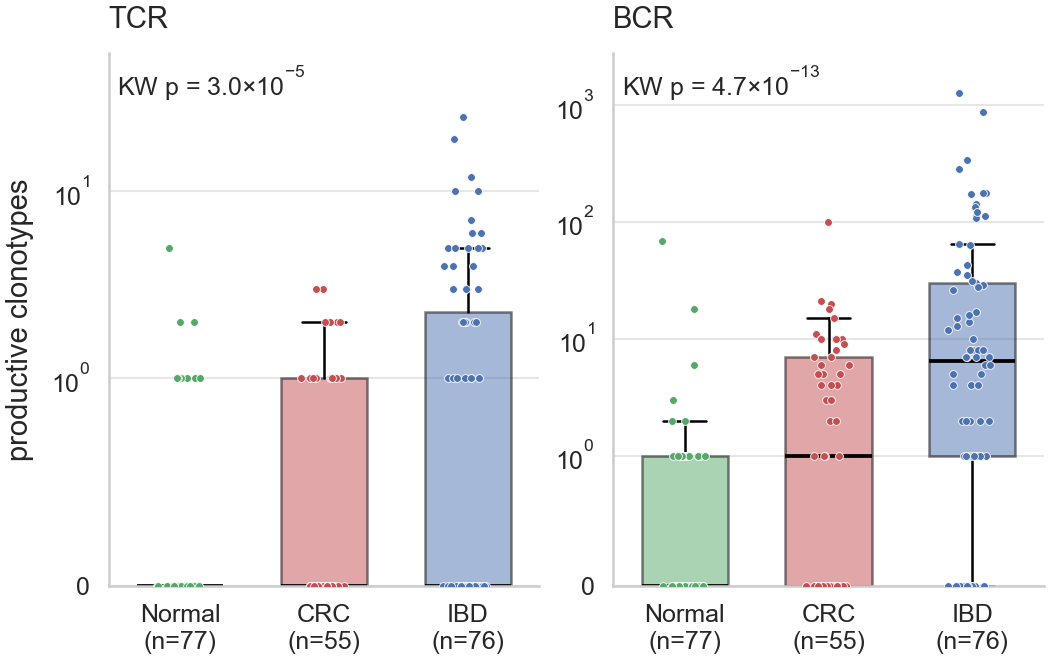

In [16]:
# ----------------------------------------------------------------------------------------------
# [Section 3.1 -- Clonotypes by study group]  (notebook cell 25)
# imported in an earlier section: box_strip() (Section 0, cell 2); corner_text()
#     (Section 0, cell 2); kruskal_p() (Section 0, cell 2); panel()
#     (Section 0, cell 2); pstr() (Section 0, cell 2); RC
#     (Section 0, cell 2); save() (Section 0, cell 2)
# variables from an earlier section: _nf (Section 3.1, cell 24); fig8 (Section 3.1, cell 24);
#     g8_fig (Section 3.1, cell 24); PAL_FIG (Section 3.1, cell 24)
# ----------------------------------------------------------------------------------------------
# ==== manuscript panel Fig2a_receptor_load ====================================================
# a: productive TCR and BCR clonotypes by study group (`fig8`, cell 24).
#
# Repertoire size, not the depth-normalised load this panel drew until 2026-10-05: the
# question here is how many distinct receptors a library yields. The three groups are not
# sequenced alike -- median CDS-exon tags are 1.07 M in Normal, 2.12 M in CRC and 2.92 M in
# IBD (Kruskal-Wallis p = 1.6e-6), and clonotype count tracks log10 depth at rho +0.58 (TCR)
# and +0.61 (BCR) -- so part of the rise across the panel is depth rather than biology. The
# legend says so, and the Results report the same comparison with depth held fixed.
_pname = "Fig2a_receptor_load"
with mpl.rc_context(RC):
    fig, axes = panel(_pname, 1, 2, sharex=True)
    for ax, cg in zip(axes, ("TCR", "BCR")):
        col = f"n_{cg}"
        values = {g: fig8.loc[fig8["group8"] == g, col].values for g in g8_fig}
        box_strip(ax, values, g8_fig, {g: PAL_FIG[g] for g in g8_fig}, s=3.5, n_in_label=False)
        ax.set_yscale("symlog", linthresh=1)          # integer counts: linear below one clonotype
        ax.set_ylim(0, float(fig8[col].max()) * 2.2)
        ax.set_xticklabels([f"{g}\n(n={int(_nf[g])})" for g in g8_fig])
        ax.set_title(cg, loc="left", fontweight="normal")
        corner_text(ax, f"KW {pstr(kruskal_p(*[values[g] for g in g8_fig]))}", "upper left")
    axes[0].set_ylabel("productive clonotypes")
    save(fig, _pname)


### Repertoire vs endoscopic activity in IBD (UC and CD pooled)

> **Manuscript output —** Fig. 4b.

In [17]:
# ----------------------------------------------------------------------------------------------
# [Section 3.2 -- Repertoire vs endoscopic activity in IBD (UC and CD pooled)]  (notebook cell 27)
# functions from an earlier section: within_endoscopy_window() (Section 0, cell 2)
# variables from an earlier section: ana (Section 3, cell 21); clin (Section 0, cell 2), last
#     set Section 3, cell 21; ENDO_ORDER (Section 0, cell 2), last set Section 3, cell 19;
#     ENDO_RANK (Section 3, cell 19)
# ----------------------------------------------------------------------------------------------
# The graded IBD libraries whose endoscopy is within the window of the stool: the cohort the
# monitoring section calls `samples`, so that every panel plotting a grade is drawn on the same
# libraries. Until 2026-09-29 this section took every graded library with a recorded subtype
# and applied no window, which put Fig. 4b, c on a different set from Fig. 4a.
ibd = ana[(ana["study_group"] == "IBD")
          & ana["endoscopic_activity_grade"].astype("object").isin(ENDO_ORDER)
          & within_endoscopy_window(ana["sample_id"], clin)
          # a recorded subtype is required (adopted 2026-10-27): the two graded libraries
          # without one, 924 and 979, are kept in the cohort but not in Fig. 4
          & ana["ibd_subtype"].astype("object").isin(["UC", "CD"])].copy()
ibd["grade_n"] = ibd["endoscopic_activity_grade"].map(ENDO_RANK).astype(float)
# The same set under a name of its own: Section 5 rebinds `ibd` to its monitoring set (cell 58),
# and Supplementary Fig. 3 compares the two (cell 62). A tuple, because the cohort-filter sweep
# rewrites lists of library ids.
ibd_rep_ids = tuple(ibd.index)


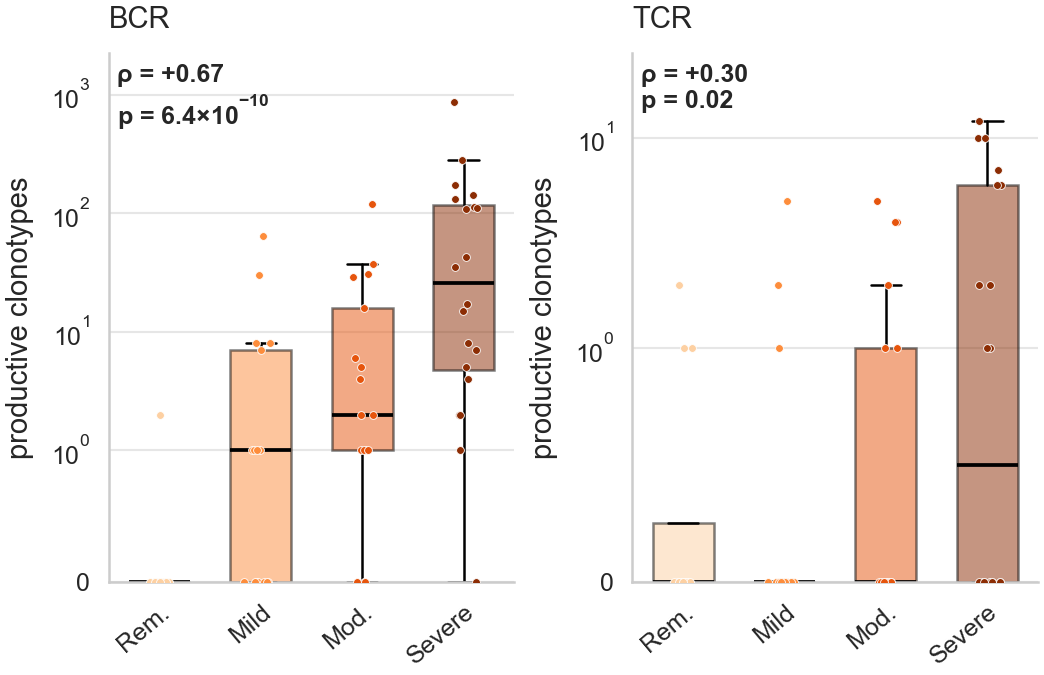

In [18]:
# ----------------------------------------------------------------------------------------------
# [Section 3.2 -- Repertoire vs endoscopic activity in IBD (UC and CD pooled)]  (notebook cell 28)
# imported in an earlier section: grade_pair() (Section 0, cell 2); RC
#     (Section 0, cell 2)
# variables from an earlier section: ENDO_ORDER (Section 0, cell 2), last set Section 3, cell
#     19; ibd (Section 3.2, cell 27)
# ----------------------------------------------------------------------------------------------
# ==== manuscript panel Fig4b_repertoire =======================================================
# b: productive BCR and TCR clonotypes against endoscopic grade (`ibd`, cell 27, both subtypes).
_pname = "Fig4b_repertoire"
with mpl.rc_context(RC):
    g = ibd["endoscopic_activity_grade"].astype(str)
    grade_pair(_pname, [(ibd["n_BCR"], g, "BCR", "symlog"), (ibd["n_TCR"], g, "TCR", "symlog")],
               ["productive clonotypes", "productive clonotypes"], ENDO_ORDER)


### Clonotypes vs matching lineage transcripts

> **Manuscript output —** Fig. 4c.

In [19]:
# ----------------------------------------------------------------------------------------------
# [Section 3.3 -- Clonotypes vs matching lineage transcripts]  (notebook cell 30)
# variables from an earlier section: ECB (Section 0, cell 2)
# ----------------------------------------------------------------------------------------------
# log2(TMM-CPM + 1) over the QC-passed libraries, from the setup cell (until 2026-10-07 this cell
# re-read and re-normalised the count file to rebuild it; until 2026-10-16 it was the cohort-wide nCPM)
logtmmcpm = ECB["logtmmcpm"]

# The B- and T-cell signature genes are the curated panels of canonical_markers.IMMUNE, the
# same source as the neutrophil score (cell 60). Adopted 2026-10-20; until then the lists were
# hand-written (B: JCHAIN, MZB1, CD79A, MS4A1, CD19; T: CD3E, TRBC2).
_CANON_IMMUNE = IMMUNE                       # the curated panels, defined in the setup cell
B_MARKERS   = list(_CANON_IMMUNE["b-cells"])
T_MARKERS   = list(_CANON_IMMUNE["t-cells"])


In [20]:
# ----------------------------------------------------------------------------------------------
# [Section 3.3 -- Clonotypes vs matching lineage transcripts]  (notebook cell 31)
# variables from an earlier section: ana (Section 3, cell 21); B_MARKERS (Section 3.3, cell 30);
#     ibd (Section 3.2, cell 27); logtmmcpm (Section 0, cell 2), last set Section 3.3, cell 30;
#     T_MARKERS (Section 3.3, cell 30)
# ----------------------------------------------------------------------------------------------
# Per-gene z on the analysis set, then the composite as the mean of those z-scores.
_b = [g for g in B_MARKERS if g in logtmmcpm.index]
_t = [g for g in T_MARKERS if g in logtmmcpm.index]
_mat = logtmmcpm.loc[_b + _t, ana.index]
_z = _mat.sub(_mat.mean(1), axis=0).div(_mat.std(1, ddof=0) + 1e-9, axis=0)

sig = ana.copy()
for g in _b + _t:
    sig[g] = _mat.loc[g]
sig["B_signature"] = _z.loc[_b].mean(0)
sig["T_signature"] = _z.loc[_t].mean(0)

# the libraries of the repertoire panels (`ibd`, cell 27) with their scores; Fig. 5c pools UC and CD
ibd_sig = sig[sig.index.isin(ibd.index)].copy()


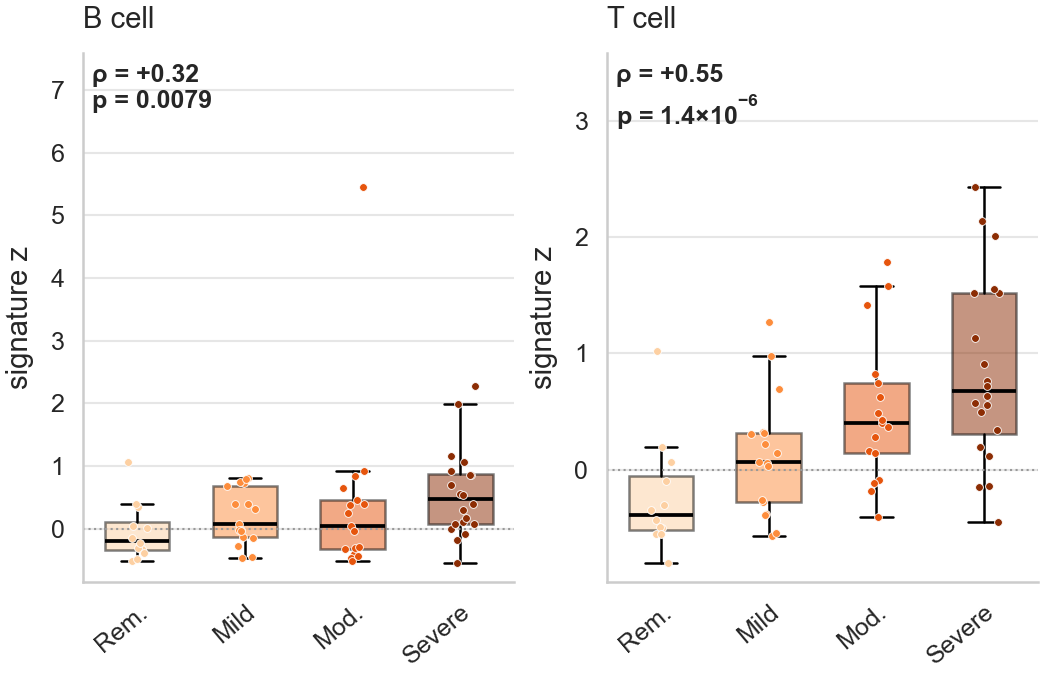

In [21]:
# ----------------------------------------------------------------------------------------------
# [Section 3.3 -- Clonotypes vs matching lineage transcripts]  (notebook cell 32)
# imported in an earlier section: grade_pair() (Section 0, cell 2); RC
#     (Section 0, cell 2)
# variables from an earlier section: ENDO_ORDER (Section 0, cell 2), last set Section 3, cell
#     19; ibd_sig (Section 3.3, cell 31)
# ----------------------------------------------------------------------------------------------
# ==== manuscript panel Fig4c_signatures =======================================================
# c: the B- and T-cell signature scores on the same libraries (`ibd_sig`, cell 31).
_pname = "Fig4c_signatures"
with mpl.rc_context(RC):
    g = ibd_sig["endoscopic_activity_grade"].astype(str)
    grade_pair(_pname, [(ibd_sig["B_signature"], g, "B cell", "zero"),
                        (ibd_sig["T_signature"], g, "T cell", "zero")],
               ["signature z", "signature z"], ENDO_ORDER)


### JCHAIN, CD3E and lineage signatures, Normal / CRC / IBD

> **Manuscript output —** Fig. 2b · Supplementary Fig. 2 · Supplementary Fig. 7.

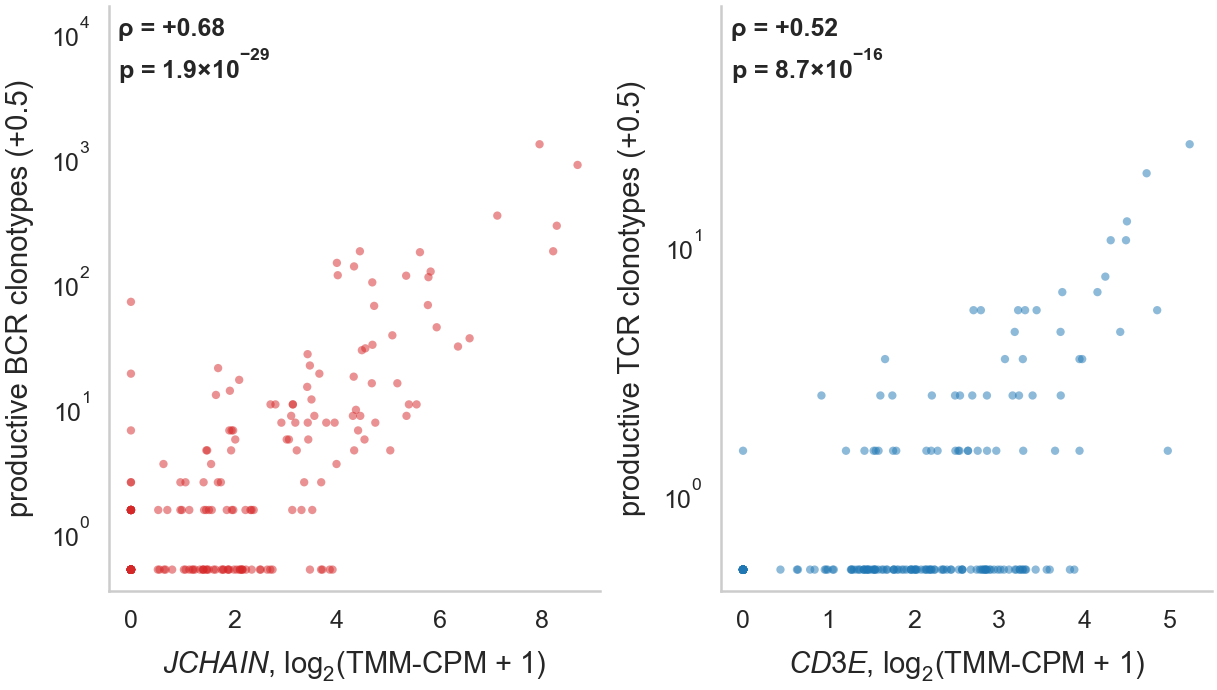

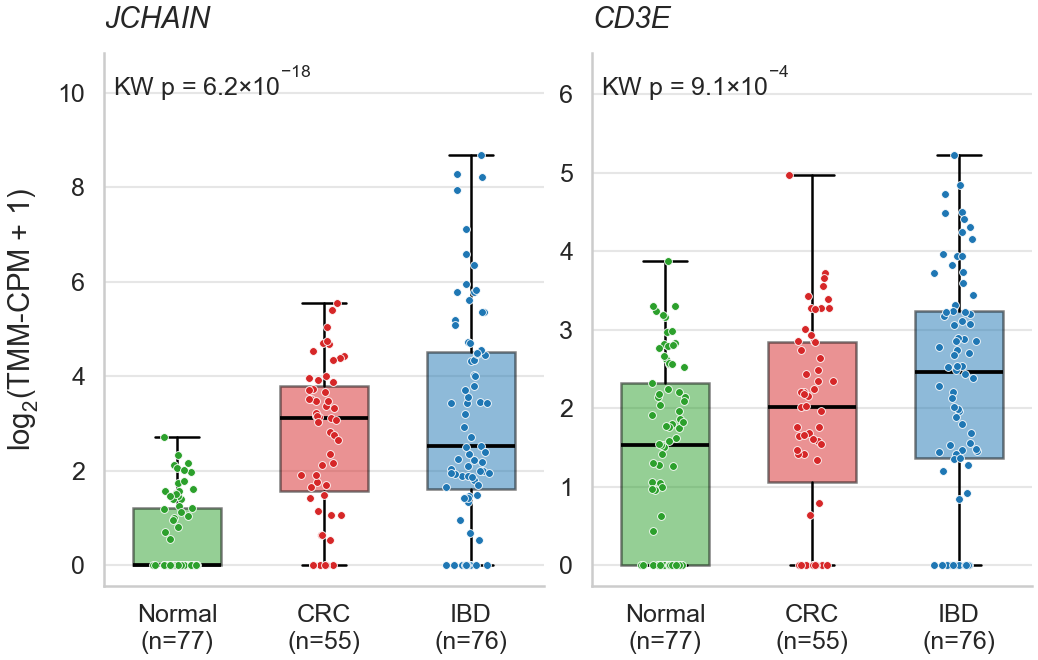

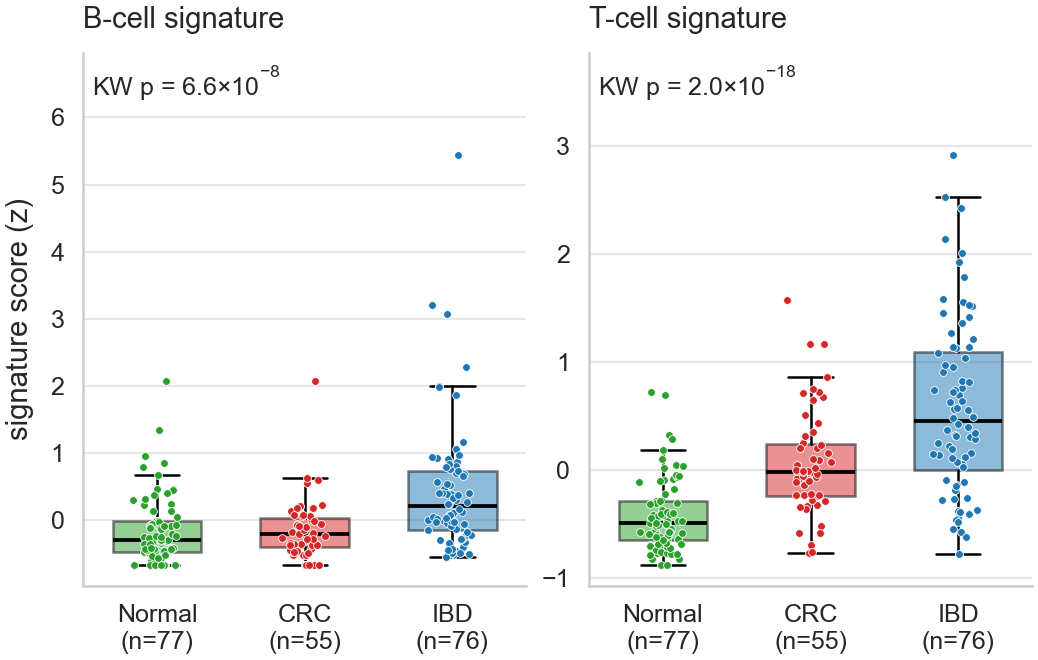

In [22]:
# ----------------------------------------------------------------------------------------------
# [Section 3.4 -- JCHAIN, CD3E and lineage signatures, Normal / CRC / IBD]  (notebook cell 34)
# imported in an earlier section: box_strip() (Section 0, cell 2); corner_text()
#     (Section 0, cell 2); headroom() (Section 0, cell 2); kruskal_p()
#     (Section 0, cell 2); MF_GROUP_ORDER (Section 0, cell 2);
#     MF_GROUP_PAL (Section 0, cell 2); panel() (Section 0, cell 2);
#     pstr() (Section 0, cell 2); RC (Section 0, cell 2); save()
#     (Section 0, cell 2); spearman() (Section 0, cell 2); tidy()
#     (Section 0, cell 2)
# variables from an earlier section: CTRL8 (Section 3.1, cell 24); ECB (Section 0, cell 2); fig8
#     (Section 3.1, cell 24); sig (Section 3.3, cell 31)
# ----------------------------------------------------------------------------------------------
# === 12b  JCHAIN, CD3E and the two signatures on Normal / CRC / IBD ===
# The same scores, restricted to the three groups the deconvolution and DE use. APL is
# omitted; NAPL is part of Normal.
N3 = ["Normal", "CRC", "IBD"]
sig3 = sig[sig["group8"].isin([CTRL8, "CRC", "IBD"])].copy()
# Exactly the libraries of the receptor-load figure (`fig8`, cell 24): Normal, CRC and the IBD
# libraries outside endoscopic remission, the IBD set of Fig. 3a -- so Fig. 2a and 2b compare
# the same libraries (author's request, 2026-09-29) and the same IBD as Fig. 3 (2026-10-31).
# From 2026-09-29 to 2026-10-31 the IBD arm was the graded, in-window, active monitoring set.
sig3 = sig3[sig3.index.isin(fig8.index)].copy()
sig3["group3"] = pd.Categorical(
    sig3["group8"].astype(str).replace({CTRL8: "Normal"}), N3, ordered=True)

# --- Fig. 2b: JCHAIN and CD3E on the setup cell's TMM-CPM ---------------------------------------
# The same matrix as the signature scores above (factors fitted once on the 285 QC-passed
# libraries). From 2026-10-07 to 2026-10-16 the factors were refitted within these 191 libraries.
_lc3 = logtmmcpm.loc[:, sig3.index]
for _g in ("JCHAIN", "CD3E"):
    sig3[f"{_g}_tmm"] = _lc3.loc[_g].reindex(sig3.index)


# ==== manuscript panel FigS2_clono_vs_expr =====================================================
# Repertoire size against the matching lineage transcript, on the same libraries and the same
# TMM-CPM as Fig. 2b (`sig3`, this cell). Until 2026-10-07 this panel was drawn on all 289
# QC-passed libraries and the cohort-wide nCPM; until 2026-10-16 on a TMM fit within the 191
# libraries the set then held.
_pname = "FigS2_clono_vs_expr"
with mpl.rc_context(RC):
    fig, axes = panel(_pname, 1, 2)
    for ax, mk, col, cg in zip(axes, ("JCHAIN", "CD3E"), ("n_BCR", "n_TCR"), ("BCR", "TCR")):
        rho, p = spearman(sig3[f"{mk}_tmm"].values, sig3[col].values)
        ax.scatter(sig3[f"{mk}_tmm"], sig3[col] + 0.5, s=4, alpha=0.5, edgecolors="none",
                   color=MF_GROUP_PAL["IBD" if cg == "TCR" else "CRC"])
        ax.set_yscale("log")
        ax.set_xlabel(f"$\\it{{{mk}}}$, log$_2$(TMM-CPM + 1)")   # the gene is italic, the unit is not
        ax.set_ylabel(f"productive {cg} clonotypes (+0.5)")
        headroom(ax, 0.25)
        corner_text(ax, f"ρ = {rho:+.2f}\n{pstr(p)}", "upper left", bold=True)
        tidy(ax, ygrid=False)
    save(fig, _pname)


# ==== manuscript panel Fig2b_lineage_markers ==================================================
# b: the transcripts those receptors come with -- JCHAIN and CD3E on the same three groups
# (`sig3`, this cell), on the setup cell's TMM-CPM.
_pname = "Fig2b_lineage_markers"
# ==== from scripts/manuscript_figures.py: used only in this cell, so it lives here (moved 2026-10-08) =====
def sig3_boxes(sig3, name, columns, titles, ylabel, italic):
    """Two columns of the notebook's `sig3` -- a gene or a signature score per library -- as
    box + points over Normal, CRC and active IBD (`sig3["group3"]`), with the Kruskal-Wallis p
    in the corner. Fig. 2b draws JCHAIN and CD3E this way, Supplementary Fig. 7 the two
    signature scores."""
    g3 = sig3["group3"].astype(str)
    fig, axes = panel(name, 1, 2)
    for ax, col, title in zip(axes, columns, titles):
        values = {g: sig3.loc[(g3 == g).values, col].values for g in MF_GROUP_ORDER}
        box_strip(ax, values, MF_GROUP_ORDER, MF_GROUP_PAL, s=3.5)
        ax.set_title(title, loc="left", fontweight="normal",
                     fontstyle="italic" if italic else "normal")
        headroom(ax)
        corner_text(ax, f"KW {pstr(kruskal_p(*[values[g] for g in MF_GROUP_ORDER]))}", "upper left")
    axes[0].set_ylabel(ylabel)
    return save(fig, name)

with mpl.rc_context(RC):
    sig3_boxes(sig3, _pname, ("JCHAIN_tmm", "CD3E_tmm"), ("JCHAIN", "CD3E"),
               "log$_2$(TMM-CPM + 1)", italic=True)

# ==== manuscript panel FigS7_lineage_signatures ===============================================
# Supplementary Fig. 7: the B-cell and T-cell signature scores on the same three groups
# as Fig. 2b (`sig3`, this cell).
_pname = "FigS7_lineage_signatures"
with mpl.rc_context(RC):
    sig3_boxes(sig3, _pname, ("B_signature", "T_signature"),
                       ("B-cell signature", "T-cell signature"), "signature score (z)",
                       italic=False)


### Antigen classes and MAIT-like TRA

> **Manuscript output —** Fig. 2c, d.


reference records per database and locus:
locus        IGH   IGK   IGL    TRA     TRB   TRD  TRG
db                                                    
CoV-AbDab  12878  7655  4439      0       0     0    0
IEDB        8168  5805  2014  70865  204869  1704  648
VDJdb          0     0     0  60836  120575     0    0
total 500,456 records, 301,266 distinct cores
TRUST4 query set: 5,409 productive clonotypes in 153 libraries, 4,545 distinct CDR3 cores



EXACT CDR3 MATCHES AGAINST ANTIGEN-ANNOTATED RECORDS
       queried  matched   pct
chain                        
IGH       1015        0   0.0
IGK       2062      442  21.4
IGL       1248      164  13.1
TRA         88       14  15.9
TRB        120        6   5.0
TRD          8        0   0.0
TRG          4        0   0.0

light chains match at 18% while IGH matches at 0% -- light-chain
CDR3s carry little junctional diversity and recur across antibodies of every specificity,
so they cannot support an antigen call.

annotation specificity of matched CDR3s (median distinct epitopes per CDR3):
       records  epitopes  organisms
chain                              
IGK        2.0       2.0        1.0
IGL        2.0       2.0        1.0
TRA        2.5       2.5        2.0
TRB        2.0       2.0        2.0



generation probability (OLGA) of TCR junctions, matched vs unmatched:
  TRA: matched median 3.89e-06 (n=14) vs unmatched 1.99e-08 (n=74), Mann-Whitney p=2.3e-05, 195x more generatable
  TRB: matched median 2.66e-07 (n=6) vs unmatched 2.03e-09 (n=114), Mann-Whitney p=1.2e-05, 131x more generatable

INVARIANT T-CELL CHAINS WITH KNOWN, NON-PEPTIDE LIGANDS
MAIT-like alpha chains (TRAV1-2/TRAJ33|20|12 or the TRAJ33 DSNYQLI motif): 7 of 88 TRA clonotypes (8%), in 5 libraries
iNKT-like alpha chains (TRAV10/TRAJ18): 0

       library study_group        CDR3aa        V      J  read_count
 SZNF202607054         IBD  CAVLDSNYQLIW  TRAV1-2 TRAJ33           9
 SZNF202604028         IBD CAVRDFNDYKLSF  TRAV1-2 TRAJ20           4
 SZNF202604028         IBD  CAFRDSNYQLIW TRAV38-1 TRAJ33           3
CRO02_639_P3VB         NEG  CAVMDSNYQLIW  TRAV1-2 TRAJ33           2
CRO02_658_P3VB         NEG  CAARDSNYQLIW  TRAV1-2 TRAJ33           1
 SZNF202602034         IBD  CAVIFGDYKLSF  TRAV1-2 TRAJ20           1

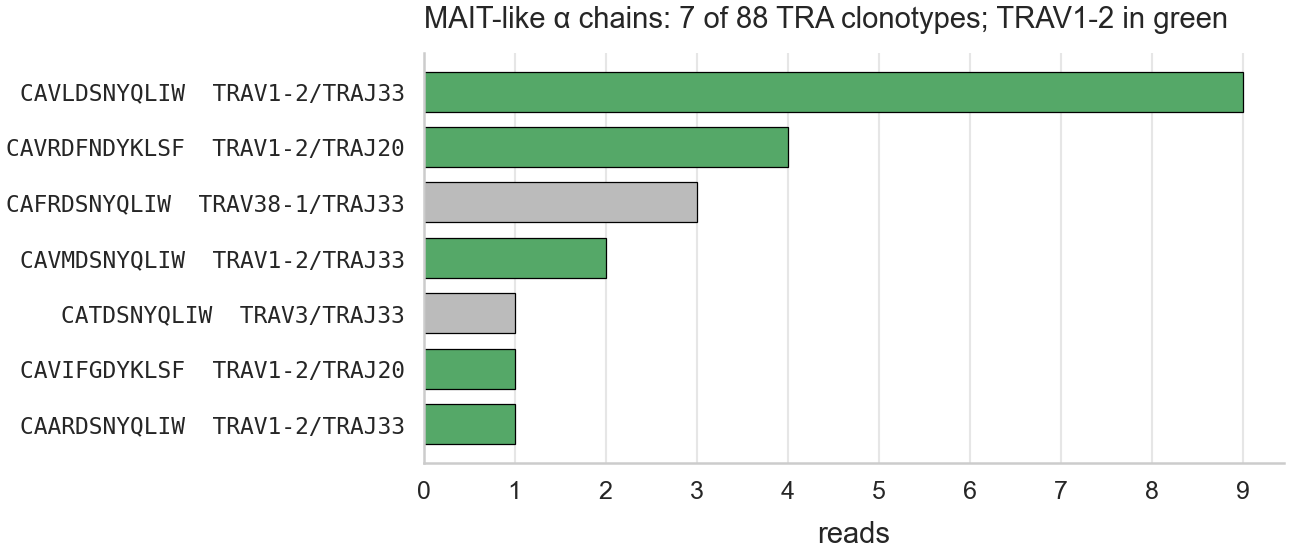

In [23]:
# ----------------------------------------------------------------------------------------------
# [Section 3.5 -- Antigen classes and MAIT-like TRA]  (notebook cell 36)
# imported in an earlier section: BASE_PT (Section 0, cell 2); panel()
#     (Section 0, cell 2); Path() (pathlib); RC (Section 0, cell 2);
#     save() (Section 0, cell 2); tidy() (Section 0, cell 2)
# variables from an earlier section: meta (Section 0, cell 2), last set Section 3, cell 21; prod
#     (Section 3, cell 21); ROOT (Section 0, cell 2)
# ----------------------------------------------------------------------------------------------

# ==== from scripts/receptor_antigen_search.py: used only in this cell, so it lives here (moved 2026-10-08) =====
#
# Match the stool TRUST4 repertoire against public receptor-antigen databases.
#
# Query set : productive CDR3 junctions assembled by TRUST4 from the ECBSeq libraries.
# References: VDJdb (TCR epitope specificity), IEDB receptor tables (TCR and BCR),
#             CoV-AbDab (SARS-CoV-2 antibodies).
#
# Conventions differ between sources -- TRUST4 and VDJdb report the IMGT junction (C...F/W),
# CoV-AbDab reports the IMGT CDR3 without those anchors, IEDB carries both -- so everything is
# reduced to a "core" (junction minus the leading C and trailing F/W) before matching, and
# matches are required to be locus-compatible.
#
# An exact CDR3 match is weak evidence by itself, so three controls are reported:
#
# 1. Generation probability (OLGA). Junctions that recombine easily turn up in every repertoire
#    and in every database, so a match tells you about the recombination machinery rather than
#    about antigen exposure.
# 2. Specificity of the matching records. A CDR3 annotated against dozens of unrelated
#    pathogens is a promiscuous or germline-like sequence, not a specificity call.
# 3. Locus asymmetry. Immunoglobulin light chains carry little junctional diversity, so their
#    CDR3s recur across antibodies of every specificity; the heavy chain is the informative one.
#
# The one antigen class that survives all three is scanned for explicitly: the semi-invariant
# MAIT (TRAV1-2/TRAJ33) and iNKT (TRAV10/TRAJ18) alpha chains, whose ligands are known.

DB = ROOT / "data/receptor_db"
# The release is pinned, not globbed: which CDR3s match a database record, and so Fig. 2c,
# depends on the release, and a newer one would draw a different figure without saying so.
VDJDB_RELEASE = "2026-06-03"
VDJDB = DB / f"vdjdb-{VDJDB_RELEASE}/vdjdb.slim.txt"
IEDB_TCR = DB / "tcr_full_v3.csv"
IEDB_BCR = DB / "bcr_full_v3.csv"
COVABDAB = DB / "covabdab.csv"
TCR_CHAINS = ["TRA", "TRB", "TRG", "TRD"]
BCR_CHAINS = ["IGH", "IGK", "IGL"]
# MAIT alpha chains are TRAV1-2 joined to TRAJ33, less often TRAJ20 or TRAJ12, with a CDR3
# of near-fixed length; iNKT alpha chains are TRAV10-TRAJ18. Both recognise non-peptide
# ligands (MR1-presented riboflavin metabolites, CD1d-presented lipids).
MAIT_V, MAIT_J = "TRAV1-2", ("TRAJ33", "TRAJ20", "TRAJ12")
MAIT_MOTIF = "DSNYQLI"          # TRAJ33-encoded, the canonical CAVxDSNYQLIW
INKT_V, INKT_J = "TRAV10", "TRAJ18"
# --------------------------------------------------------------------------------------
# query set
# --------------------------------------------------------------------------------------
def core(junction: pd.Series) -> pd.Series:
    """IMGT junction -> CDR3 core: drop the conserved C and the F/W anchor when present."""
    s = junction.str.upper().str.strip()
    s = s.where(~s.str.startswith("C"), s.str[1:])
    return s.where(~s.str.endswith(("F", "W")), s.str[:-1])
def prepare_queries(prod: pd.DataFrame, meta: pd.DataFrame) -> pd.DataFrame:
    """Normalise a frame of productive TRUST4 clonotypes into the query set.

    Accepts the `prod` and `meta` frames that TCR_analysis.ipynb already has in memory, so
    the notebook does not re-parse 480 report files to run this.
    """
    q = prod.copy()
    q["read_count"] = pd.to_numeric(q["read_count"], errors="coerce").fillna(0).astype(int)
    q["core"] = core(q["CDR3aa"].astype(str))
    for g in ("V", "J"):
        q[g] = q[g].astype(str).str.replace(r"\*.*", "", regex=True)
    have = [c for c in ("study_group", "qc_pass") if c in meta.columns
            and c not in q.columns]
    if have:
        q = q.join(meta[have], on="library")
    print(f"TRUST4 query set: {len(q):,} productive clonotypes in "
          f"{q['library'].nunique()} libraries, "
          f"{q['core'].nunique():,} distinct CDR3 cores")
    return q
# --------------------------------------------------------------------------------------
# reference databases
# --------------------------------------------------------------------------------------
def _locus_from_v(v: pd.Series) -> pd.Series:
    u = v.astype(str).str.upper()
    return u.str[:3].where(u.str.match(r"^(TR[ABGD]|IG[HKL])"))
def load_vdjdb() -> pd.DataFrame:
    if not VDJDB.exists():
        found = sorted(p.name for p in DB.glob("vdjdb-*") if p.is_dir())
        raise FileNotFoundError(
            f"{VDJDB} not found. The figures are drawn against VDJdb release {VDJDB_RELEASE} "
            f"(https://github.com/antigenomics/vdjdb-db/releases); unpack that release as "
            f"{VDJDB.parent}/. " + (f"Found instead: {', '.join(found)} -- another release "
                                    "changes Fig. 2c, so it is not used in its place."
                                    if found else "No vdjdb-* folder is present."))
    v = pd.read_csv(VDJDB, sep="\t", low_memory=False)
    v = v[v["species"] == "HomoSapiens"].copy()
    return pd.DataFrame({
        "db": "VDJdb", "locus": v["gene"], "core": core(v["cdr3"].astype(str)),
        "epitope": v["antigen.epitope"], "antigen": v["antigen.gene"],
        "source": v["antigen.species"], "mhc": v["mhc.a"],
        "db_v": v["v.segm"].astype(str).str.replace(r"\*.*", "", regex=True)})
def _iedb(path: Path, chains: list[str]) -> pd.DataFrame:
    d = pd.read_csv(path, header=[0, 1], low_memory=False)
    epi = {k: d[[c for c in d.columns if c[1] == k][0]]
           for k in ("Name", "Source Molecule", "Source Organism", "MHC Allele Names")
           if any(c[1] == k for c in d.columns)}
    out = []
    for blk in ("Chain 1", "Chain 2"):
        cols = {c[1]: c for c in d.columns if c[0] == blk}
        if "CDR3 Curated" not in cols:
            continue
        cdr3 = d[cols["CDR3 Curated"]].fillna(d[cols["CDR3 Calculated"]])
        vg = d[cols["Curated V Gene"]].fillna(d[cols["Calculated V Gene"]])
        out.append(pd.DataFrame({
            "db": "IEDB", "locus": _locus_from_v(vg), "core": core(cdr3.astype(str)),
            "epitope": epi.get("Name"), "antigen": epi.get("Source Molecule"),
            "source": epi.get("Source Organism"), "mhc": epi.get("MHC Allele Names"),
            "db_v": vg.astype(str).str.replace(r"\*.*", "", regex=True)}))
    r = pd.concat(out, ignore_index=True)
    return r[r["locus"].isin(chains) & r["core"].notna()]
def load_covabdab() -> pd.DataFrame:
    d = pd.read_csv(COVABDAB, low_memory=False)
    out = []
    for cdr3_col, v_col in [("CDRH3", "Heavy V Gene"), ("CDRL3", "Light V Gene")]:
        s = d[cdr3_col].dropna().astype(str).str.upper()
        out.append(pd.DataFrame({
            "db": "CoV-AbDab", "locus": _locus_from_v(d.loc[s.index, v_col]),
            "core": core(s), "epitope": d.loc[s.index, "Protein + Epitope"],
            "antigen": d.loc[s.index, "Binds to"], "source": "SARS-CoV-2/sarbecovirus",
            "mhc": pd.NA,
            "db_v": d.loc[s.index, v_col].astype(str).str.split("-|\\*").str[:2].str.join("-")}))
    r = pd.concat(out, ignore_index=True)
    return r[r["locus"].notna()]
def load_reference() -> pd.DataFrame:
    ref = pd.concat([load_vdjdb(), _iedb(IEDB_TCR, TCR_CHAINS), _iedb(IEDB_BCR, BCR_CHAINS),
                     load_covabdab()], ignore_index=True)
    ref = ref[ref["core"].str.fullmatch(r"[ACDEFGHIKLMNPQRSTVWY]+", na=False)]
    print("\nreference records per database and locus:")
    print(ref.groupby(["db", "locus"]).size().unstack(fill_value=0).to_string())
    print(f"total {len(ref):,} records, {ref['core'].nunique():,} distinct cores")
    return ref
# --------------------------------------------------------------------------------------
# control 1: generation probability
# --------------------------------------------------------------------------------------
def pgen_models() -> dict:
    import olga
    from olga import generation_probability as gp
    from olga import load_model

    models = {}
    base = Path(olga.__file__).parent / "default_models"
    for locus, folder, vj in [("TRA", "human_T_alpha", True), ("TRB", "human_T_beta", False)]:
        f = base / folder
        gd = load_model.GenomicDataVJ() if vj else load_model.GenomicDataVDJ()
        gd.load_igor_genomic_data(str(f / "model_params.txt"),
                                  str(f / "V_gene_CDR3_anchors.csv"),
                                  str(f / "J_gene_CDR3_anchors.csv"))
        gm = load_model.GenerativeModelVJ() if vj else load_model.GenerativeModelVDJ()
        gm.load_and_process_igor_model(str(f / "model_marginals.txt"))
        models[locus] = (gp.GenerationProbabilityVJ(gm, gd) if vj
                         else gp.GenerationProbabilityVDJ(gm, gd))
    return models
def add_pgen(q: pd.DataFrame) -> pd.DataFrame:
    models = pgen_models()
    q["pgen"] = np.nan
    for locus, model in models.items():
        m = q["chain"] == locus
        q.loc[m, "pgen"] = [model.compute_aa_CDR3_pgen("C" + c + ("W" if c.endswith("I") else "F"))
                            for c in q.loc[m, "core"]]
    return q
def annotate(prod: pd.DataFrame, ref: pd.DataFrame, with_pgen: bool = True
             ) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Collapse the query set to distinct CDR3s, match it, and run the three controls."""
    ref_pairs = {(lo, co) for lo, co in zip(ref["locus"], ref["core"])}

    q = (prod.groupby(["chain", "core"], as_index=False)
             .agg(n_libraries=("library", "nunique"), reads=("read_count", "sum"),
                  our_v=("V", lambda s: s.value_counts().index[0]),
                  our_j=("J", lambda s: s.value_counts().index[0]),
                  groups=("study_group", lambda s: ",".join(sorted(set(s.dropna())))),
                  qc_pass=("qc_pass", "any")))
    q["hit"] = [(lo, co) in ref_pairs for lo, co in zip(q["chain"], q["core"])]

    print("\n" + "=" * 86)
    print("EXACT CDR3 MATCHES AGAINST ANTIGEN-ANNOTATED RECORDS")
    print("=" * 86)
    tab = (q.groupby("chain")
             .agg(queried=("core", "size"), matched=("hit", "sum"))
             .assign(pct=lambda d: (100 * d["matched"] / d["queried"]).round(1)))
    print(tab.to_string())

    # control 3: the light chains match freely, the heavy chain does not
    lc = tab.reindex(["IGK", "IGL"]).fillna(0)
    print(f"\nlight chains match at {100 * lc['matched'].sum() / lc['queried'].sum():.0f}% "
          f"while IGH matches at {tab.loc['IGH', 'pct'] if 'IGH' in tab.index else 0:.0f}% -- "
          "light-chain\nCDR3s carry little junctional diversity and recur across antibodies "
          "of every specificity,\nso they cannot support an antigen call.")

    hits = q[q["hit"]].merge(ref, left_on=["chain", "core"], right_on=["locus", "core"],
                             how="left")
    # control 2: how specific is the annotation attached to each matched CDR3?
    spec = (hits.groupby(["chain", "core"])
                .agg(records=("db", "size"), epitopes=("epitope", "nunique"),
                     organisms=("source", "nunique")).reset_index())
    q = q.merge(spec, on=["chain", "core"], how="left")
    print("\nannotation specificity of matched CDR3s (median distinct epitopes per CDR3):")
    print(spec.groupby("chain")[["records", "epitopes", "organisms"]].median().to_string())

    # control 1: generation probability
    if with_pgen:
        q = add_pgen(q)
        print("\ngeneration probability (OLGA) of TCR junctions, matched vs unmatched:")
        for lo in ("TRA", "TRB"):
            m = (q["chain"] == lo) & q["pgen"].notna()
            a, b = q.loc[m & q["hit"], "pgen"], q.loc[m & ~q["hit"], "pgen"]
            if len(a) and len(b):
                from scipy.stats import mannwhitneyu
                p = mannwhitneyu(a, b).pvalue
                print(f"  {lo}: matched median {a.median():.2e} (n={len(a)}) vs "
                      f"unmatched {b.median():.2e} (n={len(b)}), Mann-Whitney p={p:.2g}, "
                      f"{a.median() / max(b.median(), 1e-30):.0f}x more generatable")
    return q, spec, hits
def invariant_chains(prod: pd.DataFrame, hits: pd.DataFrame
                     ) -> tuple[pd.DataFrame, pd.DataFrame]:
    """The one interpretable specificity class: non-peptide-restricted invariant T cells."""
    print("\n" + "=" * 86)
    print("INVARIANT T-CELL CHAINS WITH KNOWN, NON-PEPTIDE LIGANDS")
    print("=" * 86)
    tra = prod[prod["chain"] == "TRA"]
    mait = tra[((tra["V"] == MAIT_V) & tra["J"].isin(MAIT_J))
               | tra["core"].str.contains(MAIT_MOTIF, na=False)]
    inkt = tra[(tra["V"] == INKT_V) & (tra["J"] == INKT_J)]
    print(f"MAIT-like alpha chains (TRAV1-2/TRAJ33|20|12 or the TRAJ33 {MAIT_MOTIF} motif): "
          f"{len(mait)} of {len(tra)} TRA clonotypes ({100 * len(mait) / len(tra):.0f}%), "
          f"in {mait['library'].nunique()} libraries")
    print(f"iNKT-like alpha chains (TRAV10/TRAJ18): {len(inkt)}")
    cols = ["library", "study_group", "CDR3aa", "V", "J", "read_count"]
    print("\n" + mait[cols].sort_values("read_count", ascending=False).to_string(index=False))
    from statsmodels.stats.proportion import proportion_confint
    k, n = int((tra["V"] == MAIT_V).sum()), len(tra)
    lo, hi = proportion_confint(k, n, method="wilson")
    print(f"\nTRAV1-2 usage among TRA clonotypes: {100 * k / n:.1f}% ({k}/{n}, "
          f"95% CI {100 * lo:.1f}-{100 * hi:.1f}%); TRAJ33 usage: "
          f"{100 * (tra['J'] == 'TRAJ33').mean():.1f}%. Blood repertoires run at a few per "
          f"cent,\nso with this many clonotypes the interval is consistent with both a "
          "mucosal excess and none.")

    mait_db = hits[hits["core"].str.contains(MAIT_MOTIF, na=False)]
    if len(mait_db):
        print("\nligands annotated to the matched MAIT junctions in VDJdb/IEDB:")
        print(mait_db["epitope"].value_counts().head(6).to_string())
    return mait, tra

# `prod` and `meta` are already in memory from Section 3 above, so this re-uses them instead
# of re-parsing the TRUST4 reports.
_ref = load_reference()
_q = prepare_queries(prod, meta)
_qa, _spec, _hits = annotate(_q, _ref)
_mait, _tra = invariant_chains(_q, _hits)


# ==== manuscript panel Fig2d_mait =============================================================
# d: the MAIT-like invariant alpha chains among those TRA clonotypes (`_mait`, this cell).
_pname = "Fig2d_mait"
with mpl.rc_context(RC):
    m = _mait.sort_values("read_count")
    fig, ax = panel(_pname)
    y = np.arange(len(m))
    ax.barh(y, m["read_count"], height=0.72, edgecolor="black", lw=0.3,
            color=["#55a868" if v == MAIT_V else "#bbbbbb" for v in m["V"]])
    ax.set_yticks(y)
    # the only non-Arial run in the paper, and a deliberate one: the CDR3s are set monospaced
    # so the sequences and their V/J calls line up column-wise, as sequence figures conventionally do
    ax.set_yticklabels([f"{c}  {v}/{j}" for c, v, j in zip(m["CDR3aa"], m["V"], m["J"])],
                       family="monospace", fontsize=BASE_PT - 1.5)
    ax.set_xlabel("reads")
    ax.set_xticks(range(0, int(m["read_count"].max()) + 1))
    ax.set_title(f"MAIT-like α chains: {len(m)} of {len(_tra)} TRA clonotypes; "
                 f"{MAIT_V} in green", loc="left", fontweight="normal")
    tidy(ax, ygrid=False)
    ax.grid(axis="x", color="0.9", lw=0.5)
    save(fig, _pname)


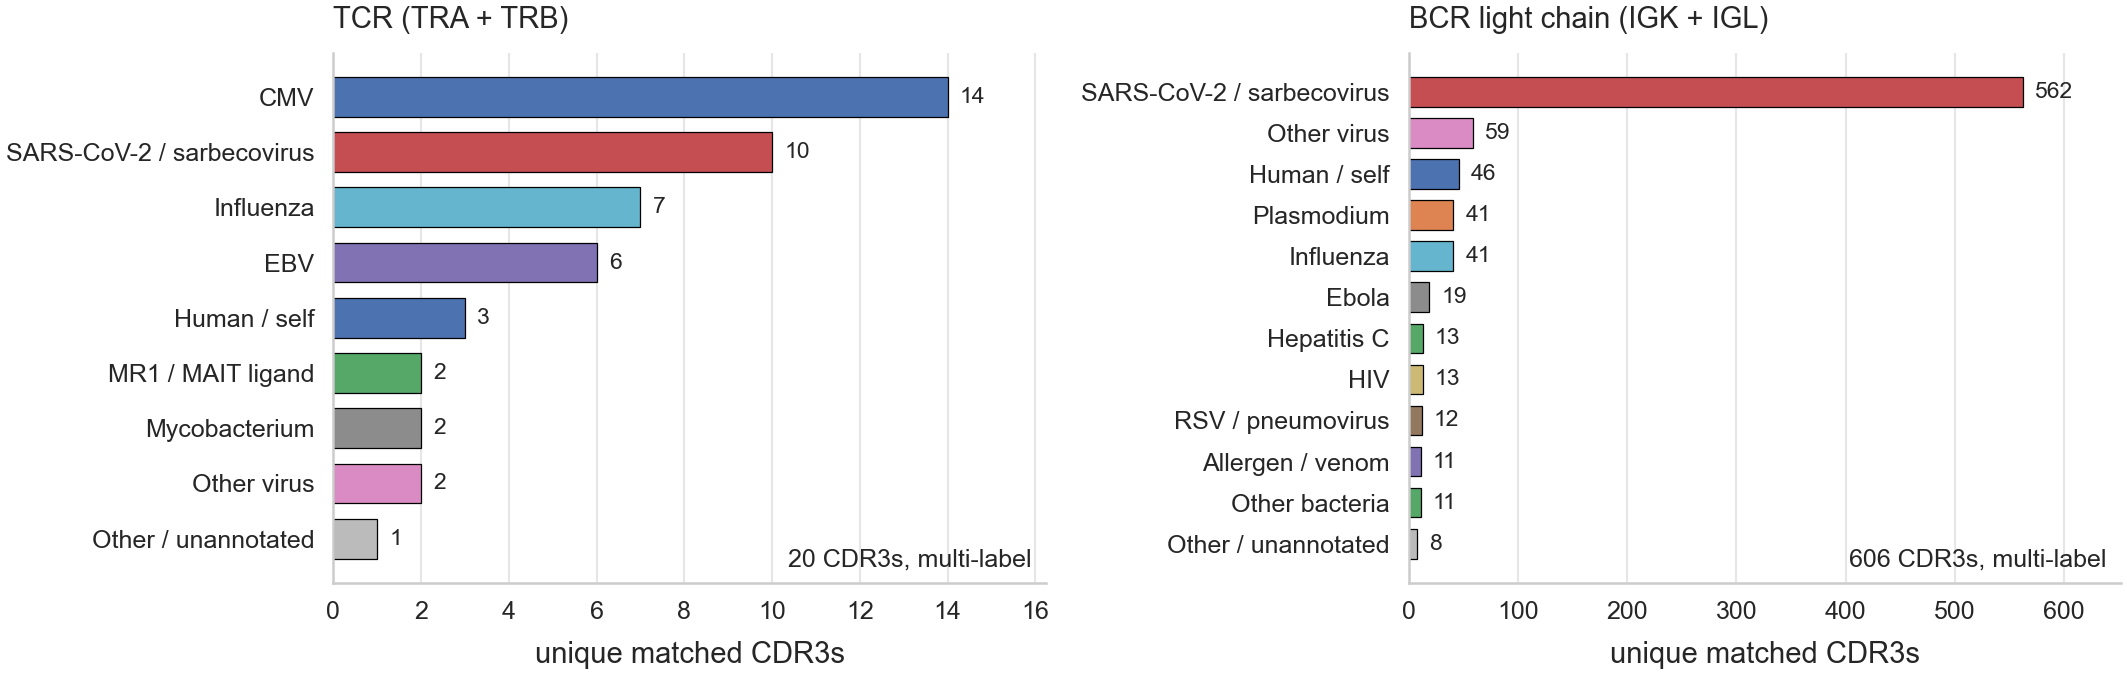

In [24]:
# ----------------------------------------------------------------------------------------------
# [Section 3.5 -- Antigen classes and MAIT-like TRA]  (notebook cell 37)
# imported in an earlier section: BASE_PT (Section 0, cell 2); corner_text()
#     (Section 0, cell 2); panel() (Section 0, cell 2); RC
#     (Section 0, cell 2); save() (Section 0, cell 2); tidy()
#     (Section 0, cell 2)
# variables from an earlier section: _hits (Section 3.5, cell 36)
# ----------------------------------------------------------------------------------------------
import re

# `_hits` is one row per (CDR3, database record). Count unique CDR3s, not records.
CLASS_RULES = [
    ("SARS-CoV-2 / sarbecovirus", r"sars|sarbeco|coronavirus 2|\bmers\b|betacoronavirus"),
    ("CMV", r"\bcmv\b|cytomegalovirus|herpesvirus 5|betaherpesvirus 5"),
    ("EBV", r"\bebv\b|epstein|herpesvirus 4"),
    ("Influenza", r"influenza|h7n9"),
    ("HIV", r"\bhiv\b|immunodeficiency"),
    ("Hepatitis C", r"hepatitis c|\bhcv\b"),
    ("Ebola", r"ebola|bundibugyo"),
    ("RSV / pneumovirus", r"respiratory syncytial|metapneumovirus"),
    ("Other virus", r"zikv|zika|virus|vaccinia|orthopox|arenavirus|"
                    r"choriomeningitidis|adeno-associated|enterovirus|rift valley"),
    ("Mycobacterium", r"mycobacterium|m\.tuberculosis|tuberculosis"),
    ("Other bacteria", r"salmonella|borreli|streptococcus|enterica|"
                       r"staphylococcus|pseudomonas|neisseria"),
    ("Plasmodium", r"plasmodium|falciparum"),
    ("Allergen / venom", r"betula|phleum|naja|pendula|pratense|arachis|"
                         r"triticum|ophiophagus|echis|peanut"),
    ("Human / self", r"homo sapiens|homosapiens"),
]
CLASS_ORDER = [name for name, _ in CLASS_RULES] + ["MR1 / MAIT ligand", "Other / unannotated"]
MR1_RE = re.compile(
    r"mr1|formylpterin|ribityl|ribitylamino|oxopropylideneamino|"
    r"oxoethylideneamino|5-op-ru",
    re.I,
)
CLASS_PALETTE = {
    "SARS-CoV-2 / sarbecovirus": "#c44e52",
    "CMV": "#4c72b0",
    "EBV": "#8172b3",
    "Influenza": "#64b5cd",
    "HIV": "#ccb974",
    "Hepatitis C": "#55a868",
    "Ebola": "#8c8c8c",
    "RSV / pneumovirus": "#937860",
    "Other virus": "#da8bc3",
    "Mycobacterium": "#8c8c8c",
    "Other bacteria": "#55a868",
    "Plasmodium": "#dd8452",
    "Allergen / venom": "#8172b3",
    "Human / self": "#4c72b0",
    "MR1 / MAIT ligand": "#55a868",
    "Other / unannotated": "#bbbbbb",
}


def _organism_class(source):
    if pd.isna(source) or not str(source).strip():
        return None
    text = str(source).lower()
    for name, pat in CLASS_RULES:
        if re.search(pat, text):
            return name
    return "Other / unannotated"


def _label_hits(hits):
    rec = hits.copy()
    rec["org_class"] = rec["source"].map(_organism_class)
    rec["is_mr1"] = (
        rec["epitope"].fillna("").astype(str).str.contains(MR1_RE)
        | rec["mhc"].fillna("").astype(str).str.contains(MR1_RE)
        | rec["antigen"].fillna("").astype(str).str.contains(MR1_RE)
    )
    org = rec.dropna(subset=["org_class"])[["chain", "core", "org_class"]].drop_duplicates()
    parts = [org.rename(columns={"org_class": "antigen_class"})]
    mr1 = rec.loc[rec["is_mr1"], ["chain", "core"]].drop_duplicates()
    if len(mr1):
        mr1 = mr1.copy()
        mr1["antigen_class"] = "MR1 / MAIT ligand"
        parts.append(mr1)
    labelled = set(zip(org["chain"], org["core"]))
    if len(mr1):
        labelled |= set(zip(mr1["chain"], mr1["core"]))
    orphan = rec[["chain", "core"]].drop_duplicates()
    orphan = orphan[[(c, k) not in labelled for c, k in zip(orphan["chain"], orphan["core"])]]
    if len(orphan):
        orphan = orphan.copy()
        orphan["antigen_class"] = "Other / unannotated"
        parts.append(orphan)
    lab = pd.concat(parts, ignore_index=True).drop_duplicates()
    lab["receptor"] = np.where(lab["chain"].isin(["TRA", "TRB", "TRG", "TRD"]), "TCR", "BCR")
    return rec, lab


_, _lab = _label_hits(_hits)

_n_tcr = _hits[_hits["chain"].isin(["TRA", "TRB"])].groupby(["chain", "core"]).ngroups
_n_bcr = _hits[_hits["chain"].isin(["IGK", "IGL"])].groupby(["chain", "core"]).ngroups

# ==== manuscript panel Fig2c_antigen_classes ==================================================
# c: antigen classes on exact CDR3 database matches (`_lab`, this cell).
_pname = "Fig2c_antigen_classes"
top = 12
with mpl.rc_context(RC):
    lab, order, pal = _lab, CLASS_ORDER, CLASS_PALETTE
    fig, axes = panel(_pname, 1, 2)
    for ax, receptor, n_tot, title in ((axes[0], "TCR", _n_tcr, "TCR (TRA + TRB)"),
                                       (axes[1], "BCR", _n_bcr, "BCR light chain (IGK + IGL)")):  # noqa: E501
        sub = lab[lab["receptor"] == receptor]
        d = (sub.groupby("antigen_class")["core"].nunique()
             .reindex([c for c in order if c in set(sub["antigen_class"])]).dropna())
        d = d[d > 0].sort_values(ascending=True).tail(top)
        y = np.arange(len(d))
        ax.barh(y, d.values, height=0.72, color=[pal.get(k, "#bbbbbb") for k in d.index],
                edgecolor="black", lw=0.3)
        for yy, v in zip(y, d.values):
            ax.text(v + max(d.values) * 0.02, yy, f"{int(v)}", va="center",
                    fontsize=BASE_PT - 1.5)
        ax.set_yticks(y)
        ax.set_yticklabels(d.index)
        ax.set_xlim(0, max(d.values) * 1.16)
        ax.set_xlabel("unique matched CDR3s")
        ax.set_title(title, loc="left", fontweight="normal")
        corner_text(ax, f"{int(n_tot)} CDR3s, multi-label", "lower right")
        tidy(ax, ygrid=False)
        ax.grid(axis="x", color="0.9", lw=0.5)
    save(fig, _pname)


---
# Separating CRC from IBD

`IBD_CRC_DE.ipynb`. Expression and metadata come from the shared `D` already in memory. DE uses pydeseq2 on raw counts. The Enrichr results behind Fig. 3d are read from the cache under `results/pc_pole_enrichment/` and queried live only on a miss.

> **Manuscript output —** Fig. 3a–i · Supplementary Figs 8, 9.

In [25]:
# ----------------------------------------------------------------------------------------------
# [Section 4 -- Separating CRC from IBD]  (notebook cell 39)
# functions from an earlier section: disease_model_view() (Section 0, cell 2); remission_ids()
#     (Section 0, cell 2)
# variables from an earlier section: ECB (Section 0, cell 2)
# ----------------------------------------------------------------------------------------------
# === §1  QC-filtered ECBSeq stool RNA-seq via data_preprocessing() ===
# restore the expression dict; §1.A rebound D to a distance matrix
D = ECB                      # the whole data_preprocessing() bundle, as cell 2 left it in `ECB`
RES = D["RES"]               # results directory this notebook may write to (a Path)
# meta_f   one row per QC-passed library: study group, clinical fields, QC and library-prep columns
# logtmmcpm_f log2(TMM-CPM + 1), genes x those same libraries (columns follow meta_f's index) --
#          the scale both PCAs and the classifiers in this section are fitted on
meta_f, logtmmcpm_f = D["meta_f"], D["logtmmcpm"]

# === The disease-model view (defined in Section 0 of this notebook) ============================
# Two rules, defined once there so this notebook and the paper cannot disagree:
#   * Normal = NORMAL_GROUPS (healthy volunteers + NEG + NAPL), relabelled `Normal` so that the
#     word means the same here as in every other section (until 2026-10-07 this section called
#     the pooled arm `Healthy`, the name of the notebook it was copied from); the original label
#     is kept in `study_group_original`;
#   * IBD libraries in endoscopic remission are set aside from everything fitted in this section:
#     the all-library and CRC + IBD PCAs, the DESeq2 contrast, the programme scores and the
#     classifiers (Figs. 3 and 4). They stay in the composition, repertoire and activity-grading
#     sections, which rebuild their own views from D / ECB (untouched here).
# NORMAL_GROUPS, remission_ids and disease_model_view all come from Section 0 (cell 2)
# _DM_REMOVED  ids of the IBD libraries in endoscopic remission, kept only so the line below can
#              report how many were set aside; nothing downstream selects on it
_DM_REMOVED = tuple(remission_ids(meta_f))      # a tuple: the cohort-filter sweep rewrites lists
# meta_f is rebound here, not filtered in place: remission rows dropped and every Normal group
# relabelled `Normal`. The pre-relabel name survives in meta_f["study_group_original"].
meta_f = disease_model_view(meta_f)
# the matrix is re-indexed to follow it, so genes x libraries stays aligned with meta_f's rows
logtmmcpm_f = logtmmcpm_f[meta_f.index]

# --- raw counts for DESeq2, QC-passed libraries only ------------------------------------------
# The matrix carries no MT- genes, but MT pseudogenes (MTCO1P12, ...) and MT-RNR2-like genes
# (MTRNR2L8, ...) are still in it and would distort library-size normalisation. Drop them once
# here rather than inside each analysis, so every cell below sees the same gene set.
_idx = D["counts"].index.astype(str).str.upper()    # gene symbols, upper-cased for one regex
_real_mt = _idx.str.match(r"^MT-")                  # true mitochondrial genes (expected to be none)
_pseudo = _idx.str.match(r"^MT[A-Z0-9]+P\d+$")      # MT pseudogenes, e.g. MTCO1P12
_mt_like = _idx.str.match(r"^MT[A-Z0-9]+L\d+$")     # MT-RNR2-like nuclear genes, e.g. MTRNR2L8
_drop = _real_mt | _pseudo | _mt_like               # the three masks as one: every gene excluded
counts_all = D["counts"].loc[~_drop, meta_f.index]  # raw integer counts, genes x section libraries;
                                                    # DESeq2 needs counts, not CPM, so this is the
                                                    # matrix the volcano cell fits on
counts_all.columns.name = None       # so `.T.reset_index()` yields a plain "index" column


# --- disease groups as library lists ----------------------------------------------------------
GROUP_ORDER = ["Normal", "APL", "CRC", "IBD"]                   # the order every table and legend
                                           # shared by every inline figure below

group = meta_f["study_group"].astype("object").fillna("unannotated")   # per-library label, no NaN:
                                                       # object dtype so the fill cannot fail on a
                                                       # categorical that lacks the new level
libs = {g: meta_f.index[group == g].tolist() for g in GROUP_ORDER}   # study group -> library ids
ibd_samples, crc_samples = libs["IBD"], libs["CRC"]    # the two arms of the DESeq2 contrast


### The all-library PCA: PC1 × the disease components

> **Manuscript output —** Fig. 3a–c.

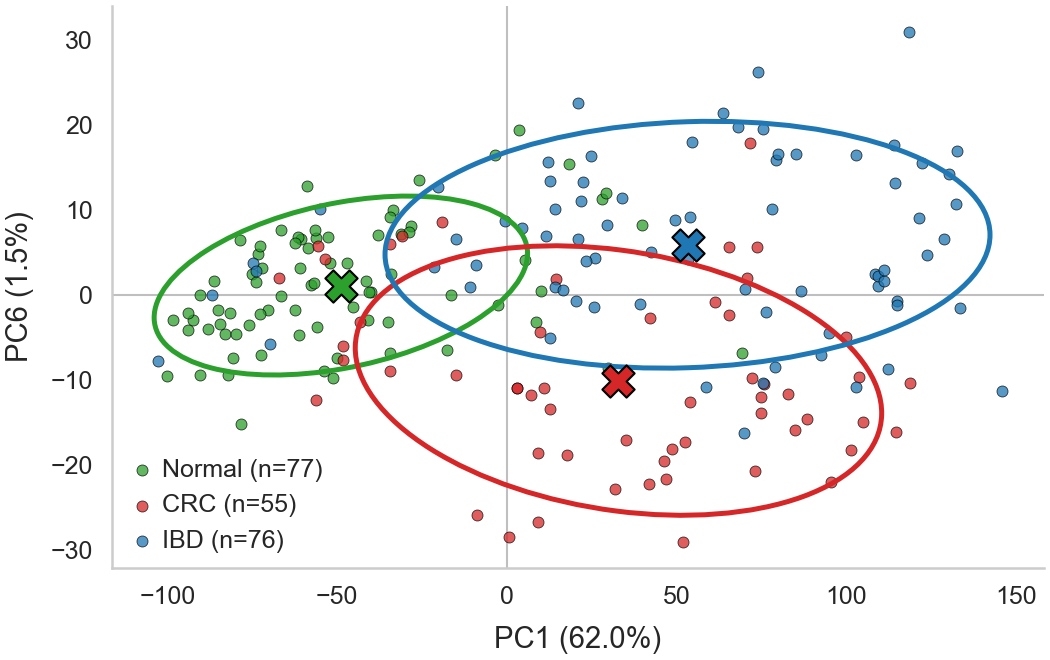

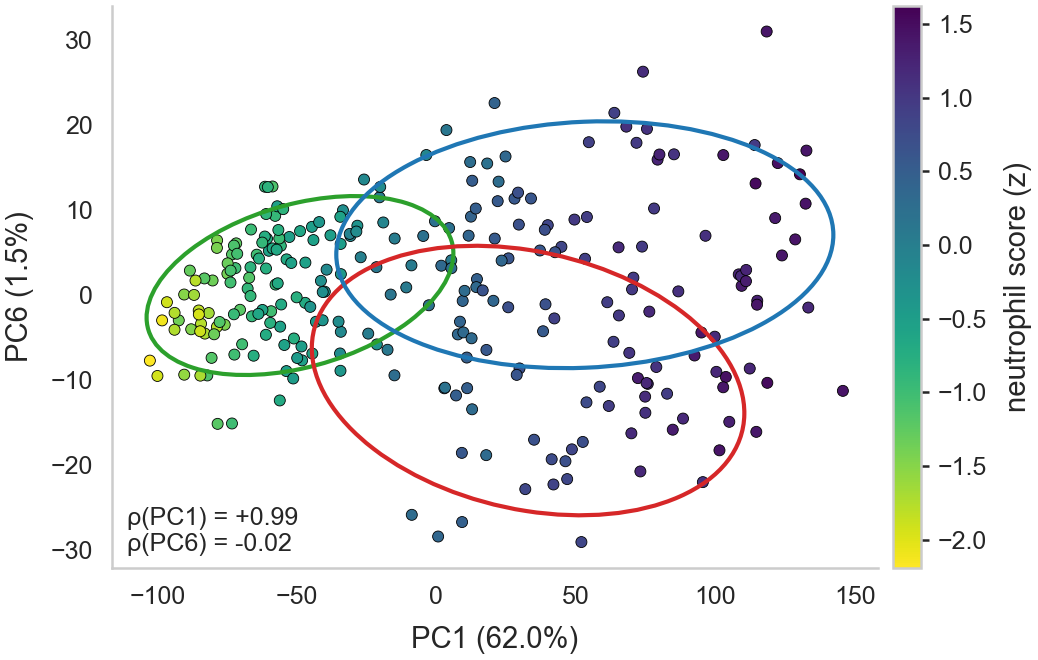

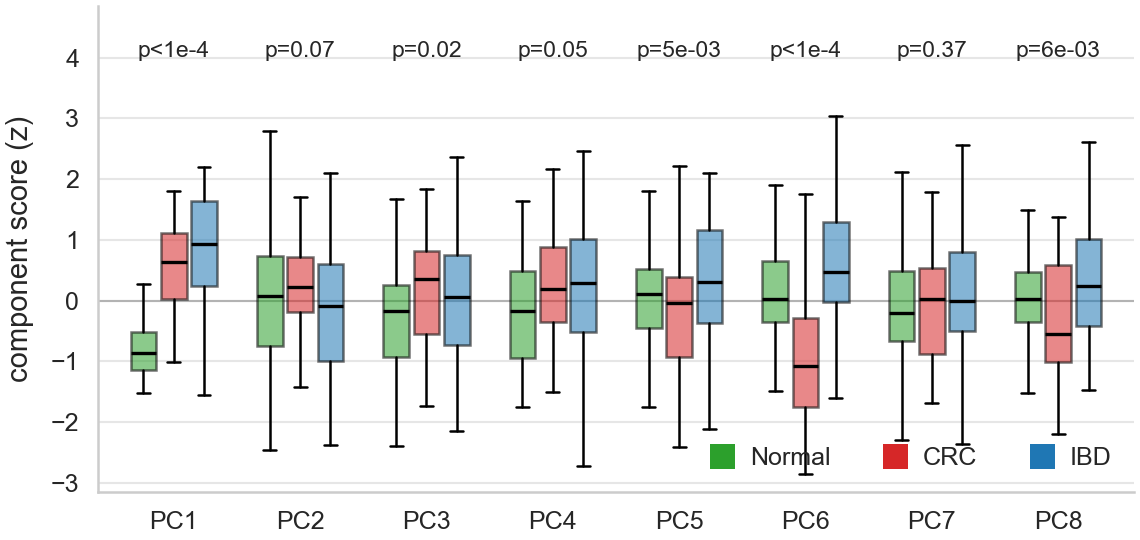

In [26]:
# ----------------------------------------------------------------------------------------------
# [Section 4.1 -- The all-library PCA: PC1 × the disease components]  (notebook cell 41)
# imported in an earlier section: BASE_PT (Section 0, cell 2); corner_text()
#     (Section 0, cell 2); kruskal_p() (Section 0, cell 2); Line2D()
#     (matplotlib.lines); MF_GROUP_PAL (Section 0, cell 2); panel()
#     (Section 0, cell 2); RC (Section 0, cell 2); save()
#     (Section 0, cell 2); spearman() (Section 0, cell 2); tidy()
#     (Section 0, cell 2)
# variables from an earlier section: group (Section 4, cell 39); IMM_SCORES (Section 2.3, cell
#     17); logtmmcpm_f (Section 0, cell 2), last set Section 4, cell 39
# ----------------------------------------------------------------------------------------------
# === §3a  The all-library PCA: every QC-passed library outside endoscopic remission ===
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

NTOP = 2000          # the most variable genes the decomposition is fitted on
NPC_ALL = 8          # components kept
PCA_VIEW = "2d"      # Fig. 3a, b: "3d" = PC1 x the two components that best separate CRC from IBD;
                     # "2d" = PC1 x the best one, with group means and 68% contours. Fig. 3d
                     # enriches the poles of whichever components are drawn (`PC3D`).
assert PCA_VIEW in ("2d", "3d"), PCA_VIEW

_A = logtmmcpm_f.loc[logtmmcpm_f.var(axis=1).nlargest(NTOP).index]
_A = _A.sub(_A.mean(axis=1), axis=0)
_Ua, _Sa, _Vta = np.linalg.svd(_A.values, full_matrices=False)
ve_all = _Sa ** 2 / np.sum(_Sa ** 2)
pcs_all = pd.DataFrame(_Vta[:NPC_ALL].T * _Sa[:NPC_ALL], index=logtmmcpm_f.columns,
                       columns=[f"PC{_i + 1}" for _i in range(NPC_ALL)])
load_all = pd.DataFrame(_Ua[:, :NPC_ALL], index=_A.index, columns=pcs_all.columns)

# PC1's sign is fixed by the stool neutrophil score (Section 2.3); a missing score is an error
# here, not a reason to fall back on another quantity
_neut_all = IMM_SCORES.reindex(pcs_all.index)["Neutrophils"]
_ref_all = "neutrophil score"
for _c in pcs_all.columns:                  # SVD sign is arbitrary; fix it the §3b.2 way
    _flip = (spearmanr(pcs_all[_c], _neut_all, nan_policy="omit")[0] < 0 if _c == "PC1"
             else load_all[_c].loc[load_all[_c].abs().idxmax()] < 0)
    if _flip:
        pcs_all[_c] *= -1
        load_all[_c] *= -1

_grp_all = group.reindex(pcs_all.index).astype(str)

# --- which component separates which pair of diagnoses? ------------------------------------------
CONTRASTS = [("CRC", "Normal"), ("IBD", "Normal"), ("CRC", "IBD"), ("APL", "Normal")]
_auc = pd.DataFrame(index=[f"{_a} vs {_b}" for _a, _b in CONTRASTS], columns=pcs_all.columns,
                    dtype=float)
for _a, _b in CONTRASTS:
    _ma, _mb = (_grp_all == _a).values, (_grp_all == _b).values
    for _c in pcs_all.columns:
        _x, _y = pcs_all[_c][_ma], pcs_all[_c][_mb]
        _raw = roc_auc_score(np.r_[np.ones(len(_x)), np.zeros(len(_y))], np.r_[_x, _y])
        _auc.loc[f"{_a} vs {_b}", _c] = max(_raw, 1 - _raw)

# The disease component is chosen from the data, not assumed: whichever component other than
# PC1 best separates CRC from IBD. It is PC6 on this cohort (PC7 until the normalisation was
# unified on 2026-10-16). Fig. 3a, b show it with PC1 and with the component that separates CRC
# from IBD next best: on TMM-CPM the contrast is not confined to one component (PC6 0.83, PC7
# 0.71, PC5 0.70 by single-component AUC), so the "3d" view shows the two that carry most of it
# and the "2d" view the first alone (`PCA_VIEW`).
_dis_pc = _auc.loc["CRC vs IBD"].drop("PC1").astype(float).idxmax()
_dis_pc2 = _auc.loc["CRC vs IBD"].drop(["PC1", _dis_pc]).astype(float).idxmax()
# the axes of Fig. 3a, b and the poles of Fig. 3d: three in the "3d" view, two in the "2d" view
PC3D = ["PC1", _dis_pc, _dis_pc2] if PCA_VIEW == "3d" else ["PC1", _dis_pc]

# PC1 answers "diseased or not" and carries no information about which disease; the disease
# component answers "which disease" and barely distinguishes disease from health. Crossing them is
# the one plane in this decomposition where the three-way question can be read directly (Fig. 3a).

def pshort(p) -> str:
    """Compact p-value for crowded component annotations (matches IBD_CRC_DE)."""
    if p is None or not np.isfinite(p):
        return ""
    if p < 1e-4:
        return "p<1e-4"
    if p < 0.01:
        return f"p={p:.0e}"
    return f"p={p:.2f}"


def _grouped_pc_boxes(ax, z, labels, order, palette, *, annotate, strip=False):
    """Grouped boxes of z-scored component scores. `annotate(i, col)` returns the label."""
    n_pc, n_g = z.shape[1], len(order)
    width = 0.72 / n_g
    rng = np.random.default_rng(0)
    ymax = float(np.nanmax(z.values))
    for j, g in enumerate(order):
        m = (np.asarray(labels, dtype=str) == g)
        pos = np.arange(n_pc) + (j - (n_g - 1) / 2) * width
        data = [z.iloc[:, i].to_numpy(dtype=float)[m] for i in range(n_pc)]
        data = [d[np.isfinite(d)] for d in data]
        bp = ax.boxplot(data, positions=pos, widths=width * 0.85, showfliers=False,
                        patch_artist=True, medianprops=dict(color="black", lw=0.8),
                        whiskerprops=dict(lw=0.6), capprops=dict(lw=0.6),
                        boxprops=dict(lw=0.6), zorder=2)
        for patch in bp["boxes"]:
            patch.set_facecolor(palette[g])
            patch.set_alpha(0.55)
        if strip:
            for i, d in enumerate(data):
                if len(d):
                    ax.scatter(rng.normal(pos[i], 0.025, len(d)), d, s=4, color=palette[g],
                               edgecolors="white", linewidths=0.15, zorder=3, alpha=0.7)
    for i, c in enumerate(z.columns):
        ax.text(i, ymax * 1.04, annotate(i, c), ha="center", va="bottom", fontsize=BASE_PT - 1.5)
    ax.axhline(0, color="0.7", lw=0.5, zorder=1)
    ax.set_xticks(range(n_pc))
    ax.set_xticklabels(list(z.columns))
    ax.set_xlim(-0.6, n_pc - 0.4)
    ax.set_ylim(top=ymax * (1.38 if strip else 1.28))
    ax.set_ylabel("component score (z)")
    handles = [Line2D([0], [0], marker="s", color="none", markerfacecolor=palette[g],
                      markeredgecolor="none", markersize=6, label=g) for g in order]
    ax.legend(handles=handles, loc="lower right", ncol=min(len(order), 3), frameon=False)
    tidy(ax)
    return ax


# ==== manuscript panel Fig3a_pca_diagnosis ====================================================
# a: every QC-passed library on PC1 x the disease component(s) (`PC3D`, notebook §3a `pcs_all`),
# by diagnosis, the group mean as a cross. `PCA_VIEW` (top of this cell) picks the view. "3d", the
# default since 2026-10-16: on TMM-CPM the CRC-vs-IBD contrast is shared between two components,
# so both are drawn with PC1. "2d": PC1 x the best component, each group with a 68% contour (1.51
# s.d. ellipse), the design the panel had before 2026-10-16 and the one that reads at a glance.
_pname = "Fig3a_pca_diagnosis"
from matplotlib.patches import Ellipse
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3-D projection)


def _pc3d_axes(name, elev=22, azim=-55, right=1.0):
    """A three-dimensional axes on PC3D filling the panel's declared slot, journal type, panes
    off; `right` leaves room for a colour bar."""
    fig = plt.figure(figsize=size(name))
    ax = fig.add_subplot(111, projection="3d")
    ax.set_position([0.0, 0.10, right, 0.92])
    for setter, pc, pad in zip((ax.set_xlabel, ax.set_ylabel, ax.set_zlabel), PC3D, (-1, -1, -3)):
        setter(f"{pc} ({ve_all[int(pc[2:]) - 1]:.1%})", fontsize=BASE_PT - 1, labelpad=pad)
    ax.view_init(elev=elev, azim=azim)
    ax.tick_params(labelsize=BASE_PT - 2, pad=-2.5, length=1.5, width=0.4)
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.fill = False
        axis.pane.set_edgecolor("0.85")
        axis._axinfo["grid"].update(color="0.9", linewidth=0.4)
    ax.set_box_aspect((1.25, 1.0, 0.85), zoom=1.05)
    return fig, ax


def pc_axis_labels(ve, dis):
    """Axis labels for the PC1 x disease-component plane: the component and its variance share."""
    return f"PC1 ({ve[0]:.1%})", f"{dis} ({ve[int(dis[2:]) - 1]:.1%})"


def pca_clouds(ax, xy_by_group, xlabel, ylabel, palette, s=7):
    """Scatter by group with the group mean (cross) and a 68% contour (1.51 s.d. ellipse)."""
    for g, xy in xy_by_group.items():
        ax.scatter(xy[:, 0], xy[:, 1], s=s, color=palette[g], edgecolors="black", linewidths=0.2,
                   alpha=0.75, zorder=3, label=f"{g} (n={len(xy)})")
        if len(xy) >= 3:
            val, vec = np.linalg.eigh(np.cov(xy.T))
            ax.add_patch(Ellipse(xy.mean(0), *(2 * 1.51 * np.sqrt(val[::-1])),
                                 angle=np.degrees(np.arctan2(*vec[:, 1][::-1])), facecolor="none",
                                 edgecolor=palette[g], lw=1.2, zorder=4))
            ax.scatter(*xy.mean(0), s=60, marker="X", color=palette[g], edgecolor="black",
                       linewidth=0.5, zorder=5)
    ax.axhline(0, color="0.75", lw=0.5)
    ax.axvline(0, color="0.75", lw=0.5)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(loc="lower left", handletextpad=0.2, borderaxespad=0.2)
    return ax


with mpl.rc_context(RC):
    grp_all = _grp_all.astype(str)
    if PCA_VIEW == "3d":
        fig, ax = _pc3d_axes(_pname)
        for k in ("Normal", "CRC", "IBD"):
            xyz = pcs_all.loc[(grp_all == k).values, PC3D].values
            ax.scatter(xyz[:, 0], xyz[:, 1], xyz[:, 2], s=5, color=MF_GROUP_PAL[k], edgecolors="black",
                       linewidths=0.15, alpha=0.75, depthshade=False, label=f"{k} (n={len(xyz)})")
            c = xyz.mean(0)
            ax.scatter([c[0]], [c[1]], [c[2]], s=40, marker="X", color=MF_GROUP_PAL[k], edgecolor="black",
                       linewidth=0.5, depthshade=False)
        ax.legend(loc="upper left", fontsize=BASE_PT - 1, frameon=False, handletextpad=0.2,
                  borderaxespad=0.0, bbox_to_anchor=(0.0, 0.98))
    else:
        xy = {k: pcs_all.loc[(grp_all == k).values, PC3D].values for k in ("Normal", "CRC", "IBD")}
        fig, ax = panel(_pname)
        pca_clouds(ax, xy, *pc_axis_labels(ve_all, _dis_pc), MF_GROUP_PAL)
        tidy(ax, ygrid=False)
    save(fig, _pname)

# ==== manuscript panel Fig3b_pca_neutrophil ===================================================
# b: the same axes coloured by the stool neutrophil score (notebook §3a, `_neut_all`), with the
# score's Spearman against each axis; in the "2d" view the group contours of (a) are kept for
# reference. PC1 is the inflammation axis; the disease component(s) are orthogonal to it.
_pname = "Fig3b_pca_neutrophil"
with mpl.rc_context(RC):
    grp_all = _grp_all.astype(str)
    neut = _neut_all.reindex(pcs_all.index).astype(float)
    ok = np.isfinite(neut.values)
    P = pcs_all[PC3D].values
    rhos = [spearman(pcs_all[pc].values, neut.values)[0] for pc in PC3D]
    rho_text = "\n".join(f"ρ({pc}) = {r:+.2f}".replace("-0.00", "+0.00") for pc, r in zip(PC3D, rhos))
    if PCA_VIEW == "3d":
        fig, ax = _pc3d_axes(_pname, right=0.88)
        if (~ok).any():
            ax.scatter(P[~ok, 0], P[~ok, 1], P[~ok, 2], s=4, facecolor="white", edgecolor="0.6",
                       linewidths=0.3, depthshade=False)
        sc = ax.scatter(P[ok, 0], P[ok, 1], P[ok, 2], c=neut.values[ok], cmap="viridis_r", s=5,
                        edgecolors="black", linewidths=0.15, depthshade=False)
        cax = fig.add_axes([0.905, 0.25, 0.02, 0.5])
        cb = fig.colorbar(sc, cax=cax)
        cb.set_label(f"{_ref_all} (z)", fontsize=BASE_PT - 1)
        cb.ax.tick_params(labelsize=BASE_PT - 2, width=0.4, length=1.5)
        cb.outline.set_linewidth(0.4)
        ax.text2D(0.0, 0.94, rho_text, transform=ax.transAxes, ha="left", va="top", fontsize=BASE_PT - 1)
    else:
        fig, ax = panel(_pname)
        if (~ok).any():
            ax.scatter(P[~ok, 0], P[~ok, 1], s=5, facecolor="white", edgecolor="0.6", linewidths=0.3, zorder=2)
        sc = ax.scatter(P[ok, 0], P[ok, 1], c=neut.values[ok], cmap="viridis_r", s=7,
                        edgecolors="black", linewidths=0.2, zorder=3)
        cb = fig.colorbar(sc, ax=ax, pad=0.02, fraction=0.05)
        cb.set_label(f"{_ref_all} (z)", fontsize=BASE_PT)
        cb.ax.tick_params(labelsize=BASE_PT - 1, width=0.6, length=2)
        cb.outline.set_linewidth(0.6)
        for g in ("Normal", "CRC", "IBD"):
            xy = pcs_all.loc[(grp_all == g).values, PC3D].values
            if len(xy) >= 3:
                val, vec = np.linalg.eigh(np.cov(xy.T))
                ax.add_patch(Ellipse(xy.mean(0), *(2 * 1.51 * np.sqrt(val[::-1])),
                                     angle=np.degrees(np.arctan2(*vec[:, 1][::-1])), facecolor="none",
                                     edgecolor=MF_GROUP_PAL[g], lw=1.0, zorder=4))
        xlab, ylab = pc_axis_labels(ve_all, _dis_pc)
        ax.set_xlabel(xlab)
        ax.set_ylabel(ylab)
        corner_text(ax, rho_text, "lower left")
        tidy(ax, ygrid=False)
    save(fig, _pname)

# ==== manuscript panel Fig3c_all_pc_scores ====================================================
# c: every component of the all-library decomposition in Normal, CRC and IBD (§3a
# `pcs_all`), z-scored. (a) plots two of these components against each other; this is what the
# other six do with the same libraries. Supplementary Fig. 7 until the figure set was
# reorganised; the panel is unchanged, only its size and where it sits.
_pname = "Fig3c_all_pc_scores"
with mpl.rc_context(RC):
    grp_all = _grp_all.astype(str)
    order = ["Normal", "CRC", "IBD"]
    z = pcs_all.apply(lambda s: (s - s.mean()) / s.std())

    def _ann(i, c):
        p = kruskal_p(*[pcs_all[c][(grp_all == g).values] for g in order])
        return pshort(p)

    fig, ax = panel(_pname)
    _grouped_pc_boxes(ax, z, grp_all, order, MF_GROUP_PAL, annotate=_ann)
    save(fig, _pname)


### The CRC + IBD library set

One object: `pair`, the CRC and IBD libraries of the disease-model view. Supplementary Fig. 3 reports its size.

> **Manuscript output —** none of its own; required by the sections that follow.

In [27]:
# ----------------------------------------------------------------------------------------------
# [Section 4.2 -- The CRC + IBD library set]  (notebook cell 43)
# variables from an earlier section: crc_samples (Section 4, cell 39); ibd_samples (Section 4,
#     cell 39); meta_f (Section 0, cell 2), last set Section 4, cell 39
# ----------------------------------------------------------------------------------------------
# The CRC + IBD library set; Supplementary Fig. 3 reports its size.
pair = meta_f.loc[crc_samples + ibd_samples].copy()


### Pole pathways of the components Fig. 3a is drawn on

The 100 genes at each pole of PC1 and the two disease components go to Enrichr (cached); `_clean_term` sets how a pathway name is printed.

> **Manuscript output —** Fig. 3d.


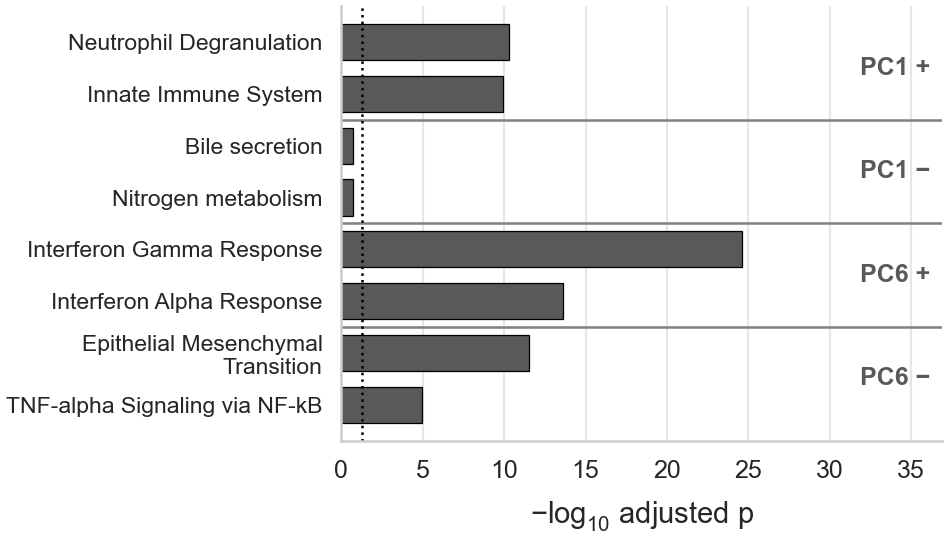

In [28]:
# ----------------------------------------------------------------------------------------------
# [Section 4.3 -- Pole pathways of the components Fig. 3a is drawn on]  (notebook cell 45)
# imported in an earlier section: BASE_PT (Section 0, cell 2); panel()
#     (Section 0, cell 2); RC (Section 0, cell 2); save()
#     (Section 0, cell 2); tidy() (Section 0, cell 2)
# variables from an earlier section: load_all (Section 4.1, cell 41); PC3D (Section 4.1, cell 41)
# ----------------------------------------------------------------------------------------------
# === how a pathway term is printed on Fig. 3d ===
# Database accessions are stripped and the name is wrapped to two lines, for the Fig. 3d block
# below; a name that does not fit two lines ends in an ellipsis. Every term is otherwise printed
# as Enrichr names it.
import re as _re
import textwrap as _tw

_ACC = _re.compile(r"\s+(R-HSA-\d+|WP\d+|hsa\d+)\s*$|\s*\(GO:\d+\)\s*$")


def _clean_term(t):
    t = _ACC.sub("", str(t)).strip()
    return _tw.fill(t, 24, max_lines=2, placeholder="…")


def pole_pathways(ax, blocks, wrap=30):
    """`blocks`: list of (block_label, colour, [(term, -log10 q), ...]) drawn top to bottom in one
    axis with a rule between blocks."""
    labels, vals, cols, seps, block_pos = [], [], [], [], []
    for label, colour, terms in blocks:
        start = len(labels)
        for term, v in terms:
            labels.append(_tw.fill(term, wrap, max_lines=2, placeholder="…"))
            vals.append(v)
            cols.append(colour)
        block_pos.append((label, colour, start, len(labels)))
        seps.append(len(labels))
    y = np.arange(len(labels))[::-1]
    ax.barh(y, vals, color=cols, edgecolor="black", lw=0.3, height=0.7)
    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=BASE_PT - 1.5)
    for s in seps[:-1]:
        ax.axhline(len(labels) - s - 0.5, color="0.5", lw=0.6)
    xmax = max(vals) * 1.5
    ax.set_xlim(0, xmax)
    for label, colour, a, b in block_pos:
        ax.text(xmax * 0.98, len(labels) - (a + b - 1) / 2 - 1, label, ha="right", va="center",
                fontsize=BASE_PT - 1, color=colour, fontweight="bold")
    ax.axvline(-np.log10(0.05), color="black", ls=":", lw=0.6)
    ax.set_xlabel("−log$_{10}$ adjusted p")
    ax.set_ylim(-0.7, len(labels) - 0.3)
    tidy(ax, ygrid=False)
    ax.grid(axis="x", color="0.9", lw=0.5)
    return ax


# Enrichr on the poles of the all-library components Fig. 3a is drawn on (`PC3D`, cell 41; three in
# the "3d" view, two in the "2d" view): the POLE_N genes
# loading most positively and most negatively on each. Cached on the gene set (`enrichr_cached`),
# so refitting the PCA on a different cohort misses the cache and recomputes rather than drawing
# a stale answer.
POLE_N = 100                       # genes per pole


# ==== manuscript panel Fig3d_pole_pathways_all ================================================
# d: what sits at each pole of the components (a) is drawn on. The 100 genes loading
# most positively and most negatively on each go to Enrichr against GO BP, KEGG, Reactome and
# MSigDB Hallmark, with the 2,000 genes of the decomposition as the background -- so enrichment
# is measured against the variable genes of this dataset, not against the genome.
#
# A pole carries no diagnosis name: panel (c) is what says which diagnosis sits where on each
# component, and this panel says what the genes at each end do. (Until 2026-10-08 a pole was
# named after the group whose mean sat farthest out along it when that group cleared the
# runner-up by a quarter of the spread between the three group means; the rule named PC1's
# negative end Normal and PC7's negative end CRC, and the author chose to drop it.)
_pname = "Fig3d_pole_pathways_all"
nterm = 2
POLE_COLOUR = "0.35"
with mpl.rc_context(RC):
    bg = list(load_all.index)
    blocks = []
    for pc in PC3D:
        for sign in ("+", "-"):
            genes = (load_all[pc].nlargest(POLE_N) if sign == "+" else load_all[pc].nsmallest(POLE_N)).index
            r = enrichr_cached(list(genes), bg, f"{pc}{sign}")
            if r is None or r.empty:
                continue
            t = r.drop_duplicates("Term").head(nterm)
            terms = [(_clean_term(term).replace("\n", " "), -np.log10(max(q, 1e-300)))
                     for term, q in zip(t["Term"], t["Adjusted P-value"])]
            # A true minus (U+2212) with a space, not the ASCII hyphen: "PC1-" reads as a
            # hyphenated stub rather than as the negative pole. The x-axis label of this same
            # panel is already a real minus, so the two agree.
            blocks.append((f"{pc} {'+' if sign == '+' else '−'}", POLE_COLOUR, terms))
    fig, ax = panel(_pname)
    pole_pathways(ax, blocks, wrap=30)   # 30, not 28: "TNF-alpha Signaling via NF-kB" is 29
    save(fig, _pname)               # characters and breaks across "NF-kB" at 28


### IBD vs CRC differential expression (pydeseq2) and the programme-coloured volcano

> **Manuscript output —** none of its own; required by the sections that follow.

In [29]:
# ----------------------------------------------------------------------------------------------
# [Section 4.4 -- IBD vs CRC differential expression (pydeseq2) and the programme-coloured volcano]  (notebook cell 47)
# variables from an earlier section: counts_all (Section 4, cell 39); crc_samples (Section 4,
#     cell 39); ibd_samples (Section 4, cell 39)
# ----------------------------------------------------------------------------------------------
# === §4.1  Samples entering the IBD vs CRC contrast ===
ibd_samples = [s for s in ibd_samples if s in counts_all.columns]
crc_samples = [s for s in crc_samples if s in counts_all.columns]


In [30]:
# ----------------------------------------------------------------------------------------------
# [Section 4.4 -- IBD vs CRC differential expression (pydeseq2) and the programme-coloured volcano]  (notebook cell 48)
# variables from an earlier section: counts_all (Section 4, cell 39); crc_samples (Section 4,
#     cell 39), last set Section 4.4, cell 47; ibd_samples (Section 4, cell 39), last set
#     Section 4.4, cell 47
# ----------------------------------------------------------------------------------------------
# === §4.2  Count matrix and design for pydeseq2 ===
# Mitochondrial genes and MT pseudogenes were already removed in §1.
de_cols = ibd_samples + crc_samples

raw = counts_all[de_cols].astype(int)
keep_genes = raw.sum(axis=1) >= 10          # minimal pre-filter
raw = raw.loc[keep_genes]

counts_de = raw.T                            # pydeseq2 wants samples x genes
metadata = pd.DataFrame(
    {"condition": ["IBD"] * len(ibd_samples) + ["CRC"] * len(crc_samples)},
    index=de_cols,
)


In [31]:
# ----------------------------------------------------------------------------------------------
# [Section 4.4 -- IBD vs CRC differential expression (pydeseq2) and the programme-coloured volcano]  (notebook cell 49)
# variables from an earlier section: counts_de (Section 4.4, cell 48); metadata (Section 4.4,
#     cell 48)
# ----------------------------------------------------------------------------------------------
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds  import DeseqStats
from pydeseq2.default_inference import DefaultInference

inference = DefaultInference(n_cpus=4)

dds = DeseqDataSet(
    counts=counts_de,
    metadata=metadata,
    design="~condition",
    refit_cooks=True,
    inference=inference,
    quiet=True,
)
dds.deseq2()

# Contrast: IBD vs CRC (CRC is reference; positive log2FC = up in IBD)
ds = DeseqStats(dds, contrast=["condition", "IBD", "CRC"], inference=inference, quiet=True)
ds.summary()

de = ds.results_df.copy()
de.index.name = "gene"
de = de.reset_index().sort_values("padj").reset_index(drop=True)
# Rename for consistency with downstream cells
de = de.rename(columns={"log2FoldChange": "log2FC", "pvalue": "p_value"})


Fitting dispersions...
... done in 0.09 seconds.

Fitting MAP dispersions...
... done in 0.09 seconds.

Fitting LFCs...


... done in 0.08 seconds.



In [32]:
# ----------------------------------------------------------------------------------------------
# [Section 4.4 -- IBD vs CRC differential expression (pydeseq2) and the programme-coloured volcano]  (notebook cell 50)
# variables from an earlier section: de (Section 4.4, cell 49)
# ----------------------------------------------------------------------------------------------
FDR_THR = 0.05
LFC_THR = 1.0

de["direction"] = "ns"
de.loc[(de["padj"] < FDR_THR) & (de["log2FC"] >=  LFC_THR), "direction"] = "up_IBD"
de.loc[(de["padj"] < FDR_THR) & (de["log2FC"] <= -LFC_THR), "direction"] = "up_CRC"


In [33]:
# ----------------------------------------------------------------------------------------------
# [Section 4.4 -- IBD vs CRC differential expression (pydeseq2) and the programme-coloured volcano]  (notebook cell 51)
# variables from an earlier section: de (Section 4.4, cell 49)
# ----------------------------------------------------------------------------------------------
# === the CRC-vs-IBD fold change the volcano draws ===
# The DESeq2 contrast is IBD vs CRC; Fig. 3e is drawn with CRC on the right.
de = de.copy()
de["crc_lfc"] = -de["log2FC"]


### Programme scores

> **Manuscript output —** Fig. 3e, f · Supplementary Fig. 8.

programmes: declared terms, genes from the CRC-vs-IBD contrast (padj < 0.05, |log2FC| > 1; 522 up in CRC, 769 up in IBD)
  WNT signalling       Wnt signaling pathway (KEGG_2021_Human): 11 genes up in CRC, Enrichr adj. p 0.019
                       MYC, MMP7, NOTUM, GPC4, RUVBL1, PLCB4, ZNRF3, NKD1, FZD3, WNT11, NKD2
  EMT / stroma         Epithelial Mesenchymal Transition (MSigDB_Hallmark_2020): 23 genes up in CRC, Enrichr adj. p 2.2e-10
                       MYL9, TPM2, IGFBP2, TNFRSF12A, GADD45A, SERPINE2, MSX1, TFPI2, TIMP3, SERPINH1, POSTN, PTX3, SPARC, CALD1, CCN1, FN1, LOXL2, ENO2, HTRA1, MMP2, GREM1, ELN, LOX
  Proliferation / E2F  E2F Targets (MSigDB_Hallmark_2020): 16 genes up in CRC, Enrichr adj. p 1.9e-05
                       MYC, NME1, CSE1L, PRDX4, DSCC1, RFC3, TRIP13, UBE2T, CDC20, PLK1, MAD2L1, PTTG1, DIAPH3, MELK, SPC25, CDKN3
  IFN-γ response       Interferon Gamma Response (MSigDB_Hallmark_2020): 57 genes up in IBD, Enrichr adj. p 3e-39
                       CXCL

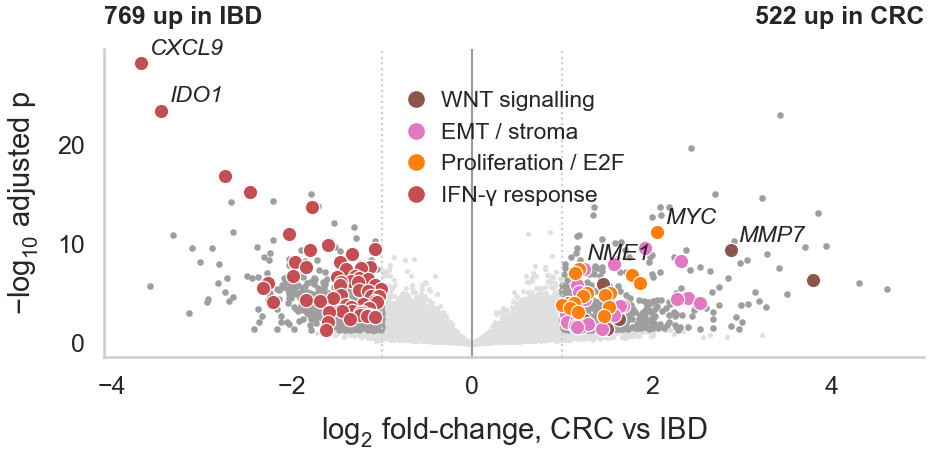

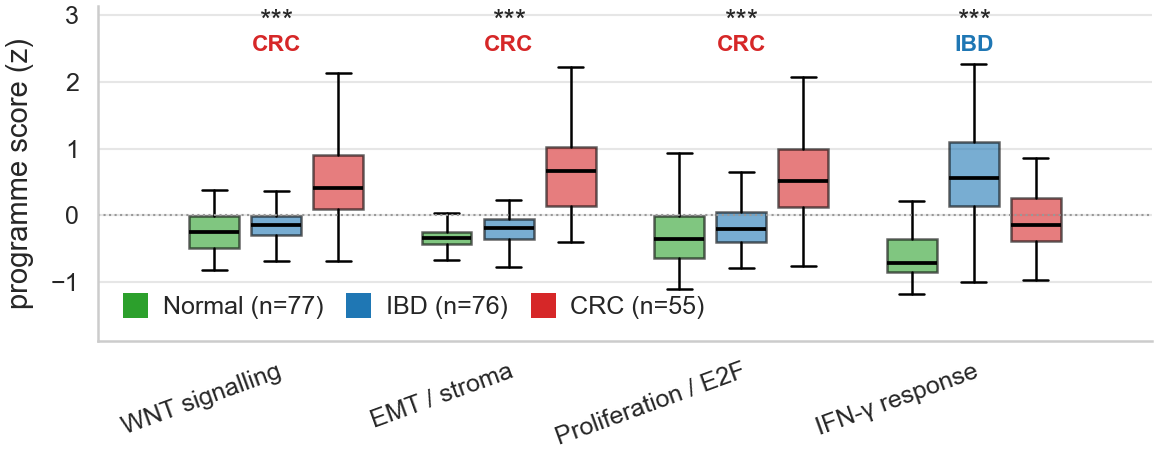

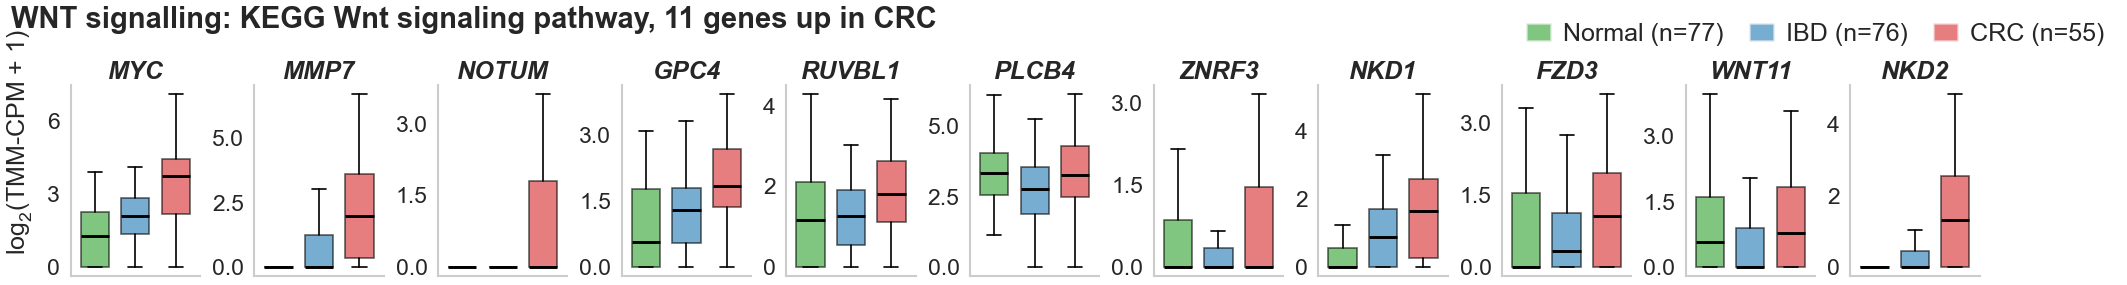

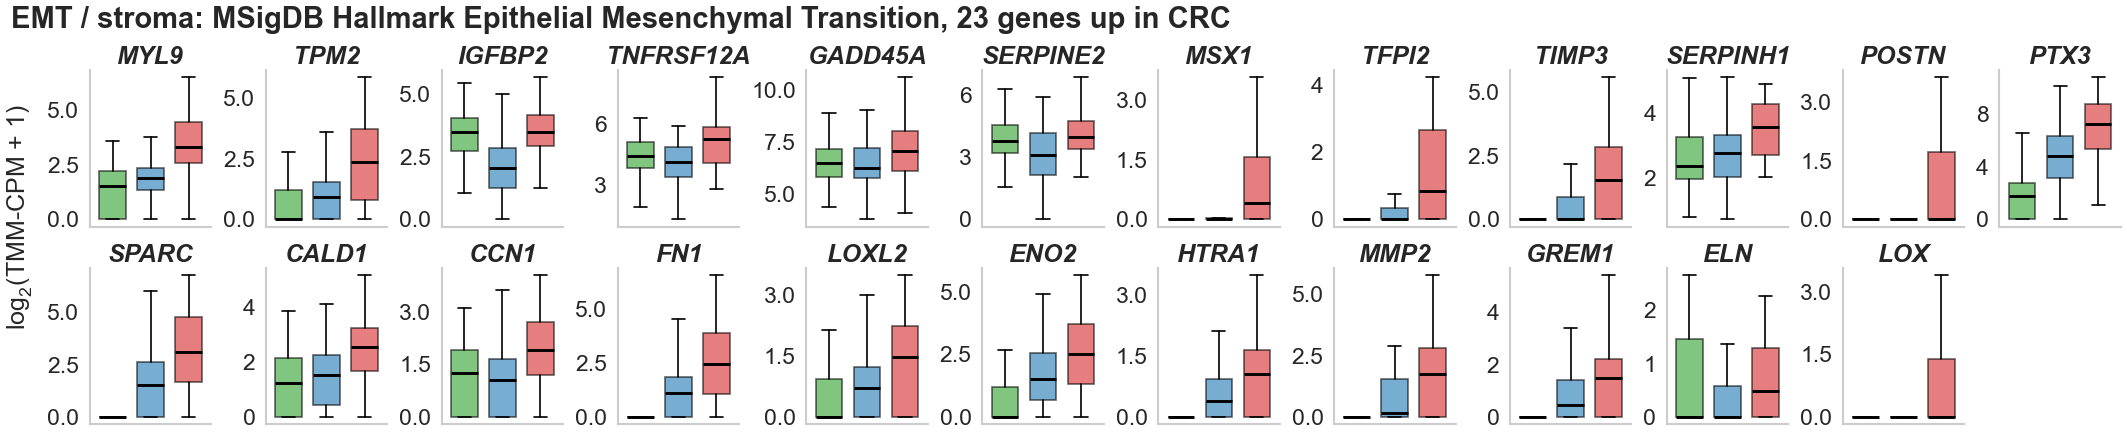

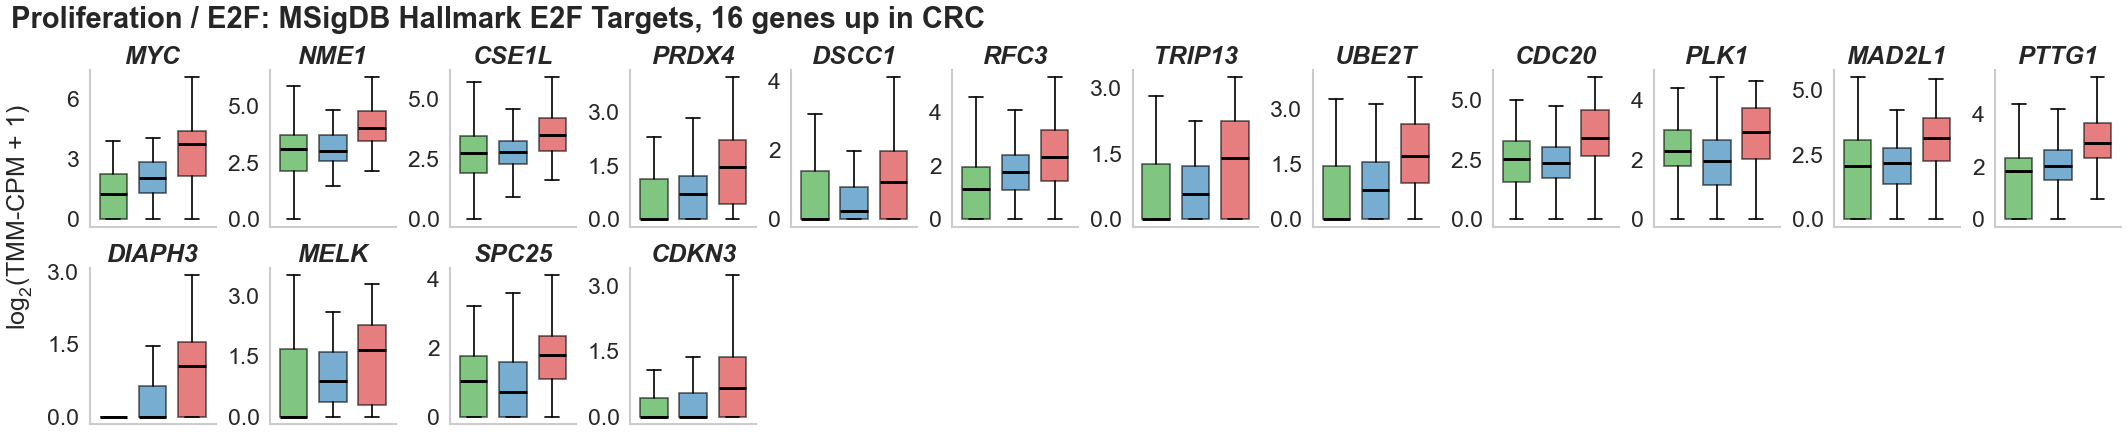

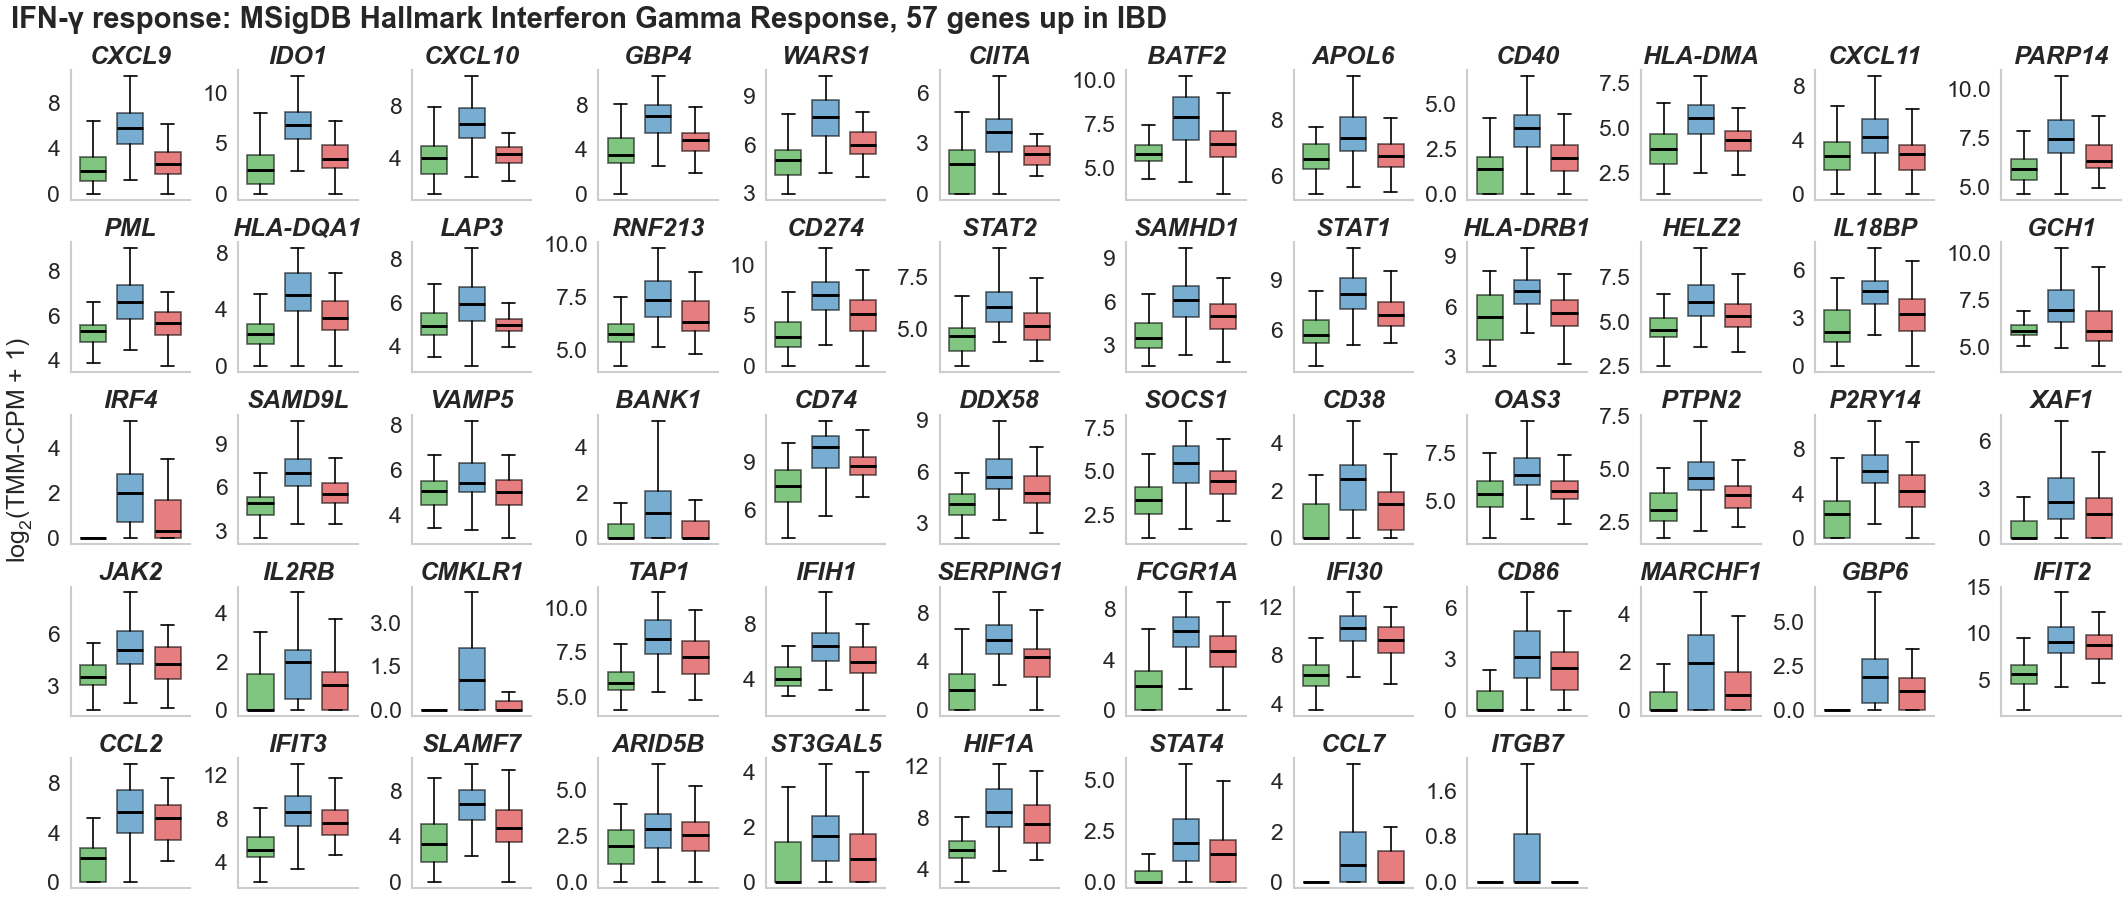

In [34]:
# ----------------------------------------------------------------------------------------------
# [Section 4.5 -- Programme scores]  (notebook cell 53)
# imported in an earlier section: BASE_PT (Section 0, cell 2); MF_GROUP_PAL
#     (Section 0, cell 2); panel() (Section 0, cell 2); RC
#     (Section 0, cell 2); save() (Section 0, cell 2); stars()
#     (Section 0, cell 2); tidy() (Section 0, cell 2)
# variables from an earlier section: D (Section 0, cell 2), last set Section 4, cell 39; de
#     (Section 4.4, cell 49), last set Section 4.4, cell 51; libs (Section 4, cell 39); meta_f
#     (Section 0, cell 2), last set Section 4, cell 39
# ----------------------------------------------------------------------------------------------
# === §4b  Figure 3f: programme scores in Normal, IBD and CRC ===
from matplotlib.lines import Line2D
from scipy.stats import mannwhitneyu

# The programmes, their colours and the score have one definition, the block below (moved in
# from scripts/make_fig3_programmes.py on 2026-10-08). This cell held a second copy of all five
# until 2026-09-29, and it was the copy the figure used.

# ==== from scripts/make_fig3_programmes.py: used only in this cell, so it lives here (moved 2026-10-08) =====
#
# The four CRC / IBD programmes, their colours and their score.
#
# Used by Figure 3e, f: `PROGRAMME_TERMS` declares each programme as one Enrichr term,
# `programme_genes` computes its genes from the contrast, `zscore_signature` scores them per
# library and `PROG_COL` colours them.

# Why these four programmes, and how their genes are chosen
# ---------------------------------------------------------
# Each programme is declared as one named term of the libraries Fig. 3d already queries (Enrichr:
# GO Biological Process, KEGG, Reactome, MSigDB Hallmark), on one side of the contrast. Its genes
# are computed, not listed: the term's genes among those the CRC-vs-IBD contrast calls
# significant on that side (padj < 0.05, |log2FC| > 1, the volcano's own thresholds), as Enrichr
# returns them with every tested gene as the background. What is chosen by hand is the four
# terms, and nothing else.
#
# The terms are the database names of the four programmes this analysis has described since
# 2026-08 -- WNT / crypt-stem, desmoplastic stroma, proliferation (CRC side) and IFN-gamma (IBD
# side). Until 2026-10-08 those were hand-assembled gene lists: part top-ranked DE genes, part
# textbook markers (LGR5, AXIN2, SOX9, COL1A1, STAT1, ...) that the contrast did not call
# significant. Declaring the terms instead makes every member a gene the contrast selected and a
# database put in that pathway, and lets the membership follow the cohort. Two choices were made
# on the 2026-10-08 dry run: proliferation is Hallmark E2F Targets, because Hallmark Myc Targets
# V1 was not enriched on the CRC side; and stroma stays Hallmark EMT, the strongest CRC-side
# term, although its most significant members are smooth-muscle genes (MYL9, TPM2, CALD1).
#
# The volcano is annotated with them because a volcano on its own answers only "how many genes
# and how far", not "is this one thing or several". Colouring the four shows the separation is
# not a single severity axis: three of them sit on the CRC side and one on the IBD side.
#
# The circularity is real and is stated in the Methods: because the genes are chosen from the
# contrast, the programme scores of Fig. 3f are a description of that contrast, not independent
# evidence for it. What they can show is that the CRC-IBD difference decomposes into several
# programmes rather than one. `programme_genes` prints, per programme, the term's adjusted p in
# that enrichment and its member genes; those are the numbers the Methods may quote.
PROGRAMME_TERMS = {      # programme -> (side of the contrast, Enrichr library, term)
    "WNT signalling":  ("CRC", "KEGG_2021_Human", "Wnt signaling pathway"),
    "EMT / stroma":    ("CRC", "MSigDB_Hallmark_2020", "Epithelial Mesenchymal Transition"),
    "Proliferation / E2F": ("CRC", "MSigDB_Hallmark_2020", "E2F Targets"),
    "IFN-\u03b3 response": ("IBD", "MSigDB_Hallmark_2020", "Interferon Gamma Response"),
}
PROG_COL = dict(zip(PROGRAMME_TERMS, ["#8c564b", "#e377c2", "#ff7f0e", "#c44e52"]))
def zscore_signature(logexpr, genes, samples):
    g = [x for x in genes if x in logexpr.index]
    m = logexpr.loc[g, samples]
    z = m.sub(m.mean(axis=1), axis=0).div(m.std(axis=1).replace(0, np.nan), axis=0)
    return z.mean(axis=0)

def programme_genes(de, terms, padj=0.05, lfc=1.0):
    """{programme: member genes, most significant first}. Each side's significant genes go to
    Enrichr once (`enrichr_cached`, cached on the gene set and the background, as Fig. 3d's are); a
    programme's genes are its term's overlap with that side."""
    background = de["gene"].tolist()
    sig = de[(de["padj"] < padj) & (de["crc_lfc"].abs() > lfc)]
    side_genes = {"CRC": sig.loc[sig["crc_lfc"] > 0, "gene"].tolist(),
                  "IBD": sig.loc[sig["crc_lfc"] < 0, "gene"].tolist()}
    enr = {side: enrichr_cached(side_genes[side], background, f"DE_up_{side}")
           for side in sorted({s for s, _, _ in terms.values()})}
    rank = {g: k for k, g in enumerate(de.sort_values("padj")["gene"])}
    out = {}
    print(f"programmes: declared terms, genes from the CRC-vs-IBD contrast (padj < {padj:g}, "
          f"|log2FC| > {lfc:g}; {len(side_genes['CRC'])} up in CRC, {len(side_genes['IBD'])} up in IBD)")
    for name, (side, lib, term) in terms.items():
        e = enr[side]
        hit = e[(e["Gene_set"] == lib) & (e["Term"] == term)]
        if hit.empty:
            raise ValueError(f"{name}: '{term}' ({lib}) shares no gene with the {side} side")
        out[name] = sorted(hit["Genes"].iloc[0].split(";"), key=lambda g: rank.get(g, 1e9))
        q = hit["Adjusted P-value"].iloc[0]
        print(f"  {name:20} {term} ({lib}): {len(out[name])} genes up in {side}, "
              f"Enrichr adj. p {q:.2g}{'' if q < 0.05 else '  -- NOT significant'}")
        print(f"  {'':20} {', '.join(out[name])}")
    return out


PROGRAMS = programme_genes(de, PROGRAMME_TERMS)

logtmmcpm = D["logtmmcpm"].loc[:, meta_f.index]       # the disease-model libraries only


def programme_boxes(ax, scores: dict, group_order, palette, higher: dict, pvals: dict,
                    short: dict | None = None):
    """`scores[programme][group]` -> array of per-library z scores."""
    names = list(scores)
    x = np.arange(len(names))
    w = 0.8 / len(group_order)
    for i, g in enumerate(group_order):
        for j, name in enumerate(names):
            v = np.asarray(scores[name].get(g, []), dtype=float)
            v = v[np.isfinite(v)]
            if not len(v):
                continue
            ax.boxplot(v, positions=[x[j] + (i - (len(group_order) - 1) / 2) * w], widths=w * 0.8,
                       showfliers=False, patch_artist=True,
                       boxprops=dict(facecolor=palette[g], alpha=0.6, lw=0.6),
                       medianprops=dict(color="black", lw=0.9),
                       whiskerprops=dict(lw=0.6), capprops=dict(lw=0.6))
    ymax = ax.get_ylim()[1]
    ax.set_ylim(top=ymax + 0.7)
    for j, name in enumerate(names):
        ax.text(x[j], ymax + 0.45, stars(pvals[name]), ha="center", va="center", fontsize=BASE_PT)
        ax.text(x[j], ymax + 0.12, higher[name], ha="center", va="center", fontsize=BASE_PT - 1.5,
                color=palette[higher[name]], fontweight="bold")
    ax.axhline(0, color="0.6", lw=0.5, ls=":")
    lo, hi = ax.get_ylim()
    ax.set_ylim(bottom=lo - 0.12 * (hi - lo))      # a band under the lowest whisker for the legend
    ax.set_xticks(x)
    ax.set_xticklabels([(short or {}).get(n, n) for n in names], rotation=20, ha="right",
                       rotation_mode="anchor")
    ax.set_ylabel("programme score (z)")
    n = {g: max((len(scores[nm].get(g, [])) for nm in names), default=0) for g in group_order}
    ax.legend(handles=[Line2D([0], [0], marker="s", ls="none", markerfacecolor=palette[g],
                              markeredgecolor="none", markersize=6, label=f"{g} (n={n[g]})")
                       for g in group_order], loc="lower left", ncol=len(group_order),
              columnspacing=0.8)
    tidy(ax)
    return ax


def volcano(ax, d: pd.DataFrame, programs: dict, prog_col: dict, label_genes, n_up_crc, n_up_ibd,
            x="crc_lfc", y="nlp"):
    sig = (d["padj"] < 0.05) & (d[x].abs() > 1)
    ax.scatter(d.loc[~sig, x], d.loc[~sig, y], s=1.5, c="#e0e0e0", linewidths=0, rasterized=True)
    ax.scatter(d.loc[sig, x], d.loc[sig, y], s=2.5, c="#9e9e9e", linewidths=0, rasterized=True)
    handles = []
    for name, genes in programs.items():
        sub = d[d["gene"].isin(genes)]
        ax.scatter(sub[x], sub[y], s=12, c=prog_col[name], edgecolors="white", linewidths=0.3,
                   zorder=3)
        handles.append(Line2D([0], [0], marker="o", ls="none", markerfacecolor=prog_col[name],
                              markeredgecolor="none", markersize=4, label=name))
    # a label that would overprint one already placed is left off: earlier genes win
    renderer, placed = ax.figure.canvas.get_renderer(), []
    for g in label_genes:
        r = d[d["gene"] == g]
        if len(r):
            t = ax.annotate(g, (r[x].iloc[0], r[y].iloc[0]), xytext=(2, 2),
                            textcoords="offset points", fontsize=BASE_PT - 1.5, fontstyle="italic")
            bb = t.get_window_extent(renderer)
            if any(bb.overlaps(p) for p in placed):
                t.remove()
            else:
                placed.append(bb)
    ax.axvline(0, color="0.6", lw=0.5)
    for v in (-1, 1):
        ax.axvline(v, color="0.8", lw=0.5, ls=":")
    ax.set_xlabel("log$_2$ fold-change, CRC vs IBD")
    ax.set_ylabel("−log$_{10}$ adjusted p")
    # the two counts sit in the title line, above the axes: as corner texts inside them they
    # printed over the gene named at the top left (CXCL9; fixed 2026-10-21)
    ax.set_title(f"{n_up_ibd} up in IBD", loc="left", fontsize=BASE_PT - 1, fontweight="bold")
    ax.set_title(f"{n_up_crc} up in CRC", loc="right", fontsize=BASE_PT - 1, fontweight="bold")
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.93), fontsize=BASE_PT - 1.5)
    tidy(ax, ygrid=False)
    return ax


# ==== manuscript panel Fig3e_volcano ==========================================================
# e: CRC against IBD, coloured by programme (notebook cell 51, from `de`).
_pname = "Fig3e_volcano"
# the genes named on the panel: the two most significant members of each programme, a gene
# that belongs to two programmes named once
label_genes = []
for genes in PROGRAMS.values():
    label_genes += [g for g in genes if g not in label_genes][:2]
with mpl.rc_context(RC):
    d = de.dropna(subset=["padj", "crc_lfc"]).copy()
    d["nlp"] = -np.log10(d["padj"].clip(lower=1e-300))
    n_crc = int(((d["padj"] < 0.05) & (d["crc_lfc"] > 1)).sum())
    n_ibd = int(((d["padj"] < 0.05) & (d["crc_lfc"] < -1)).sum())
    fig, ax = panel(_pname)
    volcano(ax, d, PROGRAMS, PROG_COL, label_genes, n_crc, n_ibd)
    save(fig, _pname)

# ==== manuscript panel Fig3f_programmes =======================================================
# f: those programmes scored per library in Normal, IBD and CRC stool (`libs`, cell 39).
_pname = "Fig3f_programmes"
with mpl.rc_context(RC):
    groups = {g: libs[g] for g in ("Normal", "IBD", "CRC")}
    allsam = sum(groups.values(), [])
    scores, higher, pv = {}, {}, {}
    for prog in PROGRAMS:
        sc = zscore_signature(logtmmcpm, PROGRAMS[prog], allsam)
        scores[prog] = {g: sc.reindex(s).dropna().values for g, s in groups.items()}
        a, b = scores[prog]["CRC"], scores[prog]["IBD"]
        pv[prog] = mannwhitneyu(a, b, alternative="two-sided").pvalue
        higher[prog] = "CRC" if np.median(a) > np.median(b) else "IBD"
    short_names = None                    # the programme names, as declared above
    fig, ax = panel(_pname)
    programme_boxes(ax, scores, ["Normal", "IBD", "CRC"], MF_GROUP_PAL, higher, pv, short_names)
    save(fig, _pname)


# ==== manuscript panels FigS8a-d ==============================================================
# Supplementary Fig. 8: every gene behind the programme scores of Fig. 3f, as one box per group on
# the matrix those scores are computed from (log2(TMM-CPM + 1), `logtmmcpm` above) and in the same
# libraries. One panel per programme; genes in the order the contrast ranks them, most significant
# first. Every gene drawn is significant in the CRC-vs-IBD contrast by construction (that is how
# `programme_genes` picks them); what the figure adds is where Normal stool sits, which the
# contrast does not see, and whether a programme score is carried by a few genes or by most.
S8_PANEL = dict(zip(PROGRAMME_TERMS, ["FigS8a_genes_wnt", "FigS8b_genes_emt", "FigS8c_genes_e2f",
                                      "FigS8d_genes_ifng"]))
S8_COLS = 12                                          # genes per row
S8_ORDER = ["Normal", "IBD", "CRC"]                   # as in Fig. 3f
_LIB_SHORT = {"KEGG_2021_Human": "KEGG", "MSigDB_Hallmark_2020": "MSigDB Hallmark",
              "Reactome_2022": "Reactome", "GO_Biological_Process_2023": "GO BP"}


def gene_boxes(ax, gene, expr, groups, palette):
    """One gene: a box per group, no outliers, no x ticks; the gene name is the title."""
    for k, g in enumerate(S8_ORDER):
        v = expr.loc[gene, groups[g]].dropna().values
        ax.boxplot(v, positions=[k], widths=0.7, showfliers=False, patch_artist=True,
                   boxprops=dict(facecolor=palette[g], alpha=0.6, lw=0.4),
                   medianprops=dict(color="black", lw=0.7),
                   whiskerprops=dict(lw=0.4), capprops=dict(lw=0.4))
    ax.set_xlim(-0.6, len(S8_ORDER) - 0.4)
    ax.set_xticks([])
    ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(3))
    ax.tick_params(axis="y", labelsize=BASE_PT - 1.5, length=1.5, pad=1)
    ax.set_title(gene, fontsize=BASE_PT - 1, fontstyle="italic", pad=1.5)
    for side_ in ("top", "right"):
        ax.spines[side_].set_visible(False)
    for side_ in ("left", "bottom"):
        ax.spines[side_].set_linewidth(0.5)


with mpl.rc_context(RC):
    s8_groups = {g: [s for s in libs[g] if s in logtmmcpm.columns] for g in S8_ORDER}
    for name, (side, lib, term) in PROGRAMME_TERMS.items():
        _pname = S8_PANEL[name]
        genes = [g for g in PROGRAMS[name] if g in logtmmcpm.index]
        nrow = -(-len(genes) // S8_COLS)
        fig, axes = panel(_pname, nrows=nrow, ncols=S8_COLS, squeeze=False)
        for ax, gene in zip(axes.flat, genes):
            gene_boxes(ax, gene, logtmmcpm, s8_groups, MF_GROUP_PAL)
        for ax in list(axes.flat)[len(genes):]:
            ax.set_axis_off()
        fig.suptitle(f"{name}: {_LIB_SHORT.get(lib, lib)} {term}, {len(genes)} genes up in {side}",
                     x=0.005, ha="left", fontsize=BASE_PT, fontweight="bold")
        fig.supylabel("log$_2$(TMM-CPM + 1)", fontsize=BASE_PT - 1)
        if _pname.startswith("FigS8a"):                # the group key, once, on the first panel
            fig.legend(handles=[mpl.patches.Patch(facecolor=MF_GROUP_PAL[g], alpha=0.6,
                                                  label=f"{g} (n={len(s8_groups[g])})")
                                for g in S8_ORDER],
                       loc="outside upper right", ncol=len(S8_ORDER), frameon=False,
                       fontsize=BASE_PT - 1, handlelength=1, columnspacing=1)
        save(fig, _pname)


### Three-class confusion matrix and ROC

> **Manuscript output —** Fig. 3g–i · Supplementary Fig. 9.

Fig. 3g, h -- mean over repeats (95% bootstrap CI over libraries):
  accuracy: 0.864 (0.82–0.90)
  AUC CRC: 0.964 (0.93–0.99)
  AUC IBD: 0.948 (0.91–0.98)
  AUC Normal: 0.942 (0.91–0.97)
Fig. 3g -- consensus-call accuracy 0.870 (0.83–0.91) (mean per-assignment accuracy 0.864)
CRC and IBD libraries called Normal by their consensus call over the 10 fold assignments: CRC 9 of 55, IBD 10 of 76; mean per assignment 8.4 and 10.6 (the mean-matrix cells)
group         variable        level  libraries called Normal (consensus call)  mean libraries called Normal per assignment  libraries in the model
  CRC     tumour stage      Stage I                                         4                                          4.1                       7
  CRC     tumour stage     Stage II                                         3                                          2.7                      17
  CRC     tumour stage    Stage III                                         2                               

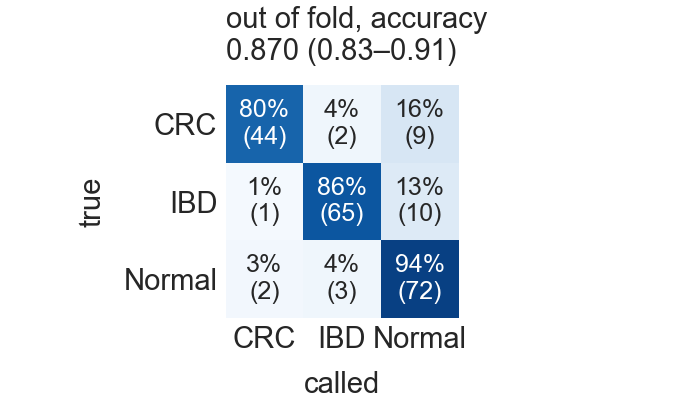

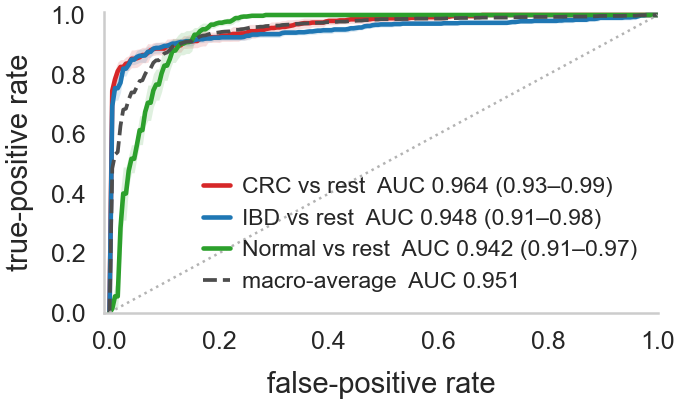

out-of-fold accuracy by number of top-variance genes, mean and s.e. over 10 fold splits:
         accuracy  accuracy_se
n_genes                       
10         0.7606       0.0061
20         0.7851       0.0043
50         0.7947       0.0048
100        0.8207       0.0050
200        0.8394       0.0054
500        0.8548       0.0033
1000       0.8582       0.0027
2000       0.8644       0.0040
5000       0.8409       0.0051
10000      0.8188       0.0045
20000      0.8077       0.0057
58320      0.7837       0.0044


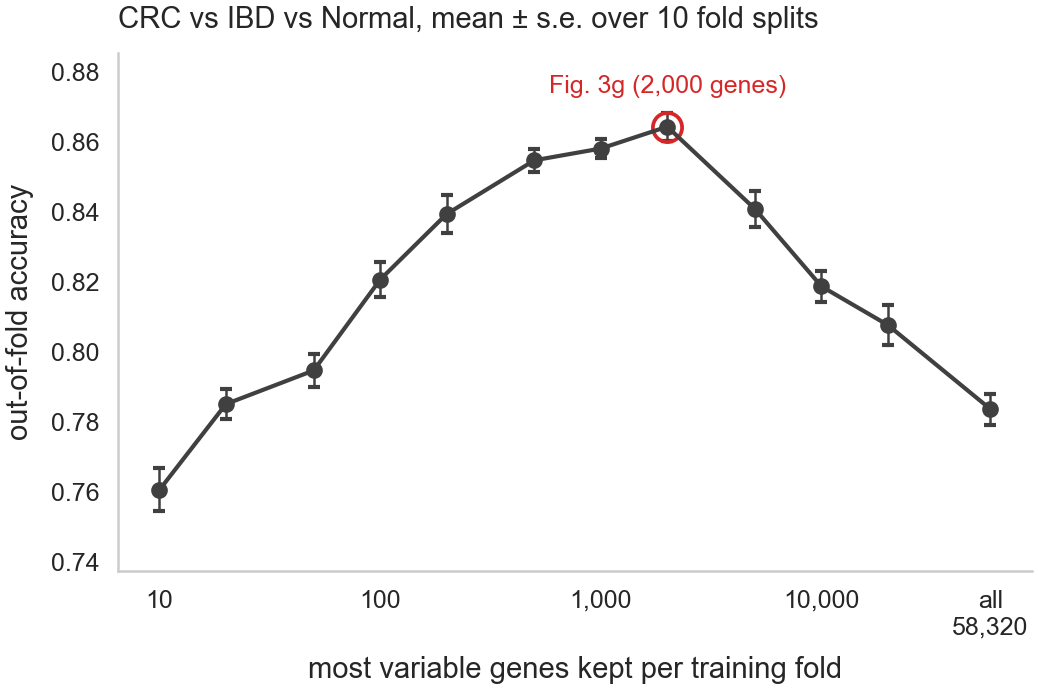

Fig. 3i -- Welch top-20 + logistic regression, CRC + APL (118) vs Normal (77), 5 x grouped 5-fold CV:
  CRC vs Normal: AUC 0.969 (0.94–0.99); sensitivity 0.90 at 90% specificity
  APL vs Normal: AUC 0.713 (0.62–0.80); sensitivity 0.42 at 90% specificity
  genes chosen in >= 20 of 25 folds: HBB, MMP7, TGFBI, SPARC, MMP3, IL6, HBA2, HBA1, TUBB3, IL33, MMP1


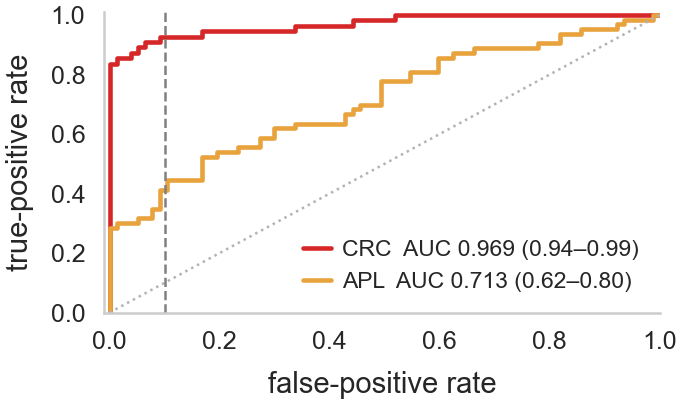

In [35]:
# ----------------------------------------------------------------------------------------------
# [Section 4.6 -- Three-class confusion matrix and ROC]  (notebook cell 55)
# imported in an earlier section: BASE_PT (Section 0, cell 2); MF_GROUP_PAL
#     (Section 0, cell 2); panel() (Section 0, cell 2); RC
#     (Section 0, cell 2); save() (Section 0, cell 2)
# variables from an earlier section: D (Section 0, cell 2), last set Section 4, cell 39; logtmmcpm_f
#     (Section 0, cell 2), last set Section 4, cell 39; meta_f (Section 0, cell 2), last set
#     Section 4, cell 39
# ----------------------------------------------------------------------------------------------
# === §14  The classifier pipeline, its grouped folds and the libraries it is fitted on ===
# Until 2026-10-13 this setup also served two screening designs and a simulated-bleed model
# (Fig. 4c-f); those left the paper, and the three-class model below moved to Fig. 3g, h.
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# The pipeline and the scoring helpers (TopVarianceSelector, classifier_pipe, rank_auc, boot_ci,
# ci_text, confusion, roc_with_confusion) are shared with the activity classifier of Fig. 4e,
# so they are defined in the setup cell.
_pipe = classifier_pipe

# The model is refitted this many times, with a different fold split each time. One pass would
# give a single number per metric and no way to tell how much of it is the split; the spread
# across repeats answers that. It is Monte-Carlo error of the cross-validation, not sampling
# error of the cohort: the figure carries a bootstrap over libraries for that (`boot_ci`, below),
# and the two are far apart.
N_REPEATS = 10


# The fold assignment must not depend on how a class is spelt. StratifiedGroupKFold encodes
# the labels by sorting them, so when the control class was renamed from `Healthy` to `Normal`
# (2026-10-07) it moved from before `IBD` to after it, the folds changed, and every out-of-fold
# number moved in the third decimal. The labels are therefore coded in the order their old
# names sorted in, which keeps the folds -- and the figures -- exactly the manuscript's.
_STRAT_ORDER = ["CRC", "CRC+APL", "Haemorrhoid", "Normal", "IBD"]


class _GroupedCV:
    def __init__(self, n_splits, seed):
        self._cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)

    def split(self, X, y, groups):
        codes = np.array([_STRAT_ORDER.index(v) for v in y])
        return self._cv.split(X, codes, groups)


def _grouped_cv(y, groups, n_splits=5, seed=0):
    return _GroupedCV(n_splits, seed)


def _auc(y_pos, score, y_neg):
    m = y_pos | y_neg
    if y_pos[m].sum() == 0 or (~y_pos[m]).sum() == 0:
        return np.nan
    return float(roc_auc_score(y_pos[m].astype(int), score[m]))


def _sens_at_spec(score_pos, score_neg, spec=0.90):
    """Sensitivity of `score_pos` at a fixed specificity on `score_neg`."""
    if len(score_neg) == 0:
        return np.nan, np.nan
    thr = np.quantile(score_neg, spec)   # spec=0.90 -> 10% of negatives above thr
    return float((score_pos >= thr).mean()) if len(score_pos) else np.nan, float(thr)


# --- labels. The disease-model view (cell 39) has already relabelled every Normal group --
# healthy volunteers, colonoscopy-negative (NEG) and non-advanced lesions (NAPL) -- as
# `Normal`, so that one label is the whole Normal arm here.
KEEP = ["CRC", "APL", "IBD", "Normal"]
meta14 = meta_f.loc[meta_f["study_group"].isin(KEEP)].copy()
meta14["sample_id"] = meta14["sample_id"].astype(str)
meta14["neoplasia"] = meta14["study_group"].isin(["CRC", "APL"])
meta14["normal"] = meta14["study_group"].eq("Normal")
meta14["y3"] = np.where(meta14["neoplasia"], "CRC+APL",
                 np.where(meta14["normal"], "Normal", "IBD"))


X_all = logtmmcpm_f[meta14.index].T.values.astype(float)

is_normal = meta14["normal"].values
is_crc = meta14["study_group"].eq("CRC").values
is_apl = meta14["study_group"].eq("APL").values
is_ibd = meta14["y3"].eq("IBD").values


# === §14c  CRC vs IBD vs Normal: accuracy of the three-way call ===
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, precision_recall_fscore_support

CLS = ["CRC", "IBD", "Normal"]

# APL is excluded: it is a screening target, not one of the three triage calls
_m = meta14["study_group"].isin(["CRC", "IBD", "Normal"]).values
yC = np.where(meta14["study_group"].eq("CRC").values, "CRC",
              np.where(meta14["y3"].eq("IBD").values, "IBD", "Normal"))[_m]
XC = X_all[_m]
gC = meta14["sample_id"].values[_m]


def _mrow(_tag, _rep, _prob):
    """Accuracy and per-class figures for one repeat's out-of-fold probabilities."""
    _pred = np.array(CLS)[_prob.argmax(1)]
    _pr, _rc, _f1, _ = precision_recall_fscore_support(yC, _pred, labels=CLS, zero_division=0)
    _d = dict(model=_tag, repeat=_rep,
              accuracy=accuracy_score(yC, _pred),
              balanced_accuracy=balanced_accuracy_score(yC, _pred))
    for _i, _c in enumerate(CLS):
        _d[f"recall {_c}"] = _rc[_i]
        _d[f"precision {_c}"] = _pr[_i]
        _d[f"F1 {_c}"] = _f1[_i]
        _d[f"AUC {_c}"] = roc_auc_score((yC == _c).astype(int), _prob[:, _i])
    return _d


# --- a dedicated model that never sees APL at all --------------------------------------------------
pC_reps = np.full((N_REPEATS, int(_m.sum()), 3), np.nan)
for _rep in range(N_REPEATS):
    for _tr, _te in _grouped_cv(yC, gC, seed=_rep).split(XC, yC, gC):
        _pipe_r = _pipe().fit(XC[_tr], yC[_tr])
        _cls = list(_pipe_r.named_steps["logisticregression"].classes_)
        pC_reps[_rep, _te] = _pipe_r.predict_proba(XC[_te])[:, [_cls.index(_c) for _c in CLS]]

MC = "dedicated CRC vs IBD vs Normal model"
accC = pd.DataFrame([_mrow(MC, _r, pC_reps[_r]) for _r in range(N_REPEATS)])
_cols = [_c for _c in accC.columns if _c not in ("model", "repeat")]
meanC = accC[_cols].mean()                                # over the repeated fold splits

# 95% bootstrap intervals over libraries (class sizes kept) for the accuracy and the one-vs-rest
# AUCs; the statistic is the mean over the N_REPEATS fold splits on the resampled libraries.
_hitC = np.mean([np.array(CLS)[pC_reps[_r].argmax(1)] == yC for _r in range(N_REPEATS)], axis=0)


def _statsC(idx):
    """Accuracy, then AUC per class of `CLS`, on one resample `idx`."""
    _o = [_hitC[idx].mean()]
    for _i, _c in enumerate(CLS):
        _t = yC[idx] == _c
        _o.append(np.mean([rank_auc(_t, pC_reps[_r][idx, _i]) for _r in range(N_REPEATS)]))
    return np.array(_o)


_loC, _hiC = boot_ci(_statsC, yC)
ciC = pd.DataFrame({"lo": _loC, "hi": _hiC}, index=["accuracy"] + [f"AUC {_c}" for _c in CLS])
print("Fig. 3g, h -- mean over repeats (95% bootstrap CI over libraries):")
for _k in ciC.index:
    print(f"  {_k}: {ci_text(meanC[_k], ciC.loc[_k, 'lo'], ciC.loc[_k, 'hi'])}")

# Fig. 3g counts libraries, not the mean of per-assignment matrices (adopted 2026-10-28): each
# library gets one consensus call, the class it was called most often over the N_REPEATS fold
# assignments, ties broken by its mean out-of-fold probability. The "called Normal" cells of the
# matrix are then exactly the libraries the Results tabulates below, which the mean matrix
# (kept as `cmC_mean`; it printed 8 CRC called Normal where the tabulation counted 9) was not.
cmC_mean = np.mean([confusion_matrix(yC, np.array(CLS)[pC_reps[_r].argmax(1)], labels=CLS)
                    for _r in range(N_REPEATS)], axis=0)
_callsC = np.array([np.array(CLS)[pC_reps[_r].argmax(1)] for _r in range(N_REPEATS)])
_votesC = np.stack([(_callsC == _c).sum(axis=0) for _c in CLS], axis=1)
consC = np.array(CLS)[(_votesC + 1e-3 * np.nanmean(pC_reps, axis=0)).argmax(1)]
cmC = confusion_matrix(yC, consC, labels=CLS).astype(float)
# the accuracy of the consensus calls, with a 95% percentile bootstrap interval over libraries
# (class sizes kept); it is what the Fig. 3g title and the Results quote. `meanC["accuracy"]`,
# the mean per-assignment accuracy, stays the statistic of Supplementary Fig. 9.
accCons = float((consC == yC).mean())
_loCons, _hiCons = boot_ci(lambda idx: np.array([(consC[idx] == yC[idx]).mean()]), yC)
ciCons = (float(_loCons[0]), float(_hiCons[0]))
print(f"Fig. 3g -- consensus-call accuracy {ci_text(accCons, *ciCons)} "
      f"(mean per-assignment accuracy {meanC['accuracy']:.3f})")

# ==== The CRC and IBD libraries the model calls Normal (quoted in the Results) ===================
# Written as Supplementary Table 3 until 2026-10-27; the table is now only printed here and read by
# the text-numbers cell.
# Fig. 3g's two "called Normal" cells, resolved to libraries: a library is called Normal when its
# consensus call (`consC`, above) is Normal, so these counts are the matrix's own cells. The mean
# number of Normal calls per assignment is carried beside them (it sums to the `cmC_mean` cell).
# Each group is tabulated by tumour stage (CRC; from the clinical table, which meta_f does not
# carry) or endoscopic grade (IBD; meta_f), beside the count over every CRC or IBD library in the
# model. Added 2026-10-16; on the consensus call since 2026-10-28.
_frac_normal = (_callsC == "Normal").mean(axis=0)              # share of assignments calling Normal
_called_normal = consC == "Normal"
_clin55 = (pd.read_csv(D["DATA"] / "clinical_info/ibd_stool_clinical.csv")
             .drop_duplicates("sample_id").set_index("sample_id"))
_meta55 = meta14.loc[_m].copy()                                   # rows aligned with yC
_meta55["stage"] = _clin55["stage"].reindex(_meta55["sample_id"].values).values
S4_LEVELS = {"CRC": ("stage", "tumour stage", ["Stage I", "Stage II", "Stage III", "Stage IV"]),
             "IBD": ("endoscopic_activity_grade", "endoscopic grade", ["Mild", "Moderate", "Severe"])}
_rows = []
for _g, (_col, _var, _levels) in S4_LEVELS.items():
    _t = _meta55[yC == _g]
    _v = _t[_col].astype("object")
    _v = _v.where(_v.notna() & ~_v.astype(str).isin(["Unknown"]), "not recorded")
    _cn, _fn = _called_normal[yC == _g], _frac_normal[yC == _g]
    for _lvl in _levels + ["not recorded"]:
        _rows.append({"group": _g, "variable": _var, "level": _lvl,
                      "libraries called Normal (consensus call)": int(((_v == _lvl) & _cn).sum()),
                      "mean libraries called Normal per assignment": round(float(_fn[(_v == _lvl).values].sum()), 1),
                      "libraries in the model": int((_v == _lvl).sum())})
called_normal = pd.DataFrame(_rows)
print("CRC and IBD libraries called Normal by their consensus call over the "
      f"{N_REPEATS} fold assignments: CRC {int(_called_normal[yC == 'CRC'].sum())} of {int((yC == 'CRC').sum())}, "
      f"IBD {int(_called_normal[yC == 'IBD'].sum())} of {int((yC == 'IBD').sum())}; mean per assignment "
      f"{_frac_normal[yC == 'CRC'].sum():.1f} and {_frac_normal[yC == 'IBD'].sum():.1f} (the mean-matrix cells)")
print(called_normal.to_string(index=False))

# ==== manuscript panel Fig3g_confusion ========================================================
# g: confusion matrix of the consensus out-of-fold calls of the three-class model (`cmC`, this
# cell); the title is the consensus accuracy with its bootstrap interval (`accCons`, `ciCons`).
_pname = "Fig3g_confusion"
with mpl.rc_context(RC):
    fig, ax = panel(_pname)
    confusion(ax, cmC, CLS)
    ax.set_title("out of fold, accuracy " + ci_text(accCons, *ciCons),
                 loc="left", fontweight="normal", fontsize=BASE_PT)
    save(fig, _pname)

# ==== manuscript panel Fig3h_roc ==============================================================
# h: one-vs-rest ROC of the same model, mean over the repeated fold splits (`pC_reps`, this cell);
# the AUC beside each curve carries its 95% bootstrap interval over libraries (`ciC`, this cell).
_pname = "Fig3h_roc"
with mpl.rc_context(RC):
    grid = np.linspace(0, 1, 201)
    curves, means, aucs_all = [], [], []
    for i, c in enumerate(CLS):
        truth = (yC == c).astype(int)
        tprs, aucs = [], []
        for r in range(N_REPEATS):
            fpr, tpr, _ = roc_curve(truth, pC_reps[r][:, i])
            t = np.interp(grid, fpr, tpr)
            t[0] = 0
            tprs.append(t)
            aucs.append(roc_auc_score(truth, pC_reps[r][:, i]))
        mu = np.mean(tprs, axis=0)
        means.append(mu)
        aucs_all.append(np.mean(aucs))
        curves.append(dict(label=f"{c} vs rest", grid=grid, mean=mu, sd=np.std(tprs, axis=0),
                           auc=np.mean(aucs), ci=(ciC.loc[f"AUC {c}", "lo"], ciC.loc[f"AUC {c}", "hi"]),
                           colour=MF_GROUP_PAL[c]))
    macro = dict(grid=grid, mean=np.mean(means, axis=0), auc=float(np.mean(aucs_all)))
    fig, ax = panel(_pname)
    roc_with_confusion(ax, curves, inset=False, macro=macro)
    save(fig, _pname)

# ==== manuscript panel FigS9_topvar_genes =====================================================
# Supplementary Fig. 9: how many genes the model above is given. Its pipeline keeps the most
# variable genes of each training fold (`TopVarianceSelector`, this cell); here the same model is
# refitted on the same N_REPEATS fold splits at other cut-offs, from 10 genes to every gene in
# the matrix, and scored by the mean per-assignment accuracy (`meanC`; Fig. 3g's title is the
# consensus-call accuracy instead). At the pipeline's own cut-off it is the Fig. 3g model.
_N_FIG3G = _pipe().get_params()["topvarianceselector__n"]
TOPN_GRID = sorted({10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000, 20000, _N_FIG3G,
                    XC.shape[1]})
_rows = []
for _n in TOPN_GRID:
    for _rep in range(N_REPEATS):
        _prob = np.full((len(yC), len(CLS)), np.nan)
        for _tr, _te in _grouped_cv(yC, gC, seed=_rep).split(XC, yC, gC):
            _pipe_r = _pipe().set_params(topvarianceselector__n=_n).fit(XC[_tr], yC[_tr])
            _cls = list(_pipe_r.named_steps["logisticregression"].classes_)
            _prob[_te] = _pipe_r.predict_proba(XC[_te])[:, [_cls.index(_c) for _c in CLS]]
        _rows.append(dict(n_genes=_n, repeat=_rep,
                          accuracy=accuracy_score(yC, np.array(CLS)[_prob.argmax(1)])))
topn_acc = (pd.DataFrame(_rows).groupby("n_genes")["accuracy"].agg(["mean", "sem"])
            .rename(columns={"mean": "accuracy", "sem": "accuracy_se"}))
# the same fits as Fig. 3g at its cut-off, so the same number
assert abs(topn_acc.loc[_N_FIG3G, "accuracy"] - meanC["accuracy"]) < 1e-12
print("out-of-fold accuracy by number of top-variance genes, mean and s.e. over "
      f"{N_REPEATS} fold splits:")
print(topn_acc.round(4).to_string())

_pname = "FigS9_topvar_genes"
with mpl.rc_context(RC):
    fig, ax = panel(_pname)
    ax.errorbar(topn_acc.index, topn_acc["accuracy"], yerr=topn_acc["accuracy_se"], color="0.25",
                lw=1.0, marker="o", ms=3, capsize=1.5, elinewidth=0.6)
    _y4 = topn_acc.loc[_N_FIG3G, "accuracy"]
    ax.plot([_N_FIG3G], [_y4], ls="none", marker="o", ms=7, mfc="none", mec="#d62728", mew=0.9)
    ax.annotate(f"Fig. 3g ({_N_FIG3G:,} genes)", (_N_FIG3G, _y4), xytext=(0, 7),
                textcoords="offset points", ha="center", va="bottom", fontsize=BASE_PT - 1,
                color="#d62728")
    ax.set_xscale("log")
    _ticks = [t for t in (10, 100, 1000, 10000) if t < XC.shape[1]] + [XC.shape[1]]
    ax.set_xticks(_ticks)
    ax.set_xticklabels([f"{t:,}" for t in _ticks[:-1]] + [f"all\n{XC.shape[1]:,}"])
    ax.set(xlabel="most variable genes kept per training fold", ylabel="out-of-fold accuracy")
    ax.margins(y=0.15)
    ax.set_title(f"CRC vs IBD vs Normal, mean ± s.e. over {N_REPEATS} fold splits", loc="left",
                 fontweight="normal", fontsize=BASE_PT)
    save(fig, _pname)

# ==== manuscript panel Fig3i_welch_roc ========================================================
# i: advanced neoplasia from the stool alone. CRC + APL are pooled as the positive class against
# Normal, on the libraries of (a) -- the disease-model view: Normal 77, CRC 55, APL 63 (IBD is
# not in this model). In every training fold the 20 genes with the largest |Welch t| between the
# pooled cases and Normal on log2 TMM-CPM are kept, standardised and fitted by L2 logistic regression
# (C = 1); 5-fold CV grouped by stool sample, five fold assignments; the out-of-fold score
# averaged over assignments is read as CRC vs Normal and as APL vs Normal. No tissue table and no
# fixed gene list enter: the held-out fold never influences its own genes. AUC intervals are
# `boot_ci` over libraries within class, as in (g, h). Added 2026-10-15.
_pname = "Fig3i_welch_roc"
N_W20, N_REP_W = 20, 5
_mW = meta14["study_group"].isin(["CRC", "APL", "Normal"]).values
_grpW = meta14["study_group"].astype(str).values[_mW]
yW = np.isin(_grpW, ["CRC", "APL"]).astype(int)
XW = X_all[_mW]                                   # log2 TMM-CPM, every gene: the matrix of (g, h)
gW = meta14["sample_id"].values[_mW]


def _welch_top(Xtr, ytr, k):
    """Indices of the k columns with the largest |Welch t| between the two classes of a fold."""
    a, b = Xtr[ytr == 1], Xtr[ytr == 0]
    t = (a.mean(0) - b.mean(0)) / np.sqrt(a.var(0, ddof=1) / len(a) + b.var(0, ddof=1) / len(b) + 1e-12)
    return np.argsort(-np.abs(t))[:k]


pW_reps = np.full((N_REP_W, len(yW)), np.nan)
w20_sel = []
for _rep in range(N_REP_W):
    for _tr, _te in StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=_rep).split(XW, yW, gW):
        _idx = _welch_top(XW[_tr], yW[_tr], N_W20)
        w20_sel.append(_idx)
        _mdl = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000)).fit(XW[_tr][:, _idx], yW[_tr])
        pW_reps[_rep, _te] = _mdl.predict_proba(XW[_te][:, _idx])[:, 1]
sW = pW_reps.mean(0)


def _statsW(idx):
    """AUC of CRC vs Normal and of APL vs Normal on the repeat-averaged score, for `boot_ci`."""
    out = []
    for c in ("CRC", "APL"):
        m = (_grpW[idx] == c) | (_grpW[idx] == "Normal")
        out.append(rank_auc(_grpW[idx][m] == c, sW[idx][m]))
    return np.array(out)


aucW = _statsW(np.arange(len(yW)))
_loW, _hiW = boot_ci(_statsW, _grpW)


def _sens90W(s):
    """CRC and APL sensitivity at the threshold giving 90% specificity among Normal."""
    thr = np.quantile(s[_grpW == "Normal"], 0.90)
    return {c: float((s[_grpW == c] > thr).mean()) for c in ("CRC", "APL")}


sensW = pd.DataFrame([_sens90W(pW_reps[r]) for r in range(N_REP_W)]).mean()
_genesW = pd.Series(np.concatenate(w20_sel)).map(dict(enumerate(logtmmcpm_f.index))).value_counts()
print(f"Fig. 3i -- Welch top-{N_W20} + logistic regression, CRC + APL ({int(yW.sum())}) vs Normal "
      f"({int((yW == 0).sum())}), {N_REP_W} x grouped 5-fold CV:")
for _i, _c in enumerate(("CRC", "APL")):
    print(f"  {_c} vs Normal: AUC {ci_text(aucW[_i], _loW[_i], _hiW[_i])}; sensitivity {sensW[_c]:.2f} at 90% specificity")
print(f"  genes chosen in >= 20 of {N_REP_W * 5} folds: " + ", ".join(_genesW.index[_genesW >= 20]))
with mpl.rc_context(RC):
    fig, ax = panel(_pname)
    for _i, _c in enumerate(("CRC", "APL")):
        _m = (_grpW == _c) | (_grpW == "Normal")
        _fpr, _tpr, _ = roc_curve((_grpW[_m] == _c).astype(int), sW[_m])
        ax.plot(_fpr, _tpr, color=MF_GROUP_PAL[_c], lw=1.1, label=f"{_c}  AUC {ci_text(aucW[_i], _loW[_i], _hiW[_i])}")
    ax.plot([0, 1], [0, 1], color="0.7", lw=0.6, ls=":")
    ax.axvline(0.10, color="0.5", lw=0.6, ls="--")
    ax.set(xlim=(-0.01, 1), ylim=(0, 1.01), xlabel="false-positive rate", ylabel="true-positive rate")
    ax.legend(loc="lower right", fontsize=BASE_PT - 1.5)
    save(fig, _pname)


---
# IBD activity monitoring

The cohort with an endoscopic grade, the neutrophil markers and score, and the TMM-normalised
version of the same panels that Fig. 4, Supplementary Figs. 4-5 are drawn from.

> **Manuscript output —** Fig. 4a, d · Supplementary Fig. 3 · Supplementary Figs. 4, 5.

In [36]:
# ----------------------------------------------------------------------------------------------
# [Section 5 -- IBD activity monitoring]  (notebook cell 57)
# variables from an earlier section: ECB (Section 0, cell 2)
# ----------------------------------------------------------------------------------------------
# === §0.1  Setup: the preprocessing bundle again ===
# Loading, the clinical / wet-lab joins and the QC filter all happened inside
# data_preprocessing(), defined and called in the setup cell.
# The count matrix also carries a colorectal-cancer screening arm (APL / NAPL / CRC, all
# poc3plus_crc) that is out of scope here.
# restore the expression dict; §1.A rebound D to a distance matrix
D = ECB

DATA, RES, ENDO_ORDER = D["DATA"], D["RES"], D["ENDO_ORDER"]
counts, tmmcpm, logtmmcpm = D["counts"], D["tmmcpm"], D["logtmmcpm"]
qc, clin, libprep = D["qc"], D["clin"], D["libprep"]
meta, meta_f = D["meta"], D["meta_f"]


In [37]:
# ----------------------------------------------------------------------------------------------
# [Section 5 -- IBD activity monitoring]  (notebook cell 58)
# functions from an earlier section: within_endoscopy_window() (Section 0, cell 2)
# variables from an earlier section: clin (Section 0, cell 2), last set Section 5, cell 63;
#     ENDOSCOPY_WINDOW_DAYS (Section 0, cell 2); meta_f (Section 0, cell 2), last set Section 5,
#     cell 63
# ----------------------------------------------------------------------------------------------
# === §0.4  The analysis cohort, in code ===
# `samples` (graded, dated, gap-filtered IBD) and `healthy` (the reference band) are what every
# later section indexes into. C. difficile-positive libraries are already gone: the manuscript
# cohort filter in the setup cell removed them.
from scipy.stats import spearmanr

GAP_MAX_DAYS = ENDOSCOPY_WINDOW_DAYS      # one window, defined in Section 0      
ENDO_ORDER = ["Remission", "Mild", "Moderate", "Severe"]
plot_order = ["Healthy"] + ENDO_ORDER

# --- cohort: QC-pass healthy volunteers + graded IBD with endoscopy timing ---
# The reference band is the healthy volunteers alone (n = 24, as the Fig. 5a legend says), not
# the manuscript's pooled Normal arm: NEG and NAPL libraries are not in it.
healthy = meta_f.index[meta_f["study_group"] == "Healthy"].tolist()
ibd = meta_f[(meta_f["study_group"] == "IBD") &
             (meta_f["endoscopic_activity_grade"].isin(ENDO_ORDER)) &
             # a recorded subtype is required (adopted 2026-10-27), as in the repertoire
             # section (cell 27): 924 and 979 stay in the cohort but not in Fig. 4
             (meta_f["ibd_subtype"].astype("object").isin(["UC", "CD"]))].copy()
# a dated endoscopy within the window of the stool (within_endoscopy_window, Section 0,
# the rule the §3.1 funnel and the repertoire section apply)
ibd = ibd[within_endoscopy_window(ibd["sample_id"], clin, GAP_MAX_DAYS)]
samples = ibd.index.tolist()
lvl = ibd["endoscopic_activity_grade"].astype(str)

grp = pd.Series({**{s: "Healthy" for s in healthy}, **lvl.to_dict()})
ord_map = {g: i for i, g in enumerate(ENDO_ORDER)}   # for Spearman on IBD only


In [38]:
# ----------------------------------------------------------------------------------------------
# [Section 5 -- IBD activity monitoring]  (notebook cell 59)
# ----------------------------------------------------------------------------------------------
endo_cols = {"Healthy": "#4292C6", "Remission": "#4DAF4A", "Mild": "#FEB24C",
             "Moderate": "#FC4E2A", "Severe": "#B10026"}
markers   = ["S100A8", "S100A9", "TREM1"]


In [39]:
# ----------------------------------------------------------------------------------------------
# [Section 5 -- IBD activity monitoring]  (notebook cell 60)
# imported in an earlier section: spearmanr() (scipy.stats)
# variables from an earlier section: tmmcpm (Section 0, cell 2), last set Section 5, cell 63;
#     healthy (Section 5, cell 58); lvl (Section 5, cell 58); meta_f (Section 0, cell 2), last
#     set Section 5, cell 63; ord_map (Section 5, cell 58); samples (Section 2, cell 6), last
#     set Section 5, cell 64
# ----------------------------------------------------------------------------------------------
# === §1.2  What the marker panels share: location colours, the score's genes, the grade statistic ===
from matplotlib.lines import Line2D

def _loc_of(s):
    v = meta_f.loc[s, "inflammation_location"]
    return "Unknown" if pd.isna(v) else v

# one consistent colour per inflammation location, shared across the UC & CD panels
_locs = sorted({_loc_of(s) for s in samples})
_cmap = plt.get_cmap("tab10")
loc_col = {loc: _cmap(i % 10) for i, loc in enumerate(_locs)}
loc_col["Unknown"] = "#bbbbbb"
HEALTHY_FC = "#dddddd"

# The neutrophil score's genes are the curated neutrophil panel of canonical_markers.IMMUNE --
# the list Fig. 1f is scored on and Fig. 3b's lineage scores read -- so the score has one
# definition (15 genes since 2026-10-05; it was a 13-gene list written here by hand). The score
# itself is computed on the setup cell's TMM-CPM in the next cell.
_CANON_IMMUNE = IMMUNE                       # the curated panels, defined in the setup cell
neut_genes = list(_CANON_IMMUNE["neutrophils"])
neut_genes = [g for g in neut_genes if g in tmmcpm.index]
_nref  = healthy + samples                    # the libraries the score is standardised over


def _grade_rho(pvals, ss):
    """Spearman of a panel against endoscopic grade over graded IBD only.

    Healthy libraries are excluded on purpose: they have no grade, and tacking them on as a
    pseudo-level below Remission would inflate rho by adding a guaranteed step at one end.
    """
    x = np.array([ord_map.get(lvl[s], np.nan) for s in ss], dtype=float)
    y = pd.Series(pvals).reindex(ss).values.astype(float)
    m = np.isfinite(x) & np.isfinite(y)
    if m.sum() < 4 or len(set(x[m])) < 2:
        return np.nan, np.nan, int(m.sum())
    r, p = spearmanr(x[m], y[m])
    return r, p, int(m.sum())


def _panel_title(pname, pvals, ss):
    """Panel name plus its own grade correlation, so each panel carries its statistic."""
    r, p, n = _grade_rho(pvals, ss)
    if not np.isfinite(r):
        return f"{pname}\nSpearman ρ = n/a  (n = {n})"
    # n only earns title space when the panel has missing values; otherwise it is the suptitle's n
    n_txt = "" if n == len(ss) else f", n = {n}"
    return f"{pname}\nSpearman ρ = {r:+.2f} (p = {p:.2g}{n_txt})"


### Neutrophil markers on TMM-normalised counts: the monitoring panels

> **Manuscript output —** Fig. 4a, d · Supplementary Fig. 3 · Supplementary Figs. 4, 5.

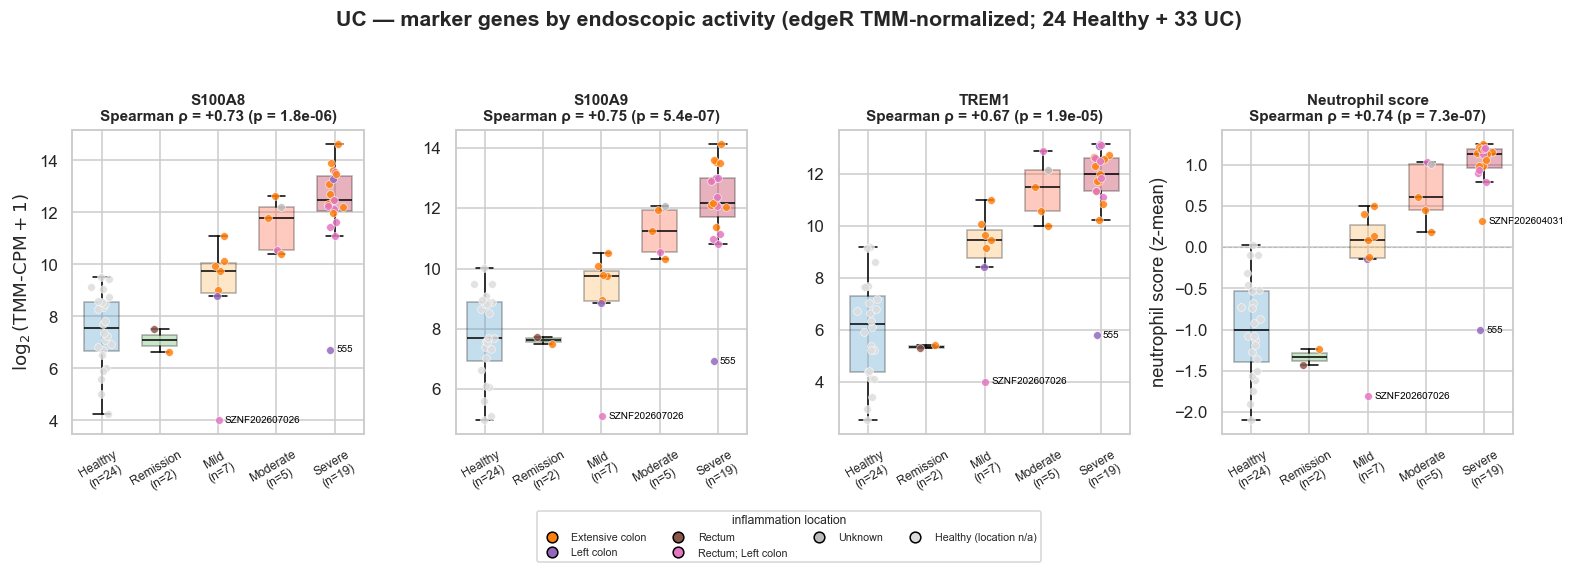

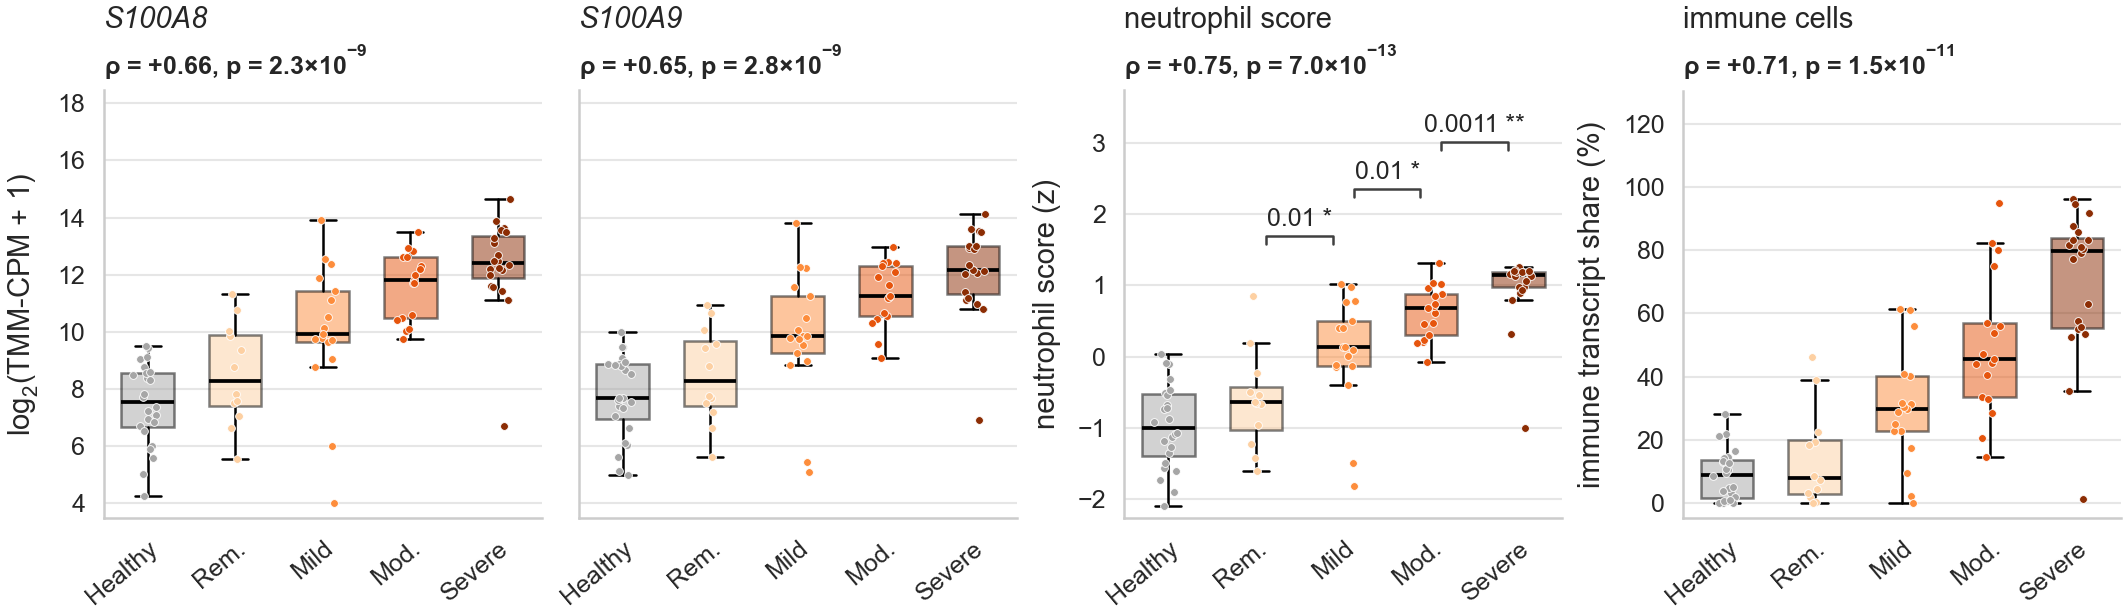

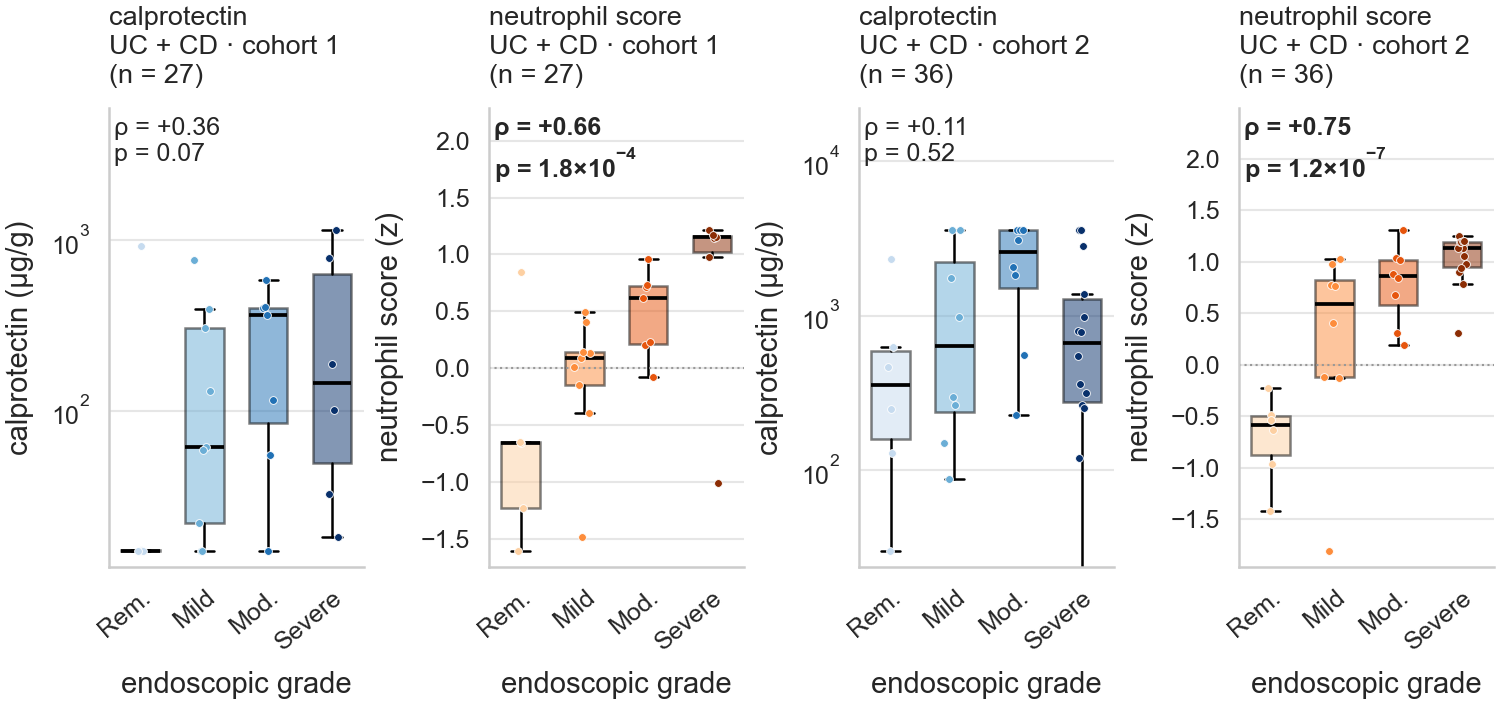

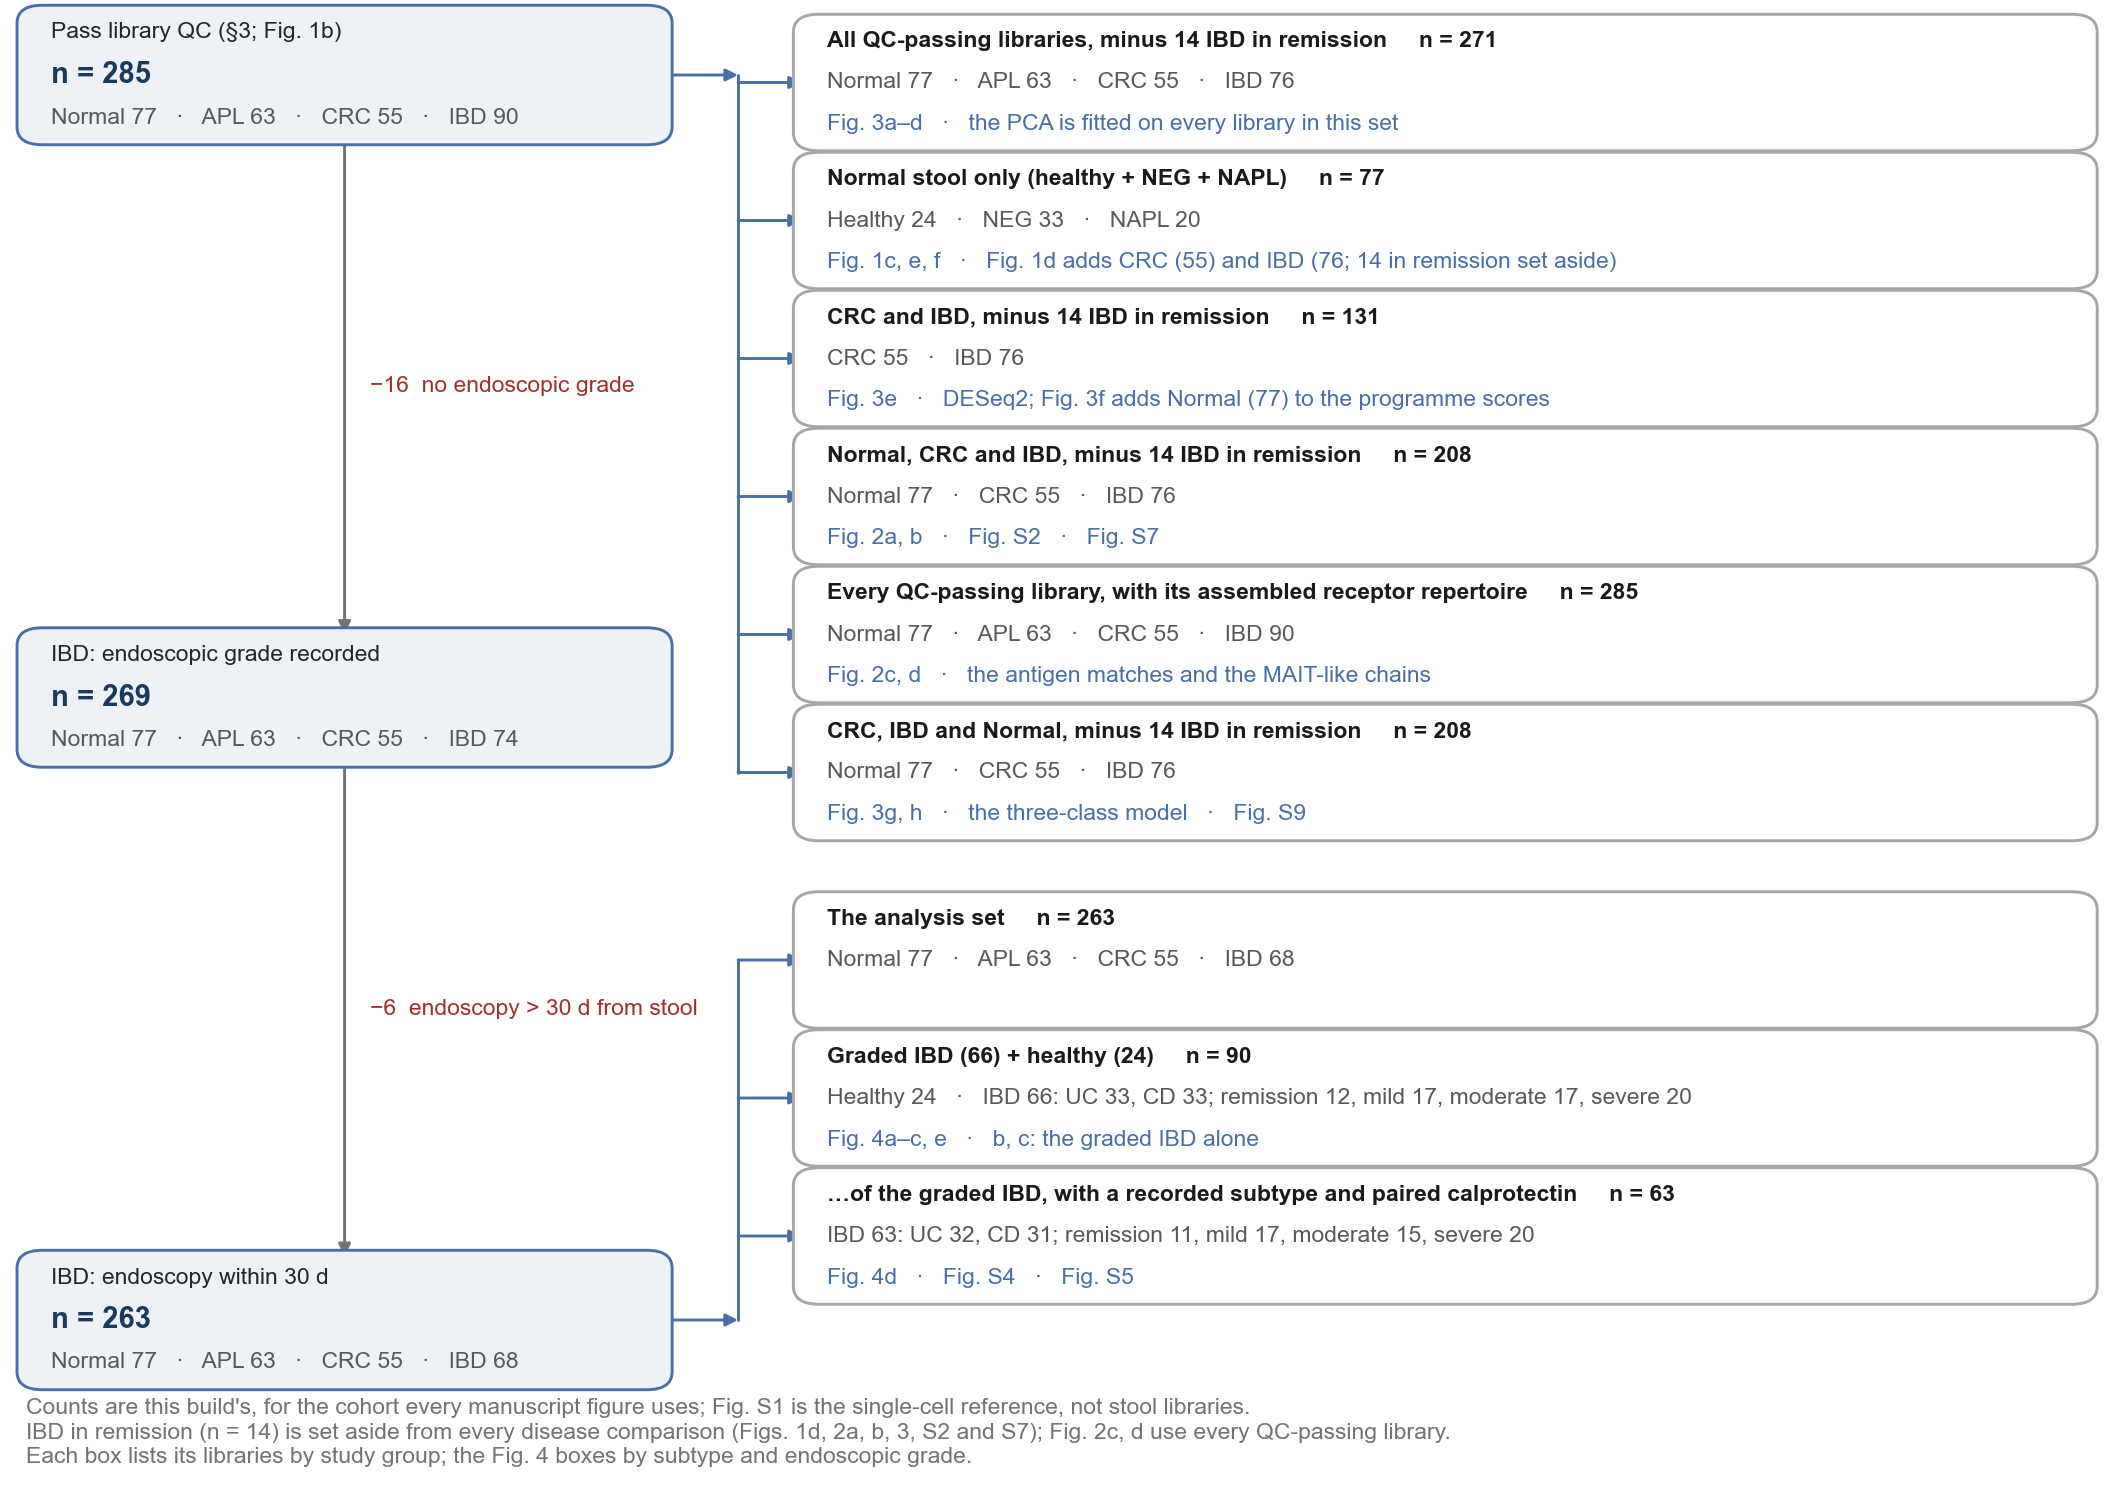

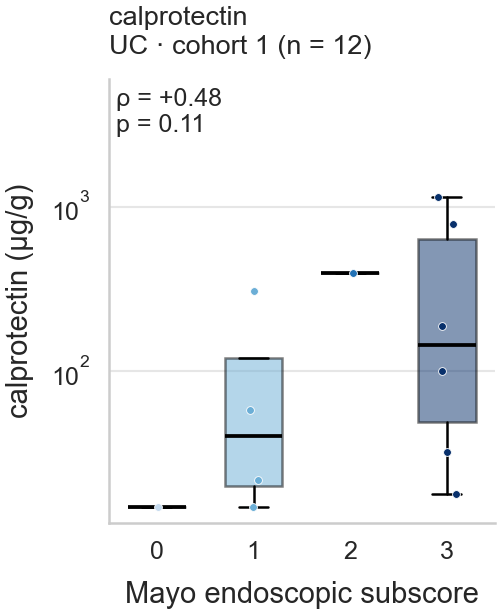

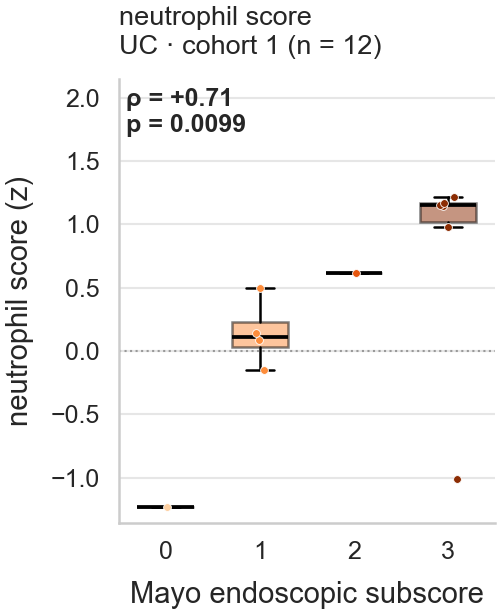

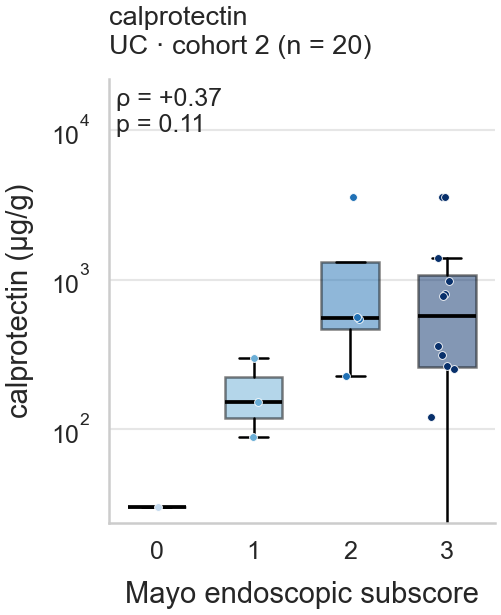

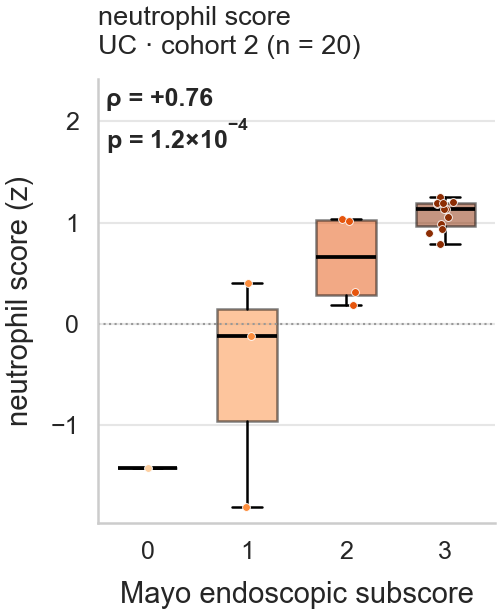

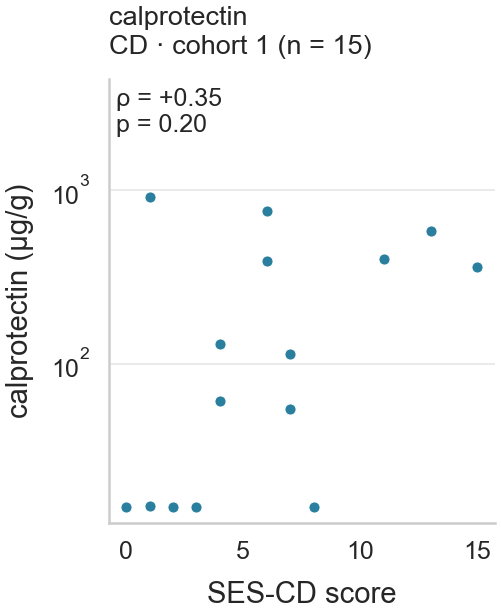

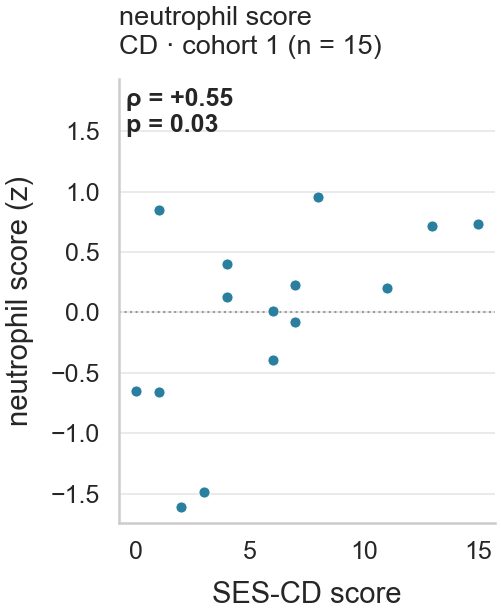

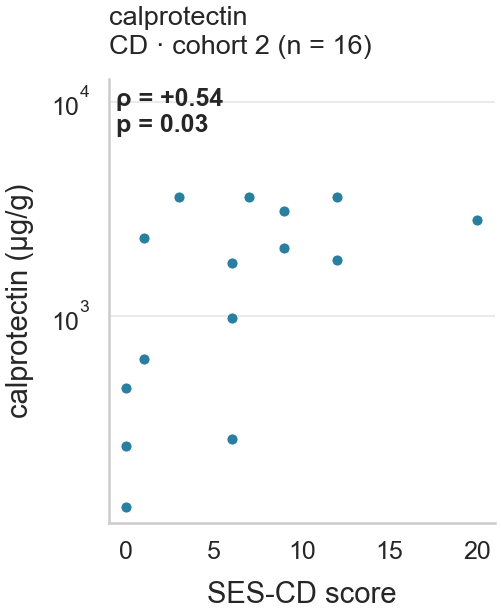

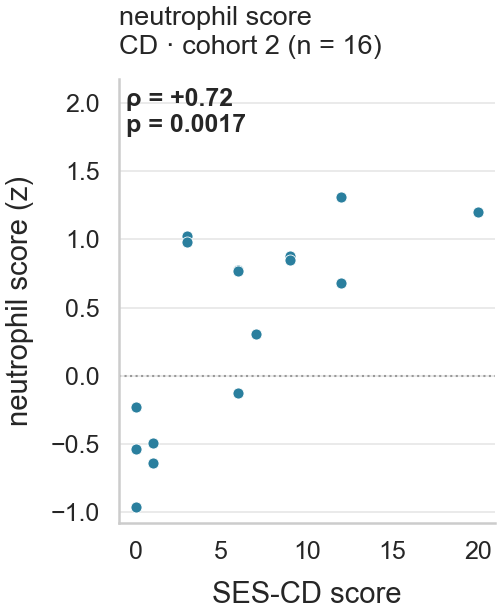

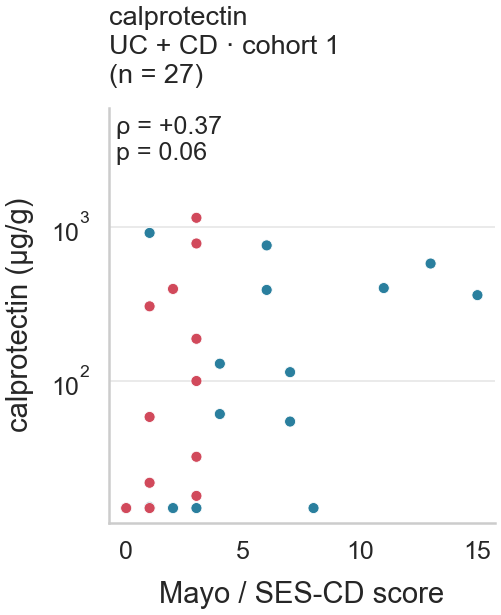

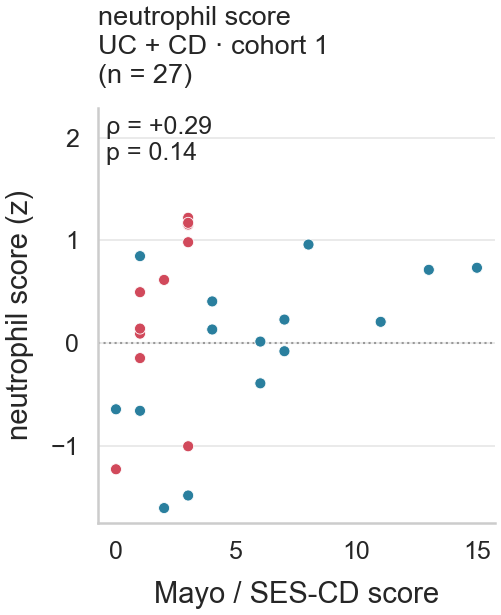

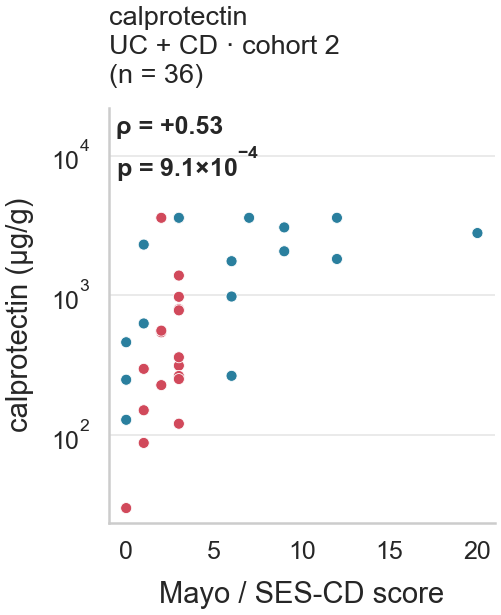

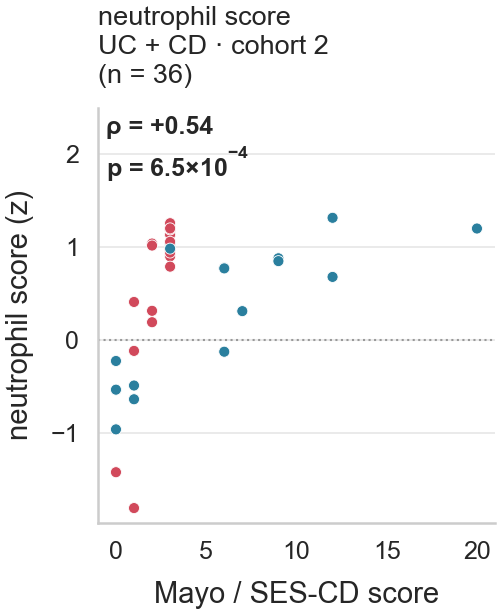

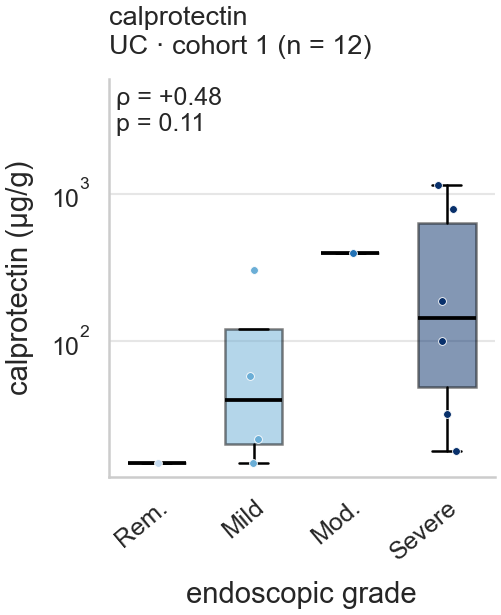

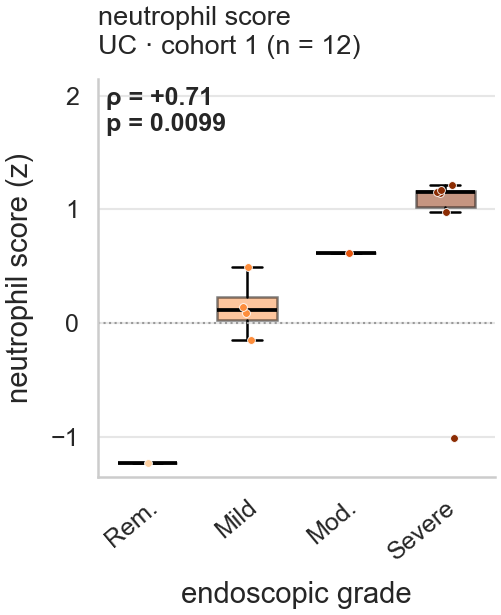

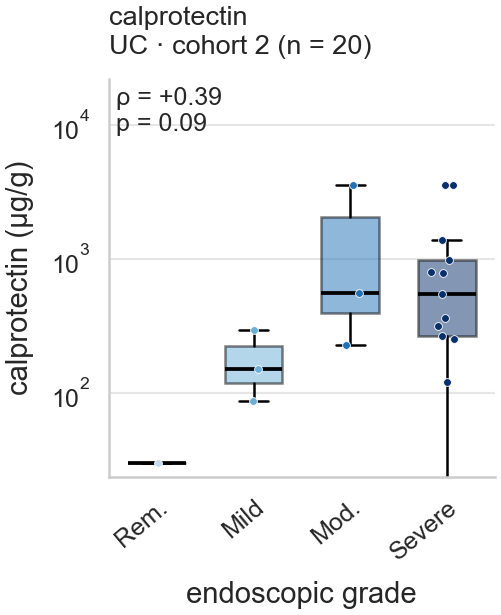

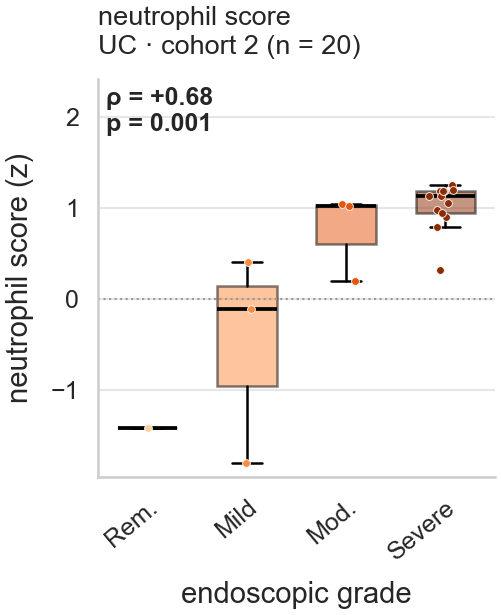

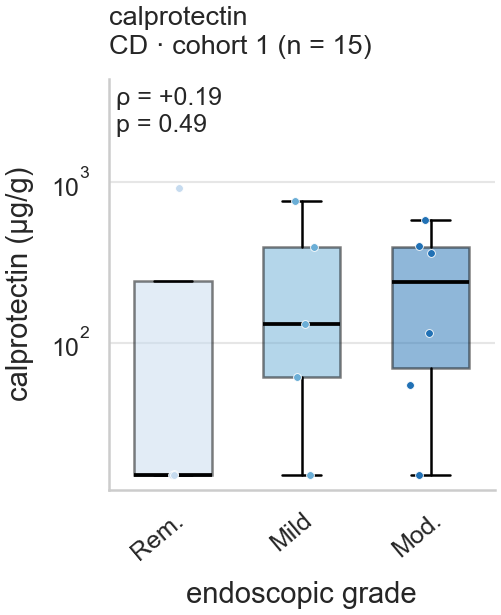

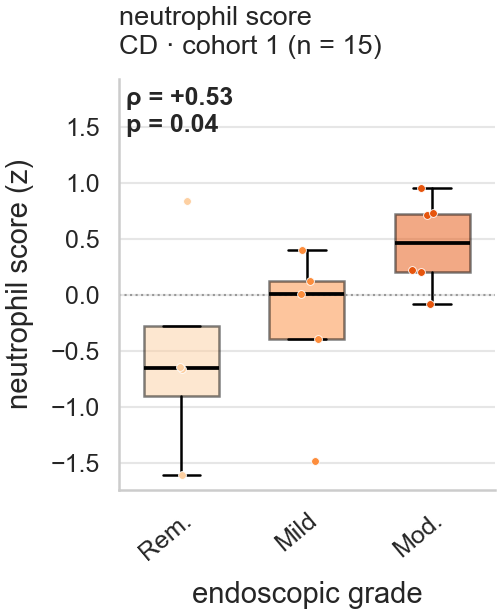

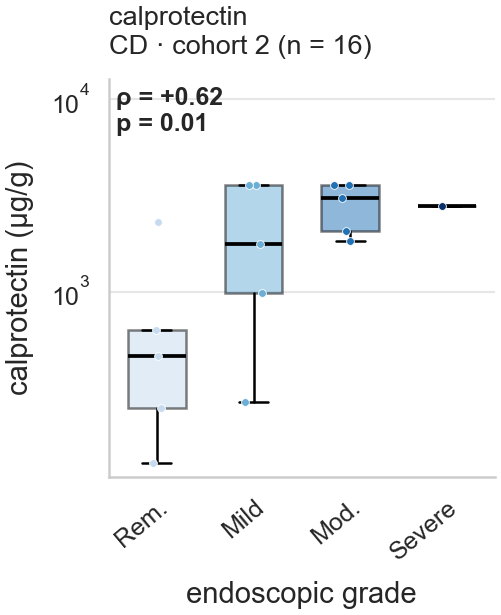

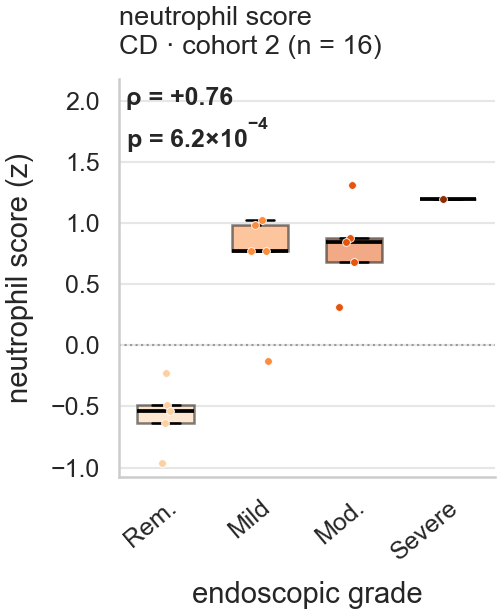

In [40]:
# ----------------------------------------------------------------------------------------------
# [Section 5.1 -- Neutrophil markers on TMM-normalised counts: the monitoring panels]  (notebook cell 62)
# functions from an earlier section: _grade_rho() (Section 5, cell 60); _loc_of() (Section 5,
#     cell 60); _panel_title() (Section 5, cell 60)
# imported in an earlier section: BASE_PT (Section 0, cell 2); box_strip()
#     (Section 0, cell 2); corner_text() (Section 0, cell 2);
#     flow_arrow() (Section 0, cell 2); flow_box() (Section 0, cell 2);
#     grade_boxes() (Section 0, cell 2); headroom() (Section 0, cell 2);
#     Line2D() (matplotlib.lines); panel() (Section 0, cell 2); pstr()
#     (Section 0, cell 2); RC (Section 0, cell 2); save()
#     (Section 0, cell 2); spearman() (Section 0, cell 2); TABLE_DIR
#     (Section 0, cell 2)
# variables from an earlier section: _DM_REMOVED (Section 4, cell 39); _locs (Section 5, cell
#     60); _nref (Section 5, cell 60); ana (Section 3, cell 21); counts (Section 0, cell 2),
#     last set Section 5, cell 63; endo_cols (Section 5, cell 59); ENDO_ORDER (Section 0, cell
#     2), last set Section 5, cell 64; funnel (Section 1, cell 4); grp (Section 2, cell 6), last
#     set Section 5, cell 64; healthy (Section 5, cell 58); HEALTHY_FC (Section 5, cell 60); ibd_rep_ids
#     (Section 3.2, cell 27); loc_col (Section 5, cell 60); lvl
#     (Section 5, cell 58); markers (Section 5, cell 59); meta14 (Section 4.6, cell 55); meta_f
#     (Section 0, cell 2), last set Section 5, cell 63; neut_genes (Section 5, cell 60);
#     NORMAL_GROUPS (Section 0, cell 2), last set Section 2.2, cell 12; pair (Section 4.2, cell
#     43); pcs_all (Section 4.1, cell 41); plot_order (Section 5, cell 58); samples (Section 2,
#     cell 6), last set Section 5, cell 64; fig8, g8_fig and _nf (Section 3.1, cell 24)
# ----------------------------------------------------------------------------------------------
# === §1.3  The marker panels on TMM-normalised counts ===
# The setup cell's TMM-CPM (factors fitted once on the 285 QC-passed libraries), restricted to the
# monitoring set: the 24 healthy-volunteer libraries and the graded IBD libraries inside the
# endoscopy window. TMM adds a per-library composition factor on top of library-size scaling, so a
# rising neutrophil load does not depress every other gene. From 2026-10-07 to 2026-10-16 the
# factors were refitted within these 95 libraries; before that, within every QC-passed IBD,
# healthy and colonoscopy-negative library.
_tmm_cols = pd.Index(healthy + samples)
tmm_cpm = tmmcpm.loc[:, _tmm_cols]
lc_tmm = logtmmcpm.loc[:, _tmm_cols]

_nsub_t = np.log2(tmm_cpm.loc[neut_genes, _nref] + 1)          # neutrophil score from TMM-CPM
nscore_tmm = _nsub_t.sub(_nsub_t.mean(1), axis=0).div(_nsub_t.std(1) + 1e-9, axis=0).mean(0)
PANELS_TMM = [(g, lc_tmm.loc[g], r"$\log_2(\mathrm{TMM\text{-}CPM}+1)$") for g in markers] + \
             [("Neutrophil score", nscore_tmm, "neutrophil score (z-mean)")]

# ==== from scripts/manuscript_figures.py: used only in this cell, so it lives here (moved 2026-10-08) =====
from collections import namedtuple

GRADE_ORDER = ["Healthy", "Remission", "Mild", "Moderate", "Severe"]
# ---- Supplementary Figs. 4 and 5, Fig. 4d: calprotectin vs the stool neutrophil score ---------
# The head-to-head in ulcerative colitis, in Crohn's disease and in the two pooled, against the
# raw endoscopic score (Supplementary Fig. 4) and against the four-level grade band
# (Supplementary Fig. 5; its pooled row is Fig. 4d).
#
# Two things the score axis needs care with. The Mayo subscore runs 0-3 and is very nearly the
# grade band relabelled (Spearman +1.00 within Renji), so for UC the score panels are a
# robustness view. SES-CD runs 0-22, which is genuinely finer, so those panels are drawn as a
# scatter rather than as one box per value. Pooling the two puts Mayo and SES-CD on one x-axis
# even though they score different organs and different lesions: the pooled score panels colour
# points by subtype so that mismatch stays visible, and the legend says not to read across it.
_MES_TO_GRADE = ["Remission", "Mild", "Moderate", "Severe"]      # Mayo endoscopic subscore 0-3
_SUBTYPE_COL = {"UC": "#d1495b", "CD": "#2a7f9e"}
_SCORE_AS_BOXES_MAX = 6          # distinct score values above which a scatter reads better
# What every calprotectin cell reads, passed explicitly: the metadata of the QC-passed libraries
# (`meta_f`), the graded IBD libraries inside the endoscopy window (`samples`), the neutrophil
# score on TMM-normalised counts (`nscore_tmm`, indexed by library) and the grade order. The
# notebook builds it once, in the monitoring section, as `mon`.
Monitoring = namedtuple("Monitoring", ["meta_f", "samples", "nscore_tmm", "endo_order"])
def _calpro_libs(mon, subtype, arm):
    """The libraries behind one Supplementary Fig. 4/5 cell: those with a paired clinical
    calprotectin, of one subtype (`None` pools UC and CD), from one cohort arm."""
    coh = mon.meta_f.loc[mon.samples]
    coh = coh[coh["calprotectin_level"].notna()]
    if subtype is not None:
        coh = coh[coh["ibd_subtype"].astype(str) == subtype]
    else:
        coh = coh[coh["ibd_subtype"].astype(str).isin(["UC", "CD"])]
    if arm is not None:                       # "renji" or "other"; None keeps every cohort
        is_renji = coh["cohort"].astype(str) == "renji"
        coh = coh[is_renji if arm == "renji" else ~is_renji]
    return coh.index.tolist()
def _calpro_metric(mon, libs, metric):
    """The marker plotted on y: clinical calprotectin, or the stool neutrophil score."""
    if metric == "cal":
        return (mon.meta_f.loc[libs, "calprotectin_level"].astype(float),
                "calprotectin (µg/g)", "calprotectin", True)
    return mon.nscore_tmm.reindex(libs), "neutrophil score (z)", "neutrophil score", False
def _calpro_rank(mon, libs, xaxis):
    """What the marker is correlated against: the four-level grade band as a rank
    (Supplementary Fig. 5, Fig. 4d), or the raw endoscopic score (Supplementary Fig. 4)."""
    meta_f = mon.meta_f
    if xaxis == "grade":
        full = list(mon.endo_order)
        grp = meta_f.loc[libs, "endoscopic_activity_grade"].astype(str)
        return grp.map({o: i for i, o in enumerate(full)}).astype(float)
    return meta_f.loc[libs, "endoscopic_activity_score"].astype(float)
def calpro_stats(mon, subtype="UC", metric="cal", xaxis="grade", arm=None):
    """The n, rho and p of one Supplementary Fig. 4/5 panel, without drawing it.

    `calpro_axes` below annotates its panel from this same function, so the text-numbers cell
    and the panels it summarises cannot drift apart -- the table is the figure's own arithmetic,
    not a reading of it."""
    libs = _calpro_libs(mon, subtype, arm)
    s, *_ = _calpro_metric(mon, libs, metric)
    rank = _calpro_rank(mon, libs, xaxis)
    rho, p = spearman(rank.values, np.asarray(s.values, dtype=float))
    return {"n": len(libs), "rho": rho, "p": p}
def calpro_axes(mon, ax, subtype="UC", metric="cal", xaxis="grade", arm=None):
    """One cell of Supplementary Fig. 4 / 5 or Fig. 4d, drawn into `ax`: calprotectin or the
    stool neutrophil score against endoscopic activity, over the libraries of one subtype that
    carry a paired clinical calprotectin. `subtype=None` pools UC and CD."""
    meta_f = mon.meta_f
    libs = _calpro_libs(mon, subtype, arm)
    s, ylab, title, logy = _calpro_metric(mon, libs, metric)

    if logy:
        ax.set_yscale("log")

    if xaxis == "grade":
        grp = meta_f.loc[libs, "endoscopic_activity_grade"].astype(str)
        full = list(mon.endo_order)
        order = [o for o in full if (grp == o).any()]
        values = {o: s.reindex(grp.index[grp == o]).dropna().values for o in order}
        # clinical calprotectin in blues, the stool score in the figure's grade oranges
        box_strip(ax, values, order, CALPRO_PAL if metric == "cal" else GRADE_PAL, s=3.5,
                  n_in_label=False, xrot=40)
        ax.set_xticklabels([t.get_text().replace("Remission", "Rem.").replace("Moderate", "Mod.")
                            for t in ax.get_xticklabels()], rotation=40, ha="right",
                           rotation_mode="anchor")
        xlab = "endoscopic grade"
    else:
        sc = meta_f.loc[libs, "endoscopic_activity_score"].astype(float)
        vals = sorted(sc.dropna().unique())
        if len(vals) <= _SCORE_AS_BOXES_MAX:           # Mayo 0-3: one box per value reads well
            grp = sc.map(lambda v: f"{v:g}" if np.isfinite(v) else "")
            order = [f"{v:g}" for v in vals]
            pal = {f"{v:g}": (CALPRO_PAL if metric == "cal" else GRADE_PAL)[_MES_TO_GRADE[min(int(v), 3)]]
                   for v in vals}
            values = {o: s.reindex(grp.index[grp == o]).dropna().values for o in order}
            box_strip(ax, values, order, pal, s=3.5, n_in_label=False, xrot=0)
        else:                                          # SES-CD 0-22: too many values for boxes
            sub = meta_f.loc[libs, "ibd_subtype"].astype(str)
            colours = [_SUBTYPE_COL.get(v, "0.5") for v in sub] if subtype is None \
                else _SUBTYPE_COL.get(subtype, "0.5")
            ax.scatter(sc.values, np.asarray(s.values, dtype=float), s=7, c=colours,
                       edgecolors="white", linewidths=0.2, zorder=3)
            ax.grid(axis="y", lw=0.4, color="0.9")
            ax.set_axisbelow(True)
        xlab = ("Mayo endoscopic subscore" if subtype == "UC" else
                "SES-CD score" if subtype == "CD" else "Mayo / SES-CD score")

    # one arithmetic path: the panel annotates itself from the function Table 1 reads
    st = calpro_stats(mon, subtype=subtype, metric=metric, xaxis=xaxis, arm=arm)
    rho, p = st["rho"], st["p"]
    ax.set_ylabel(ylab)
    ax.set_xlabel(xlab)
    who = {"UC": "UC", "CD": "CD", None: "UC + CD"}[subtype]
    if arm is not None:
        who += f" · {ARM_LABEL[arm]}"
    # the pooled cohort cells carry the longest line; at Fig. 4d's cell width (1.25 in since
    # 2026-10-16) it overran the axes, so n takes a line of its own there
    _n_txt = f" (n = {len(libs)})" if subtype is not None or arm is None else f"\n(n = {len(libs)})"
    ax.set_title(f"{title}\n{who}{_n_txt}",
                 loc="left", fontweight="normal", fontsize=BASE_PT - 0.5, linespacing=1.25)
    if not logy:
        ax.axhline(0, color="0.6", lw=0.5, ls=":")
    headroom(ax, 0.30)
    corner_text(ax, f"ρ = {rho:+.2f}\n{pstr(p)}", "upper left",
                bold=bool(np.isfinite(p) and p < 0.05))
    return ax
def calpro_panel(mon, name, subtype="UC", metric="cal", xaxis="grade", arm=None):
    """One lettered panel of Supplementary Fig. 4 / 5: a single `calpro_axes` cell."""
    fig, ax = panel(name)
    calpro_axes(mon, ax, subtype=subtype, metric=metric, xaxis=xaxis, arm=arm)
    return save(fig, name)
# Supplementary Fig. 4 is 3 rows x 4, Supplementary Fig. 5 the first two rows: rows are the
# subtype, columns are calprotectin and the neutrophil score for cohort 1 then for cohort 2.
# S4 plots against the raw endoscopic score, S5 against the four-level grade band; they
# are otherwise the same panels.
CALPRO_ROWS = (("uc", "UC"), ("cd", "CD"), ("pooled", None))
# The two recruiting arms of the monitoring cohort, as they are named in every product. Cohort 1
# is Renji Hospital; cohort 2 is Nanfang Hospital. The site names stay in
# the Methods, where the recruitment is described; the figures and tables carry the numbers.
ARM_LABEL = {"renji": "cohort 1", "other": "cohort 2"}
CALPRO_COLS = (("cal", "cal", "renji"), ("nsc", "nsc", "renji"),
               ("cal", "cal", "other"), ("nsc", "nsc", "other"))

# what the calprotectin cells of Fig. 4d and Supplementary Figs. 4-5 read, passed explicitly
mon = Monitoring(meta_f=meta_f, samples=samples, nscore_tmm=nscore_tmm, endo_order=ENDO_ORDER)


def plot_markers_tmm(sub_samples, title):
    grp_s = pd.Series({**{s: "Healthy" for s in healthy}, **{s: lvl[s] for s in sub_samples}})
    locs_present = [l for l in _locs if any(_loc_of(s) == l for s in sub_samples)]
    fig, axes = plt.subplots(1, len(PANELS_TMM), figsize=(14.5, 4.4))
    for pi_, (ax, (pname, pvals, pylab)) in enumerate(zip(axes, PANELS_TMM)):
        np.random.seed(0)
        for i, o in enumerate(plot_order, start=1):
            idx  = grp_s[grp_s == o].index
            vals = pvals.reindex(idx).values
            xj   = np.random.normal(i, 0.07, len(vals))
            fin = np.isfinite(vals)
            if fin.sum() >= 4:
                q1, q3 = np.nanpercentile(vals[fin], [25, 75]); iqr = q3 - q1
                lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
            else:
                lo, hi = -np.inf, np.inf
            for x, y, s in zip(xj, vals, idx):
                if not np.isfinite(y):
                    continue
                fc = HEALTHY_FC if s in healthy else loc_col[_loc_of(s)]
                ax.scatter(x, y, s=26, color=fc, edgecolors="white", linewidths=0.4, alpha=0.85, zorder=4)
                if y < lo or y > hi:
                    ax.annotate(str(meta_f.loc[s, "sample_id"]), (x, y), xytext=(4, 0),
                                textcoords="offset points", fontsize=6.5, color="black",
                                ha="left", va="center", zorder=6)
        present = [(i, o) for i, o in enumerate(plot_order, start=1) if (grp_s == o).sum() > 0]
        pos = [i for i, _ in present]; pres_o = [o for _, o in present]
        box_data = [pvals.reindex(grp_s[grp_s == o].index).values for o in pres_o]
        bp = ax.boxplot(box_data, positions=pos, showfliers=False, patch_artist=True, widths=0.6, zorder=1)
        for patch, o in zip(bp["boxes"], pres_o):
            patch.set_facecolor(endo_cols[o]); patch.set_alpha(0.30)
        for med in bp["medians"]:
            med.set_color("black")
        if pname == "Neutrophil score":
            ax.axhline(0, color="grey", lw=0.7, ls="--", zorder=0)
        ax.set_xticks(range(1, len(plot_order) + 1))
        ax.set_xticklabels([f"{o}\n(n={int((grp_s == o).sum())})" for o in plot_order], fontsize=8, rotation=30)
        ax.set_xlim(0.5, len(plot_order) + 0.5)
        ax.set_title(_panel_title(pname, pvals, sub_samples), fontsize=10, fontweight="bold")
        ax.set_xlabel("")
        if pi_ == 0 or pname == "Neutrophil score":
            ax.set_ylabel(pylab)
    loc_handles = [Line2D([0], [0], marker="o", linestyle="none", markersize=7,
                          markerfacecolor=loc_col[l], markeredgecolor="black", label=l)
                   for l in locs_present]
    loc_handles.append(Line2D([0], [0], marker="o", linestyle="none", markersize=7,
                              markerfacecolor=HEALTHY_FC, markeredgecolor="black", label="Healthy (location n/a)"))
    fig.legend(handles=loc_handles, title="inflammation location", fontsize=7, title_fontsize=8,
               loc="lower center", ncol=min(4, len(loc_handles)), bbox_to_anchor=(0.5, -0.10), frameon=True)
    fig.suptitle(title, fontsize=14, fontweight="bold", y=1.05); fig.tight_layout()
    plt.show()

# shown inline for UC: the per-gene view with each library coloured by its inflammation
# location, which Fig. 4a (both subtypes, no location) does not carry
_uc = [s for s in samples if meta_f.loc[s, "ibd_subtype"] == "UC"]
plot_markers_tmm(_uc, f"UC \u2014 marker genes by endoscopic activity (edgeR TMM-normalized; "
                      f"{len(healthy)} Healthy + {len(_uc)} UC)")


def normal_label(sep=" + "):
    """'healthy + NEG + NAPL', for axis labels and legends."""
    return sep.join("healthy" if g == "Healthy" else g for g in NORMAL_GROUPS)


def _fit_flow_text(fig, ax, floor_frac=0.55):
    """Shrink every flow-box text that is wider than its box, never below `floor_frac` of its
    size. Called once after the layout has run, so the measurement is of the final geometry."""
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    ax_w = ax.get_window_extent(renderer).width
    for t in ax.texts:
        box_w = getattr(t, "box_w", None)
        if box_w is None:
            continue
        avail = box_w * ax_w
        w = t.get_window_extent(renderer).width
        if w > avail:
            t.set_fontsize(max(floor_frac * t.get_fontsize(), t.get_fontsize() * avail / w))


# ==== manuscript panel Fig4a_activity_markers =================================================
# a: S100A8, S100A9 and the 15-gene score against endoscopic activity, TMM-normalised
# (`PANELS_TMM`, this cell), then the immune-cell share of the library (since 2026-10-19; it sat
# between the genes and the score before) -- the C29
# "Immune cells" column of the Fig. 1c, d DWLS deconvolution (`proportions`, cell 10), in per
# cent of transcripts; it took TREM1's place on 2026-10-15 -- on every graded IBD library plus
# the healthy band (`grp`, cell 58); Spearman over the graded libraries alone, via `_grade_rho`.
_imm_row = next(i for i in proportions.index if i.startswith("C29:"))   # "C29: Immune cells (...)"
immune_share = proportions.loc[_imm_row, healthy + samples] * 100        # per cent of transcripts

_pname = "Fig4a_activity_markers"
FIG4A = [("S100A8", "gene"), ("S100A9", "gene"), ("Neutrophil score", "score"), ("Immune share", "share")]
_YLAB = {"gene": "log$_2$(TMM-CPM + 1)", "share": "immune transcript share (%)", "score": "neutrophil score (z)"}
with mpl.rc_context(RC):
    panels = {p[0]: p for p in PANELS_TMM}
    panels["Immune share"] = ("Immune share", immune_share, _YLAB["share"])
    fig, axes = panel(_pname, 1, len(FIG4A))
    axes = np.atleast_1d(axes)
    for ax, (g, kind) in zip(axes, FIG4A):
        _, pvals, _ = panels[g]
        rho, p, _ = _grade_rho(pvals, samples)
        grade_boxes(ax, pvals, grp, GRADE_ORDER, ylabel=_YLAB[kind],
                    title={"gene": g, "share": "immune cells", "score": "neutrophil score"}[kind],
                    rho=rho, p=p, short_labels=True, italic=kind == "gene", point_size=3.5,
                    stat_under_title=True,
                    # the score alone: remission-mild, mild-moderate, moderate-severe
                    adjacent=GRADE_ORDER[1:] if kind == "score" else None)
    # the gene panels are the same quantity on two genes, so they share one axis and one label;
    # the share and the composite score are different units and keep their own
    gene_k = [k for k, (_, kind) in enumerate(FIG4A) if kind == "gene"]
    lo = min(axes[k].get_ylim()[0] for k in gene_k)
    hi = max(axes[k].get_ylim()[1] for k in gene_k)
    for k in gene_k:
        axes[k].set_ylim(lo, hi)
        if k != gene_k[0]:
            axes[k].set_ylabel("")
            axes[k].tick_params(labelleft=False)
    save(fig, _pname)

# ==== manuscript panel Fig4d_calprotectin =====================================================
# d: clinical calprotectin against the stool neutrophil score on the pooled subtypes, one
# cell per marker and recruiting cohort, drawn as one panel. Each cell annotates itself from
# `calpro_stats`, as the text-numbers cell does.
_pname = "Fig4d_calprotectin"
with mpl.rc_context(RC):
    fig, axes = panel(_pname, 1, len(CALPRO_COLS))
    for ax, (_, met, arm) in zip(np.atleast_1d(axes).ravel(), CALPRO_COLS):
        calpro_axes(mon, ax, subtype=None, metric=met, xaxis="grade", arm=arm)
    save(fig, _pname)

# ==== manuscript panel FigS3_sample_flow ======================================================
# Which libraries survive each filter, and which set every figure is drawn on.
#
# The funnel has two parts. The manuscript-side filters (`manuscript_drop_ids`) bite first,
# before any analysis cell runs; the analysis notebook's own QC funnel follows. Both are
# read from the namespace the figures are drawn from -- the drop counts the run actually
# applied, and §3.1's `funnel` -- so a refit moves this diagram with the rest of the paper.
# A step that removes nothing is left out rather than drawn as a zero.
_pname = "FigS3_sample_flow"
with mpl.rc_context(RC):
    f = funnel
    tot = f["Total"].astype(int)
    nb_labels = ["", "With a study group recorded", "Pass library QC (§3; Fig. 1b)",
                 "IBD: endoscopic grade recorded", "IBD: endoscopy within 30 d"]
    nb_reasons = ["", "no study group recorded", "fail library QC (§3)", "no endoscopic grade",
                  "endoscopy > 30 d from stool"]

    # (stage label, n, [(removed, reason) leading into it])
    # The funnel was built from the libraries the manuscript considers (the sequenced total and
    # the manuscript-side exclusions were taken off the diagram on 2026-09-29) and, since
    # 2026-10-21, is drawn from the QC-passed libraries on.
    # every box carries its libraries by study group as a third line (author's request, 2026-10-31)
    _GRP_SHOW = ["Normal", "APL", "CRC", "IBD"]
    def _grp_line(counts, order=_GRP_SHOW, sep="   ·   "):
        """'Normal 77 · APL 63 · CRC 55 · IBD 90' from a {group: n}; zero groups left out."""
        return sep.join(f"{g} {int(counts[g])}" for g in order if g in counts and int(counts[g]))
    stages = [("Libraries considered", int(tot.iloc[0]), [], _grp_line(f.iloc[0]))]
    for i in range(1, len(tot)):
        gone = int(tot.iloc[i - 1] - tot.iloc[i])
        if gone == 0:                       # e.g. the annotated step, once the drop is upstream
            continue
        stages.append((nb_labels[i], int(tot.iloc[i]), [(gone, nb_reasons[i])], _grp_line(f.iloc[i])))
    # The diagram starts at the QC-passed libraries (author's request, 2026-10-21): the
    # "Libraries considered" box and the library-QC step that led into the QC-passed box are not
    # drawn. The QC filter itself is stated in Methods and Fig. 1b.
    _qc0 = next(i for i, (lab, _, _, _) in enumerate(stages) if lab.startswith("Pass library QC"))
    stages = [(stages[_qc0][0], stages[_qc0][1], [], stages[_qc0][3])] + stages[_qc0 + 1:]

    sub = meta_f.loc[samples, "ibd_subtype"].astype(str)
    n_uc, n_cd = int((sub == "UC").sum()), int((sub == "CD").sum())
    n_nosub = len(sub) - n_uc - n_cd            # graded IBD with no subtype recorded
    # Fig. 4b, c are drawn on the repertoire section's graded set (`ibd_rep_ids`, cell 27),
    # Fig. 4a on the monitoring section's `samples` (cell 58). Both are the graded IBD libraries
    # inside the endoscopy window, from one rule (`within_endoscopy_window`); if they ever differ
    # the diagram says so. (Until 2026-10-21 this compared `ibd.index`, which cell 58 had rebound
    # to the monitoring set itself, so the check could never fail.)
    same_set = set(ibd_rep_ids) == set(samples)
    n_cal = sum(calpro_stats(mon, subtype=None, metric="cal", xaxis="grade", arm=a)["n"]
                for a in ("renji", "other"))
    n_graded, n_healthy = len(samples), len(healthy)
    qc_row = next(i for i, (lab, _, _, _) in enumerate(stages) if lab.startswith("Pass library QC"))
    qc_n = stages[qc_row][1]
    qc_normal = int(f.loc[f.index[2], "Normal"])
    qc_crc, qc_ibd = int(f.loc[f.index[2], "CRC"]), int(f.loc[f.index[2], "IBD"])

    # the disease-model section (Fig. 3) is fitted without IBD in remission; the count it
    # set aside is read from the run, not recomputed here
    n_rem = len(_DM_REMOVED)
    rem_note = f", minus {n_rem} IBD in remission" if n_rem else ""
    n_pca = len(pcs_all)
    n_norm_dm = int((meta14["study_group"].astype(str) == "Normal").sum())
    # per-group counts of every set on the right, read from the objects the figures are drawn
    # from, never retyped
    _sg0 = ECB["meta_f"]["study_group"].astype(str)                 # every QC-passed library
    _grp0 = _sg0.where(~_sg0.isin(NORMAL_GROUPS), "Normal")
    _n_qc_by = _grp0.value_counts()
    _n_pca_by = pd.Series(_grp_all).value_counts()
    _n_normal_by = _sg0[_sg0.isin(NORMAL_GROUPS)].value_counts()
    # the three-class model is fitted on CRC, IBD and Normal; `meta14` also carries APL for Fig. 3i
    _n_m14_by = meta14.loc[meta14["study_group"].isin(["CRC", "IBD", "Normal"]), "study_group"].astype(str).value_counts()
    _ibd_grades = lambda ids: _grp_line(meta_f.loc[ids, "endoscopic_activity_grade"].astype(str)
                                        .value_counts(), order=ENDO_ORDER, sep=", ").lower()
    _ibd_subs = lambda ids: _grp_line(meta_f.loc[ids, "ibd_subtype"].astype("object")
                                      .fillna("unrecorded").astype(str).value_counts(),
                                      order=["UC", "CD", "unrecorded"], sep=", ")
    _cal_ids = sum((_calpro_libs(mon, None, a) for a in ("renji", "other")), [])
    from_qc = [
        (f"All QC-passing libraries{rem_note}", n_pca,
         "Fig. 3a–d   ·   the PCA is fitted on every library in this set",
         _grp_line(_n_pca_by)),
        (f"Normal stool only ({normal_label()})", qc_normal,
         f"Fig. 1c, e, f   ·   Fig. 1d adds CRC ({qc_crc}) and IBD ({qc_ibd - n_rem}"
         + (f"; {n_rem} in remission set aside" if n_rem else "") + ")",
         _grp_line(_n_normal_by, order=list(NORMAL_GROUPS))),
        (f"CRC and IBD{rem_note}", len(pair),
         f"Fig. 3e   ·   DESeq2; Fig. 3f adds Normal ({n_norm_dm}) to the programme scores",
         _grp_line({"CRC": len(crc_samples), "IBD": len(ibd_samples)})),
        # Fig. 2a, b, S2 and S7 are drawn on the repertoire section's `fig8` (cell 24): Normal, CRC
        # and the IBD libraries outside endoscopic remission -- the IBD set of Fig. 3a (since
        # 2026-10-31; until then the graded, in-window, active IBD); Fig. 2c, d pool the assembled
        # receptors of every QC-passing library (`ana`, cell 21), remission included
        (f"Normal, CRC and IBD{rem_note}", len(fig8),
         "Fig. 2a, b   ·   Fig. S2   ·   Fig. S7",
         _grp_line({g: int(_nf[g]) for g in g8_fig})),
        ("Every QC-passing library, with its assembled receptor repertoire", len(ana),
         "Fig. 2c, d   ·   the antigen matches and the MAIT-like chains",
         _grp_line(_n_qc_by)),
        (f"CRC, IBD and Normal{rem_note}", int(meta14["study_group"].isin(["CRC", "IBD", "Normal"]).sum()),
         "Fig. 3g, h   ·   the three-class model   ·   Fig. S9",
         _grp_line(_n_m14_by)),
    ]
    subtypes = (f"UC {n_uc}, CD {n_cd}"
                + (f", subtype unrecorded {n_nosub}" if n_nosub else ""))
    from_analysis = [
        ("The analysis set", int(tot.iloc[-1]), "", _grp_line(f.iloc[-1])),
        (f"Graded IBD ({n_graded}) + healthy ({n_healthy})", n_graded + n_healthy,
         f"Fig. 4a{'–c, e' if same_set else ', e'}"
         + ("   ·   b, c: the graded IBD alone" if same_set else ""),
         f"Healthy {n_healthy}   ·   IBD {n_graded}: {subtypes}; {_ibd_grades(samples)}"),
    ]
    if not same_set:
        from_analysis.append(("…of those, with a repertoire", len(ibd_rep_ids), "Fig. 4b, c",
                              f"IBD {len(ibd_rep_ids)}: {_ibd_subs(list(ibd_rep_ids))}; {_ibd_grades(list(ibd_rep_ids))}"))
    from_analysis.append(
        ("…of the graded IBD, with a recorded subtype and paired calprotectin", n_cal,
         "Fig. 4d   ·   Fig. S4   ·   Fig. S5",
         f"IBD {n_cal}: {_ibd_subs(_cal_ids)}; {_ibd_grades(_cal_ids)}"))

    fig, ax = panel(_pname)
    # The diagram is laid out in axes fractions with the axis off, so the axes must be the whole
    # figure. Under constrained layout they were not: any text that overhung the axes made the
    # engine shrink the axes to fit it, which pushed more text over the edge, and the cascade
    # could leave the axes a fraction of the figure wide with every label printed over its
    # neighbour.
    fig.set_layout_engine("none")
    ax.set_position([0.0, 0.0, 1.0, 1.0])
    ax.set_axis_off()
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    BOX, SET = "#eef2f7", "#ffffff"
    small = BASE_PT - 1.5

    n_stage = len(stages)
    fw, fh, fx = 0.30, 0.085, 0.012
    top, bot = 0.95, 0.12
    ys = [top - k * (top - bot) / max(n_stage - 1, 1) for k in range(n_stage)]
    for i, ((lab, n, into, groups), y) in enumerate(zip(stages, ys)):
        flow_box(ax, fx, y, fw, fh,
                  [(lab, False, small, "0.15"), (f"n = {n}", True, BASE_PT, "#1a3a5c"),
                   (groups, False, small, "0.35")],
                  fc=BOX, ec="#4a6fa5")
        if i:
            flow_arrow(ax, (fx + fw / 2, ys[i - 1] - fh / 2), (fx + fw / 2, y + fh / 2))
            mid = (ys[i - 1] + y) / 2
            # one line of type, in axes fractions: a fixed 0.018 overlaps as soon as the figure
            # is drawn at a larger type size, where a line is taller than that
            line = 1.35 * (small / 72) / fig.get_size_inches()[1]
            # the labels sit between the arrow and the right-hand column. At print size they fit;
            # drawn at a larger type size they would run into the column, so each
            # is measured after a real draw (constrained layout must have run, or the axes extent
            # is the pre-layout guess) and shrunk to the room it has -- never wrapped, and never
            # below 60% of the body size. A no-op wherever the label already fits.
            label_x, col_x = fx + fw / 2 + 0.012, fx + fw + 0.065
            fig.canvas.draw()
            renderer = fig.canvas.get_renderer()
            avail_px = (col_x - label_x - 0.006) * ax.get_window_extent(renderer).width
            span = line * (len(into) - 1)
            for j, (k, reason) in enumerate(into):
                t = ax.text(label_x, mid + span / 2 - j * line, f"−{k}  {reason}",
                            transform=ax.transAxes, ha="left", va="center", fontsize=small,
                            color="#a03030")
                w_px = t.get_window_extent(renderer).width
                if w_px > avail_px:
                    t.set_fontsize(max(0.6 * small, small * avail_px / w_px))

    def bus(src_y, boxes, y_top, y_step):
        bx = fx + fw + 0.035
        ys_b = [y_top - k * y_step for k in range(len(boxes))]
        flow_arrow(ax, (fx + fw, src_y), (bx, src_y), colour="#4a6fa5")
        ax.plot([bx, bx], [min(min(ys_b), src_y), max(max(ys_b), src_y)],
                transform=ax.transAxes, color="#4a6fa5", lw=0.7, zorder=1)
        for (title, n, figs, groups), yb in zip(boxes, ys_b):
            flow_arrow(ax, (bx, yb), (bx + 0.03, yb), colour="#4a6fa5")
            flow_box(ax, bx + 0.03, yb, 0.605, 0.083,
                      [(f"{title}     n = {n}", True, small, "0.1"),
                       (groups, False, small, "0.35"),
                       (figs, False, small, "#4a6fa5")], fc=SET, ec="0.65")

    # six boxes on the upper bus since 2026-10-21 (the Fig. 2 set was split in two), so the step
    # tightened from 0.095 and the lower bus moved down from 0.40 to keep clear of it
    bus(ys[qc_row], from_qc, 0.945, 0.092)
    bus(ys[-1], from_analysis, 0.36, 0.092)
    _fit_flow_text(fig, ax)
    ax.text(fx, 0.045, "Counts are this build's, for the cohort every manuscript figure uses; "
                       "Fig. S1 is the single-cell reference, not stool libraries."
                       + (f"\nIBD in remission (n = {n_rem}) is set aside from every disease "
                          "comparison (Figs. 1d, 2a, b, 3, S2 and S7); Fig. 2c, d use every QC-passing library."
                          "\nEach box lists its libraries by study group; the Fig. 4 boxes by subtype and endoscopic grade."
                          if n_rem else ""),
            transform=ax.transAxes, ha="left", va="center", fontsize=small, color="0.45",
            linespacing=1.3)
    save(fig, _pname)

# ==== Supplementary Figs. 4 and 5: calprotectin against the neutrophil score, cell by cell ======
# Twelve panels (S4, raw endoscopic score on x) and eight (S5, grade band): subtype x cohort arm
# x marker. One shared drawing function, calpro_panel, bound to each cell's arguments; it stays
# in the setup cell because it is called twenty times here and once for Fig. 4d.
for _fig, _xaxis, _rows in (("FigS4", "score", CALPRO_ROWS), ("FigS5", "grade", CALPRO_ROWS[:2])):
    _i = 0
    for _sub_key, _sub in _rows:
        for _met_key, _met, _arm in CALPRO_COLS:
            with mpl.rc_context(RC):
                calpro_panel(mon, name=f"{_fig}{'abcdefghijkl'[_i]}_{_met_key}_{_sub_key}_{_arm}_{_xaxis}",
                             subtype=_sub, metric=_met, xaxis=_xaxis, arm=_arm)
            _i += 1


### Grading activity from the neutrophil score

> **Manuscript output —** Fig. 4e.


Fig. 4e -- activity classifier on the neutrophil score, 90 libraries (healthy + remission 36, active 54), 10 x grouped 5-fold CV; AUC with its 95% bootstrap interval over libraries:
  the score itself, no model: AUC 0.931 active vs healthy + remission
  active vs healthy + remission: AUC 0.924 (0.86–0.98); sensitivity 0.87 at 90% specificity; at the call sensitivity 0.88, specificity 0.88


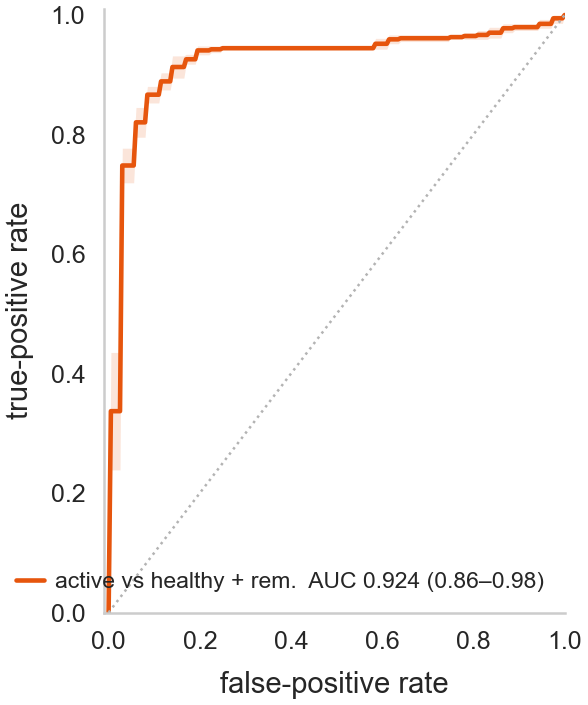

In [41]:
# ----------------------------------------------------------------------------------------------
# [Section 5.2 -- Grading activity from the neutrophil score]  (notebook cell 64)
# functions from an earlier section: _grade_rho() (Section 5, cell 60)
# imported in an earlier section: boot_ci() (Section 0, cell 2); ci_text()
#     (Section 0, cell 2); classifier_pipe() (scripts/manuscript_figures.py, as
#     _pipe in cell 55); GRADE_PAL (Section 0, cell 2); panel()
#     (Section 0, cell 2); rank_auc() (Section 0, cell 2); RC
#     (Section 0, cell 2); roc_curve() (sklearn.metrics); roc_with_confusion()
#     (Section 0, cell 2); save() (Section 0, cell 2);
#     StratifiedGroupKFold() (sklearn.model_selection); 
# variables from an earlier section: grp (Section 5, cell 58); healthy (Section 5, cell 58);
#     meta_f (Section 0, cell 2), last set Section 5, cell 57; N_REPEATS (Section 4.6, cell 55);
#     nscore_tmm (Section 5.1, cell 62); samples (Section 5, cell 58)
# ----------------------------------------------------------------------------------------------
# === §1.4  Grading activity from the neutrophil score ===
# (e) Whether activity can be called from the 15-gene neutrophil score of (a) alone
# (`nscore_tmm`, cell 62: TMM-CPM standardised over these 95 libraries). One model separates
# active disease (mild, moderate, severe) from the quiescent gut -- the healthy band and remission
# together, as the negatives -- by the Fig. 3g pipeline (`classifier_pipe`) on the one feature,
# where it reduces to standardisation and L2 logistic regression with balanced class weights;
# 5-fold CV stratified by class and grouped by stool sample, N_REPEATS fold assignments. The score
# itself is rank-equivalent to the model within a fold, so the AUC is essentially the score's own;
# the cross-validation is what makes the call and its sensitivity out of fold. Added 2026-10-15.
# Until 2026-10-21 a second stage (moderate + severe vs mild, on the active libraries) and the
# three-class call the two made together were fitted here and written as Supplementary Table 3;
# both left the manuscript with that table.
from sklearn.metrics import roc_curve
from sklearn.model_selection import StratifiedGroupKFold

# ---- (e) the activity classifier -----------------------------------------------------------
act_libs = healthy + samples                           # the 95 libraries of (a): the healthy band and the graded IBD
X_act = nscore_tmm.reindex(act_libs).values.astype(float)[:, None]   # one feature: the neutrophil score
g_act = meta_f.loc[act_libs, "sample_id"].astype(str).values
grade_act = grp.reindex(act_libs).astype(str).values                 # "Healthy" or the grade
y_act = np.isin(grade_act, ["Mild", "Moderate", "Severe"]).astype(int)   # active (1) vs healthy + remission (0)
_remiss = np.flatnonzero(y_act == 0)

p_act = np.full((N_REPEATS, len(act_libs)), np.nan)   # out-of-fold P(active)
for _rep in range(N_REPEATS):
    _cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=_rep)
    for _tr, _te in _cv.split(X_act, y_act, g_act):
        _m = classifier_pipe().fit(X_act[_tr], y_act[_tr])
        p_act[_rep, _te] = _m.predict_proba(X_act[_te])[:, 1]


def _sens_at_spec(score_pos, score_neg, spec=0.90):
    """Fraction of positives above the threshold that leaves `spec` of the negatives below it."""
    return float((score_pos > np.quantile(score_neg, spec)).mean())


# AUC, sensitivity at 90% specificity and sensitivity / specificity at the 0.5 call, each as the
# mean over the fold assignments; the AUC's 95% bootstrap interval over libraries resampled
# within grade.
auc_act = float(np.mean([rank_auc(y_act == 1, p_act[r]) for r in range(N_REPEATS)]))
sens90_act = float(np.mean([_sens_at_spec(p_act[r][y_act == 1], p_act[r][y_act == 0]) for r in range(N_REPEATS)]))
sens_call_act = float(np.mean([(p_act[r][y_act == 1] >= 0.5).mean() for r in range(N_REPEATS)]))
spec_call_act = float(np.mean([(p_act[r][y_act == 0] < 0.5).mean() for r in range(N_REPEATS)]))
_lo_act, _hi_act = boot_ci(lambda idx: np.mean([rank_auc(y_act[idx] == 1, p_act[r][idx]) for r in range(N_REPEATS)]),
                           grade_act)       # resampled within each grade
_lo_act, _hi_act = float(_lo_act), float(_hi_act)

print(f"Fig. 4e -- activity classifier on the neutrophil score, {len(act_libs)} libraries "
      f"(healthy + remission {len(_remiss)}, active {int(y_act.sum())}), "
      f"{N_REPEATS} x grouped 5-fold CV; AUC with its 95% bootstrap interval over libraries:")
print(f"  the score itself, no model: AUC {rank_auc(y_act == 1, X_act[:, 0]):.3f} active vs healthy + remission")
print(f"  active vs healthy + remission: AUC {ci_text(auc_act, _lo_act, _hi_act)}; "
      f"sensitivity {sens90_act:.2f} at 90% specificity; at the call sensitivity {sens_call_act:.2f}, "
      f"specificity {spec_call_act:.2f}")

# ==== manuscript panel Fig4e_activity_roc =====================================================
# e: ROC of the model on the neutrophil score, mean over the fold assignments with ± 1 s.d. band,
# as Fig. 3h; AUC with its bootstrap interval (this cell).
_pname = "Fig4e_activity_roc"
with mpl.rc_context(RC):
    grid = np.linspace(0, 1, 201)
    curves = []
    for _k, (_lab, _truth, _score, _col) in enumerate(
            [("active vs healthy + rem.", y_act == 1, p_act, GRADE_PAL["Moderate"])]):
        tprs = []
        for r in range(N_REPEATS):
            fpr, tpr, _ = roc_curve(_truth.astype(int), _score[r])
            t = np.interp(grid, fpr, tpr)
            t[0] = 0
            tprs.append(t)
        curves.append(dict(label=_lab, grid=grid, mean=np.mean(tprs, axis=0), sd=np.std(tprs, axis=0),
                           auc=auc_act, ci=(_lo_act, _hi_act), colour=_col))
    fig, ax = panel(_pname)
    roc_with_confusion(ax, curves, inset=False)
    save(fig, _pname)

---
# Numbers quoted in the text

Every number the manuscript's Results, Discussion and Methods quote that is not printed on a figure panel, computed from the objects the figures are drawn from and printed as one table (also written to `results/manuscript/tables/text_numbers.csv`). Added 2026-10-26 so the prose can be checked against the build.

> **Manuscript output —** none; the table is for checking the text.

In [42]:
# ----------------------------------------------------------------------------------------------
# [Section 6 -- Numbers quoted in the text]  (notebook cell 66)
# variables from earlier sections: meta, meta_f, D (Section 0); qc_passing_metric (Section 1);
#     cluster_id, cell_types, _D, LINEAGE_MERGES, cluster_members (Section 2); keep_clusters,
#     all_cluster_names, marker_pool, proportions (Section 2.1); stack (Section 2.2); clono, prod,
#     ana (Section 3); fig8 (Section 3.1); ref, _mait, _tra, MAIT_V (Section 3.3); pcs_all,
#     ve_all, _auc, _grp_all, _dis_pc, _dis_pc2, PC3D, _neut_all (Section 4.1); pair, _DM_REMOVED,
#     meta14 (Section 4); de, n_crc, n_ibd, PROGRAMS (Section 4.4); meanC, ciC, cmC, accCons,
#     ciCons, yC, CLS, called_normal, aucW, _loW, _hiW, sensW, _genesW, yW (Section 4.5); samples, healthy, mon,
#     calpro_stats, immune_share, grp (Section 5); y_act, auc_act, _lo_act, _hi_act, sens90_act
#     (Section 5.2)
# ----------------------------------------------------------------------------------------------
# Every number the manuscript text quotes that is not printed on a figure panel, computed here
# from the objects the figures are drawn from, so the prose can be checked against the build
# rather than against a remembered value. One row per quantity: where the text says it, what it
# is, the value this run gives. Written to results/manuscript/tables/text_numbers.csv as well.
import re as _re
from scipy.stats import spearmanr as _spearmanr

_rows = []
def _add(section, item, value, note=""):
    _rows.append({"section": section, "item": item, "value": value, "note": note})

def _fmt(x, nd=2):
    return f"{x:.{nd}f}" if isinstance(x, float) else str(x)

# ---- Results: QC of the libraries (Fig. 1b marks the medians but prints no number) -----------
for _col, _lab, _scale, _nd in (("DetCodGenes_30", "median protein-coding genes detected (>= 10 counts, MAPQ >= 30)", 1, 0),
                                ("InterRate_30", "median intergenic rate (%)", 100, 1),
                                ("MapRate", "median mapping rate (%)", 100, 0),
                                ("CDSTags_30", "median unique CDS-exon tags (millions)", 1e-6, 1)):
    _v = qc_passing_metric(meta, _col) * _scale
    _add("Results: QC", _lab, _fmt(float(np.nanmedian(_v)), _nd), f"over {int(np.isfinite(_v).sum())} QC-passed libraries")
_reads = pd.to_numeric(meta_f["ClnLibSize"], errors="coerce")
_add("Methods: sequencing", "clean reads per library, median (range), millions",
     f"{_reads.median():.0f} ({_reads.min():.0f}-{_reads.max():.0f})", "ClnLibSize is in millions")

# ---- Results / Methods: the cohort ---------------------------------------------------------
_sg = meta_f["study_group"].astype(str)
_add("Results: cohort", "QC-passed libraries in the analysis", len(meta_f))
for _g in ["Healthy", "NEG", "NAPL", "APL", "CRC", "IBD"]:
    _add("Results: cohort", f"{_g} libraries", int((_sg == _g).sum()))
_add("Results: cohort", "Normal = Healthy + NEG + NAPL", int(_sg.isin(NORMAL_GROUPS).sum()))
_coh = meta_f["cohort"].astype(str)
for _c in sorted(_coh[_sg == "IBD"].unique()):
    _add("Methods: recruitment", f"IBD libraries from {_c}", int(((_sg == "IBD") & (_coh == _c)).sum()))
_stage = D["clin"]["stage"].reindex(meta_f.loc[_sg == "CRC", "sample_id"].values).fillna("Unknown").astype(str)
for _lvl in ["Stage I", "Stage II", "Stage III", "Stage IV", "Unknown"]:
    _add("Results: cohort", f"CRC {_lvl}", int((_stage == _lvl).sum()))
_sub = meta_f.loc[_sg == "IBD", "ibd_subtype"].astype("object").fillna("not recorded").astype(str)
for _s in ["UC", "CD", "not recorded"]:
    _add("Results: cohort", f"IBD subtype {_s}", int((_sub == _s).sum()))
_add("Methods: cohort", "IBD in endoscopic remission (set aside from between-diagnosis comparisons)", len(_DM_REMOVED))
_ibd = meta_f[_sg == "IBD"]
_has_grade = _ibd["endoscopic_activity_grade"].astype("object").isin(ENDO_ORDER)
_in_win = within_endoscopy_window(_ibd["sample_id"], D["clin"])
_add("Methods: activity set", "IBD libraries without a recorded grade", int((~_has_grade).sum()))
_add("Methods: activity set", "graded IBD with the endoscopy outside the 30-day window", int((_has_grade & ~_in_win).sum()))
_add("Methods: activity set", "graded IBD within 30 days (the activity-monitoring set)", len(samples))
_gs = meta_f.loc[samples, "ibd_subtype"].astype("object").fillna("not recorded").astype(str)
for _s in ["UC", "CD", "not recorded"]:
    _add("Results: activity", f"activity set, {_s}", int((_gs == _s).sum()))
_gg = meta_f.loc[samples, "endoscopic_activity_grade"].astype(str)
for _o in ENDO_ORDER:
    _add("Results: activity", f"activity set, {_o.lower()}", int((_gg == _o).sum()))
_ct = pd.crosstab(_gs, _gg)
for _s in ("UC", "CD"):
    if _s in _ct.index:
        _add("Discussion: limitations", f"{_s} libraries graded severe", f"{int(_ct.loc[_s].get('Severe', 0))} of {int(_ct.loc[_s].sum())}")
_add("Results: activity", "healthy-volunteer reference libraries", len(healthy))

# ---- Results: composition (Fig. 1c prints shares; Fig. 1d does not) --------------------------
_comp = stack if "Normal" in getattr(stack, "columns", []) else None
if _comp is not None:
    def _share(group, key):
        _r = [i for i in _comp.index if key.lower() in str(i).lower()]
        return 100 * float(_comp.loc[_r, group].sum()) if _r else float("nan")
    for _key, _lab in (("Columnar", "columnar GI epithelium"), ("Immune", "immune cells"), ("Squamous", "squamous epithelium")):
        _add("Results: composition", f"mean share in Normal stool, {_lab} (%)", _fmt(_share("Normal", _key), 1))
    for _g in ("CRC", "IBD"):
        if _g in _comp.columns:
            _add("Results: composition", f"mean immune-cell share in {_g} (%)", _fmt(_share(_g, "Immune"), 1))
_ish = immune_share.groupby(grp.reindex(immune_share.index)).median()
for _o in ["Healthy"] + ENDO_ORDER:
    if _o in _ish.index:
        _add("Discussion: monitoring", f"median immune-cell share, {_o.lower()} (%)", _fmt(float(_ish[_o]), 0))

# ---- Results: repertoire -------------------------------------------------------------------
_cl = clono[clono["library"].isin(ana.index)]
_add("Methods: repertoire", "clonotypes assembled in the QC-passed libraries", len(_cl))
_add("Methods: repertoire", "of which productive", f"{len(prod)} ({100 * len(prod) / len(_cl):.0f}%)")
_add("Results: repertoire", "libraries in Fig. 2a, b (Normal, CRC, IBD outside remission)", len(fig8))
_ref = globals().get("ref", globals().get("_ref"))
_add("Methods: repertoire", "reference records searched (VDJdb + IEDB + CoV-AbDab)", f"{len(_ref):,}" if _ref is not None else "n/a (reference table is local to the matching function)")
_add("Results: repertoire", "MAIT-like TRA chains", f"{len(_mait)} of {len(_tra)}")
_add("Results: repertoire", "of which on TRAV1-2", int((_mait["V"] == MAIT_V).sum()))
if "_n_tcr" in globals() and "_n_bcr" in globals():
    _add("Results: repertoire", "CDR3s matching a database record, TCR / BCR", f"{_n_tcr} / {_n_bcr}", "also printed on Fig. 2c")

# ---- Results: PCA (Fig. 3a-c print variance shares and rho; the AUCs are not drawn) ----------
_add("Results: PCA", "libraries in the decomposition", len(pcs_all), ", ".join(f"{g} {n}" for g, n in _grp_all.value_counts().items()))
_add("Results: PCA", "PC1 variance explained (%)", _fmt(100 * float(ve_all[0]), 0))
# the single-component AUC table of Section 4.1 (`_auc` there is rebound by a later cell, so it is
# recomputed here with the same rule: the larger of AUC and 1 - AUC)
from sklearn.metrics import roc_auc_score as _roc_auc
def _pc_auc(a, b, pc):
    _x, _y = pcs_all[pc][(_grp_all == a).values], pcs_all[pc][(_grp_all == b).values]
    _r = _roc_auc(np.r_[np.ones(len(_x)), np.zeros(len(_y))], np.r_[_x, _y])
    return max(_r, 1 - _r)
for _c in (("CRC", "Normal"), ("IBD", "Normal")):
    _add("Results: PCA", f"PC1 single-component AUC, {_c[0]} vs {_c[1]}", _fmt(_pc_auc(*_c, "PC1")))
_add("Results: PCA", f"best CRC-vs-IBD component ({_dis_pc}) AUC", _fmt(_pc_auc("CRC", "IBD", _dis_pc)))
_add("Results: PCA", f"second CRC-vs-IBD component ({_dis_pc2}) AUC", _fmt(_pc_auc("CRC", "IBD", _dis_pc2)), "drawn only in the 3d view" if len(PC3D) == 2 else "")
_add("Results: PCA", "Spearman rho of the neutrophil score with PC1", _fmt(float(_spearmanr(pcs_all["PC1"], _neut_all.reindex(pcs_all.index), nan_policy="omit")[0])))

# ---- Results / Methods: differential expression and programmes --------------------------------
_pg = meta14.loc[pair.index, "study_group"].astype(str).value_counts()
_add("Methods: DE", "libraries in the CRC-vs-IBD contrast", f"{len(pair)} (" + ", ".join(f"{g} {int(n)}" for g, n in _pg.items()) + ")")
_add("Methods: DE", "genes tested after the low-count filter", f"{len(de):,}")
_n_up_crc, _n_up_ibd = n_crc, n_ibd   # Section 4.4 counts them from the contrast with CRC as the reference level
_add("Results: DE", "genes higher in CRC / higher in IBD (padj < 0.05, |log2FC| > 1)", f"{_n_up_crc} / {_n_up_ibd}", "also printed on Fig. 3e")
for _name, _genes in PROGRAMS.items():
    _add("Methods: programmes", f"{_name}: member genes", len(_genes))

# ---- Results: classifiers --------------------------------------------------------------------
_add("Results: three-class model", "libraries", f"{len(yC)} (" + ", ".join(f"{c} {int((yC == c).sum())}" for c in CLS) + ")")
_add("Results: three-class model", "out-of-fold accuracy of the consensus calls (95% bootstrap CI over libraries)", f"{accCons:.3f} ({ciCons[0]:.2f}\u2013{ciCons[1]:.2f})", "also the Fig. 3g title; mean per-assignment accuracy " + _fmt(float(meanC["accuracy"]), 3))
_add("Results: three-class model", "macro-average one-vs-rest AUC", _fmt(float(np.mean([meanC[f'AUC {c}'] for c in CLS])), 3))
for _i, _c in enumerate(CLS):
    if _c != "Normal":
        _add("Results: three-class model", f"{_c} libraries called Normal (%)", _fmt(100 * float(cmC[_i][CLS.index('Normal')] / cmC[_i].sum()), 0))
_t3 = called_normal
_crc3 = _t3[_t3["group"] == "CRC"].set_index("level")["libraries called Normal (consensus call)"]
_ibd3 = _t3[_t3["group"] == "IBD"].set_index("level")["libraries called Normal (consensus call)"]
_add("Results: three-class model", "CRC called Normal: stage I or II of total", f"{int(_crc3.get('Stage I', 0) + _crc3.get('Stage II', 0))} of {int(_crc3.sum())}", f"stage IV {int(_crc3.get('Stage IV', 0))}")
_add("Results: three-class model", "IBD called Normal: mild of total", f"{int(_ibd3.get('Mild', 0))} of {int(_ibd3.sum())}")
_add("Results: Welch model", "cases (CRC + APL) vs Normal", f"{int(yW.sum())} vs {int((yW == 0).sum())}")
for _i, _c in enumerate(("CRC", "APL")):
    _add("Results: Welch model", f"{_c} vs Normal: sensitivity at 90% specificity (%)", _fmt(100 * float(sensW[_c]), 0), f"AUC {aucW[_i]:.3f} ({_loW[_i]:.2f}-{_hiW[_i]:.2f}) is on Fig. 3i")
_add("Results: Welch model", "genes chosen in >= 20 of 25 folds", ", ".join(_genesW.index[_genesW >= 20]))

# ---- Results: calprotectin comparison (rho, p and n per cell, as Fig. 4d and Supp. Fig. 5 print them) -----
_ncal = 0
for _s in ("UC", "CD", None):
    for _arm in ("renji", "other"):
        _st = calpro_stats(mon, subtype=_s, metric="cal", xaxis="grade", arm=_arm)
        _sn = calpro_stats(mon, subtype=_s, metric="nsc", xaxis="grade", arm=_arm)
        _lab = f"{_s or 'UC + CD'}, cohort {1 if _arm == 'renji' else 2}"
        _add("Results: calprotectin", f"{_lab}: n", int(_st["n"]))
        _add("Results: calprotectin", f"{_lab}: calprotectin rho (p)", f"{_st['rho']:+.2f} ({_st['p']:.2g})")
        _add("Results: calprotectin", f"{_lab}: neutrophil score rho (p)", f"{_sn['rho']:+.2f} ({_sn['p']:.2g})")
        if _s is None:
            _ncal += int(_st["n"])
_add("Discussion: monitoring", "graded IBD with a paired calprotectin", _ncal)
_add("Results: activity classifier", "libraries (active vs healthy + remission)", f"{len(y_act)} ({int(y_act.sum())} vs {int((y_act == 0).sum())})")
_add("Results: activity classifier", "sensitivity at 90% specificity (%)", _fmt(100 * sens90_act, 0), f"AUC {auc_act:.3f} ({_lo_act:.2f}-{_hi_act:.2f}) is on Fig. 4e")

# ---- Methods: reference atlas and markers ---------------------------------------------------------
_pre = pd.Series(cluster_id, index=cell_types)
_add("Methods: atlas", "clusters at the 0.15 cut", int(_pre.nunique()))
# the merge pass of Section 2, replayed on the cut so each merge is measured against the clusters as
# they stood when it was applied (the same loop, with the distances kept)
_md, _cur = [], _pre.copy()
for _a, _b in LINEAGE_MERGES:
    _ca, _cb = _cur[_a], _cur[_b]
    if _ca == _cb:
        continue
    _ma, _mb = _cur.index[_cur == _ca].tolist(), _cur.index[_cur == _cb].tolist()
    _dist = float(_D.loc[_ma, _mb].to_numpy().mean())
    if _dist > MERGE_CEILING:
        continue
    _md.append(_dist)
    _keep, _drop = (_ca, _cb) if len(_ma) >= len(_mb) else (_cb, _ca)
    _cur[_cur == _drop] = _keep
_add("Methods: atlas", "lineage merges applied, mean cosine distance range", f"{len(_md)} merges, {min(_md):.2f}-{max(_md):.2f}" if _md else "none", f"ceiling {MERGE_CEILING}")
_add("Methods: atlas", "clusters after merges and the squamous split", len(cluster_members))
_t2 = pd.read_csv(TABLE_DIR / "TableS1_deconvolution_clusters.csv")
_add("Methods: markers", "gene-cluster assignments in the marker pool (every cluster, Supplementary Table 1)", int(_t2["signature genes (n)"].sum()))
_add("Methods: markers", "clusters fitted of clusters with markers", f"{len(keep_clusters)} of {len(all_cluster_names)}")
_add("Methods: markers", "marker genes present in the stool matrix (fitted clusters)", int(marker_pool["gene"].isin(D["tmmcpm"].index).sum()))

TEXT_NUMBERS = pd.DataFrame(_rows)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
TEXT_NUMBERS.to_csv(TABLE_DIR / "text_numbers.csv", index=False)
with pd.option_context("display.max_rows", None, "display.max_colwidth", 120, "display.width", 200):
    display(TEXT_NUMBERS)      # rendered as a table in the notebook; `print` would wrap the columns


,section,item,value,note
0,Results: QC,"median protein-coding genes detected (>= 10 counts, MAPQ >= 30)",6300,over 285 QC-passed libraries
1,Results: QC,median intergenic rate (%),0.7,over 285 QC-passed libraries
2,Results: QC,median mapping rate (%),49,over 285 QC-passed libraries
3,Results: QC,median unique CDS-exon tags (millions),1.7,over 285 QC-passed libraries
4,Methods: sequencing,"clean reads per library, median (range), millions",47 (28-173),ClnLibSize is in millions
5,Results: cohort,QC-passed libraries in the analysis,285,
6,Results: cohort,Healthy libraries,24,
7,Results: cohort,NEG libraries,33,
8,Results: cohort,NAPL libraries,20,
9,Results: cohort,APL libraries,63,
